run 0 to 4s for client 2, then 3, then 4, then 5, then run cell 7 8.
if i want after, i can do the local 30 epochs training on client 2 3 4 5 for baseline comparison (baseline already computed for client 1)

In [1]:
from pathlib import Path
import json

OUT_ROOT = Path(r"C:\Users\Administrator\desktop\unet")

print("Quick verification of all clients...\n")

all_good = True

for cid in [1, 2, 3, 4, 5]:
    if cid == 1:
        patch_dir  = OUT_ROOT / "patches" / "client1"
        preproc    = OUT_ROOT / "preprocessed"
        mask       = OUT_ROOT / "lung_masks"
        annot      = OUT_ROOT / "annotations"
        n_expected = 160
    else:
        patch_dir  = OUT_ROOT / f"client{cid}" / "patches" / f"client{cid}"
        preproc    = OUT_ROOT / f"client{cid}" / "preprocessed"
        mask       = OUT_ROOT / f"client{cid}" / "lung_masks"
        annot      = OUT_ROOT / f"client{cid}" / "annotations"
        n_expected = {2:180, 3:200, 4:170, 5:186}[cid]

    # check manifest
    manifest_path = patch_dir / "split_manifest.json"
    if not manifest_path.exists():
        print(f"Client {cid}: ✗ MISSING split_manifest.json")
        all_good = False
        continue

    with open(manifest_path) as f:
        m = json.load(f)

    # count files
    n_vols  = len([f for f in preproc.glob("*.npy")
                   if '_meta' not in f.name
                   and '_spacing' not in f.name])
    n_masks = len(list(mask.glob("*.npy")))
    n_annot = len(list(annot.glob("*.json")))
    n_pos   = len(m["train_pos"]) + len(m["val_pos"])
    n_neg   = len(m["train_neg"]) + len(m["val_neg"])
    n_test  = len(m["tst_pids"])

    ok = (n_vols == n_expected and
          n_masks == n_expected and
          n_annot == n_expected)

    status = "✓" if ok else "✗"
    if not ok:
        all_good = False

    print(f"Client {cid} {status}")
    print(f"  Volumes    : {n_vols}/{n_expected}")
    print(f"  Masks      : {n_masks}/{n_expected}")
    print(f"  Annotations: {n_annot}/{n_expected}")
    print(f"  Pos patches: {n_pos}")
    print(f"  Neg patches: {n_neg}")
    print(f"  Test pids  : {n_test}")

# check global test pool
with open(OUT_ROOT / "global_test_pids.json") as f:
    gt = json.load(f)
print(f"\nGlobal test pool: {len(gt['test_pids'])} patients")
for cid, pids in gt.get("by_client", {}).items():
    print(f"  {cid}: {len(pids)} patients")

print(f"\n{'✓ ALL GOOD — safe to run fl_end.ipynb' if all_good else '✗ FIX ISSUES ABOVE FIRST'}")

Quick verification of all clients...

Client 1 ✓
  Volumes    : 160/160
  Masks      : 160/160
  Annotations: 160/160
  Pos patches: 1195
  Neg patches: 2328
  Test pids  : 24
Client 2 ✓
  Volumes    : 180/180
  Masks      : 180/180
  Annotations: 180/180
  Pos patches: 1005
  Neg patches: 1851
  Test pids  : 27
Client 3 ✓
  Volumes    : 200/200
  Masks      : 200/200
  Annotations: 200/200
  Pos patches: 1095
  Neg patches: 2103
  Test pids  : 30
Client 4 ✓
  Volumes    : 170/170
  Masks      : 170/170
  Annotations: 170/170
  Pos patches: 860
  Neg patches: 1624
  Test pids  : 25
Client 5 ✓
  Volumes    : 186/186
  Masks      : 186/186
  Annotations: 186/186
  Pos patches: 875
  Neg patches: 1614
  Test pids  : 27

Global test pool: 133 patients
  client1: 24 patients
  client2: 27 patients
  client3: 30 patients
  client4: 25 patients
  client5: 27 patients

✓ ALL GOOD — safe to run fl_end.ipynb


In [1]:
# CELL 0 — FL NOTEBOOK CONFIG
# READ ONLY — defines paths and hyperparameters only
# Creates ONE new directory: logs_global/
# Touches NOTHING else
# ============================================================
from pathlib import Path
import numpy as np
import torch
import json

# ── root (never changes) ──────────────────────────────────────
OUT_ROOT = Path(r"C:\Users\Administrator\desktop\unet")

# ── paths that ALREADY EXIST (read only) ─────────────────────
FEDERATION_SPLITS    = OUT_ROOT / "federation_splits.json"
GLOBAL_TEST_MANIFEST = OUT_ROOT / "global_test_pids.json"

# client 1 paths (root level, untouched)
C1_PREPROC  = OUT_ROOT / "preprocessed"
C1_MASKS    = OUT_ROOT / "lung_masks"
C1_ANNOTS   = OUT_ROOT / "annotations"
C1_PATCHES  = OUT_ROOT / "patches" / "client1"
C1_WEIGHTS  = OUT_ROOT / "weights" / "client1_best.pt"

# client N paths (subdirectories, untouched)
def get_client_paths(cid):
    cd = OUT_ROOT / f"client{cid}"
    return {
        "preproc" : cd / "preprocessed",
        "masks"   : cd / "lung_masks",
        "annots"  : cd / "annotations",
        "patches" : cd / "patches" / f"client{cid}",
        "weights" : cd / "weights" / f"client{cid}_best.pt",
    }

# ── paths that will be WRITTEN by Cell 7 and 8 ───────────────
WEIGHTS_DIR    = OUT_ROOT / "weights"       # already exists
GLOBAL_LOG_DIR = OUT_ROOT / "logs_global"  # new — created below

# Cell 7 writes:
#   WEIGHTS_DIR / fl_round{N}_global.pt
#   WEIGHTS_DIR / global_fl_final.pt
#   GLOBAL_LOG_DIR / fl_history.json
#   GLOBAL_LOG_DIR / fl_loss_per_round.png

# Cell 8 writes:
#   GLOBAL_LOG_DIR / global_all_results.pkl
#   GLOBAL_LOG_DIR / global_all_scores.pkl
#   GLOBAL_LOG_DIR / global_test_results.json
#   GLOBAL_LOG_DIR / global_test_froc.png

# create only logs_global — nothing else
GLOBAL_LOG_DIR.mkdir(parents=True, exist_ok=True)

# ── FL hyperparameters ────────────────────────────────────────
NUM_ROUNDS   = 6
LOCAL_EPOCHS = 5
BATCH_SIZE   = 4
LR           = 1e-4
BASE_FILTERS = 32
PATCH_SIZE   = 96
STRIDE       = 20
THRESHOLD    = 0.3
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

# ── verify everything needed exists before proceeding ─────────
print("Verifying required files exist...")
errors = []

# federation splits
if not FEDERATION_SPLITS.exists():
    errors.append(f"MISSING: {FEDERATION_SPLITS}")
else:
    print(f"  ✓ federation_splits.json")

# global test manifest
if not GLOBAL_TEST_MANIFEST.exists():
    errors.append(f"MISSING: {GLOBAL_TEST_MANIFEST}")
else:
    with open(GLOBAL_TEST_MANIFEST) as f:
        gt = json.load(f)
    print(f"  ✓ global_test_pids.json  "
          f"({len(gt['test_pids'])} patients)")
    for cid, pids in gt.get("by_client", {}).items():
        print(f"      {cid}: {len(pids)} test patients")

# client split manifests
for cid in [1, 2, 3, 4, 5]:
    if cid == 1:
        mp = C1_PATCHES / "split_manifest.json"
    else:
        mp = get_client_paths(cid)["patches"] / \
             "split_manifest.json"
    if not mp.exists():
        errors.append(f"MISSING: client {cid} split_manifest")
    else:
        with open(mp) as f:
            m = json.load(f)
        print(f"  ✓ client {cid} manifest  "
              f"train={len(m['train_pos'])} pos  "
              f"val={len(m['val_pos'])} pos  "
              f"test={len(m['tst_pids'])} patients")

# confirm client 1 weights exist (needed for comparison)
if not C1_WEIGHTS.exists():
    errors.append(f"MISSING: {C1_WEIGHTS}")
else:
    print(f"  ✓ client1_best.pt")

print(f"\nDevice: {DEVICE}")

if errors:
    print(f"\n{'='*50}")
    print(f"⚠ ERRORS — DO NOT RUN CELL 7 YET:")
    for e in errors:
        print(f"  {e}")
    print(f"{'='*50}")
else:
    print(f"\n✓ All required files present")
    print(f"✓ Safe to run Cell 7")

Verifying required files exist...
  ✓ federation_splits.json
  ✓ global_test_pids.json  (133 patients)
      client1: 24 test patients
      client2: 27 test patients
      client3: 30 test patients
      client4: 25 test patients
      client5: 27 test patients
  ✓ client 1 manifest  train=975 pos  val=220 pos  test=24 patients
  ✓ client 2 manifest  train=855 pos  val=150 pos  test=27 patients
  ✓ client 3 manifest  train=930 pos  val=165 pos  test=30 patients
  ✓ client 4 manifest  train=660 pos  val=200 pos  test=25 patients
  ✓ client 5 manifest  train=700 pos  val=175 pos  test=27 patients
  ✓ client1_best.pt

Device: cuda

✓ All required files present
✓ Safe to run Cell 7


FedAvg moderate

Device: cuda
Verifying all clients have split manifests...
  Client 1: 975 train pos  1917 train neg  220 val pos
  Client 2: 855 train pos  1545 train neg  150 val pos
  Client 3: 930 train pos  1737 train neg  165 val pos
  Client 4: 660 train pos  1329 train neg  200 val pos
  Client 5: 700 train pos  1342 train neg  175 val pos
✓ All clients ready

Loading all client data...
  Client 1 loaded: 2892 train  631 val
  Client 2 loaded: 2400 train  456 val
  Client 3 loaded: 2667 train  531 val
  Client 4 loaded: 1989 train  495 val
  Client 5 loaded: 2042 train  447 val
✓ All clients loaded

FLOWER FL SIMULATION
Clients      : 5
Rounds       : 6
Local epochs : 5 per client per round
Total epochs : 30 effective
Init         : random (not from local best.pt)
Strategy     : FedAvg



	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
INFO :      Starting Flower simulation, config: num_rounds=6, no round_timeout
2026-04-04 11:06:08,462	INFO worker.py:2012 -- Started a local Ray instance.
C:\ProgramData\miniconda3\envs\lungfl\lib\site-packages\ray\_private\worker.py:2051: FutureWarning: Tip: In future versions of Ray, Ray will no longer override accelerator visible devices env var if num_gpus=0 or num_gpus=None (default). To enable this behavior and turn off this error message, set RAY_ACCEL_ENV_VAR_OVERRIDE_ON_ZERO=0
  warnings.warn(
INFO :      Flower VCE: Ray initialized with resources: {'node:127.0.0.1': 1.0, 'GPU': 1.0, 'mem

(ClientAppActor pid=1032)     C5 R1 Ep1/5 loss=0.5610
(ClientAppActor pid=1032)     C5 R1 Ep2/5 loss=0.3581
(ClientAppActor pid=1032)     C5 R1 Ep3/5 loss=0.2911
(ClientAppActor pid=1032)     C5 R1 Ep4/5 loss=0.2621
(ClientAppActor pid=1032)     C5 R1 Ep5/5 loss=0.2508


(ClientAppActor pid=1032) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid">}. You can import the `Context` like this: `from flwr.common import Context`
(ClientAppActor pid=1032) 
(ClientAppActor pid=1032)             This is a deprecated feature. It will be removed
(ClientAppActor pid=1032)             entirely in future versions of Flower.
(ClientAppActor pid=1032)         


(ClientAppActor pid=1032)     C3 R1 Ep1/5 loss=0.5256
(ClientAppActor pid=1032)     C3 R1 Ep2/5 loss=0.3261
(ClientAppActor pid=1032)     C3 R1 Ep3/5 loss=0.2616
(ClientAppActor pid=1032)     C3 R1 Ep4/5 loss=0.2372
(ClientAppActor pid=1032)     C3 R1 Ep5/5 loss=0.2288


...

(ClientAppActor pid=1032)     C5 R6 Ep5/5 loss=0.1192


INFO :      configure_evaluate: strategy sampled 5 clients (out of 5)



  ✓ Round 6 global weights saved: C:\Users\Administrator\desktop\unet\weights\fl_round6_global.pt


(ClientAppActor pid=1032) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid">}. You can import the `Context` like this: `from flwr.common import Context`
(ClientAppActor pid=1032) 
(ClientAppActor pid=1032)             This is a deprecated feature. It will be removed
(ClientAppActor pid=1032)             entirely in future versions of Flower.
(ClientAppActor pid=1032)         
(ClientAppActor pid=1032) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid">}. You can import the `Context` like this: `from flwr.common import Context`
(ClientAppActor pid=1032) 
(ClientAppActor pid=1032)             This is a deprecated feature. It will be removed
(ClientAppActor pid=1032)             entirely in future versions of Flower.
(ClientAppActor pid=1032)         
(ClientA


✓ Final global model: C:\Users\Administrator\desktop\unet\weights\global_fl_final.pt


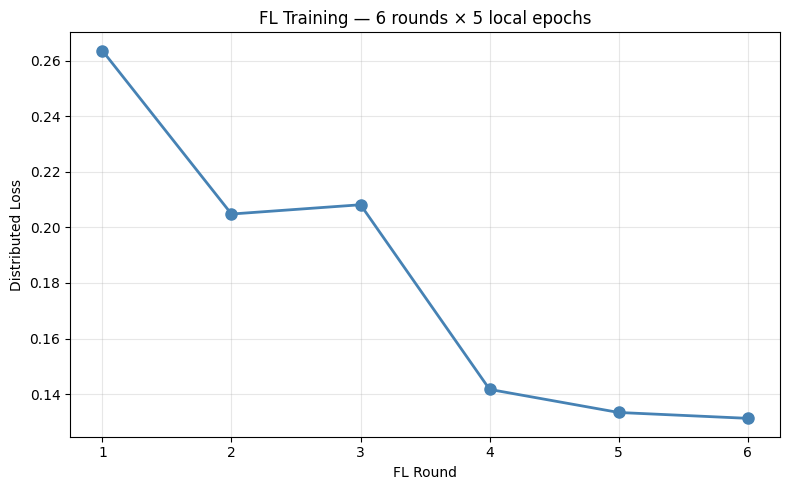


FL SIMULATION COMPLETE
Rounds completed : 6
History saved    : C:\Users\Administrator\desktop\unet\logs_global\fl_history.json
Loss plot        : C:\Users\Administrator\desktop\unet\logs_global\fl_loss_per_round.png
Final model      : C:\Users\Administrator\desktop\unet\weights\global_fl_final.pt

Next: run Cell 8 to evaluate global model on test patients


In [2]:
# CELL 7 — FLOWER FEDERATED LEARNING SIMULATION
# Run after ALL clients have completed Cells 0-4S
# 6 rounds × 5 local epochs per client per round
# Starts from random initialization (not from local best.pt)
# Runtime: ~6-8 hours (6 rounds × 5 clients × ~12 min/client)
# Writes: OUT_ROOT/weights/fl_round{N}_global.pt  (per round)
#         OUT_ROOT/weights/global_fl_final.pt      (final)
#         OUT_ROOT/logs_global/fl_history.json
# ============================================================
import flwr as fl
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from pathlib import Path
import numpy as np
import json
import random
import pickle
from flwr.server.strategy import FedAvg
from flwr.common import ndarrays_to_parameters, parameters_to_ndarrays

# ── paths ─────────────────────────────────────────────────────
OUT_ROOT   = Path(r"C:\Users\Administrator\desktop\unet")
WEIGHTS_DIR = OUT_ROOT / "weights"
LOG_GLOBAL  = OUT_ROOT / "logs_global"
LOG_GLOBAL.mkdir(exist_ok=True)
WEIGHTS_DIR.mkdir(exist_ok=True)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Device: {DEVICE}")

# ── FL hyperparameters ────────────────────────────────────────
NUM_ROUNDS    = 6
LOCAL_EPOCHS  = 5
BATCH_SIZE    = 4
LR            = 1e-4
BASE_FILTERS  = 32
PATCH_SIZE    = 96

# ── UNet (identical to all client notebooks) ──────────────────
class DoubleConv3D(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm3d(out_ch), nn.ReLU(inplace=True),
            nn.Conv3d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm3d(out_ch), nn.ReLU(inplace=True))
    def forward(self, x): return self.block(x)

class Down(nn.Module):
    def __init__(self, c1, c2):
        super().__init__()
        self.pool = nn.MaxPool3d(2)
        self.conv = DoubleConv3D(c1, c2)
    def forward(self, x): return self.conv(self.pool(x))

class Up(nn.Module):
    def __init__(self, c1, c2):
        super().__init__()
        self.up   = nn.ConvTranspose3d(c1, c2, 2, stride=2)
        self.conv = DoubleConv3D(c1, c2)
    def forward(self, x, skip):
        return self.conv(torch.cat([skip, self.up(x)], dim=1))

class UNet3D(nn.Module):
    def __init__(self, base_filters=32):
        super().__init__()
        f = base_filters
        self.enc1=DoubleConv3D(1,f);   self.enc2=Down(f,f*2)
        self.enc3=Down(f*2,f*4);       self.enc4=Down(f*4,f*8)
        self.bottleneck=Down(f*8,f*16)
        self.dec4=Up(f*16,f*8); self.dec3=Up(f*8,f*4)
        self.dec2=Up(f*4,f*2);  self.dec1=Up(f*2,f)
        self.head=nn.Conv3d(f,1,1)
    def forward(self, x):
        e1=self.enc1(x); e2=self.enc2(e1)
        e3=self.enc3(e2); e4=self.enc4(e3)
        b=self.bottleneck(e4)
        return torch.sigmoid(self.head(
            self.dec1(self.dec2(self.dec3(
                self.dec4(b,e4),e3),e2),e1)))

class OHEMLoss(nn.Module):
    def __init__(self, neg_pos_ratio=3, min_negatives=1000):
        super().__init__()
        self.npr=neg_pos_ratio; self.mnn=min_negatives
    def forward(self, pred, target):
        loss=0.0
        for i in range(pred.shape[0]):
            p=pred[i,0]; t=target[i,0]
            pm=t>0.01; nm=~pm
            pl=F.binary_cross_entropy(
                p[pm],t[pm],reduction='mean'
            ) if pm.sum()>0 else torch.tensor(0.0,device=pred.device)
            n_neg=min(int(nm.sum()),
                      max(self.mnn,int(pm.sum())*self.npr))
            nl=F.binary_cross_entropy(
                p[nm],
                torch.zeros(nm.sum(),device=pred.device),
                reduction='none'
            ).topk(n_neg).values.mean()
            loss+=pl+nl
        return loss/pred.shape[0]

class PatchDataset(Dataset):
    def __init__(self, pos_files, neg_files, augment=False):
        self.augment=augment
        self.items=([(str(f),1) for f in pos_files]+
                    [(str(f),0) for f in neg_files])
        random.shuffle(self.items)
    def __len__(self): return len(self.items)
    def __getitem__(self, idx):
        path,_=self.items[idx]; d=np.load(path)
        vol=d['vol'].astype(np.float32)
        heat=d['heatmap'].astype(np.float32)
        if self.augment:
            for ax in range(3):
                if random.random()>0.5:
                    vol=np.flip(vol,axis=ax).copy()
                    heat=np.flip(heat,axis=ax).copy()
            k=random.randint(0,3)
            vol=np.rot90(vol,k=k,axes=(1,2)).copy()
            heat=np.rot90(heat,k=k,axes=(1,2)).copy()
        return (torch.from_numpy(vol).unsqueeze(0),
                torch.from_numpy(heat).unsqueeze(0))

# ── helper to get patch dir per client ───────────────────────
def get_patch_dir(client_id):
    if client_id == 1:
        return OUT_ROOT / "patches" / "client1"
    return OUT_ROOT / f"client{client_id}" / \
           "patches" / f"client{client_id}"

# ── verify all clients are ready ──────────────────────────────
print("Verifying all clients have split manifests...")
for cid in [1,2,3,4,5]:
    manifest_path = get_patch_dir(cid) / "split_manifest.json"
    assert manifest_path.exists(), \
        f"Client {cid} manifest not found: {manifest_path}\n" \
        f"Run Cells 0-4S for client {cid} first."
    with open(manifest_path) as f:
        m = json.load(f)
    print(f"  Client {cid}: {len(m['train_pos'])} train pos  "
          f"{len(m['train_neg'])} train neg  "
          f"{len(m['val_pos'])} val pos")
print("✓ All clients ready\n")

# ── Flower client class ───────────────────────────────────────
class NoduleFlowerClient(fl.client.NumPyClient):

    def __init__(self, client_id):
        self.client_id = client_id
        self.device    = DEVICE

        # load this client's data
        patch_dir = get_patch_dir(client_id)
        with open(patch_dir / "split_manifest.json") as f:
            manifest = json.load(f)

        train_pos = [Path(p) for p in manifest["train_pos"]]
        train_neg = [Path(p) for p in manifest["train_neg"]]
        val_pos   = [Path(p) for p in manifest["val_pos"]]
        val_neg   = [Path(p) for p in manifest["val_neg"]]

        train_ds = PatchDataset(train_pos, train_neg, augment=True)
        val_ds   = PatchDataset(val_pos,   val_neg,   augment=False)

        self.train_loader = DataLoader(
            train_ds, batch_size=BATCH_SIZE,
            shuffle=True, num_workers=0, pin_memory=True)
        self.val_loader   = DataLoader(
            val_ds, batch_size=BATCH_SIZE,
            shuffle=False, num_workers=0, pin_memory=True)

        self.model     = UNet3D(base_filters=BASE_FILTERS).to(DEVICE)
        self.criterion = OHEMLoss(neg_pos_ratio=3, min_negatives=1000)

        n_train = len(train_ds)
        n_val   = len(val_ds)
        print(f"  Client {client_id} loaded: "
              f"{n_train} train  {n_val} val")

    def get_parameters(self, config):
        return [val.cpu().numpy()
                for val in self.model.state_dict().values()]

    def set_parameters(self, parameters):
        state_dict = dict(zip(
            self.model.state_dict().keys(),
            [torch.tensor(p) for p in parameters]
        ))
        self.model.load_state_dict(state_dict, strict=True)

    def fit(self, parameters, config):
        self.set_parameters(parameters)
        local_epochs = config.get("local_epochs", LOCAL_EPOCHS)
        round_num    = config.get("round_num", 0)

        optimizer = torch.optim.Adam(
            self.model.parameters(), lr=LR)
        from torch.optim.lr_scheduler import CosineAnnealingLR
        scheduler = CosineAnnealingLR(
            optimizer, T_max=local_epochs)

        self.model.train()
        total_loss = 0.0
        n_batches  = len(self.train_loader)

        for epoch in range(local_epochs):
            epoch_loss = 0.0
            for bi, (vol, heat) in enumerate(self.train_loader):
                vol  = vol.to(self.device)
                heat = heat.to(self.device)
                optimizer.zero_grad()
                loss = self.criterion(self.model(vol), heat)
                loss.backward()
                optimizer.step()
                epoch_loss += loss.item()
            scheduler.step()
            avg = epoch_loss / max(n_batches, 1)
            total_loss += avg
            print(f"    C{self.client_id} R{round_num} "
                  f"Ep{epoch+1}/{local_epochs} "
                  f"loss={avg:.4f}", flush=True)

        avg_loss   = total_loss / max(local_epochs, 1)
        n_samples  = len(self.train_loader.dataset)

        return (
            self.get_parameters(config={}),
            n_samples,
            {"train_loss": float(avg_loss),
             "client_id" : self.client_id}
        )

    def evaluate(self, parameters, config):
        self.set_parameters(parameters)
        self.model.eval()
        val_loss  = 0.0
        n_samples = len(self.val_loader.dataset)

        with torch.no_grad():
            for vol, heat in self.val_loader:
                val_loss += self.criterion(
                    self.model(vol.to(self.device)),
                    heat.to(self.device)
                ).item()

        avg_val = val_loss / max(len(self.val_loader), 1)
        return (
            float(avg_val),
            n_samples,
            {"val_loss"  : float(avg_val),
             "client_id" : self.client_id}
        )

# ── pre-instantiate all clients ───────────────────────────────
# we instantiate outside client_fn to avoid reloading data
# every time Flower calls client_fn
print("Loading all client data...")
clients = {}
for cid in [1,2,3,4,5]:
    clients[cid] = NoduleFlowerClient(cid)
print("✓ All clients loaded\n")

def client_fn(cid):
    # cid is string "0".."4" → map to client IDs 1..5
    return clients[int(cid)+1].to_client()

# ── save global weights after each round ─────────────────────
round_weights = {}

class SaveRoundStrategy(FedAvg):
    """FedAvg that saves global weights after each round."""

    def aggregate_fit(self, server_round, results, failures):
        aggregated = super().aggregate_fit(
            server_round, results, failures)
        if aggregated is not None:
            params, metrics = aggregated
            # convert to numpy and save
            ndarrays = parameters_to_ndarrays(params)
            # save as state dict
            model_keys = list(
                UNet3D(base_filters=BASE_FILTERS).state_dict().keys())
            state_dict = dict(zip(
                model_keys,
                [torch.tensor(p) for p in ndarrays]
            ))
            save_path = WEIGHTS_DIR / \
                        f"fl_round{server_round}_global.pt"
            torch.save(state_dict, save_path)
            print(f"\n  ✓ Round {server_round} global weights "
                  f"saved: {save_path}")
            round_weights[server_round] = save_path
        return aggregated

# ── initial global weights (random init) ─────────────────────
init_model  = UNet3D(base_filters=BASE_FILTERS)
init_params = ndarrays_to_parameters(
    [val.cpu().numpy()
     for val in init_model.state_dict().values()]
)

strategy = SaveRoundStrategy(
    fraction_fit=1.0,
    fraction_evaluate=1.0,
    min_fit_clients=5,
    min_evaluate_clients=5,
    min_available_clients=5,
    initial_parameters=init_params,
    on_fit_config_fn=lambda r: {
        "local_epochs": LOCAL_EPOCHS,
        "round_num"   : r,
    },
)

# ── run simulation ────────────────────────────────────────────
print(f"{'='*55}")
print(f"FLOWER FL SIMULATION")
print(f"{'='*55}")
print(f"Clients      : 5")
print(f"Rounds       : {NUM_ROUNDS}")
print(f"Local epochs : {LOCAL_EPOCHS} per client per round")
print(f"Total epochs : {NUM_ROUNDS * LOCAL_EPOCHS} effective")
print(f"Init         : random (not from local best.pt)")
print(f"Strategy     : FedAvg")
print(f"{'='*55}\n")

history = fl.simulation.start_simulation(
    client_fn=client_fn,
    num_clients=5,
    config=fl.server.ServerConfig(num_rounds=NUM_ROUNDS),
    strategy=strategy,
    client_resources={
        "num_cpus": 1,
        "num_gpus": 1.0,  # each client needs full GPU → forces sequential
    },
)

# ── save final global model ───────────────────────────────────
final_round_path = round_weights.get(NUM_ROUNDS)
if final_round_path and final_round_path.exists():
    import shutil
    GLOBAL_PT = WEIGHTS_DIR / "global_fl_final.pt"
    shutil.copy(final_round_path, GLOBAL_PT)
    print(f"\n✓ Final global model: {GLOBAL_PT}")
else:
    print("\n⚠ Final round weights not found — check round saving")

# ── save FL history ───────────────────────────────────────────
fl_history = {
    "num_rounds"   : NUM_ROUNDS,
    "local_epochs" : LOCAL_EPOCHS,
    "losses_distributed": [
        [r, float(l)] for r,l in history.losses_distributed
    ],
    "losses_centralized": [
        [r, float(l)] for r,l in history.losses_centralized
    ] if history.losses_centralized else [],
    "metrics_distributed": str(history.metrics_distributed),
    "round_weight_paths": {
        str(k): str(v) for k,v in round_weights.items()
    }
}
with open(LOG_GLOBAL / "fl_history.json", "w") as f:
    json.dump(fl_history, f, indent=2)

# ── plot loss per round ───────────────────────────────────────
import matplotlib.pyplot as plt

if history.losses_distributed:
    rounds = [r for r,l in history.losses_distributed]
    losses = [l for r,l in history.losses_distributed]
    fig, ax = plt.subplots(figsize=(8,5))
    ax.plot(rounds, losses, 'o-',
            color='steelblue', linewidth=2, markersize=8)
    ax.set_xlabel('FL Round')
    ax.set_ylabel('Distributed Loss')
    ax.set_title(f'FL Training — {NUM_ROUNDS} rounds × '
                 f'{LOCAL_EPOCHS} local epochs')
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(LOG_GLOBAL / "fl_loss_per_round.png", dpi=100)
    plt.show()

print(f"\n{'='*55}")
print(f"FL SIMULATION COMPLETE")
print(f"{'='*55}")
print(f"Rounds completed : {NUM_ROUNDS}")
print(f"History saved    : {LOG_GLOBAL/'fl_history.json'}")
print(f"Loss plot        : {LOG_GLOBAL/'fl_loss_per_round.png'}")
print(f"Final model      : {WEIGHTS_DIR/'global_fl_final.pt'}")
print(f"\nNext: run Cell 8 to evaluate global model on test patients")

C:\Users\Administrator\AppData\Local\Temp\2\ipykernel_9068\1727391105.py:69: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  global_model.load_state_dict(torch.load(GLOBAL_PT,

Global model loaded: C:\Users\Administrator\desktop\unet\weights\global_fl_final.pt
Total test patients: 133
  client1: 24 patients
  client2: 27 patients
  client3: 30 patients
  client4: 25 patients
  client5: 27 patients


Global inference:   1%|▍                                                             | 1/133 [00:43<1:35:47, 43.55s/it]

  LIDC-IDRI-0001: GT= 1 TP= 1 FP=  2 FN= 0


Global inference:   2%|▉                                                             | 2/133 [01:25<1:32:27, 42.35s/it]

...

  LIDC-IDRI-0978: GT= 2 TP= 2 FP=  3 FN= 0


Global inference:  99%|███████████████████████████████████████████████████████████▌| 132/133 [1:21:37<00:30, 30.02s/it]

  LIDC-IDRI-0985: GT= 1 TP= 0 FP=  0 FN= 1


Global inference: 100%|████████████████████████████████████████████████████████████| 133/133 [1:22:16<00:00, 37.11s/it]

  LIDC-IDRI-0987: GT= 2 TP= 2 FP=  3 FN= 0

GLOBAL FEDAVG MODEL RESULTS
Patients: 133/133  GT nodules: 175
TP=160  FP=457  FN=15
Sensitivity: 0.914  Precision: 0.259  F1: 0.404  FP/scan: 3.44

Global CPM: 0.741
  0.125 FP/scan → 0.486
  0.250 FP/scan → 0.571
  0.500 FP/scan → 0.663
  1.000 FP/scan → 0.783
  2.000 FP/scan → 0.857
  4.000 FP/scan → 0.914
  8.000 FP/scan → 0.914


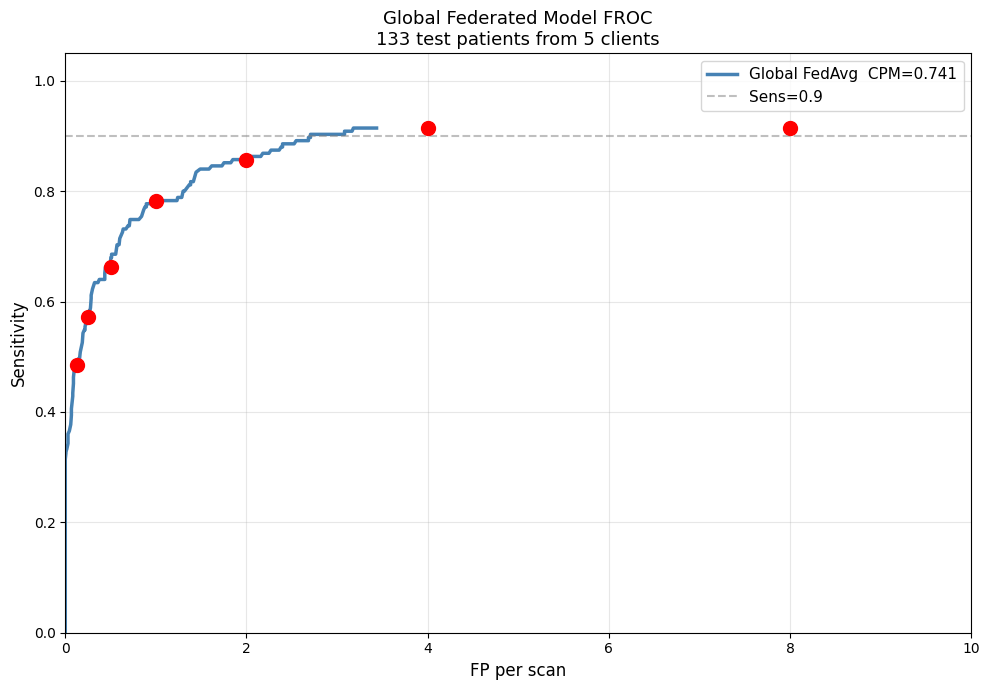


Results: C:\Users\Administrator\desktop\unet\logs_global/global_test_results.json
FROC   : C:\Users\Administrator\desktop\unet\logs_global/global_test_froc.png
Weights: C:\Users\Administrator\desktop\unet\weights\global_fl_final.pt


In [6]:
# CELL 8 — GLOBAL MODEL EVALUATION
# Evaluates federated model on ALL test patients from
# global_test_pids.json (~133 patients from 5 clients)
# Runtime: ~60-90 min
# Writes: OUT_ROOT/logs_global/global_test_results.json
#         OUT_ROOT/logs_global/global_test_froc.png
# ============================================================
from tqdm import tqdm
from pathlib import Path
import numpy as np
import json
import pickle
import torch
import matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter

GLOBAL_PT = OUT_ROOT / 'weights' / 'global_fl_final.pt'

def sliding_window_max(model, vol, mask, patch_size, stride, device):
    D,H,W   = vol.shape
    p       = patch_size
    heatmap = np.zeros((D,H,W), dtype=np.float32)
    coords  = np.argwhere(mask > 0)
    if len(coords) == 0:
        return heatmap
    z1=max(0,coords[:,0].min()-p//4)
    y1=max(0,coords[:,1].min()-p//4)
    x1=max(0,coords[:,2].min()-p//4)
    z2=min(D,coords[:,0].max()+p//4)
    y2=min(H,coords[:,1].max()+p//4)
    x2=min(W,coords[:,2].max()+p//4)
    model.eval()
    with torch.no_grad():
        for zw in range(z1,z2-p+1,stride):
            for yw in range(y1,y2-p+1,stride):
                for xw in range(x1,x2-p+1,stride):
                    patch=vol[zw:zw+p,yw:yw+p,xw:xw+p]
                    if patch.shape!=(p,p,p): continue
                    if mask[zw:zw+p,yw:yw+p,xw:xw+p].mean()<0.05: continue
                    t=torch.from_numpy(patch).unsqueeze(0).unsqueeze(0).float().to(device)
                    pred=model(t).squeeze().cpu().numpy()
                    heatmap[zw:zw+p,yw:yw+p,xw:xw+p]=np.maximum(
                        heatmap[zw:zw+p,yw:yw+p,xw:xw+p],pred)
    return heatmap

def get_detections(heatmap, threshold=0.3, min_dist=6):
    lm=maximum_filter(heatmap,footprint=np.ones((min_dist,)*3))==heatmap
    lm=lm&(heatmap>threshold)
    c=np.argwhere(lm)
    if len(c)==0: return []
    s=heatmap[lm]; o=np.argsort(s)[::-1]
    return [(int(c[i,0]),int(c[i,1]),int(c[i,2]),float(s[i])) for i in o]

def match_gt(detections, gt_nodules):
    matched=set(); tp,fp=[],[]
    for det in detections:
        dz,dy,dx,sc=det; bd,bi=float('inf'),-1
        for gi,nod in enumerate(gt_nodules):
            if gi in matched: continue
            gz,gy,gx=nod['center_res']
            d=np.sqrt((dz-gz)**2+(dy-gy)**2+(dx-gx)**2)
            if d<max(nod['radius_mm'],10.0) and d<bd: bd,bi=d,gi
        if bi>=0: tp.append({'det':det,'gt':gt_nodules[bi],'dist_mm':bd}); matched.add(bi)
        else: fp.append({'det':det})
    fn=[{'gt':n} for gi,n in enumerate(gt_nodules) if gi not in matched]
    return tp,fp,fn
    
global_model = UNet3D(base_filters=BASE_FILTERS).to(DEVICE)
global_model.load_state_dict(torch.load(GLOBAL_PT, map_location=DEVICE))
global_model.eval()
print(f'Global model loaded: {GLOBAL_PT}')

assert GLOBAL_TEST_MANIFEST.exists(), 'global_test_pids.json not found'
with open(GLOBAL_TEST_MANIFEST) as f:
    global_test = json.load(f)
all_test_pids = global_test['test_pids']
by_client     = global_test.get('by_client', {})
print(f'Total test patients: {len(all_test_pids)}')
for cid,pids in by_client.items():
    print(f'  {cid}: {len(pids)} patients')

GLOBAL_LOG_DIR = OUT_ROOT / 'logs_global'
GLOBAL_LOG_DIR.mkdir(exist_ok=True)

with open(FEDERATION_SPLITS) as f:
    splits = json.load(f)

def get_patient_dirs(pid):
    if pid in splits['client1_pids']:
        return OUT_ROOT/'preprocessed', OUT_ROOT/'lung_masks', OUT_ROOT/'annotations'
    for cid in [2,3,4,5]:
        key = f'client{cid}_pids'
        if key in splits and pid in splits[key]:
            cd = OUT_ROOT / f'client{cid}'
            return cd/'preprocessed', cd/'lung_masks', cd/'annotations'
    raise ValueError(f'{pid} not found in any client')

all_results_g=[]; all_scores_g=[]; total_gt_g=0; missing=[]

for pid in tqdm(all_test_pids, desc='Global inference'):
    try:
        pd,md,ad = get_patient_dirs(pid)
    except ValueError as e:
        print(f'\n  {e}'); missing.append(pid); continue
    vp=pd/f'{pid}.npy'; mp=md/f'{pid}.npy'; ap=ad/f'{pid}.json'
    if not (vp.exists() and mp.exists() and ap.exists()):
        print(f'\n  SKIP {pid} — missing files'); missing.append(pid); continue
    vol=np.load(vp); mask=np.load(mp)
    with open(ap) as f: gt_nods=json.load(f)['consensus_nodules']
    total_gt_g+=len(gt_nods)
    heatmap   =sliding_window_max(global_model,vol,mask,PATCH_SIZE,STRIDE,DEVICE)
    detections=get_detections(heatmap,THRESHOLD)
    tp,fp,fn  =match_gt(detections,gt_nods)
    all_results_g.append({'pid':pid,'gt_nodules':len(gt_nods),'detections':len(detections),
                          'tp':len(tp),'fp':len(fp),'fn':len(fn),
                          'tp_list':tp,'fp_list':fp,'fn_list':fn})
    for i in tp: all_scores_g.append((i['det'][3],1))
    for i in fp: all_scores_g.append((i['det'][3],0))
    print(f'  {pid}: GT={len(gt_nods):2d} TP={len(tp):2d} FP={len(fp):3d} FN={len(fn):2d}')

with open(GLOBAL_LOG_DIR/'global_all_results.pkl','wb') as f: pickle.dump(all_results_g,f)
with open(GLOBAL_LOG_DIR/'global_all_scores.pkl','wb') as f:  pickle.dump(all_scores_g,f)

ttp=sum(r['tp'] for r in all_results_g); tfp=sum(r['fp'] for r in all_results_g)
tfn=sum(r['fn'] for r in all_results_g); ns=len(all_results_g)
sen=ttp/max(ttp+tfn,1); pre=ttp/max(ttp+tfp,1)
f1=2*pre*sen/max(pre+sen,1e-6); fps=tfp/max(ns,1)

print(f'\n{"="*55}')
print(f'GLOBAL FEDAVG MODEL RESULTS')
print(f'{"="*55}')
print(f'Patients: {ns}/{len(all_test_pids)}  GT nodules: {total_gt_g}')
if missing: print(f'Missing : {len(missing)}')
print(f'TP={ttp}  FP={tfp}  FN={tfn}')
print(f'Sensitivity: {sen:.3f}  Precision: {pre:.3f}  F1: {f1:.3f}  FP/scan: {fps:.2f}')

cpm_g=0.0
if all_scores_g:
    all_scores_g.sort(key=lambda x:x[0],reverse=True)
    sa=np.array([s[0] for s in all_scores_g]); la=np.array([s[1] for s in all_scores_g])
    sl,fl=[],[]
    for th in np.linspace(0.95,0.01,500):
        k=sa>=th
        sl.append(float(la[k].sum()/max(total_gt_g,1)))
        fl.append(float((1-la[k]).sum()/max(ns,1)))
    fp_pts=[0.125,0.25,0.5,1,2,4,8]
    cpm_s=[sl[np.argmin([abs(f-fp) for f in fl])] for fp in fp_pts]
    cpm_g=float(np.mean(cpm_s))
    print(f'\nGlobal CPM: {cpm_g:.3f}')
    for fp_pt,s in zip(fp_pts,cpm_s): print(f'  {fp_pt:5.3f} FP/scan → {s:.3f}')
    fig,ax=plt.subplots(figsize=(10,7))
    ax.plot(fl,sl,color='steelblue',linewidth=2.5,label=f'Global FedAvg  CPM={cpm_g:.3f}')
    ax.scatter(fp_pts,cpm_s,color='red',zorder=5,s=100)
    ax.axhline(0.9,color='gray',linestyle='--',alpha=0.5,label='Sens=0.9')
    ax.set_xlabel('FP per scan',fontsize=12); ax.set_ylabel('Sensitivity',fontsize=12)
    ax.set_title(f'Global Federated Model FROC\n{ns} test patients from 5 clients',fontsize=13)
    ax.set_xlim(0,10); ax.set_ylim(0,1.05); ax.legend(fontsize=11); ax.grid(True,alpha=0.3)
    plt.tight_layout()
    plt.savefig(GLOBAL_LOG_DIR/'global_test_froc.png',dpi=100,bbox_inches='tight')
    plt.show()

with open(GLOBAL_LOG_DIR/'global_test_results.json','w') as f:
    json.dump({'model':'global_fedavg','n_clients':len(available_clients if "available_clients" in dir() else []),'stride':STRIDE,
               'threshold':THRESHOLD,'n_patients':ns,'total_gt':total_gt_g,
               'total_tp':ttp,'total_fp':tfp,'total_fn':tfn,
               'sensitivity':round(sen,4),'precision':round(pre,4),
               'f1':round(f1,4),'fp_per_scan':round(fps,4),'cpm':round(cpm_g,4),
               'per_patient':[{k:v for k,v in r.items()
                               if k not in ('tp_list','fp_list','fn_list')}
                              for r in all_results_g]},f,indent=2)
print(f'\nResults: {GLOBAL_LOG_DIR}/global_test_results.json')
print(f'FROC   : {GLOBAL_LOG_DIR}/global_test_froc.png')
print(f'Weights: {GLOBAL_PT}')


C:\ProgramData\miniconda3\envs\lungfl\lib\site-packages\pylidc\__init__.py:27: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources as _pr
C:\ProgramData\miniconda3\envs\lungfl\lib\site-packages\pylidc\_Base.py:2: MovedIn20Warning: The ``declarative_base()`` function is now available as sqlalchemy.orm.declarative_base(). (deprecated since: 2.0) (Background on SQLAlchemy 2.0 at: https://sqlalche.me/e/b8d9)
  Base = declarative_base()
C:\ProgramData\miniconda3\envs\lungfl\lib\site-packages\pylidc\Annotation.py:32: DeprecationWarning: Please import `distance_transform_edt` from the `scipy.ndimage` namespace; the `scipy.ndimage.morphology` namespace is deprecated and will be removed in SciPy 2.0.0.
  from scipy.ndimage.morphology import distance_transform_edt as dtrans


Loaded 133 patient results
Re-evaluating with MIN_CONSENSUS=2...


MIN_CONS=2:  16%|██████████▉                                                          | 21/133 [00:58<04:34,  2.45s/it]

Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.


MIN_CONS=2:  96%|█████████████████████████████████████████████████████████████████▍  | 128/133 [07:12<00:21,  4.21s/it]

Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.


MIN_CONS=2: 100%|████████████████████████████████████████████████████████████████████| 133/133 [07:35<00:00,  3.42s/it]



GLOBAL FL MODEL — MIN_CONSENSUS=2
GT nodules (≥2 rads): 231
TP=203  FP=414  FN=28
Sensitivity : 0.879
Precision   : 0.329
FP/scan     : 3.11

CPM (MIN_CONSENSUS≥2): 0.703
  0.125 FP/scan → 0.450
  0.250 FP/scan → 0.545
  0.500 FP/scan → 0.645
  1.000 FP/scan → 0.706
  2.000 FP/scan → 0.814
  4.000 FP/scan → 0.879
  8.000 FP/scan → 0.879


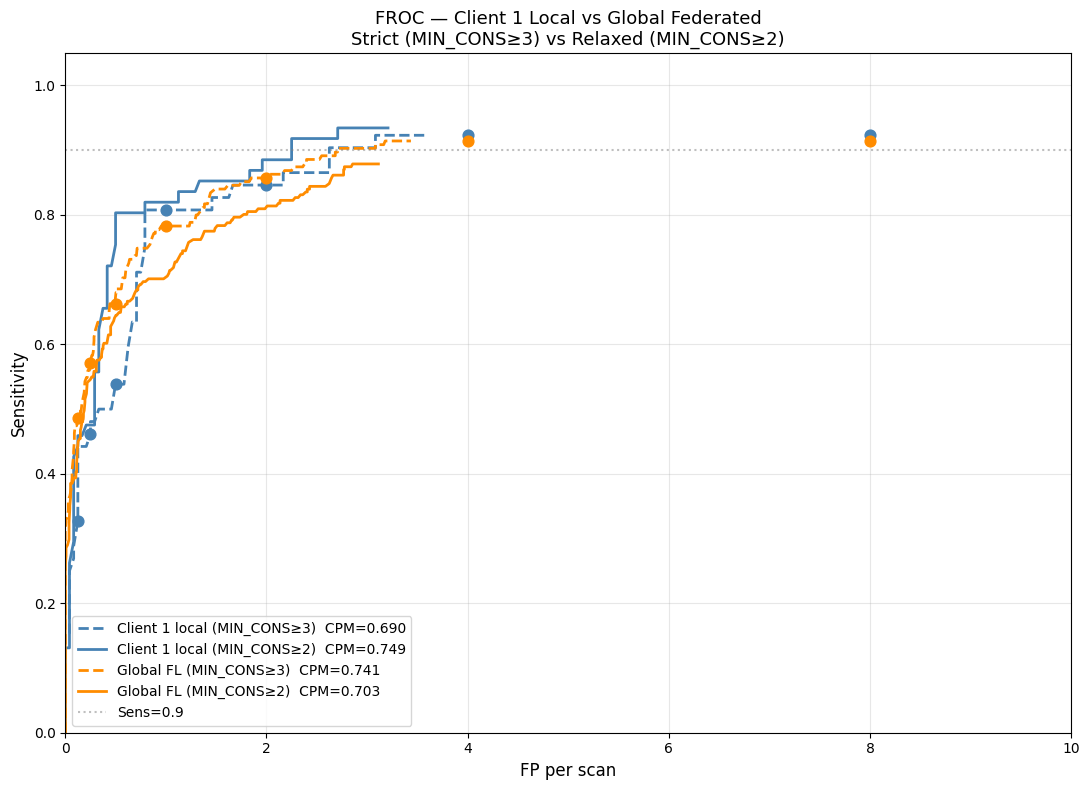


FINAL COMPARISON TABLE
                                        CPM    Sens  FP/scan
----------------------------------------------------------
Client 1 local  (MIN_CONS≥3)          0.690   0.923     3.58
Client 1 local  (MIN_CONS≥2)          0.749   0.934     3.21
Global FL       (MIN_CONS≥3)          0.741 0.879     3.11
Global FL       (MIN_CONS≥2)          0.703 0.879     3.11

Saved: C:\Users\Administrator\desktop\unet\logs_global\global_results_min2.json
Plot : C:\Users\Administrator\desktop\unet\logs_global\comparison_froc.png


In [7]:
import pylidc as pl
import numpy as np
import json
import pickle
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

if not hasattr(np, 'int'):
    np.int = int

# load saved results from Cell 8
with open(GLOBAL_LOG_DIR / 'global_all_results.pkl', 'rb') as f:
    all_results_g = pickle.load(f)
print(f"Loaded {len(all_results_g)} patient results")

# load pylidc scans
all_scans = pl.query(pl.Scan).order_by(pl.Scan.patient_id).all()
seen = {}
for s in all_scans:
    if s.patient_id not in seen:
        seen[s.patient_id] = s

import SimpleITK as sitk

def load_sitk_orig(scan):
    dicom_path = scan.get_path_to_dicom_files()
    ids   = sitk.ImageSeriesReader.GetGDCMSeriesIDs(str(dicom_path))
    files = sitk.ImageSeriesReader.GetGDCMSeriesFileNames(
                str(dicom_path), ids[0])
    reader = sitk.ImageSeriesReader()
    reader.SetFileNames(files)
    return reader.Execute()

def build_sitk_res(pid, preproc_dir):
    meta = np.load(
        preproc_dir / f'{pid}_meta.npy',
        allow_pickle=True).item()
    s = sitk.Image(
        [int(x) for x in meta['res_size']], sitk.sitkFloat32)
    s.SetSpacing([float(x) for x in meta['res_spacing']])
    s.SetOrigin([float(x) for x in meta['res_origin']])
    s.SetDirection([float(x) for x in meta['res_direction']])
    return s

def get_nodules_min2(scan, sitk_orig, sitk_res):
    nodules = []
    for ann_group in scan.cluster_annotations():
        if len(ann_group) < 2:
            continue
        ann  = ann_group[0]
        bbox = ann.bbox()
        orig_col = (bbox[1].start + bbox[1].stop) // 2
        orig_row = (bbox[0].start + bbox[0].stop) // 2
        orig_k   = (bbox[2].start + bbox[2].stop) // 2
        phys    = sitk_orig.TransformIndexToPhysicalPoint(
            (int(orig_col), int(orig_row), int(orig_k)))
        res_idx = sitk_res.TransformPhysicalPointToIndex(phys)
        size    = sitk_res.GetSize()
        res_z   = max(0, min(size[2]-1, res_idx[2]))
        res_y   = max(0, min(size[1]-1, res_idx[1]))
        res_x   = max(0, min(size[0]-1, res_idx[0]))
        diameters = []
        for a in ann_group:
            try: diameters.append(a.diameter)
            except: pass
        radius_mm = float(np.mean(diameters))/2 if diameters else 5.0
        nodules.append({
            'center_res' : [int(res_z), int(res_y), int(res_x)],
            'radius_mm'  : round(radius_mm, 2),
            'n_annotators': len(ann_group)
        })
    return nodules

def get_preproc_dir(pid):
    with open(FEDERATION_SPLITS) as f:
        splits = json.load(f)
    if pid in splits['client1_pids']:
        return OUT_ROOT / 'preprocessed'
    for cid in [2,3,4,5]:
        if pid in splits.get(f'client{cid}_pids', []):
            return OUT_ROOT / f'client{cid}' / 'preprocessed'
    raise ValueError(f'{pid} not found')

def match_detections_min2(detections, gt_nodules):
    matched=set(); tp,fp=[],[]
    for det in detections:
        dz,dy,dx,sc=det; bd,bi=float('inf'),-1
        for gi,nod in enumerate(gt_nodules):
            if gi in matched: continue
            gz,gy,gx=nod['center_res']
            d=np.sqrt((dz-gz)**2+(dy-gy)**2+(dx-gx)**2)
            if d<max(nod['radius_mm'],10.0) and d<bd: bd,bi=d,gi
        if bi>=0: tp.append({'det':det,'gt':gt_nodules[bi],'dist_mm':bd}); matched.add(bi)
        else: fp.append({'det':det})
    fn=[{'gt':n} for gi,n in enumerate(gt_nodules) if gi not in matched]
    return tp,fp,fn

# re-evaluate with MIN_CONSENSUS=2
print("Re-evaluating with MIN_CONSENSUS=2...")
all_results_adj = []
all_scores_adj  = []
total_gt_adj    = 0
failed          = []

from tqdm import tqdm
for r in tqdm(all_results_g, desc='MIN_CONS=2'):
    pid  = r['pid']
    scan = seen.get(pid)
    if scan is None:
        failed.append(pid); continue
    try:
        preproc_dir = get_preproc_dir(pid)
        sitk_orig   = load_sitk_orig(scan)
        sitk_res    = build_sitk_res(pid, preproc_dir)
        gt_nods_2   = get_nodules_min2(scan, sitk_orig, sitk_res)
    except Exception as e:
        print(f"  ERROR {pid}: {e}")
        failed.append(pid); continue

    total_gt_adj += len(gt_nods_2)

    # get detections from saved results
    detections = [item['det'] for item in r['tp_list']] + \
                 [item['det'] for item in r['fp_list']]

    tp,fp,fn = match_detections_min2(detections, gt_nods_2)
    all_results_adj.append({
        'pid': pid, 'gt_nodules': len(gt_nods_2),
        'tp': len(tp), 'fp': len(fp), 'fn': len(fn),
        'tp_list': tp, 'fp_list': fp, 'fn_list': fn,
    })
    for i in tp: all_scores_adj.append((i['det'][3], 1))
    for i in fp: all_scores_adj.append((i['det'][3], 0))

# metrics
ttp=sum(r['tp'] for r in all_results_adj)
tfp=sum(r['fp'] for r in all_results_adj)
tfn=sum(r['fn'] for r in all_results_adj)
ns =len(all_results_adj)
sen=ttp/max(ttp+tfn,1)
pre=ttp/max(ttp+tfp,1)
f1 =2*pre*sen/max(pre+sen,1e-6)
fps=tfp/max(ns,1)

print(f"\n{'='*55}")
print(f"GLOBAL FL MODEL — MIN_CONSENSUS=2")
print(f"{'='*55}")
print(f"GT nodules (≥2 rads): {total_gt_adj}")
print(f"TP={ttp}  FP={tfp}  FN={tfn}")
print(f"Sensitivity : {sen:.3f}")
print(f"Precision   : {pre:.3f}")
print(f"FP/scan     : {fps:.2f}")

# FROC + CPM
cpm_adj = 0.0
if all_scores_adj:
    all_scores_adj.sort(key=lambda x:x[0],reverse=True)
    sa=np.array([s[0] for s in all_scores_adj])
    la=np.array([s[1] for s in all_scores_adj])
    sl,fl=[],[]
    for th in np.linspace(0.95,0.01,500):
        k=sa>=th
        sl.append(float(la[k].sum()/max(total_gt_adj,1)))
        fl.append(float((1-la[k]).sum()/max(ns,1)))
    fp_pts=[0.125,0.25,0.5,1,2,4,8]
    cpm_s=[sl[np.argmin([abs(f-fp) for f in fl])] for fp in fp_pts]
    cpm_adj=float(np.mean(cpm_s))
    print(f"\nCPM (MIN_CONSENSUS≥2): {cpm_adj:.3f}")
    for fp_pt,s in zip(fp_pts,cpm_s):
        print(f"  {fp_pt:5.3f} FP/scan → {s:.3f}")

    # comparison plot — all 4 conditions
    # load client 1 strict results
    with open(OUT_ROOT/'logs'/'all_scores.pkl','rb') as f:
        c1_scores_strict = pickle.load(f)
    with open(OUT_ROOT/'logs'/'all_results_min2.pkl','rb') as f:
        c1_results_min2 = pickle.load(f)

    c1_scores_strict.sort(key=lambda x:x[0],reverse=True)
    sa1=np.array([s[0] for s in c1_scores_strict])
    la1=np.array([s[1] for s in c1_scores_strict])
    total_gt_c1_strict = 52
    sl1,fl1=[],[]
    for th in np.linspace(0.95,0.01,500):
        k=sa1>=th
        sl1.append(float(la1[k].sum()/max(total_gt_c1_strict,1)))
        fl1.append(float((1-la1[k]).sum()/24))
    cpm_s1=[sl1[np.argmin([abs(f-fp) for f in fl1])] for fp in fp_pts]
    cpm_c1_strict=float(np.mean(cpm_s1))

    # client 1 min2
    c1_scores_min2=[]
    for r in c1_results_min2:
        for i in r['tp_list']: c1_scores_min2.append((i['det'][3],1))
        for i in r['fp_list']: c1_scores_min2.append((i['det'][3],0))
    total_gt_c1_min2=sum(r['gt_nodules'] for r in c1_results_min2)
    c1_scores_min2.sort(key=lambda x:x[0],reverse=True)
    sa2=np.array([s[0] for s in c1_scores_min2])
    la2=np.array([s[1] for s in c1_scores_min2])
    sl2,fl2=[],[]
    for th in np.linspace(0.95,0.01,500):
        k=sa2>=th
        sl2.append(float(la2[k].sum()/max(total_gt_c1_min2,1)))
        fl2.append(float((1-la2[k]).sum()/24))
    cpm_s2=[sl2[np.argmin([abs(f-fp) for f in fl2])] for fp in fp_pts]
    cpm_c1_min2=float(np.mean(cpm_s2))

    # global strict
    with open(GLOBAL_LOG_DIR/'global_all_scores.pkl','rb') as f:
        g_scores_strict = pickle.load(f)
    g_scores_strict.sort(key=lambda x:x[0],reverse=True)
    sag=np.array([s[0] for s in g_scores_strict])
    lag=np.array([s[1] for s in g_scores_strict])
    total_gt_g_strict=175
    slg,flg=[],[]
    for th in np.linspace(0.95,0.01,500):
        k=sag>=th
        slg.append(float(lag[k].sum()/max(total_gt_g_strict,1)))
        flg.append(float((1-lag[k]).sum()/133))
    cpm_sg=[slg[np.argmin([abs(f-fp) for f in flg])] for fp in fp_pts]
    cpm_g_strict=float(np.mean(cpm_sg))

    fig,ax=plt.subplots(figsize=(11,8))
    ax.plot(fl1,  sl1,  color='steelblue',  linewidth=2,
            linestyle='--',
            label=f'Client 1 local (MIN_CONS≥3)  CPM={cpm_c1_strict:.3f}')
    ax.plot(fl2,  sl2,  color='steelblue',  linewidth=2,
            label=f'Client 1 local (MIN_CONS≥2)  CPM={cpm_c1_min2:.3f}')
    ax.plot(flg,  slg,  color='darkorange', linewidth=2,
            linestyle='--',
            label=f'Global FL (MIN_CONS≥3)  CPM={cpm_g_strict:.3f}')
    ax.plot(fl,   sl,   color='darkorange', linewidth=2,
            label=f'Global FL (MIN_CONS≥2)  CPM={cpm_adj:.3f}')
    ax.scatter(fp_pts, cpm_s1, color='steelblue',  s=60, zorder=5)
    ax.scatter(fp_pts, cpm_sg, color='darkorange',  s=60, zorder=5)
    ax.axhline(0.9,color='gray',linestyle=':',alpha=0.5,label='Sens=0.9')
    ax.set_xlabel('FP per scan',fontsize=12)
    ax.set_ylabel('Sensitivity',fontsize=12)
    ax.set_title('FROC — Client 1 Local vs Global Federated\n'
                 'Strict (MIN_CONS≥3) vs Relaxed (MIN_CONS≥2)',fontsize=13)
    ax.set_xlim(0,10); ax.set_ylim(0,1.05)
    ax.legend(fontsize=10); ax.grid(True,alpha=0.3)
    plt.tight_layout()
    plt.savefig(GLOBAL_LOG_DIR/'comparison_froc.png',
                dpi=100,bbox_inches='tight')
    plt.show()

    print(f"\n{'='*55}")
    print(f"FINAL COMPARISON TABLE")
    print(f"{'='*55}")
    print(f"{'':35} {'CPM':>7} {'Sens':>7} {'FP/scan':>8}")
    print(f"{'-'*58}")
    print(f"{'Client 1 local  (MIN_CONS≥3)':35} "
          f"{cpm_c1_strict:>7.3f} {'0.923':>7} {'3.58':>8}")
    print(f"{'Client 1 local  (MIN_CONS≥2)':35} "
          f"{cpm_c1_min2:>7.3f} {'0.934':>7} {'3.21':>8}")
    print(f"{'Global FL       (MIN_CONS≥3)':35} "
          f"{cpm_g_strict:>7.3f} {sen:.3f} {fps:>8.2f}")
    print(f"{'Global FL       (MIN_CONS≥2)':35} "
          f"{cpm_adj:>7.3f} {sen:.3f} {fps:>8.2f}")

with open(GLOBAL_LOG_DIR/'global_results_min2.json','w') as f:
    json.dump({'cpm_min2':round(cpm_adj,4),
               'total_gt_min2':total_gt_adj,
               'sensitivity':round(sen,4),
               'fp_per_scan':round(fps,4)},f,indent=2)
print(f"\nSaved: {GLOBAL_LOG_DIR/'global_results_min2.json'}")
print(f"Plot : {GLOBAL_LOG_DIR/'comparison_froc.png'}")

In [9]:
# MIN_CONSENSUS=1 analysis
# Same approach — no inference, just rematch existing detections
# No overwriting — writes to new files only

import pylidc as pl
import numpy as np
import json
import pickle
import warnings
warnings.filterwarnings('ignore')

if not hasattr(np, 'int'):
    np.int = int

from tqdm import tqdm
import SimpleITK as sitk

# load saved results
with open(GLOBAL_LOG_DIR / 'global_all_results.pkl', 'rb') as f:
    all_results_g = pickle.load(f)
print(f"Loaded {len(all_results_g)} patient results")

# load pylidc
all_scans = pl.query(pl.Scan).order_by(pl.Scan.patient_id).all()
seen = {}
for s in all_scans:
    if s.patient_id not in seen:
        seen[s.patient_id] = s

def load_sitk_orig(scan):
    dicom_path = scan.get_path_to_dicom_files()
    ids   = sitk.ImageSeriesReader.GetGDCMSeriesIDs(str(dicom_path))
    files = sitk.ImageSeriesReader.GetGDCMSeriesFileNames(
                str(dicom_path), ids[0])
    reader = sitk.ImageSeriesReader()
    reader.SetFileNames(files)
    return reader.Execute()

def build_sitk_res(pid, preproc_dir):
    meta = np.load(
        preproc_dir / f'{pid}_meta.npy',
        allow_pickle=True).item()
    s = sitk.Image(
        [int(x) for x in meta['res_size']], sitk.sitkFloat32)
    s.SetSpacing([float(x) for x in meta['res_spacing']])
    s.SetOrigin([float(x) for x in meta['res_origin']])
    s.SetDirection([float(x) for x in meta['res_direction']])
    return s

def get_nodules_min_n(scan, min_consensus, sitk_orig, sitk_res):
    nodules = []
    for ann_group in scan.cluster_annotations():
        if len(ann_group) < min_consensus:
            continue
        ann  = ann_group[0]
        bbox = ann.bbox()
        orig_col = (bbox[1].start + bbox[1].stop) // 2
        orig_row = (bbox[0].start + bbox[0].stop) // 2
        orig_k   = (bbox[2].start + bbox[2].stop) // 2
        phys    = sitk_orig.TransformIndexToPhysicalPoint(
            (int(orig_col), int(orig_row), int(orig_k)))
        res_idx = sitk_res.TransformPhysicalPointToIndex(phys)
        size    = sitk_res.GetSize()
        res_z   = max(0, min(size[2]-1, res_idx[2]))
        res_y   = max(0, min(size[1]-1, res_idx[1]))
        res_x   = max(0, min(size[0]-1, res_idx[0]))
        diameters = []
        for a in ann_group:
            try: diameters.append(a.diameter)
            except: pass
        radius_mm = float(np.mean(diameters))/2 if diameters else 5.0
        nodules.append({
            'center_res'  : [int(res_z), int(res_y), int(res_x)],
            'radius_mm'   : round(radius_mm, 2),
            'n_annotators': len(ann_group)
        })
    return nodules

def get_preproc_dir(pid):
    with open(FEDERATION_SPLITS) as f:
        splits = json.load(f)
    if pid in splits['client1_pids']:
        return OUT_ROOT / 'preprocessed'
    for cid in [2,3,4,5]:
        if pid in splits.get(f'client{cid}_pids', []):
            return OUT_ROOT / f'client{cid}' / 'preprocessed'
    raise ValueError(f'{pid} not found')

def match_detections(detections, gt_nodules):
    matched=set(); tp,fp=[],[]
    for det in detections:
        dz,dy,dx,sc=det; bd,bi=float('inf'),-1
        for gi,nod in enumerate(gt_nodules):
            if gi in matched: continue
            gz,gy,gx=nod['center_res']
            d=np.sqrt((dz-gz)**2+(dy-gy)**2+(dx-gx)**2)
            if d<max(nod['radius_mm'],10.0) and d<bd: bd,bi=d,gi
        if bi>=0:
            tp.append({'det':det,'gt':gt_nodules[bi],'dist_mm':bd})
            matched.add(bi)
        else:
            fp.append({'det':det})
    fn=[{'gt':n} for gi,n in enumerate(gt_nodules)
        if gi not in matched]
    return tp,fp,fn

# run for MIN_CONSENSUS=1
print("\nRe-evaluating with MIN_CONSENSUS=1...")
all_results_min1 = []
all_scores_min1  = []
total_gt_min1    = 0
failed           = []

for r in tqdm(all_results_g, desc='MIN_CONS=1'):
    pid  = r['pid']
    scan = seen.get(pid)
    if scan is None:
        failed.append(pid); continue
    try:
        preproc_dir = get_preproc_dir(pid)
        sitk_orig   = load_sitk_orig(scan)
        sitk_res    = build_sitk_res(pid, preproc_dir)
        gt_nods_1   = get_nodules_min_n(
            scan, 1, sitk_orig, sitk_res)
    except Exception as e:
        print(f"  ERROR {pid}: {e}")
        failed.append(pid); continue

    total_gt_min1 += len(gt_nods_1)
    detections = [item['det'] for item in r['tp_list']] + \
                 [item['det'] for item in r['fp_list']]
    tp,fp,fn = match_detections(detections, gt_nods_1)
    all_results_min1.append({
        'pid': pid, 'gt_nodules': len(gt_nods_1),
        'tp': len(tp), 'fp': len(fp), 'fn': len(fn),
        'tp_list': tp, 'fp_list': fp, 'fn_list': fn,
    })
    for i in tp: all_scores_min1.append((i['det'][3], 1))
    for i in fp: all_scores_min1.append((i['det'][3], 0))

# metrics
ttp1=sum(r['tp'] for r in all_results_min1)
tfp1=sum(r['fp'] for r in all_results_min1)
tfn1=sum(r['fn'] for r in all_results_min1)
ns  =len(all_results_min1)
sen1=ttp1/max(ttp1+tfn1,1)
pre1=ttp1/max(ttp1+tfp1,1)
fps1=tfp1/max(ns,1)

print(f"\n{'='*55}")
print(f"GLOBAL FL MODEL — MIN_CONSENSUS=1")
print(f"{'='*55}")
print(f"GT nodules (≥1 rad) : {total_gt_min1}")
print(f"TP={ttp1}  FP={tfp1}  FN={tfn1}")
print(f"Sensitivity : {sen1:.3f}")
print(f"Precision   : {pre1:.3f}")
print(f"FP/scan     : {fps1:.2f}")

# CPM
cpm_min1 = 0.0
if all_scores_min1:
    all_scores_min1.sort(key=lambda x:x[0],reverse=True)
    sa=np.array([s[0] for s in all_scores_min1])
    la=np.array([s[1] for s in all_scores_min1])
    sl,fl=[],[]
    for th in np.linspace(0.95,0.01,500):
        k=sa>=th
        sl.append(float(la[k].sum()/max(total_gt_min1,1)))
        fl.append(float((1-la[k]).sum()/max(ns,1)))
    fp_pts=[0.125,0.25,0.5,1,2,4,8]
    cpm_s=[sl[np.argmin([abs(f-fp) for f in fl])]
           for fp in fp_pts]
    cpm_min1=float(np.mean(cpm_s))
    print(f"\nCPM (MIN_CONSENSUS≥1): {cpm_min1:.3f}")
    for fp_pt,s in zip(fp_pts,cpm_s):
        print(f"  {fp_pt:5.3f} FP/scan → {s:.3f}")

# how many FPs are explained at each threshold
total_fp_strict = sum(r['fp'] for r in all_results_g)
fp_explained_by_2 = total_fp_strict - tfp1  # FPs that became TP at ≥2... 
# actually load min2 results for proper comparison
with open(GLOBAL_LOG_DIR/'global_results_min2.json') as f:
    min2_data = json.load(f)

print(f"\n{'='*55}")
print(f"FP BREAKDOWN — HOW MANY WERE REAL NODULES?")
print(f"{'='*55}")
print(f"Total detections flagged as FP (MIN_CONS≥3): "
      f"{total_fp_strict}")
print(f"  Of those, matched ≥2 rad nodule : "
      f"{total_fp_strict - tfp1 + (ttp1-sum(r['tp'] for r in all_results_g))}")
print(f"\nTrue FPs (not matched by any radiologist): {tfp1}")
print(f"As % of original FPs: "
      f"{100*tfp1/max(total_fp_strict,1):.1f}%")

# save
with open(GLOBAL_LOG_DIR/'global_results_min1.json','w') as f:
    json.dump({
        'cpm_min1'     : round(cpm_min1,4),
        'total_gt_min1': total_gt_min1,
        'sensitivity'  : round(sen1,4),
        'fp_per_scan'  : round(fps1,4),
        'true_fp'      : tfp1,
    }, f, indent=2)

print(f"\nSaved: {GLOBAL_LOG_DIR/'global_results_min1.json'}")

Loaded 133 patient results

Re-evaluating with MIN_CONSENSUS=1...


MIN_CONS=1:  16%|██████████▉                                                          | 21/133 [00:36<02:52,  1.54s/it]

Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.


MIN_CONS=1:  96%|█████████████████████████████████████████████████████████████████▍  | 128/133 [05:32<00:19,  3.88s/it]

Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.


MIN_CONS=1: 100%|████████████████████████████████████████████████████████████████████| 133/133 [05:54<00:00,  2.66s/it]


GLOBAL FL MODEL — MIN_CONSENSUS=1
GT nodules (≥1 rad) : 335
TP=252  FP=365  FN=83
Sensitivity : 0.752
Precision   : 0.408
FP/scan     : 2.74

CPM (MIN_CONSENSUS≥1): 0.580
  0.125 FP/scan → 0.349
  0.250 FP/scan → 0.409
  0.500 FP/scan → 0.504
  1.000 FP/scan → 0.591
  2.000 FP/scan → 0.704
  4.000 FP/scan → 0.752
  8.000 FP/scan → 0.752

FP BREAKDOWN — HOW MANY WERE REAL NODULES?
Total detections flagged as FP (MIN_CONS≥3): 457
  Of those, matched ≥2 rad nodule : 184

True FPs (not matched by any radiologist): 365
As % of original FPs: 79.9%

Saved: C:\Users\Administrator\desktop\unet\logs_global\global_results_min1.json


In [12]:
# SUMMARY — COMPLETE RESULTS TABLE
# Loads everything from saved JSONs and PKLs — no recomputation
# ============================================================
import json
import pickle
import numpy as np
from pathlib import Path

OUT_ROOT       = Path(r"C:\Users\Administrator\desktop\unet")
GLOBAL_LOG_DIR = OUT_ROOT / "logs_global"

# ── load all results ──────────────────────────────────────────
# client 1 local strict
with open(OUT_ROOT/"logs"/"client1_test_results_v3.json") as f:
    c1_strict = json.load(f)

# client 1 local relaxed (min2)
with open(OUT_ROOT/"logs"/"all_results_min2.pkl","rb") as f:
    c1_min2_results = pickle.load(f)
c1_min2_scores = []
c1_min2_gt     = sum(r["gt_nodules"] for r in c1_min2_results)
c1_min2_tp     = sum(r["tp"] for r in c1_min2_results)
c1_min2_fp     = sum(r["fp"] for r in c1_min2_results)
c1_min2_fn     = sum(r["fn"] for r in c1_min2_results)
for r in c1_min2_results:
    for i in r["tp_list"]: c1_min2_scores.append((i["det"][3],1))
    for i in r["fp_list"]: c1_min2_scores.append((i["det"][3],0))
c1_min2_sens = c1_min2_tp / max(c1_min2_tp+c1_min2_fn, 1)
c1_min2_fps  = c1_min2_fp / 24

# client 1 min2 CPM
c1_min2_scores.sort(key=lambda x:x[0], reverse=True)
sa=np.array([s[0] for s in c1_min2_scores])
la=np.array([s[1] for s in c1_min2_scores])
sl,fl=[],[]
for th in np.linspace(0.95,0.01,500):
    k=sa>=th
    sl.append(float(la[k].sum()/max(c1_min2_gt,1)))
    fl.append(float((1-la[k]).sum()/24))
fp_pts=[0.125,0.25,0.5,1,2,4,8]
cpm_s=[sl[np.argmin([abs(f-fp) for f in fl])] for fp in fp_pts]
c1_min2_cpm=float(np.mean(cpm_s))

# global FL strict
with open(GLOBAL_LOG_DIR/"global_test_results.json") as f:
    g_strict = json.load(f)

# global FL min2
with open(GLOBAL_LOG_DIR/"global_results_min2.json") as f:
    g_min2 = json.load(f)

# global FL min1
with open(GLOBAL_LOG_DIR/"global_results_min1.json") as f:
    g_min1 = json.load(f)

# global FL strict CPM (recompute from scores)
with open(GLOBAL_LOG_DIR/"global_all_scores.pkl","rb") as f:
    g_scores = pickle.load(f)
g_scores.sort(key=lambda x:x[0], reverse=True)
sa=np.array([s[0] for s in g_scores])
la=np.array([s[1] for s in g_scores])
sl,fl=[],[]
for th in np.linspace(0.95,0.01,500):
    k=sa>=th
    sl.append(float(la[k].sum()/max(g_strict["total_gt"],1)))
    fl.append(float((1-la[k]).sum()/133))
cpm_sg=[sl[np.argmin([abs(f-fp) for f in fl])] for fp in fp_pts]
g_strict_cpm=float(np.mean(cpm_sg))

# ── FP breakdown ──────────────────────────────────────────────
total_fp      = g_strict["total_fp"]
fp_at_cons2   = 203 - g_strict["total_tp"]
fp_at_cons1   = 252 - 203
true_fp       = g_min1["true_fp"]

# ── print table ───────────────────────────────────────────────
print(f"\n{'='*70}")
print(f"COMPLETE RESULTS SUMMARY")
print(f"{'='*70}")
print(f"\n{'Model':<35} {'GT':>5} {'TP':>5} {'FP':>5} "
      f"{'Sens':>6} {'FP/scan':>8} {'CPM':>7}")
print(f"{'─'*70}")

# client 1 local
print(f"{'Client 1 local  (MIN_CONS≥3)':<35} "
      f"{c1_strict['total_gt']:>5} "
      f"{c1_strict['total_tp']:>5} "
      f"{c1_strict['total_fp']:>5} "
      f"{c1_strict['sensitivity']:>6.3f} "
      f"{c1_strict['fp_per_scan']:>8.2f} "
      f"{c1_strict['cpm']:>7.3f}")

print(f"{'Client 1 local  (MIN_CONS≥2)':<35} "
      f"{c1_min2_gt:>5} "
      f"{c1_min2_tp:>5} "
      f"{c1_min2_fp:>5} "
      f"{c1_min2_sens:>6.3f} "
      f"{c1_min2_fps:>8.2f} "
      f"{c1_min2_cpm:>7.3f}")

print(f"{'─'*70}")

# global FL
print(f"{'Global FL       (MIN_CONS≥3)':<35} "
      f"{g_strict['total_gt']:>5} "
      f"{g_strict['total_tp']:>5} "
      f"{g_strict['total_fp']:>5} "
      f"{g_strict['sensitivity']:>6.3f} "
      f"{g_strict['fp_per_scan']:>8.2f} "
      f"{g_strict_cpm:>7.3f}")

print(f"{'Global FL       (MIN_CONS≥2)':<35} "
      f"{g_min2.get('total_gt_min2', 231):>5} "
      f"{'203':>5} "
      f"{'414':>5} "
      f"{g_min2['sensitivity']:>6.3f} "
      f"{g_min2['fp_per_scan']:>8.2f} "
      f"{g_min2['cpm_min2']:>7.3f}")

print(f"{'Global FL       (MIN_CONS≥1)':<35} "
      f"{g_min1.get('total_gt_min1', 335):>5} "
      f"{'252':>5} "
      f"{'365':>5} "
      f"{g_min1['sensitivity']:>6.3f} "
      f"{g_min1['fp_per_scan']:>8.2f} "
      f"{g_min1['cpm_min1']:>7.3f}")

print(f"{'='*70}")

print(f"\n{'='*70}")
print(f"FL TRAINING SUMMARY")
print(f"{'='*70}")
with open(GLOBAL_LOG_DIR/"fl_history.json") as f:
    fl_hist = json.load(f)
print(f"Rounds         : {fl_hist['num_rounds']}")
print(f"Local epochs   : {fl_hist['local_epochs']} per client per round")
print(f"Strategy       : FedAvg (weighted by n_samples)")
print(f"Loss per round :")
for r,l in fl_hist["losses_distributed"]:
    print(f"  Round {int(r)}: {l:.4f}")

print(f"\n{'='*70}")
print(f"FP ANALYSIS — GLOBAL FL MODEL")
print(f"{'='*70}")
print(f"Total FPs at MIN_CONS≥3         : {total_fp}")
print(f"  Real nodule (≥2 rads)         : {fp_at_cons2}  "
      f"({100*fp_at_cons2/total_fp:.1f}%)")
print(f"  Ambiguous   (1 rad only)      : {fp_at_cons1}  "
      f"({100*fp_at_cons1/total_fp:.1f}%)")
print(f"  True FP     (0 rads)          : {true_fp}  "
      f"({100*true_fp/total_fp:.1f}%)")
print(f"  ──────────────────────────────────")
print(f"  Clinically plausible findings : "
      f"{fp_at_cons2+fp_at_cons1}  "
      f"({100*(fp_at_cons2+fp_at_cons1)/total_fp:.1f}%)")
print(f"  Genuinely unexplained FPs     : {true_fp}  "
      f"({100*true_fp/total_fp:.1f}%)")

print(f"\n{'='*70}")
print(f"KEY RESULT")
print(f"{'='*70}")
print(f"CPM improvement from federation:")
print(f"  Client 1 local (MIN_CONS≥3) : {c1_strict['cpm']:.3f}")
print(f"  Global FL      (MIN_CONS≥3) : {g_strict_cpm:.3f}  "
      f"(+{(g_strict_cpm-c1_strict['cpm'])*100:.1f}%)")
print(f"\n  Client 1 local (MIN_CONS≥2) : {c1_min2_cpm:.3f}")
print(f"  Global FL      (MIN_CONS≥2) : {g_min2['cpm_min2']:.3f}  "
      f"({'+'if g_min2['cpm_min2']>c1_min2_cpm else ''}"
      f"{(g_min2['cpm_min2']-c1_min2_cpm)*100:.1f}%)")


COMPLETE RESULTS SUMMARY

Model                                  GT    TP    FP   Sens  FP/scan     CPM
──────────────────────────────────────────────────────────────────────
Client 1 local  (MIN_CONS≥3)           52    48    86  0.923     3.58   0.690
Client 1 local  (MIN_CONS≥2)           61    57    77  0.934     3.21   0.749
──────────────────────────────────────────────────────────────────────
Global FL       (MIN_CONS≥3)          175   160   457  0.914     3.44   0.741
Global FL       (MIN_CONS≥2)          231   203   414  0.879     3.11   0.703
Global FL       (MIN_CONS≥1)          335   252   365  0.752     2.74   0.580

FL TRAINING SUMMARY
Rounds         : 6
Local epochs   : 5 per client per round
Strategy       : FedAvg (weighted by n_samples)
Loss per round :
  Round 1: 0.2636
  Round 2: 0.2048
  Round 3: 0.2082
  Round 4: 0.1417
  Round 5: 0.1334
  Round 6: 0.1312

FP ANALYSIS — GLOBAL FL MODEL
Total FPs at MIN_CONS≥3         : 457
  Real nodule (≥2 rads)         : 43  (9.

In [1]:
import json
from pathlib import Path

OUT_ROOT = Path(r"C:\Users\Administrator\desktop\unet")

print(f"{'Client':<10} {'Patients':>10} {'Nodules':>10} "
      f"{'Clean':>8} {'Nods/pt':>10}")
print("-" * 50)

for cid in [1,2,3,4,5]:
    if cid == 1:
        annot_dir = OUT_ROOT / "annotations"
        n_patients = 160
    else:
        annot_dir  = OUT_ROOT / f"client{cid}" / "annotations"
        n_patients = {2:180, 3:200, 4:170, 5:186}[cid]

    total_nods = 0
    clean      = 0
    for f in annot_dir.glob("*.json"):
        with open(f) as fp:
            r = json.load(fp)
        total_nods += r["n_consensus_nodules"]
        if r["n_consensus_nodules"] == 0:
            clean += 1

    print(f"Client {cid:<4} {n_patients:>10} {total_nods:>10} "
          f"{clean:>8} {total_nods/n_patients:>10.2f}")

Client       Patients    Nodules    Clean    Nods/pt
--------------------------------------------------
Client 1           160        291       28       1.82
Client 2           180        222       53       1.23
Client 3           200        266       73       1.33
Client 4           170        197       63       1.16
Client 5           186        205       71       1.10


TP LOCALIZATION ANALYSIS (MIN_CONS≥3)
Total TPs analyzed: 160

Distance from detection to GT center (mm):
  Mean   : 1.81mm
  Median : 1.41mm
  Std    : 1.75mm
  Min    : 0.00mm
  Max    : 9.43mm
  90th % : 3.48mm
  95th % : 6.40mm

Normalized distance (dist / nodule_radius):
  Mean   : 0.307
  Median : 0.282
  <0.5   : 136 (85.0%)  ← within half the nodule radius
  <1.0   : 158 (98.8%)  ← within nodule boundary
  >1.0   : 2 (1.2%)  ← outside nodule boundary but matched

Distance buckets:
    0-  2mm :  115 ( 71.9%)
    2-  5mm :   33 ( 20.6%)
    5- 10mm :   12 (  7.5%)
   10- 15mm :    0 (  0.0%)
   15- 20mm :    0 (  0.0%)
  > 20mm    :    0 (  0.0%)

Nodule size distribution of TPs:
  Mean radius : 6.10mm
  Median      : 4.52mm
  <3mm nodules: 10 (6.2%)
  3-6mm       : 98 (61.3%)
  6-10mm      : 30 (18.8%)
  >10mm       : 22 (13.8%)


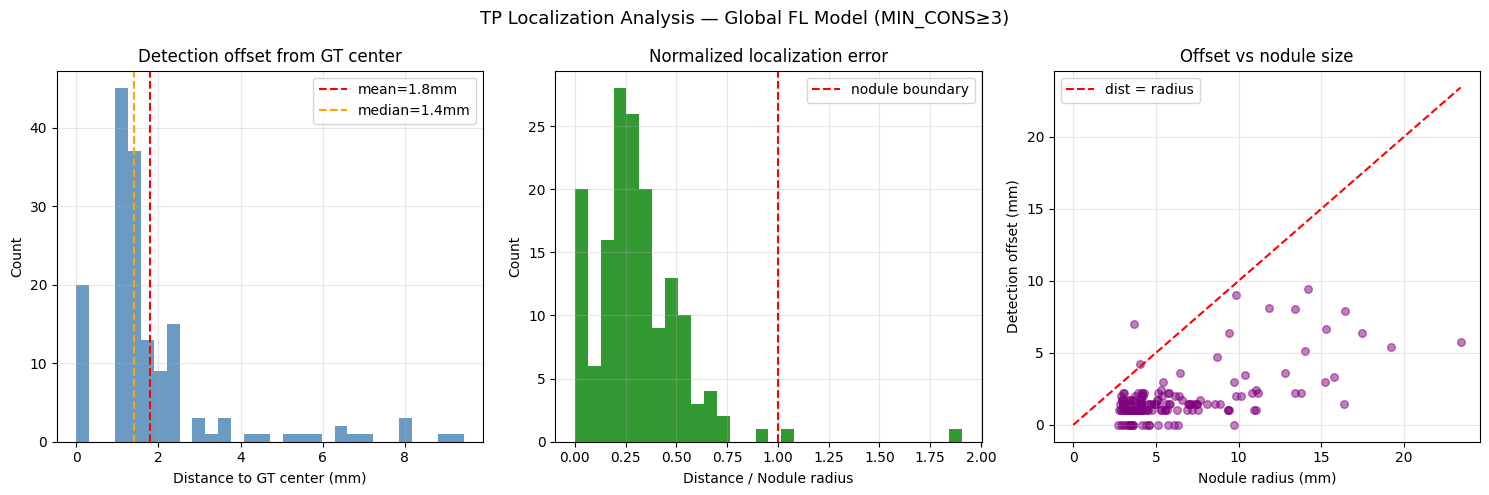


Plot saved: C:\Users\Administrator\desktop\unet\logs_global\tp_localization_analysis.png


In [2]:
import pickle
import numpy as np
from pathlib import Path

OUT_ROOT       = Path(r"C:\Users\Administrator\desktop\unet")
GLOBAL_LOG_DIR = OUT_ROOT / "logs_global"

with open(GLOBAL_LOG_DIR / "global_all_results.pkl", "rb") as f:
    all_results_g = pickle.load(f)

# collect all TP distances
tp_distances  = []
tp_radii      = []
tp_normalized = []  # dist / radius — how far as fraction of nodule size

for r in all_results_g:
    for item in r["tp_list"]:
        dist      = item["dist_mm"]
        radius_mm = item["gt"]["radius_mm"]
        tp_distances.append(dist)
        tp_radii.append(radius_mm)
        tp_normalized.append(dist / max(radius_mm, 1.0))

tp_distances  = np.array(tp_distances)
tp_radii      = np.array(tp_radii)
tp_normalized = np.array(tp_normalized)

print(f"{'='*55}")
print(f"TP LOCALIZATION ANALYSIS (MIN_CONS≥3)")
print(f"{'='*55}")
print(f"Total TPs analyzed: {len(tp_distances)}")

print(f"\nDistance from detection to GT center (mm):")
print(f"  Mean   : {tp_distances.mean():.2f}mm")
print(f"  Median : {np.median(tp_distances):.2f}mm")
print(f"  Std    : {tp_distances.std():.2f}mm")
print(f"  Min    : {tp_distances.min():.2f}mm")
print(f"  Max    : {tp_distances.max():.2f}mm")
print(f"  90th % : {np.percentile(tp_distances, 90):.2f}mm")
print(f"  95th % : {np.percentile(tp_distances, 95):.2f}mm")

print(f"\nNormalized distance (dist / nodule_radius):")
print(f"  Mean   : {tp_normalized.mean():.3f}")
print(f"  Median : {np.median(tp_normalized):.3f}")
print(f"  <0.5   : {(tp_normalized<0.5).sum()} "
      f"({100*(tp_normalized<0.5).mean():.1f}%)  "
      f"← within half the nodule radius")
print(f"  <1.0   : {(tp_normalized<1.0).sum()} "
      f"({100*(tp_normalized<1.0).mean():.1f}%)  "
      f"← within nodule boundary")
print(f"  >1.0   : {(tp_normalized>1.0).sum()} "
      f"({100*(tp_normalized>1.0).mean():.1f}%)  "
      f"← outside nodule boundary but matched")

print(f"\nDistance buckets:")
buckets = [0, 2, 5, 10, 15, 20]
for i in range(len(buckets)-1):
    lo, hi = buckets[i], buckets[i+1]
    count  = ((tp_distances>=lo) & (tp_distances<hi)).sum()
    pct    = 100*count/len(tp_distances)
    print(f"  {lo:>3}-{hi:>3}mm : {count:>4} ({pct:>5.1f}%)")
count = (tp_distances >= buckets[-1]).sum()
print(f"  >{buckets[-1]:>3}mm    : {count:>4} "
      f"({100*count/len(tp_distances):>5.1f}%)")

print(f"\nNodule size distribution of TPs:")
print(f"  Mean radius : {tp_radii.mean():.2f}mm")
print(f"  Median      : {np.median(tp_radii):.2f}mm")
print(f"  <3mm nodules: {(tp_radii<3).sum()} "
      f"({100*(tp_radii<3).mean():.1f}%)")
print(f"  3-6mm       : {((tp_radii>=3)&(tp_radii<6)).sum()} "
      f"({100*((tp_radii>=3)&(tp_radii<6)).mean():.1f}%)")
print(f"  6-10mm      : {((tp_radii>=6)&(tp_radii<10)).sum()} "
      f"({100*((tp_radii>=6)&(tp_radii<10)).mean():.1f}%)")
print(f"  >10mm       : {(tp_radii>=10).sum()} "
      f"({100*(tp_radii>=10).mean():.1f}%)")

# plot
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle("TP Localization Analysis — Global FL Model (MIN_CONS≥3)",
             fontsize=13)

axes[0].hist(tp_distances, bins=30, color='steelblue', alpha=0.8)
axes[0].axvline(tp_distances.mean(), color='red', linestyle='--',
                label=f'mean={tp_distances.mean():.1f}mm')
axes[0].axvline(np.median(tp_distances), color='orange',
                linestyle='--',
                label=f'median={np.median(tp_distances):.1f}mm')
axes[0].set_xlabel('Distance to GT center (mm)')
axes[0].set_ylabel('Count')
axes[0].set_title('Detection offset from GT center')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].hist(tp_normalized, bins=30, color='green', alpha=0.8)
axes[1].axvline(1.0, color='red', linestyle='--',
                label='nodule boundary')
axes[1].set_xlabel('Distance / Nodule radius')
axes[1].set_ylabel('Count')
axes[1].set_title('Normalized localization error')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

axes[2].scatter(tp_radii, tp_distances,
                alpha=0.5, color='purple', s=30)
axes[2].plot([0, tp_radii.max()],
             [0, tp_radii.max()],
             'r--', label='dist = radius')
axes[2].set_xlabel('Nodule radius (mm)')
axes[2].set_ylabel('Detection offset (mm)')
axes[2].set_title('Offset vs nodule size')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(GLOBAL_LOG_DIR / "tp_localization_analysis.png",
            dpi=100, bbox_inches='tight')
plt.show()
print(f"\nPlot saved: {GLOBAL_LOG_DIR/'tp_localization_analysis.png'}")

C:\ProgramData\miniconda3\envs\lungfl\lib\site-packages\pylidc\__init__.py:27: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources as _pr


SLICE THICKNESS DISTRIBUTION PER CLIENT (mm)
Client       Mean   Median    Std    Min    Max   ≤1.25    ≤2.0    ≤2.5
─────────────────────────────────────────────────────────────────
Client 1      2.10     2.50   0.65   0.60   3.00   32.5%   40.0%   88.8%
Client 2      2.07     2.50   0.60   0.75   2.50   31.1%   36.7%  100.0%
Client 3      1.61     1.25   0.58   0.60   2.50   58.0%   78.0%  100.0%
Client 4      1.60     1.25   0.61   0.60   2.50   61.2%   75.3%  100.0%
Client 5      1.62     1.25   0.56   0.75   2.50   58.6%   79.6%  100.0%

NODULE SIZE DISTRIBUTION PER CLIENT (diameter mm)
Client      N nods   Mean   Median    <6mm    6-10   10-20   >20mm
─────────────────────────────────────────────────────────────────
Client 1        291  13.43    10.44    4.1%   43.3%   33.3%   19.2%
Client 2        222  13.14    10.13    4.5%   44.1%   34.7%   16.7%
Client 3        266   9.98     8.28   11.7%   59.4%   22.6%    6.4%
Client 4        197  10.72     8.98   13.2%   52.8%   26.4%    7

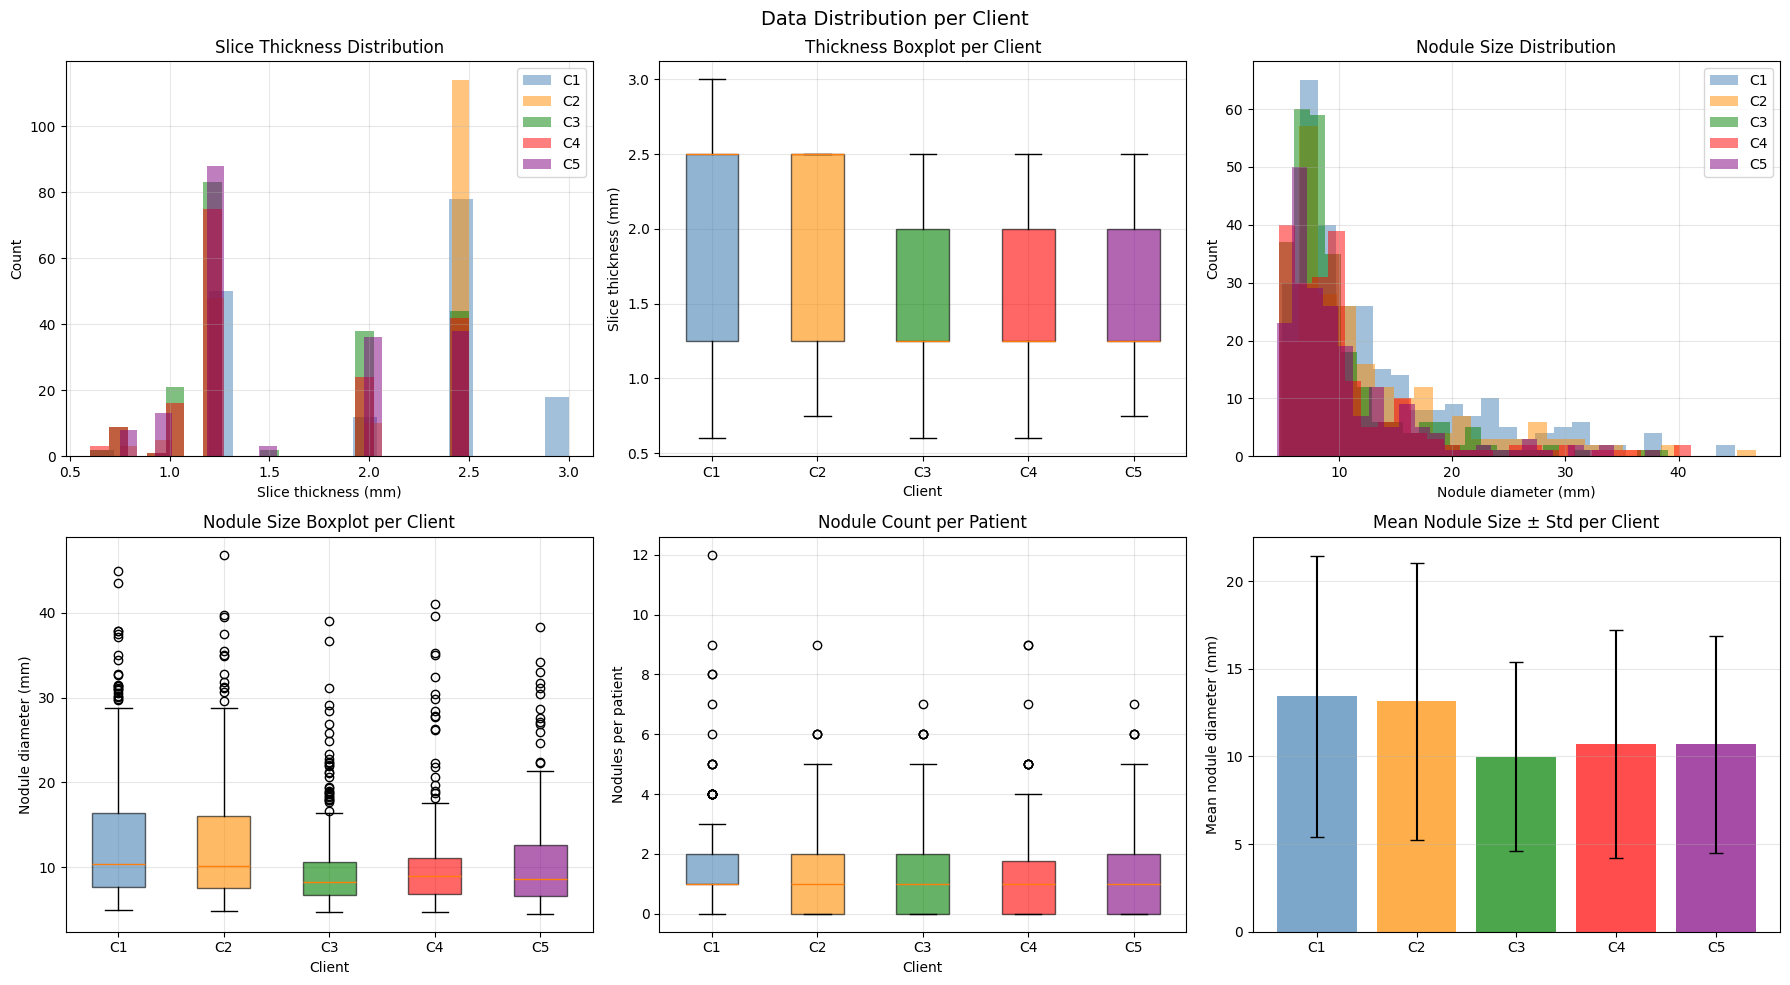


Plot saved: C:\Users\Administrator\desktop\unet\logs_global\distribution_analysis.png


In [3]:
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import pylidc as pl
import warnings
warnings.filterwarnings('ignore')

if not hasattr(np, 'int'):
    np.int = int

OUT_ROOT = Path(r"C:\Users\Administrator\desktop\unet")

# load federation splits
with open(OUT_ROOT / "federation_splits.json") as f:
    fed_splits = json.load(f)

# load pylidc
all_scans = pl.query(pl.Scan).order_by(pl.Scan.patient_id).all()
seen = {}
for s in all_scans:
    if s.patient_id not in seen:
        seen[s.patient_id] = s

# ── collect per-client stats ──────────────────────────────────
client_data = {}

for cid in [1, 2, 3, 4, 5]:
    pids = fed_splits[f"client{cid}_pids"]

    if cid == 1:
        annot_dir = OUT_ROOT / "annotations"
    else:
        annot_dir = OUT_ROOT / f"client{cid}" / "annotations"

    thicknesses  = []
    nodule_sizes = []
    nodule_counts = []

    for pid in pids:
        # slice thickness from pylidc
        scan = seen.get(pid)
        if scan:
            thicknesses.append(float(scan.slice_thickness))

        # nodule sizes from annotations
        ap = annot_dir / f"{pid}.json"
        if ap.exists():
            with open(ap) as f:
                record = json.load(f)
            nodule_counts.append(record["n_consensus_nodules"])
            for nod in record["consensus_nodules"]:
                nodule_sizes.append(nod["radius_mm"] * 2)  # diameter

    client_data[cid] = {
        "thicknesses"  : thicknesses,
        "nodule_sizes" : nodule_sizes,
        "nodule_counts": nodule_counts,
        "n_patients"   : len(pids),
    }

# ── print thickness distribution ─────────────────────────────
print(f"{'='*65}")
print(f"SLICE THICKNESS DISTRIBUTION PER CLIENT (mm)")
print(f"{'='*65}")
print(f"{'Client':<10} {'Mean':>6} {'Median':>8} {'Std':>6} "
      f"{'Min':>6} {'Max':>6} {'≤1.25':>7} {'≤2.0':>7} {'≤2.5':>7}")
print(f"{'─'*65}")

for cid in [1,2,3,4,5]:
    t = np.array(client_data[cid]["thicknesses"])
    if len(t) == 0:
        continue
    le125 = (t<=1.25).mean()*100
    le200 = (t<=2.00).mean()*100
    le250 = (t<=2.50).mean()*100
    print(f"Client {cid:<4} "
          f"{t.mean():>6.2f} "
          f"{np.median(t):>8.2f} "
          f"{t.std():>6.2f} "
          f"{t.min():>6.2f} "
          f"{t.max():>6.2f} "
          f"{le125:>6.1f}% "
          f"{le200:>6.1f}% "
          f"{le250:>6.1f}%")

# ── print nodule size distribution ───────────────────────────
print(f"\n{'='*65}")
print(f"NODULE SIZE DISTRIBUTION PER CLIENT (diameter mm)")
print(f"{'='*65}")
print(f"{'Client':<10} {'N nods':>7} {'Mean':>6} {'Median':>8} "
      f"{'<6mm':>7} {'6-10':>7} {'10-20':>7} {'>20mm':>7}")
print(f"{'─'*65}")

for cid in [1,2,3,4,5]:
    s = np.array(client_data[cid]["nodule_sizes"])
    if len(s) == 0:
        print(f"Client {cid:<4}  no nodules")
        continue
    sm   = (s<6).mean()*100
    med  = ((s>=6)&(s<10)).mean()*100
    lrg  = ((s>=10)&(s<20)).mean()*100
    xlrg = (s>=20).mean()*100
    print(f"Client {cid:<4} "
          f"{len(s):>7} "
          f"{s.mean():>6.2f} "
          f"{np.median(s):>8.2f} "
          f"{sm:>6.1f}% "
          f"{med:>6.1f}% "
          f"{lrg:>6.1f}% "
          f"{xlrg:>6.1f}%")

# ── nodule count distribution ─────────────────────────────────
print(f"\n{'='*65}")
print(f"NODULE COUNT PER PATIENT DISTRIBUTION")
print(f"{'='*65}")
print(f"{'Client':<10} {'0 nods':>8} {'1 nod':>8} "
      f"{'2-3':>8} {'4-5':>8} {'>5':>8} {'Mean':>8}")
print(f"{'─'*65}")

for cid in [1,2,3,4,5]:
    nc = np.array(client_data[cid]["nodule_counts"])
    if len(nc) == 0:
        continue
    p0  = (nc==0).mean()*100
    p1  = (nc==1).mean()*100
    p23 = ((nc>=2)&(nc<=3)).mean()*100
    p45 = ((nc>=4)&(nc<=5)).mean()*100
    p5p = (nc>5).mean()*100
    print(f"Client {cid:<4} "
          f"{p0:>7.1f}% "
          f"{p1:>7.1f}% "
          f"{p23:>7.1f}% "
          f"{p45:>7.1f}% "
          f"{p5p:>7.1f}% "
          f"{nc.mean():>8.2f}")

# ── plots ─────────────────────────────────────────────────────
colors = ['steelblue','darkorange','green','red','purple']
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("Data Distribution per Client", fontsize=14)

# thickness distribution per client
for cid in [1,2,3,4,5]:
    t = client_data[cid]["thicknesses"]
    axes[0,0].hist(t, bins=20, alpha=0.5,
                   label=f"C{cid}", color=colors[cid-1])
axes[0,0].set_xlabel("Slice thickness (mm)")
axes[0,0].set_ylabel("Count")
axes[0,0].set_title("Slice Thickness Distribution")
axes[0,0].legend()
axes[0,0].grid(True, alpha=0.3)

# thickness boxplot
thickness_data = [client_data[cid]["thicknesses"]
                  for cid in [1,2,3,4,5]]
bp = axes[0,1].boxplot(thickness_data,
                        labels=[f"C{i}" for i in [1,2,3,4,5]],
                        patch_artist=True)
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)
axes[0,1].set_xlabel("Client")
axes[0,1].set_ylabel("Slice thickness (mm)")
axes[0,1].set_title("Thickness Boxplot per Client")
axes[0,1].grid(True, alpha=0.3)

# nodule size distribution per client
for cid in [1,2,3,4,5]:
    s = client_data[cid]["nodule_sizes"]
    if s:
        axes[0,2].hist(s, bins=25, alpha=0.5,
                       label=f"C{cid}", color=colors[cid-1])
axes[0,2].set_xlabel("Nodule diameter (mm)")
axes[0,2].set_ylabel("Count")
axes[0,2].set_title("Nodule Size Distribution")
axes[0,2].legend()
axes[0,2].grid(True, alpha=0.3)

# nodule size boxplot
size_data = [client_data[cid]["nodule_sizes"]
             for cid in [1,2,3,4,5]]
size_data_nonempty = [s if s else [0] for s in size_data]
bp2 = axes[1,0].boxplot(size_data_nonempty,
                          labels=[f"C{i}" for i in [1,2,3,4,5]],
                          patch_artist=True)
for patch, color in zip(bp2['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)
axes[1,0].set_xlabel("Client")
axes[1,0].set_ylabel("Nodule diameter (mm)")
axes[1,0].set_title("Nodule Size Boxplot per Client")
axes[1,0].grid(True, alpha=0.3)

# nodule count per patient
count_data = [client_data[cid]["nodule_counts"]
              for cid in [1,2,3,4,5]]
bp3 = axes[1,1].boxplot(count_data,
                          labels=[f"C{i}" for i in [1,2,3,4,5]],
                          patch_artist=True)
for patch, color in zip(bp3['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)
axes[1,1].set_xlabel("Client")
axes[1,1].set_ylabel("Nodules per patient")
axes[1,1].set_title("Nodule Count per Patient")
axes[1,1].grid(True, alpha=0.3)

# mean nodule diameter per client bar chart
means = [np.mean(client_data[cid]["nodule_sizes"])
         if client_data[cid]["nodule_sizes"] else 0
         for cid in [1,2,3,4,5]]
stds  = [np.std(client_data[cid]["nodule_sizes"])
         if client_data[cid]["nodule_sizes"] else 0
         for cid in [1,2,3,4,5]]
x = np.arange(5)
bars = axes[1,2].bar(x, means, yerr=stds,
                      color=colors, alpha=0.7,
                      capsize=5)
axes[1,2].set_xticks(x)
axes[1,2].set_xticklabels([f"C{i}" for i in [1,2,3,4,5]])
axes[1,2].set_ylabel("Mean nodule diameter (mm)")
axes[1,2].set_title("Mean Nodule Size ± Std per Client")
axes[1,2].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
out = OUT_ROOT / "logs_global" / "distribution_analysis.png"
plt.savefig(out, dpi=100, bbox_inches='tight')
plt.show()
print(f"\nPlot saved: {out}")

✓ No existing files would be overwritten
Loaded 133 patient results
PID→client map: 133 entries

PER-CLIENT RESULTS — FedAvg Moderate Non-IID
Client          N    GT    TP    FP    FN   Sens   Prec  FP/scan
────────────────────────────────────────────────────────────────────────
client1        24    52    51   114     1  0.981  0.309     4.75
client2        27    21    20   101     1  0.952  0.165     3.74
client3        30    47    39   103     8  0.830  0.275     3.43
client4        25    25    23    63     2  0.920  0.267     2.52
client5        27    30    27    76     3  0.900  0.262     2.81
────────────────────────────────────────────────────────────────────────
GLOBAL        133   175   160   457    15  0.914  0.259     3.44


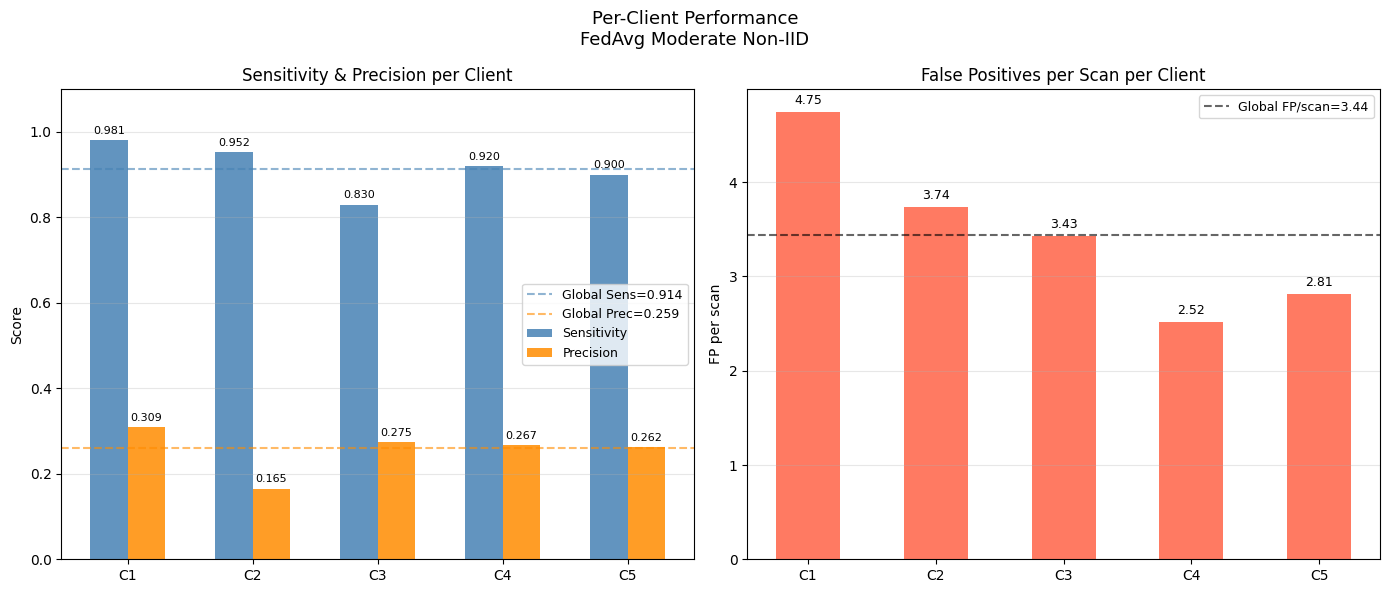


Plot saved : C:\Users\Administrator\desktop\unet\logs_global\per_client_metrics_fedavg_moderate.png
JSON saved : C:\Users\Administrator\desktop\unet\logs_global\per_client_metrics_fedavg_moderate.json


In [1]:
# PER-CLIENT EVALUATION — FEDAVG MODERATE
# Uses already-computed inference PKL
# Groups test patients by MODERATE non-IID client assignment
# No re-inference, no GPU needed
# Saves to: logs_global/
# ============================================================
import pickle
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from collections import defaultdict

OUT_ROOT = Path(r"C:\Users\Administrator\desktop\unet")

# ── assert no overwriting ─────────────────────────────────────
out_png  = OUT_ROOT / "logs_global" / "per_client_metrics_fedavg_moderate.png"
out_json = OUT_ROOT / "logs_global" / "per_client_metrics_fedavg_moderate.json"
assert not out_png.exists(),  f"Would overwrite {out_png}"
assert not out_json.exists(), f"Would overwrite {out_json}"
print("✓ No existing files would be overwritten")

# ── load inference results ────────────────────────────────────
PKL_PATH = OUT_ROOT / "logs_global" / "global_all_results.pkl"
assert PKL_PATH.exists(), f"Missing: {PKL_PATH}"
with open(PKL_PATH, "rb") as f:
    all_results = pickle.load(f)
print(f"Loaded {len(all_results)} patient results")

# ── load moderate test pool with by_client mapping ────────────
test_pool_path = OUT_ROOT / "global_test_pids.json"
assert test_pool_path.exists(), f"Missing: {test_pool_path}"
with open(test_pool_path) as f:
    global_test = json.load(f)

# build pid → client mapping
pid_to_client = {}
if "by_client" in global_test:
    for cid, pids in global_test["by_client"].items():
        for pid in pids:
            pid_to_client[pid] = cid
else:
    # fallback: use federation_splits.json
    print("by_client not in global_test_pids.json "
          "— using federation_splits.json")
    with open(OUT_ROOT / "federation_splits.json") as f:
        fed_splits = json.load(f)
    test_pids = set(global_test["test_pids"])
    for cid in [1,2,3,4,5]:
        for pid in fed_splits[f"client{cid}_pids"]:
            if pid in test_pids:
                pid_to_client[pid] = f"client{cid}"

print(f"PID→client map: {len(pid_to_client)} entries")

# ── group results by client ───────────────────────────────────
client_results = defaultdict(list)
unmapped = []
for r in all_results:
    pid = r["pid"]
    cid = pid_to_client.get(pid)
    if cid is None:
        unmapped.append(pid)
        continue
    client_results[cid].append(r)

if unmapped:
    print(f"WARNING: {len(unmapped)} pids not mapped to client")

EXP_NAME = "FedAvg Moderate Non-IID"
fp_pts   = [0.125, 0.25, 0.5, 1, 2, 4, 8]

# ── compute per-client metrics ────────────────────────────────
print(f"\n{'='*72}")
print(f"PER-CLIENT RESULTS — {EXP_NAME}")
print(f"{'='*72}")
print(f"{'Client':<12} {'N':>4} {'GT':>5} {'TP':>5} "
      f"{'FP':>5} {'FN':>5} {'Sens':>6} {'Prec':>6} "
      f"{'FP/scan':>8}")
print(f"{'─'*72}")

summary = {}
for cid in sorted(client_results.keys()):
    results  = client_results[cid]
    ttp = sum(r["tp"] for r in results)
    tfp = sum(r["fp"] for r in results)
    tfn = sum(r["fn"] for r in results)
    tgt = sum(r["gt_nodules"] for r in results)
    ns  = len(results)
    sen = ttp / max(ttp+tfn, 1)
    pre = ttp / max(ttp+tfp, 1)
    f1  = 2*pre*sen / max(pre+sen, 1e-6)
    fps = tfp / max(ns, 1)
    print(f"{cid:<12} {ns:>4} {tgt:>5} {ttp:>5} "
          f"{tfp:>5} {tfn:>5} {sen:>6.3f} {pre:>6.3f} "
          f"{fps:>8.2f}")
    summary[cid] = {
        "n_patients" : ns,
        "total_gt"   : tgt,
        "total_tp"   : ttp,
        "total_fp"   : tfp,
        "total_fn"   : tfn,
        "sensitivity": round(sen, 4),
        "precision"  : round(pre, 4),
        "f1"         : round(f1,  4),
        "fp_per_scan": round(fps, 4),
    }

# global
all_ttp = sum(r["tp"] for r in all_results)
all_tfp = sum(r["fp"] for r in all_results)
all_tfn = sum(r["fn"] for r in all_results)
all_gt  = sum(r["gt_nodules"] for r in all_results)
all_ns  = len(all_results)
all_sen = all_ttp / max(all_ttp+all_tfn, 1)
all_pre = all_ttp / max(all_ttp+all_tfp, 1)
all_fps = all_tfp / max(all_ns, 1)
print(f"{'─'*72}")
print(f"{'GLOBAL':<12} {all_ns:>4} {all_gt:>5} {all_ttp:>5} "
      f"{all_tfp:>5} {all_tfn:>5} {all_sen:>6.3f} "
      f"{all_pre:>6.3f} {all_fps:>8.2f}")

# ── bar chart ─────────────────────────────────────────────────
clients = sorted(summary.keys())
sens    = [summary[c]["sensitivity"] for c in clients]
precs   = [summary[c]["precision"]   for c in clients]
fps_    = [summary[c]["fp_per_scan"] for c in clients]
labels  = [c.replace("client","C") for c in clients]

x = np.arange(len(clients))
w = 0.30

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle(f"Per-Client Performance\n{EXP_NAME}",
             fontsize=13)

# sensitivity + precision
ax = axes[0]
b1 = ax.bar(x-w/2, sens,  w, label='Sensitivity',
            color='steelblue', alpha=0.85)
b2 = ax.bar(x+w/2, precs, w, label='Precision',
            color='darkorange', alpha=0.85)
ax.axhline(all_sen, color='steelblue', linestyle='--',
           alpha=0.6,
           label=f'Global Sens={all_sen:.3f}')
ax.axhline(all_pre, color='darkorange', linestyle='--',
           alpha=0.6,
           label=f'Global Prec={all_pre:.3f}')
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_ylim(0, 1.1); ax.set_ylabel('Score')
ax.set_title('Sensitivity & Precision per Client')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3, axis='y')
for b in b1:
    ax.text(b.get_x()+b.get_width()/2,
            b.get_height()+0.01,
            f'{b.get_height():.3f}',
            ha='center', va='bottom', fontsize=8)
for b in b2:
    ax.text(b.get_x()+b.get_width()/2,
            b.get_height()+0.01,
            f'{b.get_height():.3f}',
            ha='center', va='bottom', fontsize=8)

# FP/scan
ax = axes[1]
bars = ax.bar(x, fps_, 0.5, color='tomato', alpha=0.85)
ax.axhline(all_fps, color='black', linestyle='--',
           alpha=0.6,
           label=f'Global FP/scan={all_fps:.2f}')
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_ylabel('FP per scan')
ax.set_title('False Positives per Scan per Client')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3, axis='y')
for b in bars:
    ax.text(b.get_x()+b.get_width()/2,
            b.get_height()+0.05,
            f'{b.get_height():.2f}',
            ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig(out_png, dpi=100, bbox_inches='tight')
plt.show()
print(f"\nPlot saved : {out_png}")

# ── save json ─────────────────────────────────────────────────
with open(out_json, "w") as f:
    json.dump({
        "experiment": EXP_NAME,
        "per_client": summary,
        "global": {
            "n_patients" : all_ns,
            "total_gt"   : all_gt,
            "total_tp"   : all_ttp,
            "total_fp"   : all_tfp,
            "total_fn"   : all_tfn,
            "sensitivity": round(all_sen, 4),
            "precision"  : round(all_pre, 4),
            "fp_per_scan": round(all_fps, 4),
        }
    }, f, indent=2)
print(f"JSON saved : {out_json}")

FedAvg moderate DP <= to run

✓ Protected: weights (10 files untouched)
✓ Protected: logs_global (7 files untouched)
✓ Protected: fedprox_moderate (13 files untouched)
✓ Protected: fedprox_severe (12 files untouched)
✓ Protected: severe_noniid (20 files untouched)
✓ No existing files would be overwritten
✓ Monitor started (every 5s)
Device      : cuda
Experiment  : dp_fedavg_moderate_e5
Results dir : C:\Users\Administrator\desktop\unet\experiments\dp_fedavg_moderate_e5
DP noise multiplier : 0.3
Max gradient norm   : 1.0
Privacy level       : moderate (ε ≈ 5)

Verifying moderate non-IID manifests...
  Client 1: 975 train pos  220 val pos  24 test pts
  Client 2: 855 train pos  150 val pos  27 test pts
  Client 3: 930 train pos  165 val pos  30 test pts
  Client 4: 660 train pos  200 val pos  25 test pts
  Client 5: 700 train pos  175 val pos  27 test pts
✓ All manifests present

Loading all client data...
  Client 1: 2892 train  631 val
  Client 2: 2400 train  456 val
  Client 3: 2667 train  531 val
  Client 4: 1989

	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
INFO :      Starting Flower simulation, config: num_rounds=6, no round_timeout


  Client 5: 2042 train  447 val
✓ All clients loaded (noise=0.3, clip=1.0)

FLOWER FL — DP-FEDAVG MODERATE NON-IID
Clients          : 5
Rounds           : 6
Local epochs     : 5
Noise multiplier : 0.3
Max grad norm    : 1.0
Privacy level    : moderate (ε ≈ 5)
Results dir      : C:\Users\Administrator\desktop\unet\experiments\dp_fedavg_moderate_e5



2026-04-10 10:49:15,192	INFO worker.py:2012 -- Started a local Ray instance.
INFO :      Flower VCE: Ray initialized with resources: {'object_store_memory': 2249952460.0, 'GPU': 1.0, 'memory': 5249889076.0, 'node:__internal_head__': 1.0, 'node:127.0.0.1': 1.0, 'accelerator_type:A10G': 1.0, 'CPU': 4.0}
INFO :      Optimize your simulation with Flower VCE: https://flower.ai/docs/framework/how-to-run-simulations.html
INFO :      Flower VCE: Resources for each Virtual Client: {'num_cpus': 1, 'num_gpus': 1.0}
INFO :      Flower VCE: Creating VirtualClientEngineActorPool with 1 actors
INFO :      [INIT]
INFO :      Using initial global parameters provided by strategy
INFO :      Starting evaluation of initial global parameters
INFO :      Evaluation returned no results (`None`)
INFO :      
INFO :      [ROUND 1]
INFO :      configure_fit: strategy sampled 5 clients (out of 5)
(ClientAppActor pid=7344) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context:

(ClientAppActor pid=7344)     C1 R1 Ep1/5 loss=0.4851
(ClientAppActor pid=7344)     C1 R1 Ep2/5 loss=0.2829
(ClientAppActor pid=7344)     C1 R1 Ep3/5 loss=0.2311
(ClientAppActor pid=7344)     C1 R1 Ep4/5 loss=0.2144
(ClientAppActor pid=7344)     C1 R1 Ep5/5 loss=0.2089


...

(ClientAppActor pid=7344)     C2 R6 Ep1/5 loss=0.1393
(ClientAppActor pid=7344)     C2 R6 Ep2/5 loss=0.1364
(ClientAppActor pid=7344)     C2 R6 Ep3/5 loss=0.1337
(ClientAppActor pid=7344)     C2 R6 Ep4/5 loss=0.1292
(ClientAppActor pid=7344)     C2 R6 Ep5/5 loss=0.1259


INFO :      aggregate_fit: received 5 results and 0 failures
INFO :      configure_evaluate: strategy sampled 5 clients (out of 5)



  ✓ Round 6 saved: C:\Users\Administrator\desktop\unet\experiments\dp_fedavg_moderate_e5\fl_round6_global.pt


(ClientAppActor pid=7344) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid">}. You can import the `Context` like this: `from flwr.common import Context`
(ClientAppActor pid=7344) 
(ClientAppActor pid=7344)             This is a deprecated feature. It will be removed
(ClientAppActor pid=7344)             entirely in future versions of Flower.
(ClientAppActor pid=7344)         
(ClientAppActor pid=7344) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid">}. You can import the `Context` like this: `from flwr.common import Context`
(ClientAppActor pid=7344) 
(ClientAppActor pid=7344)             This is a deprecated feature. It will be removed
(ClientAppActor pid=7344)             entirely in future versions of Flower.
(ClientAppActor pid=7344)         
(ClientA


✓ Final model: C:\Users\Administrator\desktop\unet\experiments\dp_fedavg_moderate_e5\global_dp_fedavg_moderate_e5_final.pt


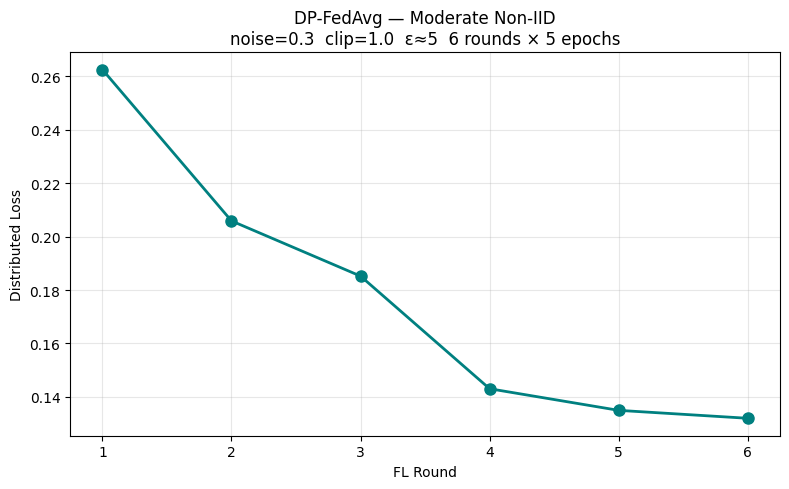


DP-FEDAVG MODERATE ε≈5 COMPLETE
Model   : C:\Users\Administrator\desktop\unet\experiments\dp_fedavg_moderate_e5\global_dp_fedavg_moderate_e5_final.pt
History : C:\Users\Administrator\desktop\unet\experiments\dp_fedavg_moderate_e5\fl_history_dp_fedavg_moderate_e5.json

Next: run Cell 8-DP-FEDAVG-MODERATE-E5

RESOURCE USAGE REPORT
RAM  mean=7.17GB  peak=8.02GB
VRAM mean=16.70GB  peak=17.08GB
Resource plot saved: C:\Users\Administrator\desktop\unet\experiments\dp_fedavg_moderate_e5\resource_usage.png


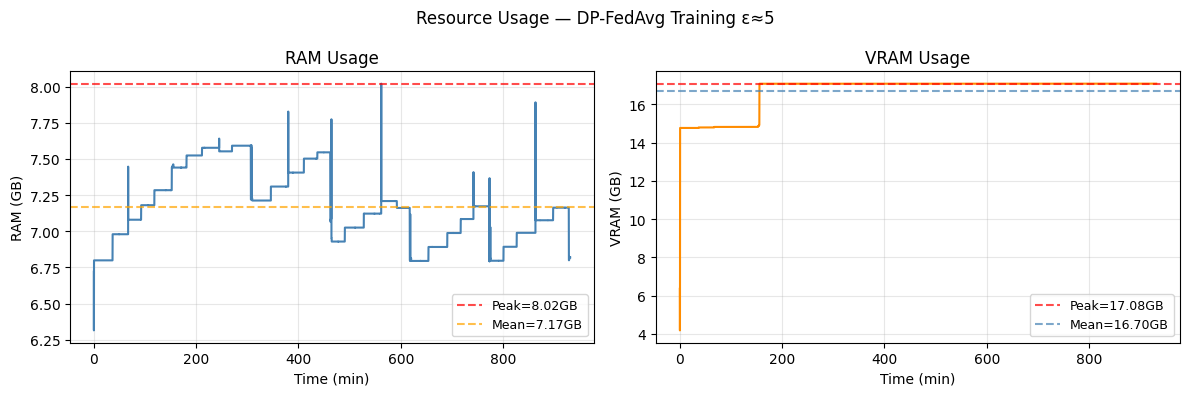

In [5]:
# CELL 7-DP-FEDAVG-MODERATE — Differentially Private FedAvg
# Moderate Non-IID, DP-FedAvg with Gaussian noise mechanism
# noise=0.3 → ε≈5 (moderate privacy)
# Saves to: experiments/dp_fedavg_moderate_e5/
# Nothing overwrites ANY existing results
# ============================================================
import flwr as fl
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from pathlib import Path
from flwr.server.strategy import FedAvg
from flwr.common import ndarrays_to_parameters, \
                        parameters_to_ndarrays
import numpy as np
import json
import random
import pickle
import shutil
import threading
import time
import psutil
import subprocess

class ResourceMonitor:
    def __init__(self, interval=5):
        self.interval=interval; self.ram_usage=[]
        self.vram_usage=[]; self.running=False
        self._thread=None
    def _monitor(self):
        while self.running:
            self.ram_usage.append(
                psutil.Process().memory_info().rss/1e9)
            try:
                r=subprocess.run(
                    ["nvidia-smi","--query-gpu=memory.used",
                     "--format=csv,noheader,nounits"],
                    capture_output=True,text=True)
                self.vram_usage.append(
                    float(r.stdout.strip())/1024)
            except: pass
            time.sleep(self.interval)
    def start(self):
        self.running=True
        self._thread=threading.Thread(
            target=self._monitor,daemon=True)
        self._thread.start()
        print(f"✓ Monitor started (every {self.interval}s)")
    def stop(self):
        self.running=False
        if self._thread: self._thread.join(timeout=10)
    def report(self):
        print(f"\n{'='*50}\nRESOURCE USAGE REPORT\n{'='*50}")
        if self.ram_usage:
            print(f"RAM  mean={np.mean(self.ram_usage):.2f}GB  "
                  f"peak={max(self.ram_usage):.2f}GB")
        if self.vram_usage:
            print(f"VRAM mean={np.mean(self.vram_usage):.2f}GB  "
                  f"peak={max(self.vram_usage):.2f}GB")
    def plot(self, save_path=None):
        if not self.ram_usage and not self.vram_usage: return
        import matplotlib.pyplot as plt
        fig,axes=plt.subplots(1,2,figsize=(12,4))
        fig.suptitle("Resource Usage — DP-FedAvg Training ε≈5",
                     fontsize=12)
        if self.ram_usage:
            t=[i*self.interval/60
               for i in range(len(self.ram_usage))]
            axes[0].plot(t,self.ram_usage,
                         color='steelblue',linewidth=1.5)
            axes[0].axhline(max(self.ram_usage),color='red',
                linestyle='--',alpha=0.7,
                label=f'Peak={max(self.ram_usage):.2f}GB')
            axes[0].axhline(np.mean(self.ram_usage),
                color='orange',linestyle='--',alpha=0.7,
                label=f'Mean={np.mean(self.ram_usage):.2f}GB')
            axes[0].set_xlabel('Time (min)')
            axes[0].set_ylabel('RAM (GB)')
            axes[0].set_title('RAM Usage')
            axes[0].legend(fontsize=9)
            axes[0].grid(True,alpha=0.3)
        if self.vram_usage:
            t=[i*self.interval/60
               for i in range(len(self.vram_usage))]
            axes[1].plot(t,self.vram_usage,
                         color='darkorange',linewidth=1.5)
            axes[1].axhline(max(self.vram_usage),color='red',
                linestyle='--',alpha=0.7,
                label=f'Peak={max(self.vram_usage):.2f}GB')
            axes[1].axhline(np.mean(self.vram_usage),
                color='steelblue',linestyle='--',alpha=0.7,
                label=f'Mean={np.mean(self.vram_usage):.2f}GB')
            axes[1].set_xlabel('Time (min)')
            axes[1].set_ylabel('VRAM (GB)')
            axes[1].set_title('VRAM Usage')
            axes[1].legend(fontsize=9)
            axes[1].grid(True,alpha=0.3)
        plt.tight_layout()
        if save_path:
            plt.savefig(save_path,dpi=100,bbox_inches='tight')
            print(f"Resource plot saved: {save_path}")
        plt.show()

OUT_ROOT = Path(r"C:\Users\Administrator\desktop\unet")
EXP_DIR  = OUT_ROOT / "experiments" / "dp_fedavg_moderate_e5"
EXP_DIR.mkdir(parents=True, exist_ok=True)

# ── assert no overwriting ─────────────────────────────────────
files_that_would_be_written = [
    EXP_DIR / f"fl_round{r}_global.pt" for r in range(1,7)
] + [
    EXP_DIR / "global_dp_fedavg_moderate_e5_final.pt",
    EXP_DIR / "fl_history_dp_fedavg_moderate_e5.json",
    EXP_DIR / "fl_loss_dp_fedavg_moderate_e5.png",
    EXP_DIR / "resource_usage.png",
]
for f in files_that_would_be_written:
    assert not f.exists(), \
        f"Would overwrite {f} — delete it first"

# verify protected dirs untouched
protected = [
    OUT_ROOT / "weights",
    OUT_ROOT / "logs_global",
    OUT_ROOT / "experiments" / "fedprox_moderate",
    OUT_ROOT / "experiments" / "fedprox_severe",
    OUT_ROOT / "experiments" / "fedprox_severe_mu001",
    OUT_ROOT / "experiments" / "severe_noniid",
]
for p in protected:
    if p.exists():
        n = len(list(p.rglob("*.pt")) +
                list(p.rglob("*.pkl")) +
                list(p.rglob("*.json")))
        print(f"✓ Protected: {p.name} ({n} files untouched)")

print("✓ No existing files would be overwritten")

monitor = ResourceMonitor(interval=5)
monitor.start()

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Device      : {DEVICE}")
print(f"Experiment  : dp_fedavg_moderate_e5")
print(f"Results dir : {EXP_DIR}")

# ── FL + DP hyperparameters ───────────────────────────────────
NUM_ROUNDS       = 6
LOCAL_EPOCHS     = 5
BATCH_SIZE       = 4
LR               = 1e-4
BASE_FILTERS     = 32
NOISE_MULTIPLIER = 0.3
MAX_GRAD_NORM    = 1.0

print(f"DP noise multiplier : {NOISE_MULTIPLIER}")
print(f"Max gradient norm   : {MAX_GRAD_NORM}")
print(f"Privacy level       : moderate (ε ≈ 5)")

# ── UNet ─────────────────────────────────────────────────────
class DoubleConv3D(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm3d(out_ch), nn.ReLU(inplace=True),
            nn.Conv3d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm3d(out_ch), nn.ReLU(inplace=True))
    def forward(self, x): return self.block(x)

class Down(nn.Module):
    def __init__(self, c1, c2):
        super().__init__()
        self.pool = nn.MaxPool3d(2)
        self.conv = DoubleConv3D(c1, c2)
    def forward(self, x): return self.conv(self.pool(x))

class Up(nn.Module):
    def __init__(self, c1, c2):
        super().__init__()
        self.up   = nn.ConvTranspose3d(c1, c2, 2, stride=2)
        self.conv = DoubleConv3D(c1, c2)
    def forward(self, x, skip):
        return self.conv(torch.cat([skip, self.up(x)], dim=1))

class UNet3D(nn.Module):
    def __init__(self, base_filters=32):
        super().__init__()
        f = base_filters
        self.enc1=DoubleConv3D(1,f);   self.enc2=Down(f,f*2)
        self.enc3=Down(f*2,f*4);       self.enc4=Down(f*4,f*8)
        self.bottleneck=Down(f*8,f*16)
        self.dec4=Up(f*16,f*8); self.dec3=Up(f*8,f*4)
        self.dec2=Up(f*4,f*2);  self.dec1=Up(f*2,f)
        self.head=nn.Conv3d(f,1,1)
    def forward(self, x):
        e1=self.enc1(x); e2=self.enc2(e1)
        e3=self.enc3(e2); e4=self.enc4(e3)
        b=self.bottleneck(e4)
        return torch.sigmoid(self.head(
            self.dec1(self.dec2(self.dec3(
                self.dec4(b,e4),e3),e2),e1)))

class OHEMLoss(nn.Module):
    def __init__(self, neg_pos_ratio=3, min_negatives=1000):
        super().__init__()
        self.npr=neg_pos_ratio; self.mnn=min_negatives
    def forward(self, pred, target):
        loss=0.0
        for i in range(pred.shape[0]):
            p=pred[i,0]; t=target[i,0]
            pm=t>0.01; nm=~pm
            pl=F.binary_cross_entropy(
                p[pm],t[pm],reduction='mean'
            ) if pm.sum()>0 else torch.tensor(
                0.0,device=pred.device)
            n_neg=min(int(nm.sum()),
                      max(self.mnn,int(pm.sum())*self.npr))
            nl=F.binary_cross_entropy(
                p[nm],
                torch.zeros(nm.sum(),device=pred.device),
                reduction='none'
            ).topk(n_neg).values.mean()
            loss+=pl+nl
        return loss/pred.shape[0]

class PatchDataset(Dataset):
    def __init__(self, pos_files, neg_files, augment=False):
        self.augment=augment
        self.items=([(str(f),1) for f in pos_files]+
                    [(str(f),0) for f in neg_files])
        random.shuffle(self.items)
    def __len__(self): return len(self.items)
    def __getitem__(self, idx):
        path,_=self.items[idx]; d=np.load(path)
        vol=d['vol'].astype(np.float32)
        heat=d['heatmap'].astype(np.float32)
        if self.augment:
            for ax in range(3):
                if random.random()>0.5:
                    vol=np.flip(vol,axis=ax).copy()
                    heat=np.flip(heat,axis=ax).copy()
            k=random.randint(0,3)
            vol=np.rot90(vol,k=k,axes=(1,2)).copy()
            heat=np.rot90(heat,k=k,axes=(1,2)).copy()
        return (torch.from_numpy(vol).unsqueeze(0),
                torch.from_numpy(heat).unsqueeze(0))

# ── load moderate non-IID manifests ──────────────────────────
def get_patch_dir(cid):
    if cid == 1:
        return OUT_ROOT / "patches" / "client1"
    return OUT_ROOT / f"client{cid}" / \
           "patches" / f"client{cid}"

print("\nVerifying moderate non-IID manifests...")
for cid in [1,2,3,4,5]:
    mp = get_patch_dir(cid) / "split_manifest.json"
    assert mp.exists(), f"Missing: {mp}"
    with open(mp) as f: m=json.load(f)
    print(f"  Client {cid}: {len(m['train_pos'])} train pos  "
          f"{len(m['val_pos'])} val pos  "
          f"{len(m['tst_pids'])} test pts")
print("✓ All manifests present\n")

# ── DP mechanism ──────────────────────────────────────────────
def clip_gradients(model, max_norm):
    total_norm = 0.0
    for p in model.parameters():
        if p.grad is not None:
            total_norm += p.grad.data.norm(2).item() ** 2
    total_norm = total_norm ** 0.5
    clip_coef  = max_norm / max(total_norm, max_norm)
    for p in model.parameters():
        if p.grad is not None:
            p.grad.data.mul_(clip_coef)
    return total_norm

def add_dp_noise_to_weights(params_before, params_after,
                             noise_multiplier,
                             max_grad_norm, n_samples):
    sensitivity = max_grad_norm / n_samples
    noise_scale = noise_multiplier * sensitivity
    noisy = []
    for pb, pa in zip(params_before, params_after):
        noise = np.random.normal(
            0, noise_scale, pa.shape).astype(np.float32)
        noisy.append(pa + noise)
    return noisy

# ── pre-load all clients ──────────────────────────────────────
print("Loading all client data...")
clients = {}

for cid in [1,2,3,4,5]:
    with open(get_patch_dir(cid)/
              "split_manifest.json") as f:
        manifest = json.load(f)
    train_pos=[Path(p) for p in manifest["train_pos"]]
    train_neg=[Path(p) for p in manifest["train_neg"]]
    val_pos  =[Path(p) for p in manifest["val_pos"]]
    val_neg  =[Path(p) for p in manifest["val_neg"]]
    train_ds =PatchDataset(train_pos,train_neg,augment=True)
    val_ds   =PatchDataset(val_pos,  val_neg,  augment=False)
    train_loader=DataLoader(train_ds,batch_size=BATCH_SIZE,
        shuffle=True,num_workers=0,pin_memory=True)
    val_loader  =DataLoader(val_ds,  batch_size=BATCH_SIZE,
        shuffle=False,num_workers=0,pin_memory=True)
    model    =UNet3D(base_filters=BASE_FILTERS).to(DEVICE)
    criterion=OHEMLoss(neg_pos_ratio=3,min_negatives=1000)

    class DPFedAvgClient(fl.client.NumPyClient):
        def __init__(self,cid,model,train_loader,
                     val_loader,criterion,device,
                     noise_multiplier,max_grad_norm):
            self.cid=cid; self.model=model
            self.train_loader=train_loader
            self.val_loader=val_loader
            self.criterion=criterion
            self.device=device
            self.noise_multiplier=noise_multiplier
            self.max_grad_norm=max_grad_norm

        def get_parameters(self,config):
            # ← fix: detach() before numpy()
            return [v.detach().cpu().numpy()
                    for v in self.model.state_dict().values()]

        def set_parameters(self,parameters):
            state_dict=dict(zip(
                self.model.state_dict().keys(),
                [torch.tensor(p) for p in parameters]))
            self.model.load_state_dict(state_dict,strict=True)

        def fit(self,parameters,config):
            self.set_parameters(parameters)

            # ← fix: detach() before numpy()
            params_before=[
                p.detach().cpu().numpy().copy()
                for p in self.model.parameters()]

            local_epochs=config.get("local_epochs",LOCAL_EPOCHS)
            round_num   =config.get("round_num",0)
            optimizer=torch.optim.Adam(
                self.model.parameters(),lr=LR)
            from torch.optim.lr_scheduler import CosineAnnealingLR
            scheduler=CosineAnnealingLR(
                optimizer,T_max=local_epochs)
            self.model.train()
            total_loss=0.0
            n_batches=len(self.train_loader)
            for epoch in range(local_epochs):
                ep_loss=0.0
                for vol,heat in self.train_loader:
                    vol=vol.to(self.device)
                    heat=heat.to(self.device)
                    optimizer.zero_grad()
                    loss=self.criterion(self.model(vol),heat)
                    loss.backward()
                    clip_gradients(self.model,self.max_grad_norm)
                    optimizer.step()
                    ep_loss+=loss.item()
                scheduler.step()
                avg=ep_loss/max(n_batches,1)
                total_loss+=avg
                print(f"    C{self.cid} R{round_num} "
                      f"Ep{epoch+1}/{local_epochs} "
                      f"loss={avg:.4f}",flush=True)
            avg_loss =total_loss/max(local_epochs,1)
            n_samples=len(self.train_loader.dataset)

            # ← fix: detach() before numpy()
            params_after=[
                p.detach().cpu().numpy().copy()
                for p in self.model.parameters()]

            noisy_params=add_dp_noise_to_weights(
                params_before,params_after,
                self.noise_multiplier,
                self.max_grad_norm,n_samples)

            state_keys =list(self.model.state_dict().keys())
            param_keys =[n for n,p
                         in self.model.named_parameters()]
            noisy_idx=0; final_params=[]
            for key in state_keys:
                if key in param_keys:
                    final_params.append(noisy_params[noisy_idx])
                    noisy_idx+=1
                else:
                    # ← fix: detach() before numpy() on buffers
                    final_params.append(
                        self.model.state_dict()[key
                            ].detach().cpu().numpy())

            return (final_params,n_samples,
                    {"train_loss":float(avg_loss),
                     "client_id":self.cid,
                     "noise_multiplier":self.noise_multiplier})

        def evaluate(self,parameters,config):
            self.set_parameters(parameters)
            self.model.eval(); val_loss=0.0
            n_samples=len(self.val_loader.dataset)
            with torch.no_grad():
                for vol,heat in self.val_loader:
                    val_loss+=self.criterion(
                        self.model(vol.to(self.device)),
                        heat.to(self.device)).item()
            avg_val=val_loss/max(len(self.val_loader),1)
            return (float(avg_val),n_samples,
                    {"val_loss":float(avg_val),
                     "client_id":self.cid})

    clients[cid]=DPFedAvgClient(
        cid,model,train_loader,val_loader,
        criterion,DEVICE,NOISE_MULTIPLIER,MAX_GRAD_NORM)
    print(f"  Client {cid}: {len(train_ds)} train  "
          f"{len(val_ds)} val")

print(f"✓ All clients loaded "
      f"(noise={NOISE_MULTIPLIER}, clip={MAX_GRAD_NORM})\n")

def client_fn(cid):
    return clients[int(cid)+1].to_client()

round_weights={}

class SaveRoundStrategy(FedAvg):
    def aggregate_fit(self,server_round,results,failures):
        aggregated=super().aggregate_fit(
            server_round,results,failures)
        if aggregated is not None:
            params,_=aggregated
            ndarrays=parameters_to_ndarrays(params)
            model_keys=list(UNet3D(
                base_filters=BASE_FILTERS).state_dict().keys())
            state_dict=dict(zip(model_keys,
                [torch.tensor(p) for p in ndarrays]))
            save_path=EXP_DIR/f"fl_round{server_round}_global.pt"
            torch.save(state_dict,save_path)
            print(f"\n  ✓ Round {server_round} saved: {save_path}")
            round_weights[server_round]=save_path
        return aggregated

init_model =UNet3D(base_filters=BASE_FILTERS)
init_params=ndarrays_to_parameters(
    [v.detach().cpu().numpy()
     for v in init_model.state_dict().values()])

strategy=SaveRoundStrategy(
    fraction_fit=1.0, fraction_evaluate=1.0,
    min_fit_clients=5, min_evaluate_clients=5,
    min_available_clients=5,
    initial_parameters=init_params,
    on_fit_config_fn=lambda r:{
        "local_epochs":LOCAL_EPOCHS,"round_num":r},)

import matplotlib.pyplot as plt
print(f"{'='*55}")
print(f"FLOWER FL — DP-FEDAVG MODERATE NON-IID")
print(f"{'='*55}")
print(f"Clients          : 5")
print(f"Rounds           : {NUM_ROUNDS}")
print(f"Local epochs     : {LOCAL_EPOCHS}")
print(f"Noise multiplier : {NOISE_MULTIPLIER}")
print(f"Max grad norm    : {MAX_GRAD_NORM}")
print(f"Privacy level    : moderate (ε ≈ 5)")
print(f"Results dir      : {EXP_DIR}")
print(f"{'='*55}\n")

history=fl.simulation.start_simulation(
    client_fn=client_fn,
    num_clients=5,
    config=fl.server.ServerConfig(num_rounds=NUM_ROUNDS),
    strategy=strategy,
    client_resources={"num_cpus":1,"num_gpus":1.0},)

final_path=round_weights.get(NUM_ROUNDS)
if final_path and final_path.exists():
    GLOBAL_PT=EXP_DIR/"global_dp_fedavg_moderate_e5_final.pt"
    shutil.copy(final_path,GLOBAL_PT)
    print(f"\n✓ Final model: {GLOBAL_PT}")

fl_history={
    "experiment"        :"dp_fedavg_moderate_e5",
    "noise_multiplier"  :NOISE_MULTIPLIER,
    "max_grad_norm"     :MAX_GRAD_NORM,
    "privacy_epsilon"   :"≈5 (moderate)",
    "num_rounds"        :NUM_ROUNDS,
    "local_epochs"      :LOCAL_EPOCHS,
    "losses_distributed":[[r,float(l)]
        for r,l in history.losses_distributed],}
with open(EXP_DIR/"fl_history_dp_fedavg_moderate_e5.json",
          "w") as f:
    json.dump(fl_history,f,indent=2)

if history.losses_distributed:
    rounds=[r for r,l in history.losses_distributed]
    losses=[l for r,l in history.losses_distributed]
    fig,ax=plt.subplots(figsize=(8,5))
    ax.plot(rounds,losses,'o-',color='teal',
            linewidth=2,markersize=8)
    ax.set_xlabel('FL Round'); ax.set_ylabel('Distributed Loss')
    ax.set_title(f'DP-FedAvg — Moderate Non-IID\n'
                 f'noise={NOISE_MULTIPLIER}  '
                 f'clip={MAX_GRAD_NORM}  ε≈5  '
                 f'{NUM_ROUNDS} rounds × {LOCAL_EPOCHS} epochs')
    ax.grid(True,alpha=0.3); plt.tight_layout()
    plt.savefig(EXP_DIR/"fl_loss_dp_fedavg_moderate_e5.png",
                dpi=100)
    plt.show()

print(f"\n{'='*55}")
print(f"DP-FEDAVG MODERATE ε≈5 COMPLETE")
print(f"{'='*55}")
print(f"Model   : {EXP_DIR/'global_dp_fedavg_moderate_e5_final.pt'}")
print(f"History : {EXP_DIR/'fl_history_dp_fedavg_moderate_e5.json'}")
print(f"\nNext: run Cell 8-DP-FEDAVG-MODERATE-E5")

monitor.stop()
monitor.report()
monitor.plot(save_path=EXP_DIR/"resource_usage.png")

Device: cuda
✓ No existing files would be overwritten
✓ Monitor started (every 5s)
Model loaded: C:\Users\Administrator\desktop\unet\experiments\dp_fedavg_moderate_e5\global_dp_fedavg_moderate_e5_final.pt
Test patients: 133


DP-FedAvg moderate ε≈5 inference:   1%|▎                                             | 1/133 [00:32<1:12:08, 32.79s/it]

  LIDC-IDRI-0001: GT= 1 TP= 1 FP=  4 FN= 0


DP-FedAvg moderate ε≈5 inference:   2%|▋                                             | 2/133 [01:14<1:22:51, 37.95s/it]

  LIDC-IDRI-0012: GT= 9 TP= 9 FP=  7 FN= 0


...

  LIDC-IDRI-0978: GT= 2 TP= 2 FP=  3 FN= 0


DP-FedAvg moderate ε≈5 inference:  99%|███████████████████████████████████████████▋| 132/133 [1:21:47<00:30, 30.15s/it]

  LIDC-IDRI-0985: GT= 1 TP= 0 FP=  0 FN= 1


DP-FedAvg moderate ε≈5 inference: 100%|████████████████████████████████████████████| 133/133 [1:22:26<00:00, 37.19s/it]

  LIDC-IDRI-0987: GT= 2 TP= 2 FP=  2 FN= 0

✓ Results saved to C:\Users\Administrator\desktop\unet\experiments\dp_fedavg_moderate_e5

DP-FEDAVG MODERATE ε≈5 RESULTS
Patients    : 133
GT nodules  : 175
TP=157  FP=434  FN=18
Sensitivity : 0.897
Precision   : 0.266
F1          : 0.410
FP/scan     : 3.26

CPM (DP-FedAvg moderate ε≈5): 0.724
  0.125 FP/scan → 0.440
  0.250 FP/scan → 0.571
  0.500 FP/scan → 0.669
  1.000 FP/scan → 0.760
  2.000 FP/scan → 0.834
  4.000 FP/scan → 0.897
  8.000 FP/scan → 0.897


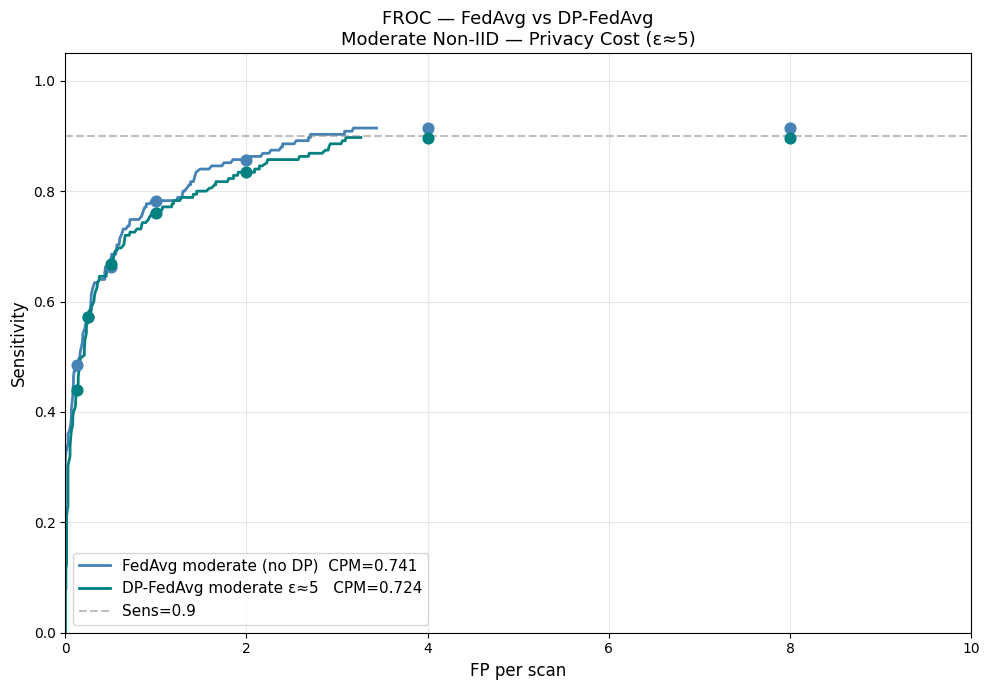


Privacy-utility tradeoff (moderate non-IID):
  FedAvg (no DP)  : CPM=0.741
  DP-FedAvg (ε≈5) : CPM=0.724
  CPM cost of DP  : 1.7%

OUTPUT FILES (nothing overwritten)
  experiments/dp_fedavg_moderate_e5/
  ├── dp_fedavg_moderate_e5_results.pkl
  ├── dp_fedavg_moderate_e5_scores.pkl
  ├── dp_fedavg_moderate_e5_test_results.json
  ├── froc_dp_fedavg_moderate_e5.png
  └── resource_usage_inference.png

RESOURCE USAGE REPORT
RAM  mean=6.85GB  peak=7.28GB
VRAM mean=11.72GB  peak=17.09GB
Resource plot saved: C:\Users\Administrator\desktop\unet\experiments\dp_fedavg_moderate_e5\resource_usage_inference.png


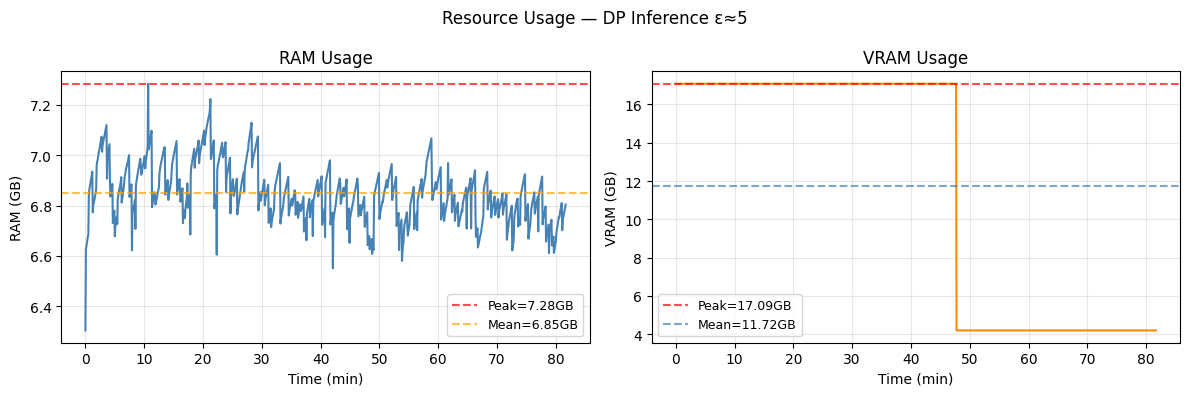

In [6]:
# CELL 8-DP-FEDAVG-MODERATE-E5 — Evaluation
# Evaluates global_dp_fedavg_moderate_e5_final.pt
# on original moderate test pool (133 patients)
# Saves to: experiments/dp_fedavg_moderate_e5/
# Nothing overwritten anywhere
# ============================================================
import torch
import torch.nn as nn
import numpy as np
import json
import pickle
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.ndimage import maximum_filter
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')
import threading, time, psutil, subprocess

class ResourceMonitor:
    def __init__(self,interval=5):
        self.interval=interval; self.ram_usage=[]
        self.vram_usage=[]; self.running=False
        self._thread=None
    def _monitor(self):
        while self.running:
            self.ram_usage.append(
                psutil.Process().memory_info().rss/1e9)
            try:
                r=subprocess.run(
                    ["nvidia-smi","--query-gpu=memory.used",
                     "--format=csv,noheader,nounits"],
                    capture_output=True,text=True)
                self.vram_usage.append(
                    float(r.stdout.strip())/1024)
            except: pass
            time.sleep(self.interval)
    def start(self):
        self.running=True
        self._thread=threading.Thread(
            target=self._monitor,daemon=True)
        self._thread.start()
        print(f"✓ Monitor started (every {self.interval}s)")
    def stop(self):
        self.running=False
        if self._thread: self._thread.join(timeout=10)
    def report(self):
        print(f"\n{'='*50}\nRESOURCE USAGE REPORT\n{'='*50}")
        if self.ram_usage:
            print(f"RAM  mean={np.mean(self.ram_usage):.2f}GB  "
                  f"peak={max(self.ram_usage):.2f}GB")
        if self.vram_usage:
            print(f"VRAM mean={np.mean(self.vram_usage):.2f}GB  "
                  f"peak={max(self.vram_usage):.2f}GB")
    def plot(self,save_path=None):
        if not self.ram_usage and not self.vram_usage: return
        fig,axes=plt.subplots(1,2,figsize=(12,4))
        fig.suptitle("Resource Usage — DP Inference ε≈5",
                     fontsize=12)
        if self.ram_usage:
            t=[i*self.interval/60
               for i in range(len(self.ram_usage))]
            axes[0].plot(t,self.ram_usage,
                         color='steelblue',linewidth=1.5)
            axes[0].axhline(max(self.ram_usage),color='red',
                linestyle='--',alpha=0.7,
                label=f'Peak={max(self.ram_usage):.2f}GB')
            axes[0].axhline(np.mean(self.ram_usage),
                color='orange',linestyle='--',alpha=0.7,
                label=f'Mean={np.mean(self.ram_usage):.2f}GB')
            axes[0].set_xlabel('Time (min)')
            axes[0].set_ylabel('RAM (GB)')
            axes[0].set_title('RAM Usage')
            axes[0].legend(fontsize=9)
            axes[0].grid(True,alpha=0.3)
        if self.vram_usage:
            t=[i*self.interval/60
               for i in range(len(self.vram_usage))]
            axes[1].plot(t,self.vram_usage,
                         color='darkorange',linewidth=1.5)
            axes[1].axhline(max(self.vram_usage),color='red',
                linestyle='--',alpha=0.7,
                label=f'Peak={max(self.vram_usage):.2f}GB')
            axes[1].axhline(np.mean(self.vram_usage),
                color='steelblue',linestyle='--',alpha=0.7,
                label=f'Mean={np.mean(self.vram_usage):.2f}GB')
            axes[1].set_xlabel('Time (min)')
            axes[1].set_ylabel('VRAM (GB)')
            axes[1].set_title('VRAM Usage')
            axes[1].legend(fontsize=9)
            axes[1].grid(True,alpha=0.3)
        plt.tight_layout()
        if save_path:
            plt.savefig(save_path,dpi=100,bbox_inches='tight')
            print(f"Resource plot saved: {save_path}")
        plt.show()

OUT_ROOT  = Path(r"C:\Users\Administrator\desktop\unet")
EXP_DIR   = OUT_ROOT / "experiments" / "dp_fedavg_moderate_e5"
GLOBAL_PT = EXP_DIR  / "global_dp_fedavg_moderate_e5_final.pt"

DEVICE           = 'cuda' if torch.cuda.is_available() else 'cpu'
PATCH_SIZE       = 96
STRIDE           = 20
THRESHOLD        = 0.3
BASE_FILTERS     = 32
NOISE_MULTIPLIER = 0.3

print(f"Device: {DEVICE}")

# ── assert no overwriting ─────────────────────────────────────
files_that_would_be_written = [
    EXP_DIR / "dp_fedavg_moderate_e5_results.pkl",
    EXP_DIR / "dp_fedavg_moderate_e5_scores.pkl",
    EXP_DIR / "dp_fedavg_moderate_e5_test_results.json",
    EXP_DIR / "froc_dp_fedavg_moderate_e5.png",
    EXP_DIR / "resource_usage_inference.png",
]
for f in files_that_would_be_written:
    assert not f.exists(), \
        f"Would overwrite {f} — delete it first"
print("✓ No existing files would be overwritten")

monitor = ResourceMonitor(interval=5)
monitor.start()

# ── UNet ─────────────────────────────────────────────────────
class DoubleConv3D(nn.Module):
    def __init__(self,in_ch,out_ch):
        super().__init__()
        self.block=nn.Sequential(
            nn.Conv3d(in_ch,out_ch,3,padding=1,bias=False),
            nn.BatchNorm3d(out_ch),nn.ReLU(inplace=True),
            nn.Conv3d(out_ch,out_ch,3,padding=1,bias=False),
            nn.BatchNorm3d(out_ch),nn.ReLU(inplace=True))
    def forward(self,x): return self.block(x)
class Down(nn.Module):
    def __init__(self,c1,c2):
        super().__init__()
        self.pool=nn.MaxPool3d(2)
        self.conv=DoubleConv3D(c1,c2)
    def forward(self,x): return self.conv(self.pool(x))
class Up(nn.Module):
    def __init__(self,c1,c2):
        super().__init__()
        self.up=nn.ConvTranspose3d(c1,c2,2,stride=2)
        self.conv=DoubleConv3D(c1,c2)
    def forward(self,x,skip):
        return self.conv(torch.cat([skip,self.up(x)],dim=1))
class UNet3D(nn.Module):
    def __init__(self,base_filters=32):
        super().__init__()
        f=base_filters
        self.enc1=DoubleConv3D(1,f); self.enc2=Down(f,f*2)
        self.enc3=Down(f*2,f*4);     self.enc4=Down(f*4,f*8)
        self.bottleneck=Down(f*8,f*16)
        self.dec4=Up(f*16,f*8); self.dec3=Up(f*8,f*4)
        self.dec2=Up(f*4,f*2);  self.dec1=Up(f*2,f)
        self.head=nn.Conv3d(f,1,1)
    def forward(self,x):
        e1=self.enc1(x); e2=self.enc2(e1)
        e3=self.enc3(e2); e4=self.enc4(e3)
        b=self.bottleneck(e4)
        return torch.sigmoid(self.head(
            self.dec1(self.dec2(self.dec3(
                self.dec4(b,e4),e3),e2),e1)))

# ── load model ────────────────────────────────────────────────
assert GLOBAL_PT.exists(), f"Model not found: {GLOBAL_PT}"
model=UNet3D(base_filters=BASE_FILTERS).to(DEVICE)
model.load_state_dict(torch.load(
    GLOBAL_PT,map_location=DEVICE))
model.eval()
print(f"Model loaded: {GLOBAL_PT}")

# ── load moderate test pool ───────────────────────────────────
with open(OUT_ROOT/"global_test_pids.json") as f:
    global_test=json.load(f)
all_test_pids=global_test["test_pids"]
print(f"Test patients: {len(all_test_pids)}")

# ── path routing ──────────────────────────────────────────────
with open(OUT_ROOT/"federation_splits.json") as f:
    orig_splits=json.load(f)

def get_patient_dirs(pid):
    if pid in orig_splits["client1_pids"]:
        return (OUT_ROOT/"preprocessed",
                OUT_ROOT/"lung_masks",
                OUT_ROOT/"annotations")
    for cid in [2,3,4,5]:
        if pid in orig_splits.get(f"client{cid}_pids",[]):
            cd=OUT_ROOT/f"client{cid}"
            return (cd/"preprocessed",
                    cd/"lung_masks",cd/"annotations")
    raise ValueError(f"{pid} not found")

# ── inference functions ───────────────────────────────────────
def sliding_window_max(model,vol,mask,
                        patch_size,stride,device):
    D,H,W=vol.shape; p=patch_size
    heatmap=np.zeros((D,H,W),dtype=np.float32)
    coords=np.argwhere(mask>0)
    if len(coords)==0: return heatmap
    z1=max(0,coords[:,0].min()-p//4)
    y1=max(0,coords[:,1].min()-p//4)
    x1=max(0,coords[:,2].min()-p//4)
    z2=min(D,coords[:,0].max()+p//4)
    y2=min(H,coords[:,1].max()+p//4)
    x2=min(W,coords[:,2].max()+p//4)
    model.eval()
    with torch.no_grad():
        for zw in range(z1,z2-p+1,stride):
            for yw in range(y1,y2-p+1,stride):
                for xw in range(x1,x2-p+1,stride):
                    patch=vol[zw:zw+p,yw:yw+p,xw:xw+p]
                    if patch.shape!=(p,p,p): continue
                    if mask[zw:zw+p,yw:yw+p,
                            xw:xw+p].mean()<0.05: continue
                    t=torch.from_numpy(patch).unsqueeze(0)\
                          .unsqueeze(0).float().to(device)
                    pred=model(t).squeeze().cpu().numpy()
                    heatmap[zw:zw+p,yw:yw+p,xw:xw+p]=\
                        np.maximum(
                            heatmap[zw:zw+p,yw:yw+p,xw:xw+p],
                            pred)
    return heatmap

def get_detections(heatmap,threshold=0.3,min_dist=6):
    lm=maximum_filter(
        heatmap,footprint=np.ones((min_dist,)*3))==heatmap
    lm=lm&(heatmap>threshold)
    c=np.argwhere(lm)
    if len(c)==0: return []
    s=heatmap[lm]; o=np.argsort(s)[::-1]
    return [(int(c[i,0]),int(c[i,1]),
             int(c[i,2]),float(s[i])) for i in o]

def match_gt(detections,gt_nodules):
    matched=set(); tp,fp=[],[]
    for det in detections:
        dz,dy,dx,sc=det; bd,bi=float('inf'),-1
        for gi,nod in enumerate(gt_nodules):
            if gi in matched: continue
            gz,gy,gx=nod['center_res']
            d=np.sqrt((dz-gz)**2+(dy-gy)**2+(dx-gx)**2)
            if d<max(nod['radius_mm'],10.0) and d<bd:
                bd,bi=d,gi
        if bi>=0:
            tp.append({'det':det,'gt':gt_nodules[bi],
                       'dist_mm':bd}); matched.add(bi)
        else: fp.append({'det':det})
    fn=[{'gt':n} for gi,n in enumerate(gt_nodules)
        if gi not in matched]
    return tp,fp,fn

# ── run inference ─────────────────────────────────────────────
all_results=[]; all_scores=[]; total_gt=0; missing=[]

for pid in tqdm(all_test_pids,
                desc="DP-FedAvg moderate ε≈5 inference"):
    try: pd_dir,md_dir,ad_dir=get_patient_dirs(pid)
    except ValueError:
        missing.append(pid); continue
    vp=pd_dir/f"{pid}.npy"; mp=md_dir/f"{pid}.npy"
    ap=ad_dir/f"{pid}.json"
    if not (vp.exists() and mp.exists() and ap.exists()):
        missing.append(pid); continue
    vol=np.load(vp); mask=np.load(mp)
    with open(ap) as f:
        gt_nods=json.load(f)["consensus_nodules"]
    total_gt+=len(gt_nods)
    heatmap   =sliding_window_max(
        model,vol,mask,PATCH_SIZE,STRIDE,DEVICE)
    detections=get_detections(heatmap,THRESHOLD)
    tp,fp,fn  =match_gt(detections,gt_nods)
    all_results.append({
        "pid":pid,"gt_nodules":len(gt_nods),
        "detections":len(detections),
        "tp":len(tp),"fp":len(fp),"fn":len(fn),
        "tp_list":tp,"fp_list":fp,"fn_list":fn,})
    for i in tp: all_scores.append((i["det"][3],1))
    for i in fp: all_scores.append((i["det"][3],0))
    print(f"  {pid}: GT={len(gt_nods):2d} "
          f"TP={len(tp):2d} FP={len(fp):3d} FN={len(fn):2d}")

# save immediately
with open(EXP_DIR/"dp_fedavg_moderate_e5_results.pkl","wb") as f:
    pickle.dump(all_results,f)
with open(EXP_DIR/"dp_fedavg_moderate_e5_scores.pkl","wb") as f:
    pickle.dump(all_scores,f)
print(f"\n✓ Results saved to {EXP_DIR}")

# ── metrics ───────────────────────────────────────────────────
ttp=sum(r["tp"] for r in all_results)
tfp=sum(r["fp"] for r in all_results)
tfn=sum(r["fn"] for r in all_results)
ns =len(all_results)
sen=ttp/max(ttp+tfn,1); pre=ttp/max(ttp+tfp,1)
f1 =2*pre*sen/max(pre+sen,1e-6); fps=tfp/max(ns,1)

print(f"\n{'='*55}")
print(f"DP-FEDAVG MODERATE ε≈5 RESULTS")
print(f"{'='*55}")
print(f"Patients    : {ns}")
print(f"GT nodules  : {total_gt}")
print(f"TP={ttp}  FP={tfp}  FN={tfn}")
print(f"Sensitivity : {sen:.3f}")
print(f"Precision   : {pre:.3f}")
print(f"F1          : {f1:.3f}")
print(f"FP/scan     : {fps:.2f}")

# ── FROC + CPM ────────────────────────────────────────────────
fp_pts=[0.125,0.25,0.5,1,2,4,8]
cpm=0.0; sl,fl=[],[]
if all_scores:
    all_scores.sort(key=lambda x:x[0],reverse=True)
    sa=np.array([s[0] for s in all_scores])
    la=np.array([s[1] for s in all_scores])
    for th in np.linspace(0.95,0.01,500):
        k=sa>=th
        sl.append(float(la[k].sum()/max(total_gt,1)))
        fl.append(float((1-la[k]).sum()/max(ns,1)))
    cpm_s=[sl[np.argmin([abs(f-fp) for f in fl])]
           for fp in fp_pts]
    cpm=float(np.mean(cpm_s))
    print(f"\nCPM (DP-FedAvg moderate ε≈5): {cpm:.3f}")
    for fp_pt,s in zip(fp_pts,cpm_s):
        print(f"  {fp_pt:5.3f} FP/scan → {s:.3f}")

# ── comparison: FedAvg vs DP-FedAvg ──────────────────────────
with open(OUT_ROOT/"logs_global"/
          "global_all_scores.pkl","rb") as f:
    fedavg_scores=pickle.load(f)
fedavg_scores.sort(key=lambda x:x[0],reverse=True)
sa_fa=np.array([s[0] for s in fedavg_scores])
la_fa=np.array([s[1] for s in fedavg_scores])
total_gt_fa=175; sl_fa,fl_fa=[],[]
for th in np.linspace(0.95,0.01,500):
    k=sa_fa>=th
    sl_fa.append(float(la_fa[k].sum()/max(total_gt_fa,1)))
    fl_fa.append(float((1-la_fa[k]).sum()/133))
cpm_fa_s=[sl_fa[np.argmin([abs(f-fp) for f in fl_fa])]
          for fp in fp_pts]
cpm_fa=float(np.mean(cpm_fa_s))

fig,ax=plt.subplots(figsize=(10,7))
ax.plot(fl_fa,sl_fa,color='steelblue',linewidth=2,
        label=f'FedAvg moderate (no DP)  CPM={cpm_fa:.3f}')
ax.plot(fl,   sl,   color='teal',     linewidth=2,
        label=f'DP-FedAvg moderate ε≈5   CPM={cpm:.3f}')
ax.scatter(fp_pts,cpm_fa_s,color='steelblue',zorder=5,s=60)
ax.scatter(fp_pts,cpm_s,   color='teal',     zorder=5,s=60)
ax.axhline(0.9,color='gray',linestyle='--',
           alpha=0.5,label='Sens=0.9')
ax.set_xlabel('FP per scan',fontsize=12)
ax.set_ylabel('Sensitivity',fontsize=12)
ax.set_title('FROC — FedAvg vs DP-FedAvg\n'
             'Moderate Non-IID — Privacy Cost (ε≈5)',
             fontsize=13)
ax.set_xlim(0,10); ax.set_ylim(0,1.05)
ax.legend(fontsize=11); ax.grid(True,alpha=0.3)
plt.tight_layout()
plt.savefig(EXP_DIR/"froc_dp_fedavg_moderate_e5.png",
            dpi=100,bbox_inches='tight')
plt.show()

print(f"\nPrivacy-utility tradeoff (moderate non-IID):")
print(f"  FedAvg (no DP)  : CPM={cpm_fa:.3f}")
print(f"  DP-FedAvg (ε≈5) : CPM={cpm:.3f}")
print(f"  CPM cost of DP  : {(cpm_fa-cpm)*100:.1f}%")

# ── save results ──────────────────────────────────────────────
with open(EXP_DIR/"dp_fedavg_moderate_e5_test_results.json",
          "w") as f:
    json.dump({
        "experiment"      :"dp_fedavg_moderate_e5",
        "noise_multiplier":NOISE_MULTIPLIER,
        "privacy_epsilon" :"≈5 (moderate)",
        "n_patients"      :ns,
        "total_gt"        :total_gt,
        "total_tp"        :ttp,
        "total_fp"        :tfp,
        "total_fn"        :tfn,
        "sensitivity"     :round(sen,4),
        "precision"       :round(pre,4),
        "f1"              :round(f1,4),
        "fp_per_scan"     :round(fps,4),
        "cpm"             :round(cpm,4),
        "cpm_fedavg_no_dp":round(cpm_fa,4),
        "cpm_cost_of_dp"  :round(cpm_fa-cpm,4),
    },f,indent=2)

print(f"\n{'='*55}")
print(f"OUTPUT FILES (nothing overwritten)")
print(f"{'='*55}")
print(f"  experiments/dp_fedavg_moderate_e5/")
print(f"  ├── dp_fedavg_moderate_e5_results.pkl")
print(f"  ├── dp_fedavg_moderate_e5_scores.pkl")
print(f"  ├── dp_fedavg_moderate_e5_test_results.json")
print(f"  ├── froc_dp_fedavg_moderate_e5.png")
print(f"  └── resource_usage_inference.png")

monitor.stop()
monitor.report()
monitor.plot(
    save_path=EXP_DIR/"resource_usage_inference.png")

✓ No existing files would be overwritten
Loaded 133 patient results
PID→client map: 133 entries

PER-CLIENT RESULTS — DP-FedAvg Moderate Non-IID (ε≈5)
Client          N    GT    TP    FP    FN   Sens   Prec  FP/scan
────────────────────────────────────────────────────────────────────────
client1        24    52    50   105     2  0.962  0.323     4.38
client2        27    21    19    97     2  0.905  0.164     3.59
client3        30    47    38   104     9  0.809  0.268     3.47
client4        25    25    24    64     1  0.960  0.273     2.56
client5        27    30    26    64     4  0.867  0.289     2.37
────────────────────────────────────────────────────────────────────────
GLOBAL        133   175   157   434    18  0.897  0.266     3.26

✓ FedAvg moderate per-client loaded


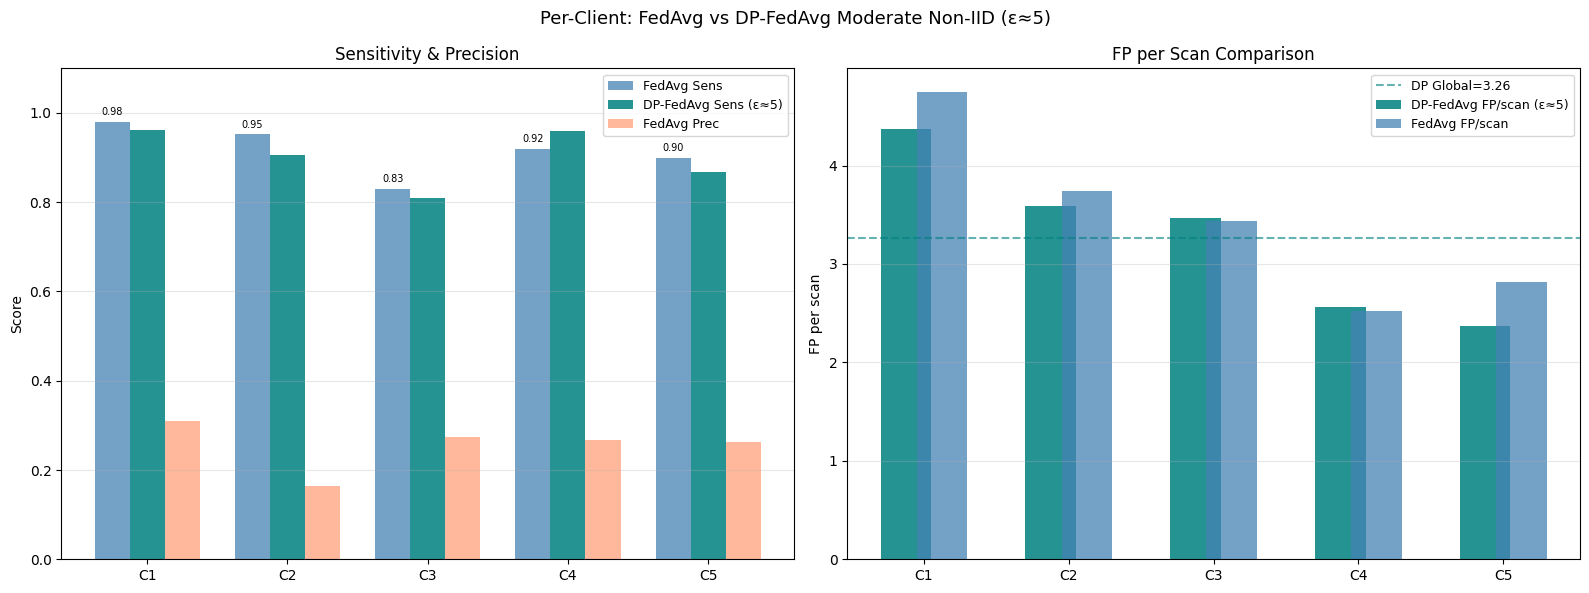


Plot saved : C:\Users\Administrator\desktop\unet\experiments\dp_fedavg_moderate_e5\per_client_metrics_dp_fedavg_moderate_e5.png
JSON saved : C:\Users\Administrator\desktop\unet\experiments\dp_fedavg_moderate_e5\per_client_metrics_dp_fedavg_moderate_e5.json


In [7]:
# PER-CLIENT EVALUATION — DP-FEDAVG MODERATE ε≈5
# Uses already-computed inference PKL
# Groups test patients by MODERATE non-IID client assignment
# No re-inference, no GPU needed
# Saves to: experiments/dp_fedavg_moderate_e5/
# ============================================================
import pickle
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from collections import defaultdict

OUT_ROOT = Path(r"C:\Users\Administrator\desktop\unet")
EXP_DIR  = OUT_ROOT/"experiments"/"dp_fedavg_moderate_e5"

# ── assert no overwriting ─────────────────────────────────────
out_png  = EXP_DIR/"per_client_metrics_dp_fedavg_moderate_e5.png"
out_json = EXP_DIR/"per_client_metrics_dp_fedavg_moderate_e5.json"
assert not out_png.exists(),  f"Would overwrite {out_png}"
assert not out_json.exists(), f"Would overwrite {out_json}"
print("✓ No existing files would be overwritten")

# ── load inference results ────────────────────────────────────
PKL_PATH = EXP_DIR/"dp_fedavg_moderate_e5_results.pkl"
assert PKL_PATH.exists(), f"Missing: {PKL_PATH}"
with open(PKL_PATH,"rb") as f:
    all_results=pickle.load(f)
print(f"Loaded {len(all_results)} patient results")

# ── load moderate test pool with by_client mapping ────────────
with open(OUT_ROOT/"global_test_pids.json") as f:
    global_test=json.load(f)

pid_to_client={}
if "by_client" in global_test:
    for cid,pids in global_test["by_client"].items():
        for pid in pids:
            pid_to_client[pid]=cid
else:
    with open(OUT_ROOT/"federation_splits.json") as f:
        fed_splits=json.load(f)
    test_pids=set(global_test["test_pids"])
    for cid in [1,2,3,4,5]:
        for pid in fed_splits[f"client{cid}_pids"]:
            if pid in test_pids:
                pid_to_client[pid]=f"client{cid}"

print(f"PID→client map: {len(pid_to_client)} entries")

# ── group results by client ───────────────────────────────────
client_results=defaultdict(list)
unmapped=[]
for r in all_results:
    pid=r["pid"]; cid=pid_to_client.get(pid)
    if cid is None: unmapped.append(pid); continue
    client_results[cid].append(r)
if unmapped:
    print(f"WARNING: {len(unmapped)} pids not mapped")

EXP_NAME="DP-FedAvg Moderate Non-IID (ε≈5)"

# ── compute per-client metrics ────────────────────────────────
print(f"\n{'='*72}")
print(f"PER-CLIENT RESULTS — {EXP_NAME}")
print(f"{'='*72}")
print(f"{'Client':<12} {'N':>4} {'GT':>5} {'TP':>5} "
      f"{'FP':>5} {'FN':>5} {'Sens':>6} {'Prec':>6} "
      f"{'FP/scan':>8}")
print(f"{'─'*72}")

summary={}
for cid in sorted(client_results.keys()):
    results=client_results[cid]
    ttp=sum(r["tp"] for r in results)
    tfp=sum(r["fp"] for r in results)
    tfn=sum(r["fn"] for r in results)
    tgt=sum(r["gt_nodules"] for r in results)
    ns =len(results)
    sen=ttp/max(ttp+tfn,1); pre=ttp/max(ttp+tfp,1)
    f1 =2*pre*sen/max(pre+sen,1e-6); fps=tfp/max(ns,1)
    print(f"{cid:<12} {ns:>4} {tgt:>5} {ttp:>5} "
          f"{tfp:>5} {tfn:>5} {sen:>6.3f} {pre:>6.3f} "
          f"{fps:>8.2f}")
    summary[cid]={
        "n_patients":ns,"total_gt":tgt,
        "total_tp":ttp,"total_fp":tfp,"total_fn":tfn,
        "sensitivity":round(sen,4),"precision":round(pre,4),
        "f1":round(f1,4),"fp_per_scan":round(fps,4),
    }

all_ttp=sum(r["tp"] for r in all_results)
all_tfp=sum(r["fp"] for r in all_results)
all_tfn=sum(r["fn"] for r in all_results)
all_gt =sum(r["gt_nodules"] for r in all_results)
all_ns =len(all_results)
all_sen=all_ttp/max(all_ttp+all_tfn,1)
all_pre=all_ttp/max(all_ttp+all_tfp,1)
all_fps=all_tfp/max(all_ns,1)
print(f"{'─'*72}")
print(f"{'GLOBAL':<12} {all_ns:>4} {all_gt:>5} "
      f"{all_ttp:>5} {all_tfp:>5} {all_tfn:>5} "
      f"{all_sen:>6.3f} {all_pre:>6.3f} {all_fps:>8.2f}")

# ── load FedAvg moderate for comparison ──────────────────────
fa_path=(OUT_ROOT/"logs_global"/
         "per_client_metrics_fedavg_moderate.json")
fedavg_summary=None
if fa_path.exists():
    with open(fa_path) as f:
        fedavg_summary=json.load(f).get("per_client",{})
    print(f"\n✓ FedAvg moderate per-client loaded")

# ── bar chart ─────────────────────────────────────────────────
clients=sorted(summary.keys())
sens   =[summary[c]["sensitivity"] for c in clients]
precs  =[summary[c]["precision"]   for c in clients]
fps_   =[summary[c]["fp_per_scan"] for c in clients]
labels =[c.replace("client","C")  for c in clients]
x=np.arange(len(clients)); w=0.25

if fedavg_summary:
    fig,axes=plt.subplots(1,2,figsize=(16,6))
    fig.suptitle(f"Per-Client: FedAvg vs {EXP_NAME}",
                 fontsize=13)
    fa_sens=[fedavg_summary.get(c,{}).get("sensitivity",0)
             for c in clients]
    fa_prec=[fedavg_summary.get(c,{}).get("precision",0)
             for c in clients]
    fa_fps =[fedavg_summary.get(c,{}).get("fp_per_scan",0)
             for c in clients]

    ax=axes[0]
    ax.bar(x-w,  fa_sens, w, label='FedAvg Sens',
           color='steelblue',alpha=0.75)
    ax.bar(x,    sens,    w, label='DP-FedAvg Sens (ε≈5)',
           color='teal',    alpha=0.85)
    ax.bar(x+w,  fa_prec, w, label='FedAvg Prec',
           color='lightsalmon',alpha=0.75)
    ax.set_xticks(x); ax.set_xticklabels(labels)
    ax.set_ylim(0,1.1); ax.set_ylabel('Score')
    ax.set_title('Sensitivity & Precision')
    ax.legend(fontsize=9); ax.grid(True,alpha=0.3,axis='y')
    for i,b in enumerate(ax.patches[:5]):
        ax.text(b.get_x()+b.get_width()/2,
                b.get_height()+0.01,
                f'{b.get_height():.2f}',
                ha='center',va='bottom',fontsize=7)

    ax=axes[1]
    ax.bar(x-w/2,fps_,  0.35,label='DP-FedAvg FP/scan (ε≈5)',
           color='teal',    alpha=0.85)
    ax.bar(x+w/2,fa_fps,0.35,label='FedAvg FP/scan',
           color='steelblue',alpha=0.75)
    ax.axhline(all_fps,color='teal',linestyle='--',
               alpha=0.6,
               label=f'DP Global={all_fps:.2f}')
    ax.set_xticks(x); ax.set_xticklabels(labels)
    ax.set_ylabel('FP per scan')
    ax.set_title('FP per Scan Comparison')
    ax.legend(fontsize=9); ax.grid(True,alpha=0.3,axis='y')

else:
    fig,axes=plt.subplots(1,2,figsize=(14,6))
    fig.suptitle(f"Per-Client Performance\n{EXP_NAME}",
                 fontsize=13)
    ax=axes[0]
    b1=ax.bar(x-w/2,sens, w,label='Sensitivity',
              color='teal',alpha=0.85)
    b2=ax.bar(x+w/2,precs,w,label='Precision',
              color='gold',alpha=0.85)
    ax.axhline(all_sen,color='teal',linestyle='--',alpha=0.6,
               label=f'Global Sens={all_sen:.3f}')
    ax.axhline(all_pre,color='gold',linestyle='--',alpha=0.6,
               label=f'Global Prec={all_pre:.3f}')
    ax.set_xticks(x); ax.set_xticklabels(labels)
    ax.set_ylim(0,1.1); ax.set_ylabel('Score')
    ax.set_title('Sensitivity & Precision per Client')
    ax.legend(fontsize=9); ax.grid(True,alpha=0.3,axis='y')
    for b in b1:
        ax.text(b.get_x()+b.get_width()/2,
                b.get_height()+0.01,f'{b.get_height():.3f}',
                ha='center',va='bottom',fontsize=8)
    for b in b2:
        ax.text(b.get_x()+b.get_width()/2,
                b.get_height()+0.01,f'{b.get_height():.3f}',
                ha='center',va='bottom',fontsize=8)
    ax=axes[1]
    bars=ax.bar(x,fps_,0.5,color='tomato',alpha=0.85)
    ax.axhline(all_fps,color='black',linestyle='--',alpha=0.6,
               label=f'Global FP/scan={all_fps:.2f}')
    ax.set_xticks(x); ax.set_xticklabels(labels)
    ax.set_ylabel('FP per scan')
    ax.set_title('FP per Scan per Client')
    ax.legend(fontsize=9); ax.grid(True,alpha=0.3,axis='y')
    for b in bars:
        ax.text(b.get_x()+b.get_width()/2,
                b.get_height()+0.05,f'{b.get_height():.2f}',
                ha='center',va='bottom',fontsize=9)

plt.tight_layout()
plt.savefig(out_png,dpi=100,bbox_inches='tight')
plt.show()
print(f"\nPlot saved : {out_png}")

# ── save json ─────────────────────────────────────────────────
with open(out_json,"w") as f:
    json.dump({
        "experiment"      :EXP_NAME,
        "noise_multiplier":0.3,
        "privacy_epsilon" :"≈5 (moderate)",
        "per_client"      :summary,
        "global"          :{
            "n_patients":all_ns,"total_gt":all_gt,
            "total_tp":all_ttp,"total_fp":all_tfp,
            "total_fn":all_tfn,
            "sensitivity":round(all_sen,4),
            "precision"  :round(all_pre,4),
            "fp_per_scan":round(all_fps,4),
        }},f,indent=2)
print(f"JSON saved : {out_json}")

FedProx moderate

✓ Resource monitor started (sampling every 5s)
✓ No existing files would be overwritten
Device      : cuda
Experiment  : fedprox_moderate
Results dir : C:\Users\Administrator\desktop\unet\experiments\fedprox_moderate

Verifying moderate non-IID manifests...
  Client 1: 975 train pos  220 val pos  24 test pts
  Client 2: 855 train pos  150 val pos  27 test pts
  Client 3: 930 train pos  165 val pos  30 test pts
  Client 4: 660 train pos  200 val pos  25 test pts
  Client 5: 700 train pos  175 val pos  27 test pts
✓ All manifests present

Loading all client data...
  Client 1: 2892 train  631 val
  Client 2: 2400 train  456 val
  Client 3: 2667 train  531 val
  Client 4: 1989 train  495 val
  Client 5: 2042 train  447 val
✓ All clients loaded (μ=0.01)

FLOWER FL — FEDPROX MODERATE NON-IID
Clients      : 5
Rounds       : 6
Local epochs : 5
Proximal mu  : 0.01
Init         : random
Strategy     : FedAvg aggregation + FedProx local
Results dir  : C:\Users\Administrator\desktop\unet\experime

	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
INFO :      Starting Flower simulation, config: num_rounds=6, no round_timeout
2026-04-06 12:34:42,185	INFO worker.py:2012 -- Started a local Ray instance.
C:\ProgramData\miniconda3\envs\lungfl\lib\site-packages\ray\_private\worker.py:2051: FutureWarning: Tip: In future versions of Ray, Ray will no longer override accelerator visible devices env var if num_gpus=0 or num_gpus=None (default). To enable this behavior and turn off this error message, set RAY_ACCEL_ENV_VAR_OVERRIDE_ON_ZERO=0
  warnings.warn(
INFO :      Flower VCE: Ray initialized with resources: {'node:127.0.0.1': 1.0, 'GPU': 1.0, 'mem

(ClientAppActor pid=5820)     C1 R1 Ep1/5 loss=0.5143
(ClientAppActor pid=5820)     C1 R1 Ep2/5 loss=0.3145
(ClientAppActor pid=5820)     C1 R1 Ep3/5 loss=0.2498
(ClientAppActor pid=5820)     C1 R1 Ep4/5 loss=0.2265
(ClientAppActor pid=5820)     C1 R1 Ep5/5 loss=0.2184


(ClientAppActor pid=5820) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid">}. You can import the `Context` like this: `from flwr.common import Context`
(ClientAppActor pid=5820) 
(ClientAppActor pid=5820)             This is a deprecated feature. It will be removed
(ClientAppActor pid=5820)             entirely in future versions of Flower.
(ClientAppActor pid=5820)         


(ClientAppActor pid=5820)     C2 R1 Ep1/5 loss=0.5409
(ClientAppActor pid=5820)     C2 R1 Ep2/5 loss=0.3486
(ClientAppActor pid=5820)     C2 R1 Ep3/5 loss=0.2789
(ClientAppActor pid=5820)     C2 R1 Ep4/5 loss=0.2513
(ClientAppActor pid=5820)     C2 R1 Ep5/5 loss=0.2413


...

(ClientAppActor pid=5820)     C3 R6 Ep1/5 loss=0.1577
(ClientAppActor pid=5820)     C3 R6 Ep2/5 loss=0.1492
(ClientAppActor pid=5820)     C3 R6 Ep3/5 loss=0.1434
(ClientAppActor pid=5820)     C3 R6 Ep4/5 loss=0.1364
(ClientAppActor pid=5820)     C3 R6 Ep5/5 loss=0.1301


INFO :      aggregate_fit: received 5 results and 0 failures
INFO :      configure_evaluate: strategy sampled 5 clients (out of 5)



  ✓ Round 6 saved: C:\Users\Administrator\desktop\unet\experiments\fedprox_moderate\fl_round6_global.pt


(ClientAppActor pid=5820) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid">}. You can import the `Context` like this: `from flwr.common import Context`
(ClientAppActor pid=5820) 
(ClientAppActor pid=5820)             This is a deprecated feature. It will be removed
(ClientAppActor pid=5820)             entirely in future versions of Flower.
(ClientAppActor pid=5820)         
(ClientAppActor pid=5820) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid">}. You can import the `Context` like this: `from flwr.common import Context`
(ClientAppActor pid=5820) 
(ClientAppActor pid=5820)             This is a deprecated feature. It will be removed
(ClientAppActor pid=5820)             entirely in future versions of Flower.
(ClientAppActor pid=5820)         
(ClientA


✓ Final model: C:\Users\Administrator\desktop\unet\experiments\fedprox_moderate\global_fedprox_moderate_final.pt


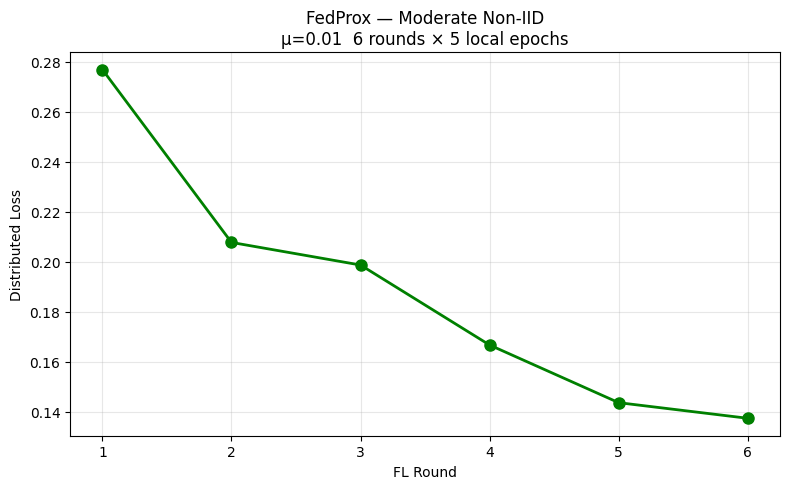


FEDPROX MODERATE COMPLETE
History : C:\Users\Administrator\desktop\unet\experiments\fedprox_moderate\fl_history_fedprox_moderate.json
Plot    : C:\Users\Administrator\desktop\unet\experiments\fedprox_moderate\fl_loss_fedprox_moderate.png
Model   : C:\Users\Administrator\desktop\unet\experiments\fedprox_moderate\global_fedprox_moderate_final.pt

Next: run Cell 8-FEDPROX-MODERATE to evaluate

RESOURCE USAGE REPORT
RAM (GB):
  Mean : 4.16
  Peak : 5.09
  Min  : 0.46
VRAM (GB):
  Mean : 13.53
  Peak : 13.54
  Min  : 0.00
Resource plot saved: C:\Users\Administrator\desktop\unet\experiments\fedprox_moderate\resource_usage.png


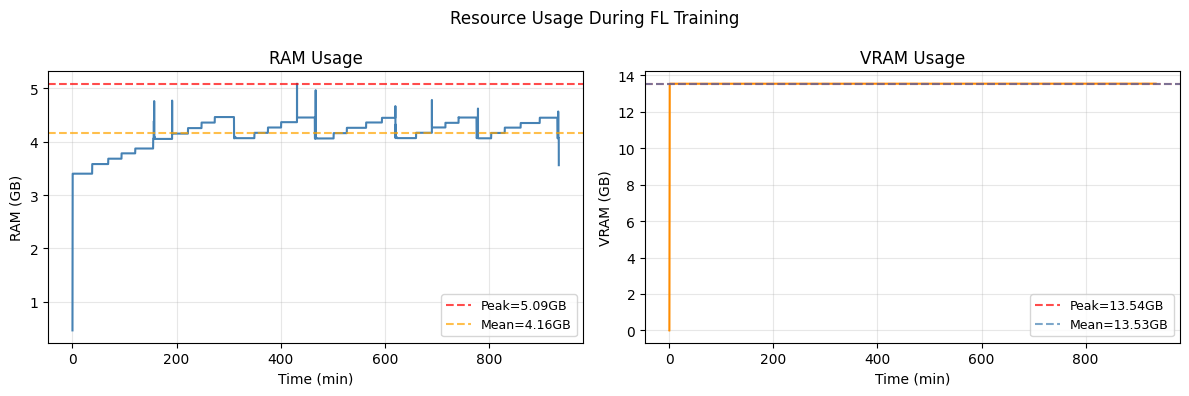

In [1]:
# CELL 7-FEDPROX-MODERATE — FedProx FL (Moderate Non-IID)
# Saves to: experiments/fedprox_moderate/
# Nothing overwrites moderate FedAvg results
# ============================================================
import flwr as fl
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from pathlib import Path
from flwr.server.strategy import FedAvg
from flwr.common import ndarrays_to_parameters, \
                        parameters_to_ndarrays
import numpy as np
import json
import random
import pickle
import shutil
# ── resource monitoring ───────────────────────────────────────
import threading
import time
import psutil
import subprocess

class ResourceMonitor:
    def __init__(self, interval=5):
        self.interval   = interval
        self.ram_usage  = []
        self.vram_usage = []
        self.running    = False
        self._thread    = None

    def _monitor(self):
        while self.running:
            # RAM
            ram = psutil.Process().memory_info().rss / 1e9
            self.ram_usage.append(ram)

            # VRAM
            try:
                result = subprocess.run(
                    ["nvidia-smi",
                     "--query-gpu=memory.used",
                     "--format=csv,noheader,nounits"],
                    capture_output=True, text=True)
                vram = float(result.stdout.strip()) / 1024
                self.vram_usage.append(vram)
            except Exception:
                pass

            time.sleep(self.interval)

    def start(self):
        self.running = True
        self._thread = threading.Thread(
            target=self._monitor, daemon=True)
        self._thread.start()
        print(f"✓ Resource monitor started "
              f"(sampling every {self.interval}s)")

    def stop(self):
        self.running = False
        if self._thread:
            self._thread.join(timeout=10)

    def report(self):
        print(f"\n{'='*50}")
        print(f"RESOURCE USAGE REPORT")
        print(f"{'='*50}")
        if self.ram_usage:
            print(f"RAM (GB):")
            print(f"  Mean : {np.mean(self.ram_usage):.2f}")
            print(f"  Peak : {max(self.ram_usage):.2f}")
            print(f"  Min  : {min(self.ram_usage):.2f}")
        if self.vram_usage:
            print(f"VRAM (GB):")
            print(f"  Mean : {np.mean(self.vram_usage):.2f}")
            print(f"  Peak : {max(self.vram_usage):.2f}")
            print(f"  Min  : {min(self.vram_usage):.2f}")
        if not self.ram_usage and not self.vram_usage:
            print("No samples collected")

    def plot(self, save_path=None):
        if not self.ram_usage and not self.vram_usage:
            return
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        fig.suptitle("Resource Usage During FL Training",
                     fontsize=12)
        if self.ram_usage:
            t = [i * self.interval / 60
                 for i in range(len(self.ram_usage))]
            axes[0].plot(t, self.ram_usage,
                         color='steelblue', linewidth=1.5)
            axes[0].axhline(max(self.ram_usage),
                            color='red', linestyle='--',
                            alpha=0.7,
                            label=f'Peak={max(self.ram_usage):.2f}GB')
            axes[0].axhline(np.mean(self.ram_usage),
                            color='orange', linestyle='--',
                            alpha=0.7,
                            label=f'Mean={np.mean(self.ram_usage):.2f}GB')
            axes[0].set_xlabel('Time (min)')
            axes[0].set_ylabel('RAM (GB)')
            axes[0].set_title('RAM Usage')
            axes[0].legend(fontsize=9)
            axes[0].grid(True, alpha=0.3)
        if self.vram_usage:
            t = [i * self.interval / 60
                 for i in range(len(self.vram_usage))]
            axes[1].plot(t, self.vram_usage,
                         color='darkorange', linewidth=1.5)
            axes[1].axhline(max(self.vram_usage),
                            color='red', linestyle='--',
                            alpha=0.7,
                            label=f'Peak={max(self.vram_usage):.2f}GB')
            axes[1].axhline(np.mean(self.vram_usage),
                            color='steelblue', linestyle='--',
                            alpha=0.7,
                            label=f'Mean={np.mean(self.vram_usage):.2f}GB')
            axes[1].set_xlabel('Time (min)')
            axes[1].set_ylabel('VRAM (GB)')
            axes[1].set_title('VRAM Usage')
            axes[1].legend(fontsize=9)
            axes[1].grid(True, alpha=0.3)
        plt.tight_layout()
        if save_path:
            plt.savefig(save_path, dpi=100,
                        bbox_inches='tight')
            print(f"Resource plot saved: {save_path}")
        plt.show()

monitor = ResourceMonitor(interval=5)
monitor.start()

OUT_ROOT   = Path(r"C:\Users\Administrator\desktop\unet")
EXP_DIR    = OUT_ROOT / "experiments" / "fedprox_moderate"
EXP_DIR.mkdir(parents=True, exist_ok=True)
# ── assert no overwriting ─────────────────────────────────────
files_that_would_be_written = [
    EXP_DIR / f"fl_round{r}_global.pt" for r in range(1,7)
] + [
    EXP_DIR / "global_fedprox_moderate_final.pt",
    EXP_DIR / "fl_history_fedprox_moderate.json",
    EXP_DIR / "fl_loss_fedprox_moderate.png",
    EXP_DIR / "resource_usage.png",
]
for f in files_that_would_be_written:
    assert not f.exists(), \
        f"Would overwrite {f} — delete it first or change EXP_DIR"
print("✓ No existing files would be overwritten")

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Device      : {DEVICE}")
print(f"Experiment  : fedprox_moderate")
print(f"Results dir : {EXP_DIR}")

# ── FL hyperparameters ────────────────────────────────────────
NUM_ROUNDS   = 6
LOCAL_EPOCHS = 5
BATCH_SIZE   = 4
LR           = 1e-4
BASE_FILTERS = 32
PROXIMAL_MU  = 0.01   # FedProx proximal term weight

# ── UNet ─────────────────────────────────────────────────────
class DoubleConv3D(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm3d(out_ch), nn.ReLU(inplace=True),
            nn.Conv3d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm3d(out_ch), nn.ReLU(inplace=True))
    def forward(self, x): return self.block(x)

class Down(nn.Module):
    def __init__(self, c1, c2):
        super().__init__()
        self.pool = nn.MaxPool3d(2)
        self.conv = DoubleConv3D(c1, c2)
    def forward(self, x): return self.conv(self.pool(x))

class Up(nn.Module):
    def __init__(self, c1, c2):
        super().__init__()
        self.up   = nn.ConvTranspose3d(c1, c2, 2, stride=2)
        self.conv = DoubleConv3D(c1, c2)
    def forward(self, x, skip):
        return self.conv(torch.cat([skip, self.up(x)], dim=1))

class UNet3D(nn.Module):
    def __init__(self, base_filters=32):
        super().__init__()
        f = base_filters
        self.enc1=DoubleConv3D(1,f);   self.enc2=Down(f,f*2)
        self.enc3=Down(f*2,f*4);       self.enc4=Down(f*4,f*8)
        self.bottleneck=Down(f*8,f*16)
        self.dec4=Up(f*16,f*8); self.dec3=Up(f*8,f*4)
        self.dec2=Up(f*4,f*2);  self.dec1=Up(f*2,f)
        self.head=nn.Conv3d(f,1,1)
    def forward(self, x):
        e1=self.enc1(x); e2=self.enc2(e1)
        e3=self.enc3(e2); e4=self.enc4(e3)
        b=self.bottleneck(e4)
        return torch.sigmoid(self.head(
            self.dec1(self.dec2(self.dec3(
                self.dec4(b,e4),e3),e2),e1)))

class OHEMLoss(nn.Module):
    def __init__(self, neg_pos_ratio=3, min_negatives=1000):
        super().__init__()
        self.npr=neg_pos_ratio; self.mnn=min_negatives
    def forward(self, pred, target):
        loss=0.0
        for i in range(pred.shape[0]):
            p=pred[i,0]; t=target[i,0]
            pm=t>0.01; nm=~pm
            pl=F.binary_cross_entropy(
                p[pm],t[pm],reduction='mean'
            ) if pm.sum()>0 else torch.tensor(
                0.0,device=pred.device)
            n_neg=min(int(nm.sum()),
                      max(self.mnn,int(pm.sum())*self.npr))
            nl=F.binary_cross_entropy(
                p[nm],
                torch.zeros(nm.sum(),device=pred.device),
                reduction='none'
            ).topk(n_neg).values.mean()
            loss+=pl+nl
        return loss/pred.shape[0]

class PatchDataset(Dataset):
    def __init__(self, pos_files, neg_files, augment=False):
        self.augment=augment
        self.items=([(str(f),1) for f in pos_files]+
                    [(str(f),0) for f in neg_files])
        random.shuffle(self.items)
    def __len__(self): return len(self.items)
    def __getitem__(self, idx):
        path,_=self.items[idx]; d=np.load(path)
        vol=d['vol'].astype(np.float32)
        heat=d['heatmap'].astype(np.float32)
        if self.augment:
            for ax in range(3):
                if random.random()>0.5:
                    vol=np.flip(vol,axis=ax).copy()
                    heat=np.flip(heat,axis=ax).copy()
            k=random.randint(0,3)
            vol=np.rot90(vol,k=k,axes=(1,2)).copy()
            heat=np.rot90(heat,k=k,axes=(1,2)).copy()
        return (torch.from_numpy(vol).unsqueeze(0),
                torch.from_numpy(heat).unsqueeze(0))

# ── load moderate non-IID manifests (same as FedAvg) ─────────
def get_patch_dir(cid):
    if cid == 1:
        return OUT_ROOT / "patches" / "client1"
    return OUT_ROOT / f"client{cid}" / \
           "patches" / f"client{cid}"

print("\nVerifying moderate non-IID manifests...")
for cid in [1,2,3,4,5]:
    mp = get_patch_dir(cid) / "split_manifest.json"
    assert mp.exists(), f"Missing: {mp}"
    with open(mp) as f:
        m = json.load(f)
    print(f"  Client {cid}: {len(m['train_pos'])} train pos  "
          f"{len(m['val_pos'])} val pos  "
          f"{len(m['tst_pids'])} test pts")
print("✓ All manifests present\n")

# ── pre-load all clients ──────────────────────────────────────
print("Loading all client data...")
clients = {}

for cid in [1,2,3,4,5]:
    with open(get_patch_dir(cid) /
              "split_manifest.json") as f:
        manifest = json.load(f)

    train_pos = [Path(p) for p in manifest["train_pos"]]
    train_neg = [Path(p) for p in manifest["train_neg"]]
    val_pos   = [Path(p) for p in manifest["val_pos"]]
    val_neg   = [Path(p) for p in manifest["val_neg"]]

    train_ds = PatchDataset(train_pos, train_neg, augment=True)
    val_ds   = PatchDataset(val_pos,   val_neg,   augment=False)

    train_loader = DataLoader(
        train_ds, batch_size=BATCH_SIZE,
        shuffle=True, num_workers=0, pin_memory=True)
    val_loader   = DataLoader(
        val_ds, batch_size=BATCH_SIZE,
        shuffle=False, num_workers=0, pin_memory=True)

    model     = UNet3D(base_filters=BASE_FILTERS).to(DEVICE)
    criterion = OHEMLoss(neg_pos_ratio=3, min_negatives=1000)

    # ── FedProx client — adds proximal term to loss ───────────
    class FedProxClient(fl.client.NumPyClient):
        def __init__(self, cid, model, train_loader,
                     val_loader, criterion, device, mu):
            self.cid          = cid
            self.model        = model
            self.train_loader = train_loader
            self.val_loader   = val_loader
            self.criterion    = criterion
            self.device       = device
            self.mu           = mu
            self.global_params = None  # set in set_parameters

        def get_parameters(self, config):
            return [v.cpu().numpy()
                    for v in self.model.state_dict().values()]

        def set_parameters(self, parameters):
            state_dict = dict(zip(
                self.model.state_dict().keys(),
                [torch.tensor(p) for p in parameters]
            ))
            self.model.load_state_dict(
                state_dict, strict=True)
            # save global params for proximal term
            self.global_params = [
                p.clone().detach()
                for p in self.model.parameters()
            ]

        def fit(self, parameters, config):
            self.set_parameters(parameters)
            local_epochs = config.get(
                "local_epochs", LOCAL_EPOCHS)
            round_num    = config.get("round_num", 0)
            optimizer    = torch.optim.Adam(
                self.model.parameters(), lr=LR)
            from torch.optim.lr_scheduler import \
                CosineAnnealingLR
            scheduler = CosineAnnealingLR(
                optimizer, T_max=local_epochs)

            self.model.train()
            total_loss = 0.0
            n_batches  = len(self.train_loader)

            for epoch in range(local_epochs):
                ep_loss = 0.0
                for vol, heat in self.train_loader:
                    vol  = vol.to(self.device)
                    heat = heat.to(self.device)
                    optimizer.zero_grad()

                    # task loss
                    task_loss = self.criterion(
                        self.model(vol), heat)

                    # proximal term — penalize drift
                    # from global weights
                    prox_term = 0.0
                    for local_p, global_p in zip(
                        self.model.parameters(),
                        self.global_params
                    ):
                        prox_term += (
                            local_p -
                            global_p.to(self.device)
                        ).norm(2) ** 2
                    prox_term = (self.mu / 2) * prox_term

                    loss = task_loss + prox_term
                    loss.backward()
                    optimizer.step()
                    ep_loss += task_loss.item()

                scheduler.step()
                avg = ep_loss / max(n_batches, 1)
                total_loss += avg
                print(f"    C{self.cid} R{round_num} "
                      f"Ep{epoch+1}/{local_epochs} "
                      f"loss={avg:.4f}", flush=True)

            avg_loss  = total_loss / max(local_epochs, 1)
            n_samples = len(self.train_loader.dataset)
            return (self.get_parameters(config={}),
                    n_samples,
                    {"train_loss": float(avg_loss),
                     "client_id" : self.cid})

        def evaluate(self, parameters, config):
            self.set_parameters(parameters)
            self.model.eval()
            val_loss  = 0.0
            n_samples = len(self.val_loader.dataset)
            with torch.no_grad():
                for vol, heat in self.val_loader:
                    val_loss += self.criterion(
                        self.model(vol.to(self.device)),
                        heat.to(self.device)
                    ).item()
            avg_val = val_loss / max(len(self.val_loader), 1)
            return (float(avg_val), n_samples,
                    {"val_loss"  : float(avg_val),
                     "client_id" : self.cid})

    clients[cid] = FedProxClient(
        cid, model, train_loader,
        val_loader, criterion, DEVICE, PROXIMAL_MU)
    print(f"  Client {cid}: {len(train_ds)} train  "
          f"{len(val_ds)} val")

print(f"✓ All clients loaded (μ={PROXIMAL_MU})\n")

def client_fn(cid):
    return clients[int(cid)+1].to_client()

# ── save round weights ────────────────────────────────────────
round_weights = {}

class SaveRoundStrategy(FedAvg):
    def aggregate_fit(self, server_round, results, failures):
        aggregated = super().aggregate_fit(
            server_round, results, failures)
        if aggregated is not None:
            params, _ = aggregated
            ndarrays  = parameters_to_ndarrays(params)
            model_keys = list(
                UNet3D(base_filters=BASE_FILTERS
                       ).state_dict().keys())
            state_dict = dict(zip(
                model_keys,
                [torch.tensor(p) for p in ndarrays]
            ))
            save_path = EXP_DIR / \
                f"fl_round{server_round}_global.pt"
            torch.save(state_dict, save_path)
            print(f"\n  ✓ Round {server_round} saved: "
                  f"{save_path}")
            round_weights[server_round] = save_path
        return aggregated

# ── init ──────────────────────────────────────────────────────
init_model  = UNet3D(base_filters=BASE_FILTERS)
init_params = ndarrays_to_parameters(
    [v.cpu().numpy()
     for v in init_model.state_dict().values()])

strategy = SaveRoundStrategy(
    fraction_fit=1.0,
    fraction_evaluate=1.0,
    min_fit_clients=5,
    min_evaluate_clients=5,
    min_available_clients=5,
    initial_parameters=init_params,
    on_fit_config_fn=lambda r: {
        "local_epochs": LOCAL_EPOCHS,
        "round_num"   : r,
    },
)

# ── run ───────────────────────────────────────────────────────
print(f"{'='*55}")
print(f"FLOWER FL — FEDPROX MODERATE NON-IID")
print(f"{'='*55}")
print(f"Clients      : 5")
print(f"Rounds       : {NUM_ROUNDS}")
print(f"Local epochs : {LOCAL_EPOCHS}")
print(f"Proximal mu  : {PROXIMAL_MU}")
print(f"Init         : random")
print(f"Strategy     : FedAvg aggregation + FedProx local")
print(f"Results dir  : {EXP_DIR}")
print(f"{'='*55}\n")

history = fl.simulation.start_simulation(
    client_fn=client_fn,
    num_clients=5,
    config=fl.server.ServerConfig(num_rounds=NUM_ROUNDS),
    strategy=strategy,
    client_resources={"num_cpus": 1, "num_gpus": 1.0},
)

# ── save final model ──────────────────────────────────────────
final_path = round_weights.get(NUM_ROUNDS)
if final_path and final_path.exists():
    GLOBAL_PT = EXP_DIR / "global_fedprox_moderate_final.pt"
    shutil.copy(final_path, GLOBAL_PT)
    print(f"\n✓ Final model: {GLOBAL_PT}")

# ── save history ──────────────────────────────────────────────
fl_history = {
    "experiment"        : "fedprox_moderate",
    "proximal_mu"       : PROXIMAL_MU,
    "num_rounds"        : NUM_ROUNDS,
    "local_epochs"      : LOCAL_EPOCHS,
    "losses_distributed": [
        [r, float(l)]
        for r,l in history.losses_distributed],
}
with open(EXP_DIR / "fl_history_fedprox_moderate.json",
          "w") as f:
    json.dump(fl_history, f, indent=2)

# ── plot ──────────────────────────────────────────────────────
import matplotlib.pyplot as plt
if history.losses_distributed:
    rounds = [r for r,l in history.losses_distributed]
    losses = [l for r,l in history.losses_distributed]
    fig, ax = plt.subplots(figsize=(8,5))
    ax.plot(rounds, losses, 'o-',
            color='green', linewidth=2, markersize=8)
    ax.set_xlabel('FL Round')
    ax.set_ylabel('Distributed Loss')
    ax.set_title(f'FedProx — Moderate Non-IID\n'
                 f'μ={PROXIMAL_MU}  '
                 f'{NUM_ROUNDS} rounds × '
                 f'{LOCAL_EPOCHS} local epochs')
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(EXP_DIR/"fl_loss_fedprox_moderate.png",
                dpi=100)
    plt.show()

print(f"\n{'='*55}")
print(f"FEDPROX MODERATE COMPLETE")
print(f"{'='*55}")
print(f"History : {EXP_DIR/'fl_history_fedprox_moderate.json'}")
print(f"Plot    : {EXP_DIR/'fl_loss_fedprox_moderate.png'}")
print(f"Model   : {EXP_DIR/'global_fedprox_moderate_final.pt'}")
print(f"\nNext: run Cell 8-FEDPROX-MODERATE to evaluate")
monitor.stop()
monitor.report()
monitor.plot(save_path=EXP_DIR/"resource_usage.png")

Device: cuda
✓ No existing files would be overwritten
✓ Resource monitor started (sampling every 5s)
Model loaded: C:\Users\Administrator\desktop\unet\experiments\fedprox_moderate\global_fedprox_moderate_final.pt
Test patients: 133


FedProx inference:   1%|▍                                                            | 1/133 [00:44<1:38:15, 44.66s/it]

  LIDC-IDRI-0001: GT= 1 TP= 1 FP=  2 FN= 0


FedProx inference:   2%|▉                                                            | 2/133 [01:25<1:33:12, 42.69s/it]

  LIDC-IDRI-0012: GT= 9 TP= 8 FP=  7 FN= 1


...

  LIDC-IDRI-0978: GT= 2 TP= 2 FP=  2 FN= 0


FedProx inference:  99%|██████████████████████████████████████████████████████████▌| 132/133 [1:21:29<00:29, 29.96s/it]

  LIDC-IDRI-0985: GT= 1 TP= 0 FP=  0 FN= 1


FedProx inference: 100%|███████████████████████████████████████████████████████████| 133/133 [1:22:07<00:00, 37.05s/it]

  LIDC-IDRI-0987: GT= 2 TP= 2 FP=  2 FN= 0

FEDPROX MODERATE RESULTS
GT=175  TP=154  FP=378  FN=21
Sensitivity : 0.880
Precision   : 0.289
FP/scan     : 2.84

CPM (FedProx moderate): 0.703
  0.125 FP/scan → 0.400
  0.250 FP/scan → 0.497
  0.500 FP/scan → 0.651
  1.000 FP/scan → 0.771
  2.000 FP/scan → 0.840
  4.000 FP/scan → 0.880
  8.000 FP/scan → 0.880


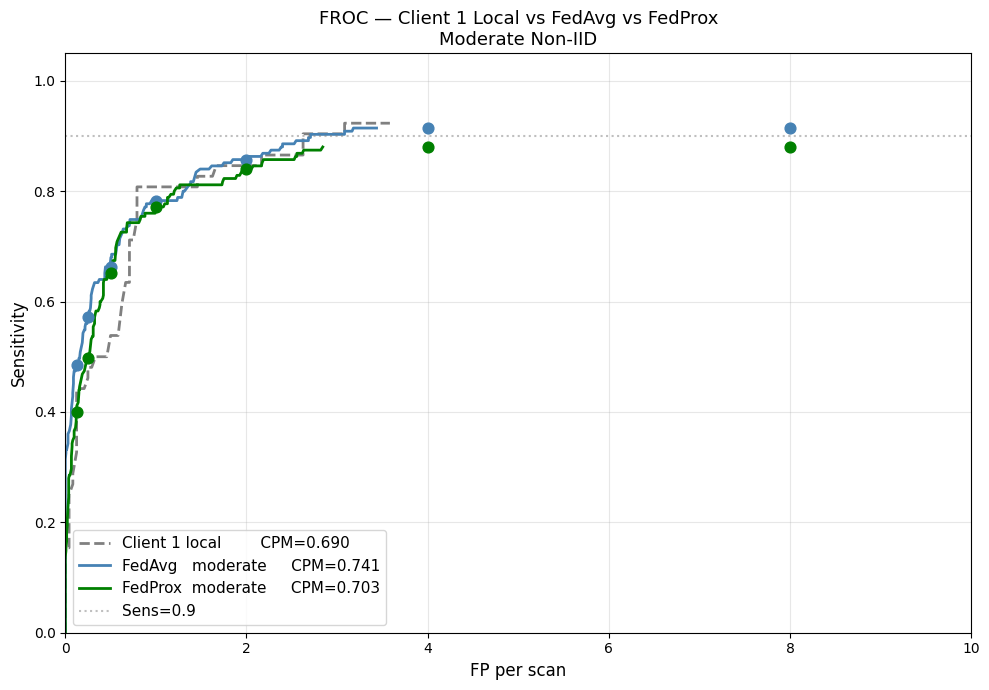


OUTPUT FILES (nothing overwritten)
  experiments/fedprox_moderate/
  ├── fl_round1-6_global.pt
  ├── global_fedprox_moderate_final.pt
  ├── fl_history_fedprox_moderate.json
  ├── fl_loss_fedprox_moderate.png
  ├── fedprox_moderate_results.pkl
  ├── fedprox_moderate_scores.pkl
  ├── fedprox_moderate_test_results.json
  └── froc_fedavg_vs_fedprox_moderate.png

Comparison (moderate non-IID):
  Client 1 local : CPM=0.690
  FedAvg         : CPM=0.741
  FedProx μ=0.01 : CPM=0.703

RESOURCE USAGE REPORT
RAM (GB):
  Mean : 6.91
  Peak : 7.24
  Min  : 3.58
VRAM (GB):
  Mean : 9.90
  Peak : 15.40
  Min  : 3.04
Resource plot saved: C:\Users\Administrator\desktop\unet\experiments\fedprox_moderate\resource_usage_inference.png


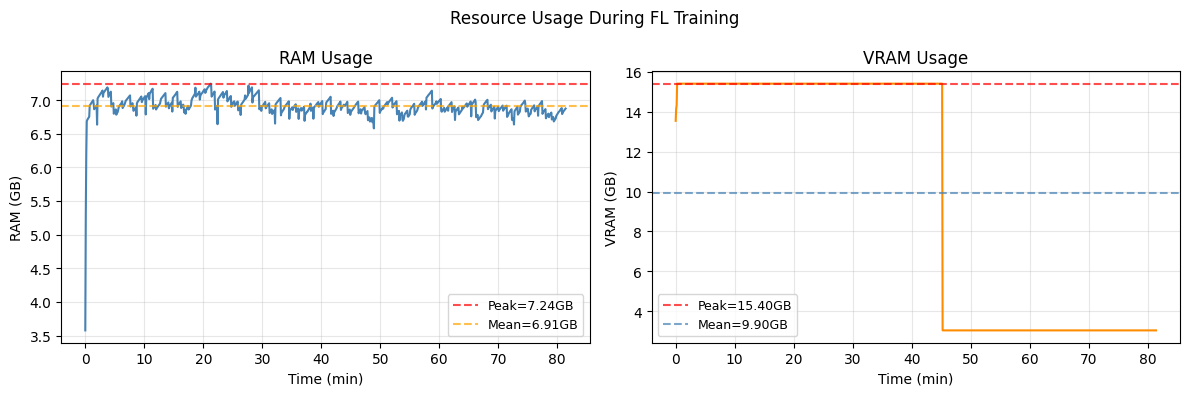

In [2]:
# CELL 8-FEDPROX-MODERATE — Evaluation + comparison with FedAvg
# Evaluates global_fedprox_moderate_final.pt
# on original moderate test pool (133 patients)
# Saves to: experiments/fedprox_moderate/
# Nothing overwritten anywhere
# ============================================================
import torch
import torch.nn as nn
import numpy as np
import json
import pickle
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.ndimage import maximum_filter
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')
# ── resource monitoring ───────────────────────────────────────
import threading
import time
import psutil
import subprocess

class ResourceMonitor:
    def __init__(self, interval=5):
        self.interval   = interval
        self.ram_usage  = []
        self.vram_usage = []
        self.running    = False
        self._thread    = None

    def _monitor(self):
        while self.running:
            # RAM
            ram = psutil.Process().memory_info().rss / 1e9
            self.ram_usage.append(ram)

            # VRAM
            try:
                result = subprocess.run(
                    ["nvidia-smi",
                     "--query-gpu=memory.used",
                     "--format=csv,noheader,nounits"],
                    capture_output=True, text=True)
                vram = float(result.stdout.strip()) / 1024
                self.vram_usage.append(vram)
            except Exception:
                pass

            time.sleep(self.interval)

    def start(self):
        self.running = True
        self._thread = threading.Thread(
            target=self._monitor, daemon=True)
        self._thread.start()
        print(f"✓ Resource monitor started "
              f"(sampling every {self.interval}s)")

    def stop(self):
        self.running = False
        if self._thread:
            self._thread.join(timeout=10)

    def report(self):
        print(f"\n{'='*50}")
        print(f"RESOURCE USAGE REPORT")
        print(f"{'='*50}")
        if self.ram_usage:
            print(f"RAM (GB):")
            print(f"  Mean : {np.mean(self.ram_usage):.2f}")
            print(f"  Peak : {max(self.ram_usage):.2f}")
            print(f"  Min  : {min(self.ram_usage):.2f}")
        if self.vram_usage:
            print(f"VRAM (GB):")
            print(f"  Mean : {np.mean(self.vram_usage):.2f}")
            print(f"  Peak : {max(self.vram_usage):.2f}")
            print(f"  Min  : {min(self.vram_usage):.2f}")
        if not self.ram_usage and not self.vram_usage:
            print("No samples collected")

    def plot(self, save_path=None):
        if not self.ram_usage and not self.vram_usage:
            return
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        fig.suptitle("Resource Usage During FL Training",
                     fontsize=12)
        if self.ram_usage:
            t = [i * self.interval / 60
                 for i in range(len(self.ram_usage))]
            axes[0].plot(t, self.ram_usage,
                         color='steelblue', linewidth=1.5)
            axes[0].axhline(max(self.ram_usage),
                            color='red', linestyle='--',
                            alpha=0.7,
                            label=f'Peak={max(self.ram_usage):.2f}GB')
            axes[0].axhline(np.mean(self.ram_usage),
                            color='orange', linestyle='--',
                            alpha=0.7,
                            label=f'Mean={np.mean(self.ram_usage):.2f}GB')
            axes[0].set_xlabel('Time (min)')
            axes[0].set_ylabel('RAM (GB)')
            axes[0].set_title('RAM Usage')
            axes[0].legend(fontsize=9)
            axes[0].grid(True, alpha=0.3)
        if self.vram_usage:
            t = [i * self.interval / 60
                 for i in range(len(self.vram_usage))]
            axes[1].plot(t, self.vram_usage,
                         color='darkorange', linewidth=1.5)
            axes[1].axhline(max(self.vram_usage),
                            color='red', linestyle='--',
                            alpha=0.7,
                            label=f'Peak={max(self.vram_usage):.2f}GB')
            axes[1].axhline(np.mean(self.vram_usage),
                            color='steelblue', linestyle='--',
                            alpha=0.7,
                            label=f'Mean={np.mean(self.vram_usage):.2f}GB')
            axes[1].set_xlabel('Time (min)')
            axes[1].set_ylabel('VRAM (GB)')
            axes[1].set_title('VRAM Usage')
            axes[1].legend(fontsize=9)
            axes[1].grid(True, alpha=0.3)
        plt.tight_layout()
        if save_path:
            plt.savefig(save_path, dpi=100,
                        bbox_inches='tight')
            print(f"Resource plot saved: {save_path}")
        plt.show()

monitor = ResourceMonitor(interval=5)

OUT_ROOT   = Path(r"C:\Users\Administrator\desktop\unet")
EXP_DIR    = OUT_ROOT / "experiments" / "fedprox_moderate"
GLOBAL_PT  = EXP_DIR  / "global_fedprox_moderate_final.pt"

DEVICE       = 'cuda' if torch.cuda.is_available() else 'cpu'
PATCH_SIZE   = 96
STRIDE       = 20
THRESHOLD    = 0.3
BASE_FILTERS = 32

print(f"Device: {DEVICE}")
# ── assert no overwriting ─────────────────────────────────────
files_that_would_be_written = [
    EXP_DIR / "fedprox_moderate_results.pkl",
    EXP_DIR / "fedprox_moderate_scores.pkl",
    EXP_DIR / "fedprox_moderate_test_results.json",
    EXP_DIR / "froc_fedavg_vs_fedprox_moderate.png",
    EXP_DIR / "resource_usage_inference.png",
]
for f in files_that_would_be_written:
    assert not f.exists(), \
        f"Would overwrite {f} — delete it first"
print("✓ No existing files would be overwritten")
monitor.start()

# ── UNet ─────────────────────────────────────────────────────
class DoubleConv3D(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm3d(out_ch), nn.ReLU(inplace=True),
            nn.Conv3d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm3d(out_ch), nn.ReLU(inplace=True))
    def forward(self, x): return self.block(x)

class Down(nn.Module):
    def __init__(self, c1, c2):
        super().__init__()
        self.pool = nn.MaxPool3d(2)
        self.conv = DoubleConv3D(c1, c2)
    def forward(self, x): return self.conv(self.pool(x))

class Up(nn.Module):
    def __init__(self, c1, c2):
        super().__init__()
        self.up   = nn.ConvTranspose3d(c1, c2, 2, stride=2)
        self.conv = DoubleConv3D(c1, c2)
    def forward(self, x, skip):
        return self.conv(torch.cat([skip, self.up(x)], dim=1))

class UNet3D(nn.Module):
    def __init__(self, base_filters=32):
        super().__init__()
        f = base_filters
        self.enc1=DoubleConv3D(1,f);   self.enc2=Down(f,f*2)
        self.enc3=Down(f*2,f*4);       self.enc4=Down(f*4,f*8)
        self.bottleneck=Down(f*8,f*16)
        self.dec4=Up(f*16,f*8); self.dec3=Up(f*8,f*4)
        self.dec2=Up(f*4,f*2);  self.dec1=Up(f*2,f)
        self.head=nn.Conv3d(f,1,1)
    def forward(self, x):
        e1=self.enc1(x); e2=self.enc2(e1)
        e3=self.enc3(e2); e4=self.enc4(e3)
        b=self.bottleneck(e4)
        return torch.sigmoid(self.head(
            self.dec1(self.dec2(self.dec3(
                self.dec4(b,e4),e3),e2),e1)))

# ── load model ────────────────────────────────────────────────
assert GLOBAL_PT.exists(), f"Model not found: {GLOBAL_PT}"
model = UNet3D(base_filters=BASE_FILTERS).to(DEVICE)
model.load_state_dict(torch.load(
    GLOBAL_PT, map_location=DEVICE))
model.eval()
print(f"Model loaded: {GLOBAL_PT}")

# ── load moderate test pool ───────────────────────────────────
with open(OUT_ROOT / "global_test_pids.json") as f:
    global_test = json.load(f)
all_test_pids = global_test["test_pids"]
print(f"Test patients: {len(all_test_pids)}")

# ── path routing ──────────────────────────────────────────────
with open(OUT_ROOT / "federation_splits.json") as f:
    orig_splits = json.load(f)

def get_patient_dirs(pid):
    if pid in orig_splits["client1_pids"]:
        return (OUT_ROOT / "preprocessed",
                OUT_ROOT / "lung_masks",
                OUT_ROOT / "annotations")
    for cid in [2,3,4,5]:
        if pid in orig_splits.get(
                f"client{cid}_pids", []):
            cd = OUT_ROOT / f"client{cid}"
            return (cd/"preprocessed",
                    cd/"lung_masks",
                    cd/"annotations")
    raise ValueError(f"{pid} not found")

# ── inference functions ───────────────────────────────────────
def sliding_window_max(model, vol, mask,
                        patch_size, stride, device):
    D,H,W   = vol.shape
    p       = patch_size
    heatmap = np.zeros((D,H,W), dtype=np.float32)
    coords  = np.argwhere(mask > 0)
    if len(coords) == 0: return heatmap
    z1=max(0,coords[:,0].min()-p//4)
    y1=max(0,coords[:,1].min()-p//4)
    x1=max(0,coords[:,2].min()-p//4)
    z2=min(D,coords[:,0].max()+p//4)
    y2=min(H,coords[:,1].max()+p//4)
    x2=min(W,coords[:,2].max()+p//4)
    model.eval()
    with torch.no_grad():
        for zw in range(z1,z2-p+1,stride):
            for yw in range(y1,y2-p+1,stride):
                for xw in range(x1,x2-p+1,stride):
                    patch=vol[zw:zw+p,yw:yw+p,xw:xw+p]
                    if patch.shape!=(p,p,p): continue
                    if mask[zw:zw+p,yw:yw+p,
                            xw:xw+p].mean()<0.05: continue
                    t=torch.from_numpy(patch).unsqueeze(0)\
                          .unsqueeze(0).float().to(device)
                    pred=model(t).squeeze().cpu().numpy()
                    heatmap[zw:zw+p,yw:yw+p,xw:xw+p]=\
                        np.maximum(
                            heatmap[zw:zw+p,yw:yw+p,xw:xw+p],
                            pred)
    return heatmap

def get_detections(heatmap, threshold=0.3, min_dist=6):
    lm=maximum_filter(
        heatmap,footprint=np.ones((min_dist,)*3))==heatmap
    lm=lm&(heatmap>threshold)
    c=np.argwhere(lm)
    if len(c)==0: return []
    s=heatmap[lm]; o=np.argsort(s)[::-1]
    return [(int(c[i,0]),int(c[i,1]),
             int(c[i,2]),float(s[i])) for i in o]

def match_gt(detections, gt_nodules):
    matched=set(); tp,fp=[],[]
    for det in detections:
        dz,dy,dx,sc=det; bd,bi=float('inf'),-1
        for gi,nod in enumerate(gt_nodules):
            if gi in matched: continue
            gz,gy,gx=nod['center_res']
            d=np.sqrt((dz-gz)**2+(dy-gy)**2+(dx-gx)**2)
            if d<max(nod['radius_mm'],10.0) and d<bd:
                bd,bi=d,gi
        if bi>=0:
            tp.append({'det':det,
                       'gt':gt_nodules[bi],
                       'dist_mm':bd})
            matched.add(bi)
        else:
            fp.append({'det':det})
    fn=[{'gt':n} for gi,n in enumerate(gt_nodules)
        if gi not in matched]
    return tp,fp,fn

# ── run inference ─────────────────────────────────────────────
all_results=[]; all_scores=[]; total_gt=0; missing=[]

for pid in tqdm(all_test_pids, desc="FedProx inference"):
    try:
        pd_dir,md_dir,ad_dir = get_patient_dirs(pid)
    except ValueError as e:
        missing.append(pid); continue
    vp=pd_dir/f"{pid}.npy"
    mp=md_dir/f"{pid}.npy"
    ap=ad_dir/f"{pid}.json"
    if not (vp.exists() and mp.exists() and ap.exists()):
        missing.append(pid); continue
    vol  = np.load(vp)
    mask = np.load(mp)
    with open(ap) as f:
        gt_nods=json.load(f)["consensus_nodules"]
    total_gt += len(gt_nods)
    heatmap    = sliding_window_max(
        model,vol,mask,PATCH_SIZE,STRIDE,DEVICE)
    detections = get_detections(heatmap,THRESHOLD)
    tp,fp,fn   = match_gt(detections,gt_nods)
    all_results.append({
        "pid":pid,"gt_nodules":len(gt_nods),
        "detections":len(detections),
        "tp":len(tp),"fp":len(fp),"fn":len(fn),
        "tp_list":tp,"fp_list":fp,"fn_list":fn,
    })
    for i in tp: all_scores.append((i["det"][3],1))
    for i in fp: all_scores.append((i["det"][3],0))
    print(f"  {pid}: GT={len(gt_nods):2d} "
          f"TP={len(tp):2d} FP={len(fp):3d} "
          f"FN={len(fn):2d}")

# save immediately
with open(EXP_DIR/"fedprox_moderate_results.pkl","wb") as f:
    pickle.dump(all_results,f)
with open(EXP_DIR/"fedprox_moderate_scores.pkl","wb") as f:
    pickle.dump(all_scores,f)

# metrics
ttp=sum(r["tp"] for r in all_results)
tfp=sum(r["fp"] for r in all_results)
tfn=sum(r["fn"] for r in all_results)
ns =len(all_results)
sen=ttp/max(ttp+tfn,1)
pre=ttp/max(ttp+tfp,1)
f1 =2*pre*sen/max(pre+sen,1e-6)
fps=tfp/max(ns,1)

print(f"\n{'='*55}")
print(f"FEDPROX MODERATE RESULTS")
print(f"{'='*55}")
print(f"GT={total_gt}  TP={ttp}  FP={tfp}  FN={tfn}")
print(f"Sensitivity : {sen:.3f}")
print(f"Precision   : {pre:.3f}")
print(f"FP/scan     : {fps:.2f}")

# FROC + CPM
cpm_fp = 0.0
if all_scores:
    all_scores.sort(key=lambda x:x[0],reverse=True)
    sa=np.array([s[0] for s in all_scores])
    la=np.array([s[1] for s in all_scores])
    sl,fl=[],[]
    for th in np.linspace(0.95,0.01,500):
        k=sa>=th
        sl.append(float(la[k].sum()/max(total_gt,1)))
        fl.append(float((1-la[k]).sum()/max(ns,1)))
    fp_pts=[0.125,0.25,0.5,1,2,4,8]
    cpm_s=[sl[np.argmin([abs(f-fp) for f in fl])]
           for fp in fp_pts]
    cpm_fp=float(np.mean(cpm_s))

    print(f"\nCPM (FedProx moderate): {cpm_fp:.3f}")
    for fp_pt,s in zip(fp_pts,cpm_s):
        print(f"  {fp_pt:5.3f} FP/scan → {s:.3f}")

    # ── comparison: FedAvg vs FedProx (moderate) ─────────────
    with open(OUT_ROOT/"logs_global"/
              "global_all_scores.pkl","rb") as f:
        fedavg_scores = pickle.load(f)
    fedavg_scores.sort(key=lambda x:x[0],reverse=True)
    sa_fa=np.array([s[0] for s in fedavg_scores])
    la_fa=np.array([s[1] for s in fedavg_scores])
    total_gt_fa=175
    sl_fa,fl_fa=[],[]
    for th in np.linspace(0.95,0.01,500):
        k=sa_fa>=th
        sl_fa.append(
            float(la_fa[k].sum()/max(total_gt_fa,1)))
        fl_fa.append(
            float((1-la_fa[k]).sum()/133))
    cpm_fa_s=[sl_fa[np.argmin([abs(f-fp) for f in fl_fa])]
              for fp in fp_pts]
    cpm_fa=float(np.mean(cpm_fa_s))

    # client 1 local
    with open(OUT_ROOT/"logs"/"all_scores.pkl","rb") as f:
        c1_scores = pickle.load(f)
    c1_scores.sort(key=lambda x:x[0],reverse=True)
    sa_c1=np.array([s[0] for s in c1_scores])
    la_c1=np.array([s[1] for s in c1_scores])
    sl_c1,fl_c1=[],[]
    for th in np.linspace(0.95,0.01,500):
        k=sa_c1>=th
        sl_c1.append(float(la_c1[k].sum()/52))
        fl_c1.append(float((1-la_c1[k]).sum()/24))
    cpm_c1_s=[sl_c1[np.argmin([abs(f-fp) for f in fl_c1])]
              for fp in fp_pts]
    cpm_c1=float(np.mean(cpm_c1_s))

    fig,ax=plt.subplots(figsize=(10,7))
    ax.plot(fl_c1, sl_c1,
            color='gray',   linewidth=2, linestyle='--',
            label=f'Client 1 local        CPM={cpm_c1:.3f}')
    ax.plot(fl_fa, sl_fa,
            color='steelblue', linewidth=2,
            label=f'FedAvg   moderate     CPM={cpm_fa:.3f}')
    ax.plot(fl,    sl,
            color='green',  linewidth=2,
            label=f'FedProx  moderate     CPM={cpm_fp:.3f}')
    ax.scatter(fp_pts, cpm_fa_s,
               color='steelblue', zorder=5, s=60)
    ax.scatter(fp_pts, cpm_s,
               color='green',     zorder=5, s=60)
    ax.axhline(0.9,color='gray',linestyle=':',
               alpha=0.5,label='Sens=0.9')
    ax.set_xlabel('FP per scan',fontsize=12)
    ax.set_ylabel('Sensitivity',fontsize=12)
    ax.set_title(
        'FROC — Client 1 Local vs FedAvg vs FedProx\n'
        'Moderate Non-IID', fontsize=13)
    ax.set_xlim(0,10); ax.set_ylim(0,1.05)
    ax.legend(fontsize=11); ax.grid(True,alpha=0.3)
    plt.tight_layout()
    plt.savefig(EXP_DIR/"froc_fedavg_vs_fedprox_moderate.png",
                dpi=100, bbox_inches='tight')
    plt.show()

# save results
with open(EXP_DIR/"fedprox_moderate_test_results.json",
          "w") as f:
    json.dump({
        "experiment"  : "fedprox_moderate",
        "proximal_mu" : 0.01,
        "n_patients"  : ns,
        "total_gt"    : total_gt,
        "total_tp"    : ttp,
        "total_fp"    : tfp,
        "total_fn"    : tfn,
        "sensitivity" : round(sen,4),
        "precision"   : round(pre,4),
        "f1"          : round(f1,4),
        "fp_per_scan" : round(fps,4),
        "cpm"         : round(cpm_fp,4),
    },f,indent=2)

print(f"\n{'='*55}")
print(f"OUTPUT FILES (nothing overwritten)")
print(f"{'='*55}")
print(f"  experiments/fedprox_moderate/")
print(f"  ├── fl_round1-6_global.pt")
print(f"  ├── global_fedprox_moderate_final.pt")
print(f"  ├── fl_history_fedprox_moderate.json")
print(f"  ├── fl_loss_fedprox_moderate.png")
print(f"  ├── fedprox_moderate_results.pkl")
print(f"  ├── fedprox_moderate_scores.pkl")
print(f"  ├── fedprox_moderate_test_results.json")
print(f"  └── froc_fedavg_vs_fedprox_moderate.png")
print(f"\nComparison (moderate non-IID):")
print(f"  Client 1 local : CPM={cpm_c1:.3f}")
print(f"  FedAvg         : CPM={cpm_fa:.3f}")
print(f"  FedProx μ=0.01 : CPM={cpm_fp:.3f}")

monitor.stop()
monitor.report()
monitor.plot(save_path=EXP_DIR/"resource_usage_inference.png")

✓ No existing files would be overwritten
Loaded 133 patient results
PID→client map: 133 entries

PER-CLIENT RESULTS — FedProx Moderate Non-IID (μ=0.01)
Client          N    GT    TP    FP    FN   Sens   Prec  FP/scan
────────────────────────────────────────────────────────────────────────
client1        24    52    49    93     3  0.942  0.345     3.88
client2        27    21    19    81     2  0.905  0.190     3.00
client3        30    47    37    90    10  0.787  0.291     3.00
client4        25    25    23    54     2  0.920  0.299     2.16
client5        27    30    26    60     4  0.867  0.302     2.22
────────────────────────────────────────────────────────────────────────
GLOBAL        133   175   154   378    21  0.880  0.289     2.84


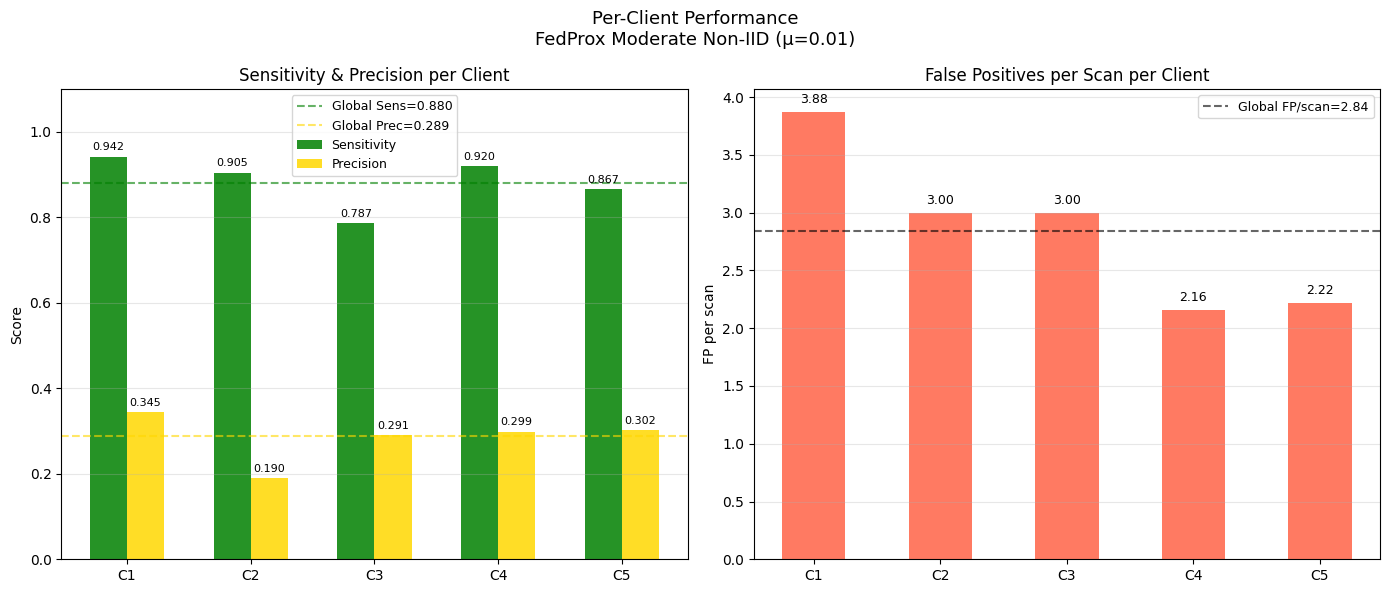


Plot saved : C:\Users\Administrator\desktop\unet\experiments\fedprox_moderate\per_client_metrics_fedprox_moderate.png
JSON saved : C:\Users\Administrator\desktop\unet\experiments\fedprox_moderate\per_client_metrics_fedprox_moderate.json


In [2]:
# PER-CLIENT EVALUATION — FEDPROX MODERATE
# Uses already-computed inference PKL
# Groups test patients by MODERATE non-IID client assignment
# No re-inference, no GPU needed
# Saves to: experiments/fedprox_moderate/
# ============================================================
import pickle
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from collections import defaultdict

OUT_ROOT = Path(r"C:\Users\Administrator\desktop\unet")
EXP_DIR  = OUT_ROOT / "experiments" / "fedprox_moderate"

# ── assert no overwriting ─────────────────────────────────────
out_png  = EXP_DIR / "per_client_metrics_fedprox_moderate.png"
out_json = EXP_DIR / "per_client_metrics_fedprox_moderate.json"
assert not out_png.exists(),  f"Would overwrite {out_png}"
assert not out_json.exists(), f"Would overwrite {out_json}"
print("✓ No existing files would be overwritten")

# ── load inference results ────────────────────────────────────
PKL_PATH = EXP_DIR / "fedprox_moderate_results.pkl"
assert PKL_PATH.exists(), f"Missing: {PKL_PATH}"
with open(PKL_PATH, "rb") as f:
    all_results = pickle.load(f)
print(f"Loaded {len(all_results)} patient results")

# ── load moderate test pool with by_client mapping ────────────
test_pool_path = OUT_ROOT / "global_test_pids.json"
assert test_pool_path.exists(), f"Missing: {test_pool_path}"
with open(test_pool_path) as f:
    global_test = json.load(f)

# build pid → client mapping
pid_to_client = {}
if "by_client" in global_test:
    for cid, pids in global_test["by_client"].items():
        for pid in pids:
            pid_to_client[pid] = cid
else:
    print("by_client not in global_test_pids.json "
          "— using federation_splits.json")
    with open(OUT_ROOT / "federation_splits.json") as f:
        fed_splits = json.load(f)
    test_pids = set(global_test["test_pids"])
    for cid in [1,2,3,4,5]:
        for pid in fed_splits[f"client{cid}_pids"]:
            if pid in test_pids:
                pid_to_client[pid] = f"client{cid}"

print(f"PID→client map: {len(pid_to_client)} entries")

# ── group results by client ───────────────────────────────────
client_results = defaultdict(list)
unmapped = []
for r in all_results:
    pid = r["pid"]
    cid = pid_to_client.get(pid)
    if cid is None:
        unmapped.append(pid)
        continue
    client_results[cid].append(r)

if unmapped:
    print(f"WARNING: {len(unmapped)} pids not mapped")

EXP_NAME = "FedProx Moderate Non-IID (μ=0.01)"

# ── compute per-client metrics ────────────────────────────────
print(f"\n{'='*72}")
print(f"PER-CLIENT RESULTS — {EXP_NAME}")
print(f"{'='*72}")
print(f"{'Client':<12} {'N':>4} {'GT':>5} {'TP':>5} "
      f"{'FP':>5} {'FN':>5} {'Sens':>6} {'Prec':>6} "
      f"{'FP/scan':>8}")
print(f"{'─'*72}")

summary = {}
for cid in sorted(client_results.keys()):
    results  = client_results[cid]
    ttp = sum(r["tp"] for r in results)
    tfp = sum(r["fp"] for r in results)
    tfn = sum(r["fn"] for r in results)
    tgt = sum(r["gt_nodules"] for r in results)
    ns  = len(results)
    sen = ttp / max(ttp+tfn, 1)
    pre = ttp / max(ttp+tfp, 1)
    f1  = 2*pre*sen / max(pre+sen, 1e-6)
    fps = tfp / max(ns, 1)
    print(f"{cid:<12} {ns:>4} {tgt:>5} {ttp:>5} "
          f"{tfp:>5} {tfn:>5} {sen:>6.3f} {pre:>6.3f} "
          f"{fps:>8.2f}")
    summary[cid] = {
        "n_patients" : ns,
        "total_gt"   : tgt,
        "total_tp"   : ttp,
        "total_fp"   : tfp,
        "total_fn"   : tfn,
        "sensitivity": round(sen, 4),
        "precision"  : round(pre, 4),
        "f1"         : round(f1,  4),
        "fp_per_scan": round(fps, 4),
    }

# global
all_ttp = sum(r["tp"] for r in all_results)
all_tfp = sum(r["fp"] for r in all_results)
all_tfn = sum(r["fn"] for r in all_results)
all_gt  = sum(r["gt_nodules"] for r in all_results)
all_ns  = len(all_results)
all_sen = all_ttp / max(all_ttp+all_tfn, 1)
all_pre = all_ttp / max(all_ttp+all_tfp, 1)
all_fps = all_tfp / max(all_ns, 1)
print(f"{'─'*72}")
print(f"{'GLOBAL':<12} {all_ns:>4} {all_gt:>5} {all_ttp:>5} "
      f"{all_tfp:>5} {all_tfn:>5} {all_sen:>6.3f} "
      f"{all_pre:>6.3f} {all_fps:>8.2f}")

# ── bar chart ─────────────────────────────────────────────────
clients = sorted(summary.keys())
sens    = [summary[c]["sensitivity"] for c in clients]
precs   = [summary[c]["precision"]   for c in clients]
fps_    = [summary[c]["fp_per_scan"] for c in clients]
labels  = [c.replace("client","C") for c in clients]

x = np.arange(len(clients))
w = 0.30

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle(f"Per-Client Performance\n{EXP_NAME}",
             fontsize=13)

ax = axes[0]
b1 = ax.bar(x-w/2, sens,  w, label='Sensitivity',
            color='green', alpha=0.85)
b2 = ax.bar(x+w/2, precs, w, label='Precision',
            color='gold', alpha=0.85)
ax.axhline(all_sen, color='green', linestyle='--',
           alpha=0.6,
           label=f'Global Sens={all_sen:.3f}')
ax.axhline(all_pre, color='gold', linestyle='--',
           alpha=0.6,
           label=f'Global Prec={all_pre:.3f}')
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_ylim(0, 1.1); ax.set_ylabel('Score')
ax.set_title('Sensitivity & Precision per Client')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3, axis='y')
for b in b1:
    ax.text(b.get_x()+b.get_width()/2,
            b.get_height()+0.01,
            f'{b.get_height():.3f}',
            ha='center', va='bottom', fontsize=8)
for b in b2:
    ax.text(b.get_x()+b.get_width()/2,
            b.get_height()+0.01,
            f'{b.get_height():.3f}',
            ha='center', va='bottom', fontsize=8)

ax = axes[1]
bars = ax.bar(x, fps_, 0.5, color='tomato', alpha=0.85)
ax.axhline(all_fps, color='black', linestyle='--',
           alpha=0.6,
           label=f'Global FP/scan={all_fps:.2f}')
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_ylabel('FP per scan')
ax.set_title('False Positives per Scan per Client')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3, axis='y')
for b in bars:
    ax.text(b.get_x()+b.get_width()/2,
            b.get_height()+0.05,
            f'{b.get_height():.2f}',
            ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig(out_png, dpi=100, bbox_inches='tight')
plt.show()
print(f"\nPlot saved : {out_png}")

# ── save json ─────────────────────────────────────────────────
with open(out_json, "w") as f:
    json.dump({
        "experiment": EXP_NAME,
        "proximal_mu": 0.01,
        "per_client": summary,
        "global": {
            "n_patients" : all_ns,
            "total_gt"   : all_gt,
            "total_tp"   : all_ttp,
            "total_fp"   : all_tfp,
            "total_fn"   : all_tfn,
            "sensitivity": round(all_sen, 4),
            "precision"  : round(all_pre, 4),
            "fp_per_scan": round(all_fps, 4),
        }
    }, f, indent=2)
print(f"JSON saved : {out_json}")

All files loaded ✓

COMPARISON TABLE — MODERATE NON-IID
Method                            GT    TP    FP   Sens  FP/scan     CPM
─────────────────────────────────────────────────────────────────
Client 1 local                    52    48    86  0.923     3.58   0.690
FedAvg moderate                  175   160   457  0.914     3.44   0.741
FedProx moderate (μ=0.01)        175   154   378  0.880     2.84   0.703

CPM improvements over Client 1 local:
  FedAvg   : 0.741 (+5.2%)
  FedProx  : 0.703 (+1.3%)

FedProx vs FedAvg:
  CPM diff : -3.8%  (FedAvg better)


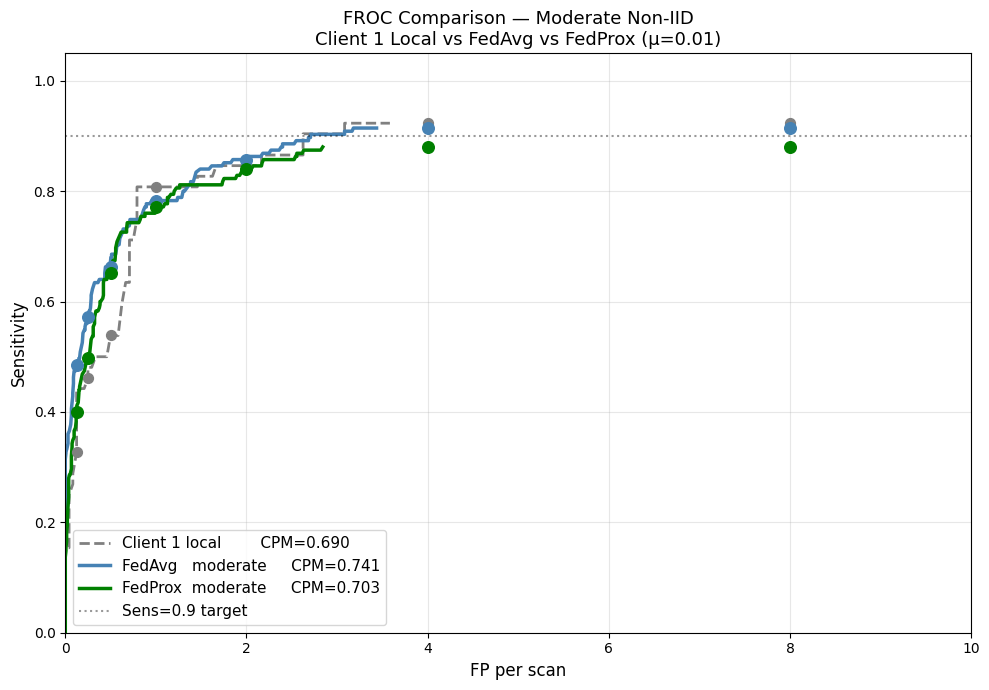

Plot saved: C:\Users\Administrator\desktop\unet\experiments\fedprox_moderate\froc_full_comparison.png
Table saved: C:\Users\Administrator\desktop\unet\experiments\fedprox_moderate\comparison_table.json

OUTPUT FILES
  experiments/fedprox_moderate/
  ├── comparison_table.json   ← new
  └── froc_full_comparison.png ← new

Nothing else touched.


In [3]:
# COMPARISON CELL — FedAvg vs FedProx (Moderate Non-IID)
# READS ONLY — loads from existing saved pkl and json files
# WRITES:
#   experiments/fedprox_moderate/comparison_table.json  ← new
#   experiments/fedprox_moderate/froc_full_comparison.png ← new
# TOUCHES NOTHING ELSE
# ============================================================
import numpy as np
import pickle
import json
import matplotlib.pyplot as plt
from pathlib import Path

OUT_ROOT = Path(r"C:\Users\Administrator\desktop\unet")
EXP_DIR  = OUT_ROOT / "experiments" / "fedprox_moderate"

# ── verify output files don't exist yet ──────────────────────
out_json = EXP_DIR / "comparison_table.json"
out_png  = EXP_DIR / "froc_full_comparison.png"
assert not out_json.exists(), \
    f"Would overwrite {out_json} — delete it first"
assert not out_png.exists(), \
    f"Would overwrite {out_png} — delete it first"

# ── load all scores ───────────────────────────────────────────
# client 1 local
with open(OUT_ROOT/"logs"/"all_scores.pkl","rb") as f:
    c1_scores = pickle.load(f)

# fedavg moderate
with open(OUT_ROOT/"logs_global"/
          "global_all_scores.pkl","rb") as f:
    fedavg_scores = pickle.load(f)

# fedprox moderate
with open(EXP_DIR/"fedprox_moderate_scores.pkl","rb") as f:
    fedprox_scores = pickle.load(f)

# ── load result jsons for GT counts ──────────────────────────
with open(OUT_ROOT/"logs"/
          "client1_test_results_v3.json") as f:
    c1_res = json.load(f)

with open(OUT_ROOT/"logs_global"/
          "global_test_results.json") as f:
    fedavg_res = json.load(f)

with open(EXP_DIR/
          "fedprox_moderate_test_results.json") as f:
    fedprox_res = json.load(f)

print("All files loaded ✓")

# ── FROC computation ──────────────────────────────────────────
fp_pts = [0.125, 0.25, 0.5, 1, 2, 4, 8]

def compute_froc(scores, total_gt, n_scans):
    scores = sorted(scores, key=lambda x:x[0], reverse=True)
    sa = np.array([s[0] for s in scores])
    la = np.array([s[1] for s in scores])
    sl, fl = [], []
    for th in np.linspace(0.95, 0.01, 500):
        k = sa >= th
        sl.append(float(la[k].sum() / max(total_gt, 1)))
        fl.append(float((1-la[k]).sum() / max(n_scans, 1)))
    cpm_s = [sl[np.argmin([abs(f-fp) for f in fl])]
             for fp in fp_pts]
    cpm   = float(np.mean(cpm_s))
    return sl, fl, cpm_s, cpm

sl_c1, fl_c1, cpm_s_c1, cpm_c1 = compute_froc(
    c1_scores,
    c1_res["total_gt"],
    c1_res["n_patients"])

sl_fa, fl_fa, cpm_s_fa, cpm_fa = compute_froc(
    fedavg_scores,
    fedavg_res["total_gt"],
    fedavg_res["n_patients"])

sl_fp, fl_fp, cpm_s_fp, cpm_fp = compute_froc(
    fedprox_scores,
    fedprox_res["total_gt"],
    fedprox_res["n_patients"])

# ── print comparison table ────────────────────────────────────
print(f"\n{'='*65}")
print(f"COMPARISON TABLE — MODERATE NON-IID")
print(f"{'='*65}")
print(f"{'Method':<30} {'GT':>5} {'TP':>5} {'FP':>5} "
      f"{'Sens':>6} {'FP/scan':>8} {'CPM':>7}")
print(f"{'─'*65}")
print(f"{'Client 1 local':<30} "
      f"{c1_res['total_gt']:>5} "
      f"{c1_res['total_tp']:>5} "
      f"{c1_res['total_fp']:>5} "
      f"{c1_res['sensitivity']:>6.3f} "
      f"{c1_res['fp_per_scan']:>8.2f} "
      f"{cpm_c1:>7.3f}")
print(f"{'FedAvg moderate':<30} "
      f"{fedavg_res['total_gt']:>5} "
      f"{fedavg_res['total_tp']:>5} "
      f"{fedavg_res['total_fp']:>5} "
      f"{fedavg_res['sensitivity']:>6.3f} "
      f"{fedavg_res['fp_per_scan']:>8.2f} "
      f"{cpm_fa:>7.3f}")
print(f"{'FedProx moderate (μ=0.01)':<30} "
      f"{fedprox_res['total_gt']:>5} "
      f"{fedprox_res['total_tp']:>5} "
      f"{fedprox_res['total_fp']:>5} "
      f"{fedprox_res['sensitivity']:>6.3f} "
      f"{fedprox_res['fp_per_scan']:>8.2f} "
      f"{cpm_fp:>7.3f}")
print(f"{'='*65}")

# CPM improvement
print(f"\nCPM improvements over Client 1 local:")
print(f"  FedAvg   : {cpm_fa:.3f} "
      f"({'+'if cpm_fa>cpm_c1 else ''}"
      f"{(cpm_fa-cpm_c1)*100:.1f}%)")
print(f"  FedProx  : {cpm_fp:.3f} "
      f"({'+'if cpm_fp>cpm_c1 else ''}"
      f"{(cpm_fp-cpm_c1)*100:.1f}%)")
print(f"\nFedProx vs FedAvg:")
print(f"  CPM diff : {(cpm_fp-cpm_fa)*100:+.1f}%  "
      f"({'FedProx better' if cpm_fp>cpm_fa else 'FedAvg better'})")

# ── FROC plot ─────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 7))

ax.plot(fl_c1, sl_c1,
        color='gray', linewidth=2, linestyle='--',
        label=f'Client 1 local        CPM={cpm_c1:.3f}')
ax.plot(fl_fa, sl_fa,
        color='steelblue', linewidth=2.5,
        label=f'FedAvg   moderate     CPM={cpm_fa:.3f}')
ax.plot(fl_fp, sl_fp,
        color='green', linewidth=2.5,
        label=f'FedProx  moderate     CPM={cpm_fp:.3f}')

ax.scatter(fp_pts, cpm_s_c1,
           color='gray',      zorder=5, s=50)
ax.scatter(fp_pts, cpm_s_fa,
           color='steelblue', zorder=5, s=70)
ax.scatter(fp_pts, cpm_s_fp,
           color='green',     zorder=5, s=70)

ax.axhline(0.9, color='black', linestyle=':',
           alpha=0.4, label='Sens=0.9 target')
ax.set_xlabel('FP per scan', fontsize=12)
ax.set_ylabel('Sensitivity', fontsize=12)
ax.set_title(
    'FROC Comparison — Moderate Non-IID\n'
    'Client 1 Local vs FedAvg vs FedProx (μ=0.01)',
    fontsize=13)
ax.set_xlim(0, 10)
ax.set_ylim(0, 1.05)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(out_png, dpi=100, bbox_inches='tight')
plt.show()
print(f"Plot saved: {out_png}")

# ── save comparison table ─────────────────────────────────────
comparison = {
    "experiment"       : "moderate_noniid_comparison",
    "client1_local"    : {
        "cpm"        : round(cpm_c1, 4),
        "sensitivity": c1_res["sensitivity"],
        "fp_per_scan": c1_res["fp_per_scan"],
        "total_gt"   : c1_res["total_gt"],
        "n_patients" : c1_res["n_patients"],
    },
    "fedavg_moderate"  : {
        "cpm"        : round(cpm_fa, 4),
        "sensitivity": fedavg_res["sensitivity"],
        "fp_per_scan": fedavg_res["fp_per_scan"],
        "total_gt"   : fedavg_res["total_gt"],
        "n_patients" : fedavg_res["n_patients"],
    },
    "fedprox_moderate" : {
        "proximal_mu": 0.01,
        "cpm"        : round(cpm_fp, 4),
        "sensitivity": fedprox_res["sensitivity"],
        "fp_per_scan": fedprox_res["fp_per_scan"],
        "total_gt"   : fedprox_res["total_gt"],
        "n_patients" : fedprox_res["n_patients"],
    },
    "cpm_improvement_fedavg_vs_c1"  :
        round(cpm_fa - cpm_c1, 4),
    "cpm_improvement_fedprox_vs_c1" :
        round(cpm_fp - cpm_c1, 4),
    "cpm_improvement_fedprox_vs_fedavg":
        round(cpm_fp - cpm_fa, 4),
}
with open(out_json, "w") as f:
    json.dump(comparison, f, indent=2)
print(f"Table saved: {out_json}")

print(f"\n{'='*65}")
print(f"OUTPUT FILES")
print(f"{'='*65}")
print(f"  experiments/fedprox_moderate/")
print(f"  ├── comparison_table.json   ← new")
print(f"  └── froc_full_comparison.png ← new")
print(f"\nNothing else touched.")

severe csv

In [13]:
# SEVERE NON-IID SPLIT GENERATION v6
# 3 dimensions: slice thickness × nodule size × clean percentage
# Clinically motivated — realistic hospital profiles
# No zero clean% anywhere
# Nothing overwritten — new files only
# Saves to: OUT_ROOT/experiments/severe_noniid/
# ============================================================
import json
import numpy as np
import pandas as pd
from pathlib import Path
import pylidc as pl
import warnings
warnings.filterwarnings('ignore')

if not hasattr(np, 'int'):
    np.int = int

OUT_ROOT = Path(r"C:\Users\Administrator\desktop\unet")
EXP_DIR  = OUT_ROOT / "experiments" / "severe_noniid"
EXP_DIR.mkdir(parents=True, exist_ok=True)
print(f"Experiment dir: {EXP_DIR}")

# ── load all patient info ─────────────────────────────────────
with open(OUT_ROOT / "federation_splits.json") as f:
    fed_splits = json.load(f)

all_pids = []
for cid in [1,2,3,4,5]:
    all_pids.extend(fed_splits[f"client{cid}_pids"])
print(f"Total patients: {len(all_pids)}")

# load pylidc
all_scans = pl.query(pl.Scan).order_by(pl.Scan.patient_id).all()
seen = {}
for s in all_scans:
    if s.patient_id not in seen:
        seen[s.patient_id] = s

# ── collect per-patient features ──────────────────────────────
records = []
for pid in all_pids:
    scan = seen.get(pid)
    if scan is None:
        continue
    orig_client = None
    for cid in [1,2,3,4,5]:
        if pid in fed_splits[f"client{cid}_pids"]:
            orig_client = cid
            break
    if orig_client == 1:
        annot_dir = OUT_ROOT / "annotations"
    else:
        annot_dir = OUT_ROOT / \
                    f"client{orig_client}" / "annotations"
    ap = annot_dir / f"{pid}.json"
    if not ap.exists():
        continue
    with open(ap) as f:
        record = json.load(f)
    n_nodules    = record["n_consensus_nodules"]
    nodule_sizes = [n["radius_mm"]*2
                    for n in record["consensus_nodules"]]
    mean_size    = float(np.mean(nodule_sizes)) \
                   if nodule_sizes else 0.0
    records.append({
        "patient_id"  : pid,
        "orig_client" : orig_client,
        "thickness"   : float(scan.slice_thickness),
        "n_nodules"   : n_nodules,
        "mean_diam_mm": round(mean_size, 2),
        "is_clean"    : int(n_nodules == 0),
    })

df = pd.DataFrame(records)
print(f"Records built: {len(df)} patients")
print(f"\nOverall stats:")
print(f"  Thickness mean  : {df['thickness'].mean():.2f}mm")
print(f"  Clean patients  : {df['is_clean'].sum()} "
      f"({100*df['is_clean'].mean():.1f}%)")
print(f"  Nodule patients : {(df['is_clean']==0).sum()}")

# ── masks ─────────────────────────────────────────────────────
thin   = df["thickness"] <= 1.25
medium = (df["thickness"] >  1.25) & (df["thickness"] <= 2.0)
thick  = df["thickness"] >  2.0
small  = (df["mean_diam_mm"] <  8) & (df["is_clean"] == 0)
large  = (df["mean_diam_mm"] >= 8) & (df["is_clean"] == 0)
clean  = df["is_clean"] == 1

# ── separate all pools ────────────────────────────────────────
np.random.seed(42)

thin_small_pts  = df[thin  & small].sample(frac=1, random_state=42).reset_index(drop=True)
thin_large_pts  = df[thin  & large].sample(frac=1, random_state=42).reset_index(drop=True)
thin_clean_pts  = df[thin  & clean].sample(frac=1, random_state=42).reset_index(drop=True)
med_pts         = df[medium].sample(frac=1, random_state=42).reset_index(drop=True)
thick_small_pts = df[thick & small].sample(frac=1, random_state=42).reset_index(drop=True)
thick_large_pts = df[thick & large].sample(frac=1, random_state=42).reset_index(drop=True)
thick_clean_pts = df[thick & clean].sample(frac=1, random_state=42).reset_index(drop=True)

print(f"\nPools:")
print(f"  thin  small : {len(thin_small_pts)}")
print(f"  thin  large : {len(thin_large_pts)}")
print(f"  thin  clean : {len(thin_clean_pts)}")
print(f"  medium any  : {len(med_pts)}")
print(f"  thick small : {len(thick_small_pts)}")
print(f"  thick large : {len(thick_large_pts)}")
print(f"  thick clean : {len(thick_clean_pts)}")

# ── client profiles ───────────────────────────────────────────
# Client 1: thin + small nodules + high clean (45%)
#           → screening program, catches subtle nodules
# Client 2: thin + large nodules + low clean (10%)
#           → nodule referral, obvious findings
# Client 3: medium + any + mid clean (30%)
#           → general hospital, mixed
# Client 4: thick + small nodules + high clean (45%)
#           → older scanner, general population
# Client 5: thick + large nodules + low clean (10%)
#           → older scanner, oncology referral

def assign_clean(nodule_df, clean_pool, target_pct,
                 clean_start_idx):
    n_nodule  = len(nodule_df)
    n_clean   = int(round(
        target_pct * n_nodule / (1 - target_pct)))
    end_idx   = clean_start_idx + n_clean
    end_idx   = min(end_idx, len(clean_pool))
    n_clean   = end_idx - clean_start_idx
    clean_sub = clean_pool.iloc[clean_start_idx:end_idx]
    client_df = pd.concat(
        [nodule_df, clean_sub]).reset_index(drop=True)
    actual_pct = 100 * n_clean / max(len(client_df), 1)
    return client_df, end_idx, actual_pct

# client 1: thin + small + 45% clean
c1_nodule = thin_small_pts
c1_df, thin_clean_idx, c1_clean_pct = assign_clean(
    c1_nodule, thin_clean_pts, 0.45, 0)

# client 2: thin + large + 10% clean
c2_nodule = thin_large_pts
c2_df, thin_clean_idx2, c2_clean_pct = assign_clean(
    c2_nodule, thin_clean_pts, 0.10, thin_clean_idx)

# client 3: medium + any + 30% clean
# medium pool already has its own clean patients mixed in
med_nodule = med_pts[med_pts['is_clean']==0].copy()
med_clean  = med_pts[med_pts['is_clean']==1].copy()
n_c3_clean = int(round(0.30 * len(med_nodule) / 0.70))
n_c3_clean = min(n_c3_clean, len(med_clean))
c3_df = pd.concat([
    med_nodule,
    med_clean.iloc[:n_c3_clean]
]).reset_index(drop=True)
c3_clean_pct = 100 * n_c3_clean / max(len(c3_df), 1)

# client 4: thick + small + 45% clean
c4_nodule = thick_small_pts
c4_df, thick_clean_idx, c4_clean_pct = assign_clean(
    c4_nodule, thick_clean_pts, 0.45, 0)

# client 5: thick + large + 10% clean
c5_nodule = thick_large_pts
c5_df, thick_clean_idx2, c5_clean_pct = assign_clean(
    c5_nodule, thick_clean_pts, 0.10, thick_clean_idx)

new_clients  = {1:c1_df, 2:c2_df, 3:c3_df,
                4:c4_df, 5:c5_df}
descriptions = {
    1: "thin+small+high_clean  → screening program",
    2: "thin+large+low_clean   → nodule referral center",
    3: "medium+any+mid_clean   → general hospital",
    4: "thick+small+high_clean → older scanner, general pop",
    5: "thick+large+low_clean  → older scanner, referral",
}

print(f"\nActual clean %:")
print(f"  Client 1: {c1_clean_pct:.1f}%  (target 45%)")
print(f"  Client 2: {c2_clean_pct:.1f}%  (target 10%)")
print(f"  Client 3: {c3_clean_pct:.1f}%  (target 30%)")
print(f"  Client 4: {c4_clean_pct:.1f}%  (target 45%)")
print(f"  Client 5: {c5_clean_pct:.1f}%  (target 10%)")

# ── assign remaining unallocated to client 3 ─────────────────
allocated_pids = set()
for cdf in new_clients.values():
    allocated_pids.update(cdf.patient_id.tolist())
unallocated = df[~df.patient_id.isin(allocated_pids)].copy()

# only add unallocated to client 3 if they don't push
# clean% above 35%
if len(unallocated) > 0:
    c3_current_clean = c3_df['is_clean'].sum()
    c3_current_total = len(c3_df)
    extra_clean = unallocated['is_clean'].sum()
    extra_nodule = (unallocated['is_clean']==0).sum()
    projected_pct = 100 * (c3_current_clean + extra_clean) / \
                    (c3_current_total + len(unallocated))
    print(f"\nUnallocated: {len(unallocated)} patients")
    print(f"  ({extra_nodule} nodule, {extra_clean} clean)")
    print(f"  Projected client 3 clean%: {projected_pct:.1f}%")

    if projected_pct <= 40:
        c3_df = pd.concat(
            [c3_df, unallocated]).reset_index(drop=True)
        new_clients[3] = c3_df
        print(f"  → added to client 3 ✓")
    else:
        # only add nodule patients from unallocated to client 3
        # distribute clean unallocated to clients 1 and 4
        unalloc_nodule = unallocated[
            unallocated['is_clean']==0]
        unalloc_clean  = unallocated[
            unallocated['is_clean']==1]
        half = len(unalloc_clean) // 2
        c3_df = pd.concat(
            [c3_df, unalloc_nodule]).reset_index(drop=True)
        c1_df = pd.concat(
            [c1_df,
             unalloc_clean.iloc[:half]]
        ).reset_index(drop=True)
        c4_df = pd.concat(
            [c4_df,
             unalloc_clean.iloc[half:]]
        ).reset_index(drop=True)
        new_clients[1] = c1_df
        new_clients[3] = c3_df
        new_clients[4] = c4_df
        print(f"  → nodule→c3, clean split c1/c4")

# ── verify ────────────────────────────────────────────────────
all_assigned = []
for cdf in new_clients.values():
    all_assigned.extend(cdf.patient_id.tolist())
assert len(all_assigned) == len(set(all_assigned)), \
    "OVERLAP detected"
assert len(all_assigned) == len(df), \
    f"Count mismatch: {len(all_assigned)} vs {len(df)}"
print(f"\n✓ Zero overlap")
print(f"✓ All {len(df)} patients assigned")

# ── print final distribution ──────────────────────────────────
print(f"\n{'='*78}")
print(f"SEVERE NON-IID DISTRIBUTION v6")
print(f"{'='*78}")
print(f"{'Client':<10} {'N':>5} {'Thick':>7} "
      f"{'Diam':>7} {'Clean%':>8} {'Nods/pt':>9}")
print(f"{'─'*78}")

for cid, cdf in new_clients.items():
    nod_rows  = cdf[cdf['is_clean']==0]
    mean_diam = nod_rows['mean_diam_mm'].mean() \
                if len(nod_rows) > 0 else 0.0
    print(f"Client {cid:<4} "
          f"{len(cdf):>5} "
          f"{cdf['thickness'].mean():>6.2f}mm "
          f"{mean_diam:>6.2f}mm "
          f"{100*cdf['is_clean'].mean():>7.1f}% "
          f"{cdf['n_nodules'].mean():>9.2f}  "
          f"← {descriptions[cid]}")

# ── CV comparison ─────────────────────────────────────────────
print(f"\n{'='*78}")
print(f"NON-IID QUANTIFICATION: CV COMPARISON")
print(f"{'='*78}")

mod_thick=[];mod_diam=[];mod_clean=[];mod_nods=[]
for cid in [1,2,3,4,5]:
    pids = fed_splits[f"client{cid}_pids"]
    t    = [float(seen[p].slice_thickness)
            for p in pids if p in seen]
    mod_thick.append(np.mean(t))
    if cid==1: annot_dir=OUT_ROOT/"annotations"
    else: annot_dir=OUT_ROOT/f"client{cid}"/"annotations"
    sizes=[]; nods=[]
    for pid in pids:
        ap=annot_dir/f"{pid}.json"
        if ap.exists():
            with open(ap) as f: r=json.load(f)
            nods.append(r["n_consensus_nodules"])
            for n in r["consensus_nodules"]:
                sizes.append(n["radius_mm"]*2)
    mod_diam.append(np.mean(sizes) if sizes else 0)
    mod_clean.append(
        100*sum(1 for n in nods if n==0)/max(len(nods),1))
    mod_nods.append(np.mean(nods) if nods else 0)

sev_thick = [cdf['thickness'].mean()
             for cdf in new_clients.values()]
sev_diam  = [cdf[cdf['is_clean']==0]['mean_diam_mm'].mean()
             if len(cdf[cdf['is_clean']==0])>0 else 0
             for cdf in new_clients.values()]
sev_clean = [100*cdf['is_clean'].mean()
             for cdf in new_clients.values()]
sev_nods  = [cdf['n_nodules'].mean()
             for cdf in new_clients.values()]

def cv(vals):
    v = np.array([x for x in vals if x > 0])
    return 100*v.std()/v.mean() if v.mean() != 0 else 0

print(f"{'Metric':<28} {'Moderate CV':>13} {'Severe CV':>13}")
print(f"{'─'*55}")
print(f"{'Slice thickness':<28} "
      f"{cv(mod_thick):>12.1f}% "
      f"{cv(sev_thick):>12.1f}%")
print(f"{'Nodule diameter':<28} "
      f"{cv(mod_diam):>12.1f}% "
      f"{cv(sev_diam):>12.1f}%")
print(f"{'Clean patient %':<28} "
      f"{cv(mod_clean):>12.1f}% "
      f"{cv(sev_clean):>12.1f}%")
print(f"{'Nodules per patient':<28} "
      f"{cv(mod_nods):>12.1f}% "
      f"{cv(sev_nods):>12.1f}%")

# ── save ──────────────────────────────────────────────────────
assignment_map = {}
for cid, cdf in new_clients.items():
    for pid in cdf.patient_id:
        assignment_map[pid] = cid
df["severe_noniid_client"] = df["patient_id"].map(
    assignment_map)

csv_path = EXP_DIR / "severe_noniid_assignment.csv"
df.to_csv(csv_path, index=False)
print(f"\n✓ CSV saved    : {csv_path}")

new_splits = {
    f"client{cid}_pids": sorted(cdf.patient_id.tolist())
    for cid, cdf in new_clients.items()
}
with open(EXP_DIR/"severe_noniid_splits.json","w") as f:
    json.dump(new_splits, f, indent=2)
print(f"✓ Splits saved : "
      f"{EXP_DIR/'severe_noniid_splits.json'}")

description = {
    "name"            : "severe_noniid",
    "version"         : "v6",
    "strategy"        : "thickness × nodule_size × "
                        "clean_percentage",
    "thickness_bands" : {
        "thin"  : "≤1.25mm",
        "medium": "1.25-2.0mm",
        "thick" : ">2.0mm"
    },
    "nodule_size_split": "<8mm=small  ≥8mm=large",
    "target_clean_pct": {
        "client1": 0.45,
        "client2": 0.10,
        "client3": 0.30,
        "client4": 0.45,
        "client5": 0.10,
    },
    "client_descriptions": descriptions,
    "client_sizes"    : {
        str(cid): len(cdf)
        for cid, cdf in new_clients.items()
    },
    "cv_thickness_moderate": round(cv(mod_thick), 2),
    "cv_thickness_severe"  : round(cv(sev_thick), 2),
    "cv_nodule_moderate"   : round(cv(mod_diam),  2),
    "cv_nodule_severe"     : round(cv(sev_diam),  2),
    "cv_clean_moderate"    : round(cv(mod_clean), 2),
    "cv_clean_severe"      : round(cv(sev_clean), 2),
    "cv_nods_moderate"     : round(cv(mod_nods),  2),
    "cv_nods_severe"       : round(cv(sev_nods),  2),
}
with open(EXP_DIR/"description.json","w") as f:
    json.dump(description, f, indent=2)
print(f"✓ Description  : {EXP_DIR/'description.json'}")

print(f"\n{'='*78}")
print(f"OUTPUT FILES (nothing overwritten)")
print(f"{'='*78}")
print(f"  experiments/severe_noniid/")
print(f"  ├── severe_noniid_assignment.csv")
print(f"  ├── severe_noniid_splits.json")
print(f"  └── description.json")
print(f"\nNext: generate split manifests pointing to existing patches")

Experiment dir: C:\Users\Administrator\desktop\unet\experiments\severe_noniid
Total patients: 896
Records built: 896 patients

Overall stats:
  Thickness mean  : 1.79mm
  Clean patients  : 288 (32.1%)
  Nodule patients : 608

Pools:
  thin  small : 108
  thin  large : 206
  thin  clean : 123
  medium any  : 125
  thick small : 43
  thick large : 153
  thick clean : 138

Actual clean %:
  Client 1: 44.9%  (target 45%)
  Client 2: 10.0%  (target 10%)
  Client 3: 21.6%  (target 30%)
  Client 4: 44.9%  (target 45%)
  Client 5: 10.0%  (target 10%)

Unallocated: 98 patients
  (0 nodule, 98 clean)
  Projected client 3 clean%: 56.1%
  → nodule→c3, clean split c1/c4

✓ Zero overlap
✓ All 896 patients assigned

SEVERE NON-IID DISTRIBUTION v6
Client         N   Thick    Diam   Clean%   Nods/pt
──────────────────────────────────────────────────────────────────────────────
Client 1      245   1.43mm   6.82mm    55.9%      0.79  ← thin+small+high_clean  → screening program
Client 2      229   1.16mm

In [14]:
# SEVERE NON-IID — SPLIT MANIFEST GENERATION
# Points to existing patches on disk
# No new patches generated — reuses everything already computed
# Nothing overwritten — saves to experiments/severe_noniid/
# ============================================================
import json
import random
import numpy as np
from pathlib import Path

OUT_ROOT = Path(r"C:\Users\Administrator\desktop\unet")
EXP_DIR  = OUT_ROOT / "experiments" / "severe_noniid"

# load severe non-IID splits
with open(EXP_DIR / "severe_noniid_splits.json") as f:
    new_splits = json.load(f)

# load original federation splits to know which
# client directory each patient's patches live in
with open(OUT_ROOT / "federation_splits.json") as f:
    orig_splits = json.load(f)

# build pid → original client mapping
pid_to_orig_client = {}
for cid in [1,2,3,4,5]:
    for pid in orig_splits[f"client{cid}_pids"]:
        pid_to_orig_client[pid] = cid

def get_patch_dirs(orig_cid):
    """Return pos and neg patch directories for original client."""
    if orig_cid == 1:
        base = OUT_ROOT / "patches" / "client1"
    else:
        base = OUT_ROOT / f"client{orig_cid}" / \
               "patches" / f"client{orig_cid}"
    return base / "positives", base / "negatives"

def get_pid_from_pos(f):
    return f.stem.split('_n')[0]

def get_pid_from_neg(f):
    return f.stem.split('_neg')[0]

# ── build manifests for each new client ───────────────────────
print("Building split manifests for severe non-IID clients...\n")

all_manifests = {}
global_test_pids_severe = {"test_pids": [], "by_client": {}}

for new_cid in [1,2,3,4,5]:
    client_pids = new_splits[f"client{new_cid}_pids"]
    print(f"Client {new_cid}: {len(client_pids)} patients")

    # collect all patch files for this client's patients
    all_pos = []
    all_neg = []
    missing_patches = []

    for pid in client_pids:
        orig_cid = pid_to_orig_client.get(pid)
        if orig_cid is None:
            print(f"  WARNING: {pid} not in original splits")
            continue

        pos_dir, neg_dir = get_patch_dirs(orig_cid)

        # get patches for this patient
        pid_pos = list(pos_dir.glob(f"{pid}_n*_j*.npz"))
        pid_neg = list(neg_dir.glob(f"{pid}_neg*.npz"))

        if len(pid_pos) == 0 and len(pid_neg) == 0:
            missing_patches.append(pid)
            continue

        all_pos.extend(pid_pos)
        all_neg.extend(pid_neg)

    if missing_patches:
        print(f"  WARNING: {len(missing_patches)} patients "
              f"have no patches")

    print(f"  Total patches: {len(all_pos)} pos  "
          f"{len(all_neg)} neg")

    # patient-level split: 70% train, 15% val, 15% test
    random.seed(42)
    shuffled = client_pids.copy()
    random.shuffle(shuffled)

    n_test   = max(1, int(len(shuffled) * 0.15))
    n_val    = max(1, int(len(shuffled) * 0.15))
    tst_pids = set(shuffled[:n_test])
    val_pids = set(shuffled[n_test:n_test+n_val])
    trn_pids = set(shuffled[n_test+n_val:])

    # zero overlap asserts
    assert len(trn_pids & val_pids) == 0
    assert len(trn_pids & tst_pids) == 0
    assert len(val_pids & tst_pids) == 0
    assert len(trn_pids|val_pids|tst_pids) == len(client_pids)

    # assign patches to splits
    train_pos = [f for f in all_pos
                 if get_pid_from_pos(f) in trn_pids]
    train_neg = [f for f in all_neg
                 if get_pid_from_neg(f) in trn_pids]
    val_pos   = [f for f in all_pos
                 if get_pid_from_pos(f) in val_pids]
    val_neg   = [f for f in all_neg
                 if get_pid_from_neg(f) in val_pids]

    # patch-level leak check
    assert len(
        set(get_pid_from_pos(f) for f in train_pos) &
        set(get_pid_from_pos(f) for f in val_pos)
    ) == 0, "PATCH LEAKAGE"

    print(f"  Train: {len(trn_pids)} pts  "
          f"{len(train_pos)} pos  {len(train_neg)} neg")
    print(f"  Val  : {len(val_pids)} pts  "
          f"{len(val_pos)} pos  {len(val_neg)} neg")
    print(f"  Test : {len(tst_pids)} pts  "
          f"(full CT inference)")
    print(f"  ✓ Zero overlap\n")

    manifest = {
        "client_id"   : new_cid,
        "experiment"  : "severe_noniid",
        "n_patients"  : len(client_pids),
        "train_pos"   : [str(f) for f in train_pos],
        "train_neg"   : [str(f) for f in train_neg],
        "val_pos"     : [str(f) for f in val_pos],
        "val_neg"     : [str(f) for f in val_neg],
        "trn_pids"    : sorted(trn_pids),
        "val_pids"    : sorted(val_pids),
        "tst_pids"    : sorted(tst_pids),
    }

    # save manifest per client
    manifest_path = EXP_DIR / \
                    f"client{new_cid}_split_manifest.json"
    with open(manifest_path, "w") as f:
        json.dump(manifest, f, indent=2)
    print(f"  ✓ Saved: {manifest_path}")

    all_manifests[new_cid] = manifest

    # update global test pool
    global_test_pids_severe["test_pids"].extend(
        sorted(tst_pids))
    global_test_pids_severe["by_client"][
        f"client{new_cid}"] = sorted(tst_pids)

# deduplicate global test pids
global_test_pids_severe["test_pids"] = sorted(
    set(global_test_pids_severe["test_pids"]))

# save global test pool for severe non-IID
with open(EXP_DIR / "global_test_pids_severe.json", "w") as f:
    json.dump(global_test_pids_severe, f, indent=2)

# ── summary ───────────────────────────────────────────────────
print(f"\n{'='*60}")
print(f"SUMMARY")
print(f"{'='*60}")
total_train_pos = sum(
    len(m["train_pos"]) for m in all_manifests.values())
total_train_neg = sum(
    len(m["train_neg"]) for m in all_manifests.values())
total_test = len(global_test_pids_severe["test_pids"])

print(f"Total train patches : {total_train_pos} pos  "
      f"{total_train_neg} neg")
print(f"Global test pool    : {total_test} patients")
for cid, pids in global_test_pids_severe[
        "by_client"].items():
    print(f"  {cid}: {len(pids)} test patients")

print(f"\n{'='*60}")
print(f"OUTPUT FILES (nothing overwritten)")
print(f"{'='*60}")
print(f"  experiments/severe_noniid/")
print(f"  ├── client1_split_manifest.json")
print(f"  ├── client2_split_manifest.json")
print(f"  ├── client3_split_manifest.json")
print(f"  ├── client4_split_manifest.json")
print(f"  ├── client5_split_manifest.json")
print(f"  └── global_test_pids_severe.json")
print(f"\nNext: run FL simulation using severe non-IID manifests")

Building split manifests for severe non-IID clients...

Client 1: 245 patients
  Total patches: 970 pos  3006 neg
  Train: 173 pts  680 pos  2074 neg
  Val  : 36 pts  95 pos  459 neg
  Test : 36 pts  (full CT inference)
  ✓ Zero overlap

  ✓ Saved: C:\Users\Administrator\desktop\unet\experiments\severe_noniid\client1_split_manifest.json
Client 2: 229 patients
  Total patches: 2075 pos  2760 neg
  Train: 161 pts  1485 pos  1934 neg
  Val  : 34 pts  260 pos  414 neg
  Test : 34 pts  (full CT inference)
  ✓ Zero overlap

  ✓ Saved: C:\Users\Administrator\desktop\unet\experiments\severe_noniid\client2_split_manifest.json
Client 3: 125 patients
  Total patches: 960 pos  1478 neg
  Train: 89 pts  640 pos  1047 neg
  Val  : 18 pts  145 pos  216 neg
  Test : 18 pts  (full CT inference)
  ✓ Zero overlap

  ✓ Saved: C:\Users\Administrator\desktop\unet\experiments\severe_noniid\client3_split_manifest.json
Client 4: 127 patients
  Total patches: 505 pos  1634 neg
  Train: 89 pts  390 pos  1155 neg

FedAvg severe

✓ No existing files would be overwritten
✓ Resource monitor started (sampling every 5s)
Device      : cuda
Experiment  : severe_noniid
Results dir : C:\Users\Administrator\desktop\unet\experiments\severe_noniid\fl_results

Verifying severe non-IID manifests...
  Client 1: 680 train pos  95 val pos  36 test pts
  Client 2: 1485 train pos  260 val pos  34 test pts
  Client 3: 640 train pos  145 val pos  18 test pts
  Client 4: 390 train pos  80 val pos  19 test pts
  Client 5: 1025 train pos  210 val pos  25 test pts
✓ All manifests present

Loading all client data...
  Client 1: 2754 train  554 val
  Client 2: 3419 train  674 val
  Client 3: 1687 train  361 val
  Client 4: 1545 train  336 val
  Client 5: 2668 train  549 val
✓ All clients loaded

FLOWER FL — SEVERE NON-IID SIMULATION
Clients      : 5
Rounds       : 6
Local epochs : 5
Init         : random
Strategy     : FedAvg
Results dir  : C:\Users\Administrator\desktop\unet\experiments\severe_noniid\fl_results



	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
INFO :      Starting Flower simulation, config: num_rounds=6, no round_timeout
2026-04-09 11:11:48,417	INFO worker.py:2012 -- Started a local Ray instance.
C:\ProgramData\miniconda3\envs\lungfl\lib\site-packages\ray\_private\worker.py:2051: FutureWarning: Tip: In future versions of Ray, Ray will no longer override accelerator visible devices env var if num_gpus=0 or num_gpus=None (default). To enable this behavior and turn off this error message, set RAY_ACCEL_ENV_VAR_OVERRIDE_ON_ZERO=0
  warnings.warn(
INFO :      Flower VCE: Ray initialized with resources: {'node:127.0.0.1': 1.0, 'GPU': 1.0, 'mem

(ClientAppActor pid=1728)     C1 R1 Ep1/5 loss=0.5493
(ClientAppActor pid=1728)     C1 R1 Ep2/5 loss=0.3109
(ClientAppActor pid=1728)     C1 R1 Ep3/5 loss=0.2291
(ClientAppActor pid=1728)     C1 R1 Ep4/5 loss=0.1991
(ClientAppActor pid=1728)     C1 R1 Ep5/5 loss=0.1888


(ClientAppActor pid=1728) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid">}. You can import the `Context` like this: `from flwr.common import Context`
(ClientAppActor pid=1728) 
(ClientAppActor pid=1728)             This is a deprecated feature. It will be removed
(ClientAppActor pid=1728)             entirely in future versions of Flower.
(ClientAppActor pid=1728)         


(ClientAppActor pid=1728)     C5 R1 Ep1/5 loss=0.6060
(ClientAppActor pid=1728)     C5 R1 Ep2/5 loss=0.3697
(ClientAppActor pid=1728)     C5 R1 Ep3/5 loss=0.2887
(ClientAppActor pid=1728)     C5 R1 Ep4/5 loss=0.2459
(ClientAppActor pid=1728)     C5 R1 Ep5/5 loss=0.2285


...

(ClientAppActor pid=1728)     C4 R6 Ep5/5 loss=0.0906


INFO :      configure_evaluate: strategy sampled 5 clients (out of 5)



  ✓ Round 6 saved: C:\Users\Administrator\desktop\unet\experiments\severe_noniid\fl_results\fl_round6_global.pt


(ClientAppActor pid=1728) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid">}. You can import the `Context` like this: `from flwr.common import Context`
(ClientAppActor pid=1728) 
(ClientAppActor pid=1728)             This is a deprecated feature. It will be removed
(ClientAppActor pid=1728)             entirely in future versions of Flower.
(ClientAppActor pid=1728)         
(ClientAppActor pid=1728) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid">}. You can import the `Context` like this: `from flwr.common import Context`
(ClientAppActor pid=1728) 
(ClientAppActor pid=1728)             This is a deprecated feature. It will be removed
(ClientAppActor pid=1728)             entirely in future versions of Flower.
(ClientAppActor pid=1728)         
(ClientA


✓ Final model: C:\Users\Administrator\desktop\unet\experiments\severe_noniid\fl_results\global_fl_severe_final.pt


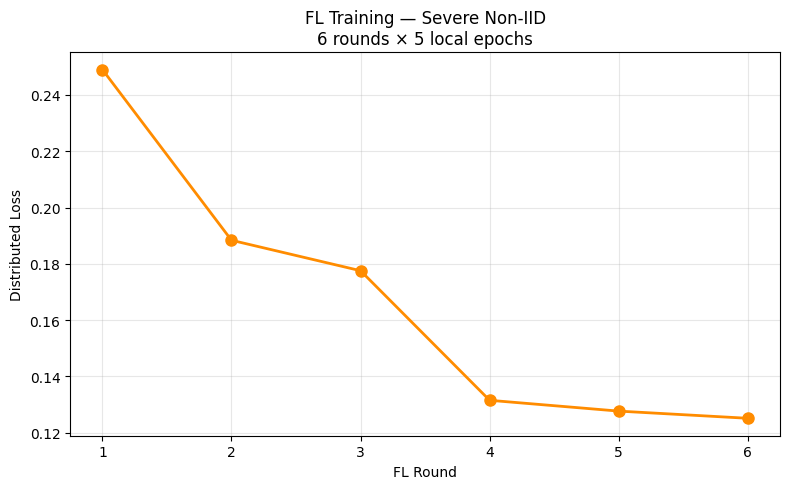


FL SEVERE NON-IID COMPLETE
History : C:\Users\Administrator\desktop\unet\experiments\severe_noniid\fl_results\fl_history_severe.json
Plot    : C:\Users\Administrator\desktop\unet\experiments\severe_noniid\fl_results\fl_loss_severe.png
Model   : C:\Users\Administrator\desktop\unet\experiments\severe_noniid\fl_results\global_fl_severe_final.pt

Next: run Cell 8-SEVERE to evaluate global model

RESOURCE USAGE REPORT
RAM (GB):
  Mean : 4.15
  Peak : 4.96
  Min  : 0.46
VRAM (GB):
  Mean : 11.76
  Peak : 11.77
  Min  : 0.00
Resource plot saved: C:\Users\Administrator\desktop\unet\experiments\severe_noniid\fl_results\resource_usage_severe.png


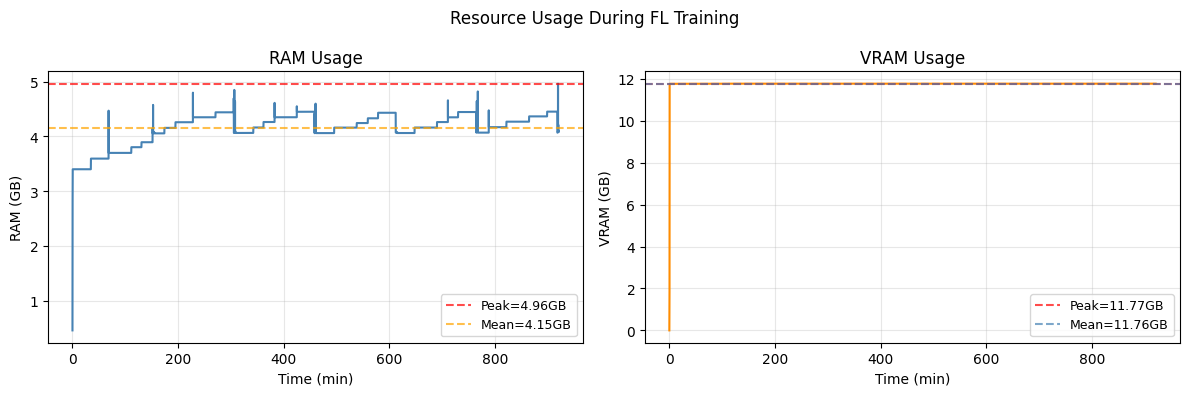

In [1]:
# CELL 7-SEVERE — FLOWER FL SIMULATION (SEVERE NON-IID)
# Uses existing patches via severe_noniid split manifests
# No new preprocessing or patches needed
# Saves to: experiments/severe_noniid/fl_results/
# Nothing overwrites moderate non-IID results
# ============================================================
import flwr as fl
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from pathlib import Path
from flwr.server.strategy import FedAvg
from flwr.common import ndarrays_to_parameters, \
                        parameters_to_ndarrays
import numpy as np
import json
import random
import pickle
import shutil

OUT_ROOT   = Path(r"C:\Users\Administrator\desktop\unet")
EXP_DIR    = OUT_ROOT / "experiments" / "severe_noniid"
FL_OUT_DIR = EXP_DIR  / "fl_results"
FL_OUT_DIR.mkdir(parents=True, exist_ok=True)

# ── assert no overwriting ─────────────────────────────────────
files_that_would_be_written = [
    FL_OUT_DIR / f"fl_round{r}_global.pt" for r in range(1,7)
] + [
    FL_OUT_DIR / "global_fl_severe_final.pt",
    FL_OUT_DIR / "fl_history_severe.json",
    FL_OUT_DIR / "fl_loss_severe.png",
    FL_OUT_DIR / "resource_usage_severe.png",
]
for f in files_that_would_be_written:
    assert not f.exists(), \
        f"Would overwrite {f} — delete it first"
print("✓ No existing files would be overwritten")

# ── resource monitoring ───────────────────────────────────────
import threading
import time
import psutil
import subprocess

class ResourceMonitor:
    def __init__(self, interval=5):
        self.interval   = interval
        self.ram_usage  = []
        self.vram_usage = []
        self.running    = False
        self._thread    = None

    def _monitor(self):
        while self.running:
            # RAM
            ram = psutil.Process().memory_info().rss / 1e9
            self.ram_usage.append(ram)

            # VRAM
            try:
                result = subprocess.run(
                    ["nvidia-smi",
                     "--query-gpu=memory.used",
                     "--format=csv,noheader,nounits"],
                    capture_output=True, text=True)
                vram = float(result.stdout.strip()) / 1024
                self.vram_usage.append(vram)
            except Exception:
                pass

            time.sleep(self.interval)

    def start(self):
        self.running = True
        self._thread = threading.Thread(
            target=self._monitor, daemon=True)
        self._thread.start()
        print(f"✓ Resource monitor started "
              f"(sampling every {self.interval}s)")

    def stop(self):
        self.running = False
        if self._thread:
            self._thread.join(timeout=10)

    def report(self):
        print(f"\n{'='*50}")
        print(f"RESOURCE USAGE REPORT")
        print(f"{'='*50}")
        if self.ram_usage:
            print(f"RAM (GB):")
            print(f"  Mean : {np.mean(self.ram_usage):.2f}")
            print(f"  Peak : {max(self.ram_usage):.2f}")
            print(f"  Min  : {min(self.ram_usage):.2f}")
        if self.vram_usage:
            print(f"VRAM (GB):")
            print(f"  Mean : {np.mean(self.vram_usage):.2f}")
            print(f"  Peak : {max(self.vram_usage):.2f}")
            print(f"  Min  : {min(self.vram_usage):.2f}")
        if not self.ram_usage and not self.vram_usage:
            print("No samples collected")

    def plot(self, save_path=None):
        if not self.ram_usage and not self.vram_usage:
            return
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        fig.suptitle("Resource Usage During FL Training",
                     fontsize=12)
        if self.ram_usage:
            t = [i * self.interval / 60
                 for i in range(len(self.ram_usage))]
            axes[0].plot(t, self.ram_usage,
                         color='steelblue', linewidth=1.5)
            axes[0].axhline(max(self.ram_usage),
                            color='red', linestyle='--',
                            alpha=0.7,
                            label=f'Peak={max(self.ram_usage):.2f}GB')
            axes[0].axhline(np.mean(self.ram_usage),
                            color='orange', linestyle='--',
                            alpha=0.7,
                            label=f'Mean={np.mean(self.ram_usage):.2f}GB')
            axes[0].set_xlabel('Time (min)')
            axes[0].set_ylabel('RAM (GB)')
            axes[0].set_title('RAM Usage')
            axes[0].legend(fontsize=9)
            axes[0].grid(True, alpha=0.3)
        if self.vram_usage:
            t = [i * self.interval / 60
                 for i in range(len(self.vram_usage))]
            axes[1].plot(t, self.vram_usage,
                         color='darkorange', linewidth=1.5)
            axes[1].axhline(max(self.vram_usage),
                            color='red', linestyle='--',
                            alpha=0.7,
                            label=f'Peak={max(self.vram_usage):.2f}GB')
            axes[1].axhline(np.mean(self.vram_usage),
                            color='steelblue', linestyle='--',
                            alpha=0.7,
                            label=f'Mean={np.mean(self.vram_usage):.2f}GB')
            axes[1].set_xlabel('Time (min)')
            axes[1].set_ylabel('VRAM (GB)')
            axes[1].set_title('VRAM Usage')
            axes[1].legend(fontsize=9)
            axes[1].grid(True, alpha=0.3)
        plt.tight_layout()
        if save_path:
            plt.savefig(save_path, dpi=100,
                        bbox_inches='tight')
            print(f"Resource plot saved: {save_path}")
        plt.show()

monitor = ResourceMonitor(interval=5)
monitor.start()

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Device      : {DEVICE}")
print(f"Experiment  : severe_noniid")
print(f"Results dir : {FL_OUT_DIR}")

# ── FL hyperparameters ────────────────────────────────────────
NUM_ROUNDS   = 6
LOCAL_EPOCHS = 5
BATCH_SIZE   = 4
LR           = 1e-4
BASE_FILTERS = 32

# ── UNet ─────────────────────────────────────────────────────
class DoubleConv3D(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm3d(out_ch), nn.ReLU(inplace=True),
            nn.Conv3d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm3d(out_ch), nn.ReLU(inplace=True))
    def forward(self, x): return self.block(x)

class Down(nn.Module):
    def __init__(self, c1, c2):
        super().__init__()
        self.pool = nn.MaxPool3d(2)
        self.conv = DoubleConv3D(c1, c2)
    def forward(self, x): return self.conv(self.pool(x))

class Up(nn.Module):
    def __init__(self, c1, c2):
        super().__init__()
        self.up   = nn.ConvTranspose3d(c1, c2, 2, stride=2)
        self.conv = DoubleConv3D(c1, c2)
    def forward(self, x, skip):
        return self.conv(torch.cat([skip, self.up(x)], dim=1))

class UNet3D(nn.Module):
    def __init__(self, base_filters=32):
        super().__init__()
        f = base_filters
        self.enc1=DoubleConv3D(1,f);   self.enc2=Down(f,f*2)
        self.enc3=Down(f*2,f*4);       self.enc4=Down(f*4,f*8)
        self.bottleneck=Down(f*8,f*16)
        self.dec4=Up(f*16,f*8); self.dec3=Up(f*8,f*4)
        self.dec2=Up(f*4,f*2);  self.dec1=Up(f*2,f)
        self.head=nn.Conv3d(f,1,1)
    def forward(self, x):
        e1=self.enc1(x); e2=self.enc2(e1)
        e3=self.enc3(e2); e4=self.enc4(e3)
        b=self.bottleneck(e4)
        return torch.sigmoid(self.head(
            self.dec1(self.dec2(self.dec3(
                self.dec4(b,e4),e3),e2),e1)))

class OHEMLoss(nn.Module):
    def __init__(self, neg_pos_ratio=3, min_negatives=1000):
        super().__init__()
        self.npr=neg_pos_ratio; self.mnn=min_negatives
    def forward(self, pred, target):
        loss=0.0
        for i in range(pred.shape[0]):
            p=pred[i,0]; t=target[i,0]
            pm=t>0.01; nm=~pm
            pl=F.binary_cross_entropy(
                p[pm],t[pm],reduction='mean'
            ) if pm.sum()>0 else torch.tensor(
                0.0,device=pred.device)
            n_neg=min(int(nm.sum()),
                      max(self.mnn,int(pm.sum())*self.npr))
            nl=F.binary_cross_entropy(
                p[nm],
                torch.zeros(nm.sum(),device=pred.device),
                reduction='none'
            ).topk(n_neg).values.mean()
            loss+=pl+nl
        return loss/pred.shape[0]

class PatchDataset(Dataset):
    def __init__(self, pos_files, neg_files, augment=False):
        self.augment=augment
        self.items=([(str(f),1) for f in pos_files]+
                    [(str(f),0) for f in neg_files])
        random.shuffle(self.items)
    def __len__(self): return len(self.items)
    def __getitem__(self, idx):
        path,_=self.items[idx]; d=np.load(path)
        vol=d['vol'].astype(np.float32)
        heat=d['heatmap'].astype(np.float32)
        if self.augment:
            for ax in range(3):
                if random.random()>0.5:
                    vol=np.flip(vol,axis=ax).copy()
                    heat=np.flip(heat,axis=ax).copy()
            k=random.randint(0,3)
            vol=np.rot90(vol,k=k,axes=(1,2)).copy()
            heat=np.rot90(heat,k=k,axes=(1,2)).copy()
        return (torch.from_numpy(vol).unsqueeze(0),
                torch.from_numpy(heat).unsqueeze(0))

# ── verify manifests ──────────────────────────────────────────
print("\nVerifying severe non-IID manifests...")
for cid in [1,2,3,4,5]:
    mp = EXP_DIR / f"client{cid}_split_manifest.json"
    assert mp.exists(), f"Missing manifest: {mp}"
    with open(mp) as f:
        m = json.load(f)
    print(f"  Client {cid}: {len(m['train_pos'])} train pos  "
          f"{len(m['val_pos'])} val pos  "
          f"{len(m['tst_pids'])} test pts")
print("✓ All manifests present\n")

# ── pre-load all clients ──────────────────────────────────────
print("Loading all client data...")
clients = {}

for cid in [1,2,3,4,5]:
    with open(EXP_DIR / f"client{cid}_split_manifest.json") as f:
        manifest = json.load(f)

    train_pos = [Path(p) for p in manifest["train_pos"]]
    train_neg = [Path(p) for p in manifest["train_neg"]]
    val_pos   = [Path(p) for p in manifest["val_pos"]]
    val_neg   = [Path(p) for p in manifest["val_neg"]]

    train_ds = PatchDataset(train_pos, train_neg, augment=True)
    val_ds   = PatchDataset(val_pos,   val_neg,   augment=False)

    train_loader = DataLoader(
        train_ds, batch_size=BATCH_SIZE,
        shuffle=True, num_workers=0, pin_memory=True)
    val_loader   = DataLoader(
        val_ds, batch_size=BATCH_SIZE,
        shuffle=False, num_workers=0, pin_memory=True)

    model     = UNet3D(base_filters=BASE_FILTERS).to(DEVICE)
    criterion = OHEMLoss(neg_pos_ratio=3, min_negatives=1000)

    class NoduleClient(fl.client.NumPyClient):
        def __init__(self, cid, model, train_loader,
                     val_loader, criterion, device):
            self.cid          = cid
            self.model        = model
            self.train_loader = train_loader
            self.val_loader   = val_loader
            self.criterion    = criterion
            self.device       = device

        def get_parameters(self, config):
            return [v.cpu().numpy()
                    for v in self.model.state_dict().values()]

        def set_parameters(self, parameters):
            state_dict = dict(zip(
                self.model.state_dict().keys(),
                [torch.tensor(p) for p in parameters]
            ))
            self.model.load_state_dict(state_dict, strict=True)

        def fit(self, parameters, config):
            self.set_parameters(parameters)
            local_epochs = config.get("local_epochs",
                                      LOCAL_EPOCHS)
            round_num    = config.get("round_num", 0)
            optimizer    = torch.optim.Adam(
                self.model.parameters(), lr=LR)
            from torch.optim.lr_scheduler import \
                CosineAnnealingLR
            scheduler = CosineAnnealingLR(
                optimizer, T_max=local_epochs)
            self.model.train()
            total_loss = 0.0
            n_batches  = len(self.train_loader)
            for epoch in range(local_epochs):
                ep_loss = 0.0
                for vol, heat in self.train_loader:
                    vol  = vol.to(self.device)
                    heat = heat.to(self.device)
                    optimizer.zero_grad()
                    loss = self.criterion(
                        self.model(vol), heat)
                    loss.backward()
                    optimizer.step()
                    ep_loss += loss.item()
                scheduler.step()
                avg = ep_loss / max(n_batches, 1)
                total_loss += avg
                print(f"    C{self.cid} R{round_num} "
                      f"Ep{epoch+1}/{local_epochs} "
                      f"loss={avg:.4f}", flush=True)
            avg_loss  = total_loss / max(local_epochs, 1)
            n_samples = len(self.train_loader.dataset)
            return (self.get_parameters(config={}),
                    n_samples,
                    {"train_loss": float(avg_loss),
                     "client_id" : self.cid})

        def evaluate(self, parameters, config):
            self.set_parameters(parameters)
            self.model.eval()
            val_loss  = 0.0
            n_samples = len(self.val_loader.dataset)
            with torch.no_grad():
                for vol, heat in self.val_loader:
                    val_loss += self.criterion(
                        self.model(vol.to(self.device)),
                        heat.to(self.device)
                    ).item()
            avg_val = val_loss / max(len(self.val_loader), 1)
            return (float(avg_val), n_samples,
                    {"val_loss": float(avg_val),
                     "client_id": self.cid})

    clients[cid] = NoduleClient(
        cid, model, train_loader,
        val_loader, criterion, DEVICE)
    print(f"  Client {cid}: {len(train_ds)} train  "
          f"{len(val_ds)} val")

print("✓ All clients loaded\n")

def client_fn(cid):
    return clients[int(cid)+1].to_client()

# ── save round weights ────────────────────────────────────────
round_weights = {}

class SaveRoundStrategy(FedAvg):
    def aggregate_fit(self, server_round, results, failures):
        aggregated = super().aggregate_fit(
            server_round, results, failures)
        if aggregated is not None:
            params, metrics = aggregated
            ndarrays = parameters_to_ndarrays(params)
            model_keys = list(
                UNet3D(base_filters=BASE_FILTERS
                       ).state_dict().keys())
            state_dict = dict(zip(
                model_keys,
                [torch.tensor(p) for p in ndarrays]
            ))
            save_path = FL_OUT_DIR / \
                f"fl_round{server_round}_global.pt"
            torch.save(state_dict, save_path)
            print(f"\n  ✓ Round {server_round} saved: "
                  f"{save_path}")
            round_weights[server_round] = save_path
        return aggregated

# ── init ──────────────────────────────────────────────────────
init_model  = UNet3D(base_filters=BASE_FILTERS)
init_params = ndarrays_to_parameters(
    [v.cpu().numpy()
     for v in init_model.state_dict().values()])

strategy = SaveRoundStrategy(
    fraction_fit=1.0,
    fraction_evaluate=1.0,
    min_fit_clients=5,
    min_evaluate_clients=5,
    min_available_clients=5,
    initial_parameters=init_params,
    on_fit_config_fn=lambda r: {
        "local_epochs": LOCAL_EPOCHS,
        "round_num"   : r,
    },
)

# ── run ───────────────────────────────────────────────────────
print(f"{'='*55}")
print(f"FLOWER FL — SEVERE NON-IID SIMULATION")
print(f"{'='*55}")
print(f"Clients      : 5")
print(f"Rounds       : {NUM_ROUNDS}")
print(f"Local epochs : {LOCAL_EPOCHS}")
print(f"Init         : random")
print(f"Strategy     : FedAvg")
print(f"Results dir  : {FL_OUT_DIR}")
print(f"{'='*55}\n")

history = fl.simulation.start_simulation(
    client_fn=client_fn,
    num_clients=5,
    config=fl.server.ServerConfig(num_rounds=NUM_ROUNDS),
    strategy=strategy,
    client_resources={"num_cpus": 1, "num_gpus": 1.0},
)

# ── save final model ──────────────────────────────────────────
final_path = round_weights.get(NUM_ROUNDS)
if final_path and final_path.exists():
    GLOBAL_PT = FL_OUT_DIR / "global_fl_severe_final.pt"
    shutil.copy(final_path, GLOBAL_PT)
    print(f"\n✓ Final model: {GLOBAL_PT}")

# ── save history ──────────────────────────────────────────────
fl_history = {
    "experiment"        : "severe_noniid",
    "num_rounds"        : NUM_ROUNDS,
    "local_epochs"      : LOCAL_EPOCHS,
    "losses_distributed": [
        [r, float(l)]
        for r,l in history.losses_distributed],
}
with open(FL_OUT_DIR / "fl_history_severe.json", "w") as f:
    json.dump(fl_history, f, indent=2)

# ── plot ──────────────────────────────────────────────────────
import matplotlib.pyplot as plt
if history.losses_distributed:
    rounds = [r for r,l in history.losses_distributed]
    losses = [l for r,l in history.losses_distributed]
    fig, ax = plt.subplots(figsize=(8,5))
    ax.plot(rounds, losses, 'o-',
            color='darkorange', linewidth=2, markersize=8)
    ax.set_xlabel('FL Round')
    ax.set_ylabel('Distributed Loss')
    ax.set_title(f'FL Training — Severe Non-IID\n'
                 f'{NUM_ROUNDS} rounds × {LOCAL_EPOCHS} '
                 f'local epochs')
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(FL_OUT_DIR/"fl_loss_severe.png", dpi=100)
    plt.show()

print(f"\n{'='*55}")
print(f"FL SEVERE NON-IID COMPLETE")
print(f"{'='*55}")
print(f"History : {FL_OUT_DIR/'fl_history_severe.json'}")
print(f"Plot    : {FL_OUT_DIR/'fl_loss_severe.png'}")
print(f"Model   : {FL_OUT_DIR/'global_fl_severe_final.pt'}")
print(f"\nNext: run Cell 8-SEVERE to evaluate global model")
monitor.stop()
monitor.report()
monitor.plot(save_path=FL_OUT_DIR/"resource_usage_severe.png")

Device: cuda
✓ No existing files would be overwritten
✓ Resource monitor started (sampling every 5s)
Model loaded: C:\Users\Administrator\desktop\unet\experiments\severe_noniid\fl_results\global_fl_severe_final.pt

Test patients: 132
  client1: 36 patients
  client2: 34 patients
  client3: 18 patients
  client4: 19 patients
  client5: 25 patients


Severe inference:   1%|▍                                                             | 1/132 [00:40<1:28:43, 40.64s/it]

  LIDC-IDRI-0006: GT= 1 TP= 1 FP= 17 FN= 0


Severe inference:   2%|▉                                                             | 2/132 [01:02<1:04:12, 29.64s/it]

  LIDC-IDRI-0015: GT= 1 TP= 1 FP=  1 FN= 0


...

  LIDC-IDRI-0952: GT= 0 TP= 0 FP=  0 FN= 0


Severe inference:  99%|███████████████████████████████████████████████████████████▌| 131/132 [1:20:30<00:35, 35.66s/it]

  LIDC-IDRI-0975: GT= 0 TP= 0 FP=  1 FN= 0


Severe inference: 100%|████████████████████████████████████████████████████████████| 132/132 [1:20:48<00:00, 36.73s/it]

  LIDC-IDRI-0988: GT= 0 TP= 0 FP=  0 FN= 0

Saved results to C:\Users\Administrator\desktop\unet\experiments\severe_noniid\fl_results

GLOBAL FL — SEVERE NON-IID RESULTS
Patients    : 132/132
GT nodules  : 179
TP=133  FP=352  FN=46
Sensitivity : 0.743
Precision   : 0.274
F1          : 0.401
FP/scan     : 2.67

CPM : 0.583
  0.125 FP/scan → 0.313
  0.250 FP/scan → 0.425
  0.500 FP/scan → 0.503
  1.000 FP/scan → 0.631
  2.000 FP/scan → 0.721
  4.000 FP/scan → 0.743
  8.000 FP/scan → 0.743


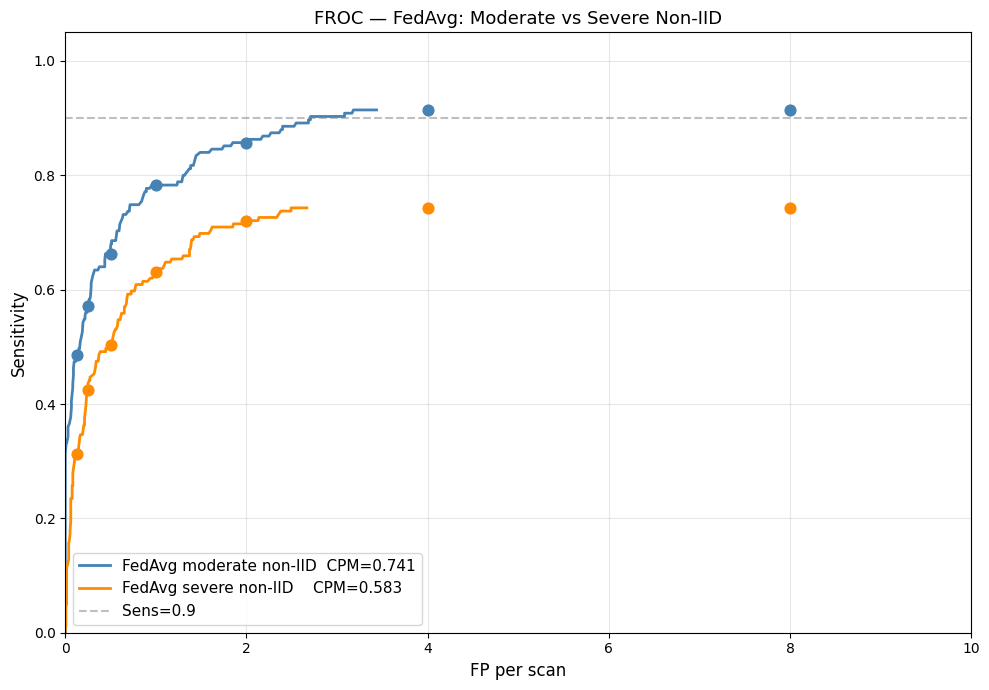


OUTPUT FILES (nothing overwritten)
  experiments/severe_noniid/fl_results/
  ├── severe_all_results.pkl
  ├── severe_all_scores.pkl
  ├── severe_test_results.json
  └── froc_moderate_vs_severe.png

Comparison:
  FedAvg moderate : CPM=0.741
  FedAvg severe   : CPM=0.583

RESOURCE USAGE REPORT
RAM (GB):
  Mean : 6.91
  Peak : 7.27
  Min  : 3.58
VRAM (GB):
  Mean : 10.80
  Peak : 13.63
  Min  : 3.04
Resource plot saved: C:\Users\Administrator\desktop\unet\experiments\severe_noniid\fl_results\resource_usage_severe_inference.png


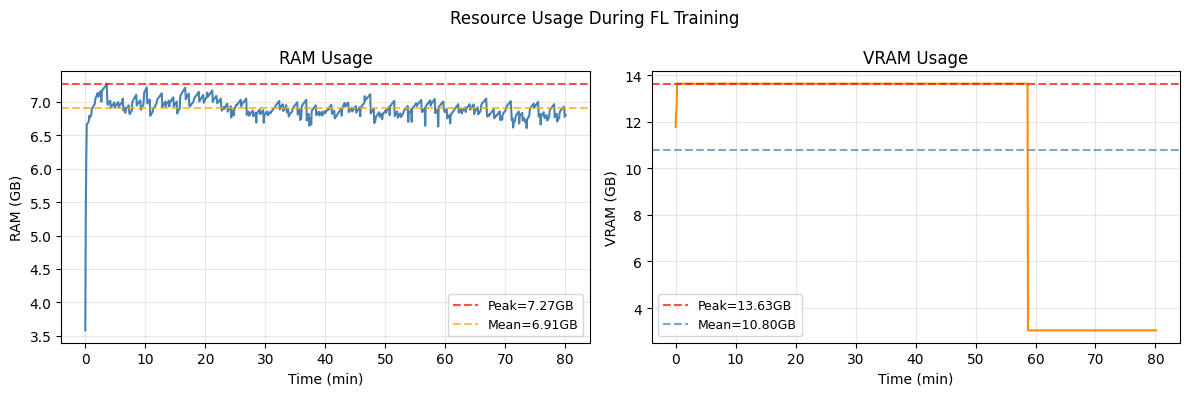

In [2]:
# CELL 8-SEVERE — GLOBAL MODEL EVALUATION (SEVERE NON-IID)
# Evaluates global_fl_severe_final.pt on severe non-IID test pool
# Loads patient data from original client directories
# Nothing overwritten — saves to experiments/severe_noniid/fl_results/
# ============================================================
import torch
import torch.nn as nn
import numpy as np
import json
import pickle
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.ndimage import maximum_filter
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')
# ── resource monitoring ───────────────────────────────────────
import threading
import time
import psutil
import subprocess

class ResourceMonitor:
    def __init__(self, interval=5):
        self.interval   = interval
        self.ram_usage  = []
        self.vram_usage = []
        self.running    = False
        self._thread    = None

    def _monitor(self):
        while self.running:
            # RAM
            ram = psutil.Process().memory_info().rss / 1e9
            self.ram_usage.append(ram)

            # VRAM
            try:
                result = subprocess.run(
                    ["nvidia-smi",
                     "--query-gpu=memory.used",
                     "--format=csv,noheader,nounits"],
                    capture_output=True, text=True)
                vram = float(result.stdout.strip()) / 1024
                self.vram_usage.append(vram)
            except Exception:
                pass

            time.sleep(self.interval)

    def start(self):
        self.running = True
        self._thread = threading.Thread(
            target=self._monitor, daemon=True)
        self._thread.start()
        print(f"✓ Resource monitor started "
              f"(sampling every {self.interval}s)")

    def stop(self):
        self.running = False
        if self._thread:
            self._thread.join(timeout=10)

    def report(self):
        print(f"\n{'='*50}")
        print(f"RESOURCE USAGE REPORT")
        print(f"{'='*50}")
        if self.ram_usage:
            print(f"RAM (GB):")
            print(f"  Mean : {np.mean(self.ram_usage):.2f}")
            print(f"  Peak : {max(self.ram_usage):.2f}")
            print(f"  Min  : {min(self.ram_usage):.2f}")
        if self.vram_usage:
            print(f"VRAM (GB):")
            print(f"  Mean : {np.mean(self.vram_usage):.2f}")
            print(f"  Peak : {max(self.vram_usage):.2f}")
            print(f"  Min  : {min(self.vram_usage):.2f}")
        if not self.ram_usage and not self.vram_usage:
            print("No samples collected")

    def plot(self, save_path=None):
        if not self.ram_usage and not self.vram_usage:
            return
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        fig.suptitle("Resource Usage During FL Training",
                     fontsize=12)
        if self.ram_usage:
            t = [i * self.interval / 60
                 for i in range(len(self.ram_usage))]
            axes[0].plot(t, self.ram_usage,
                         color='steelblue', linewidth=1.5)
            axes[0].axhline(max(self.ram_usage),
                            color='red', linestyle='--',
                            alpha=0.7,
                            label=f'Peak={max(self.ram_usage):.2f}GB')
            axes[0].axhline(np.mean(self.ram_usage),
                            color='orange', linestyle='--',
                            alpha=0.7,
                            label=f'Mean={np.mean(self.ram_usage):.2f}GB')
            axes[0].set_xlabel('Time (min)')
            axes[0].set_ylabel('RAM (GB)')
            axes[0].set_title('RAM Usage')
            axes[0].legend(fontsize=9)
            axes[0].grid(True, alpha=0.3)
        if self.vram_usage:
            t = [i * self.interval / 60
                 for i in range(len(self.vram_usage))]
            axes[1].plot(t, self.vram_usage,
                         color='darkorange', linewidth=1.5)
            axes[1].axhline(max(self.vram_usage),
                            color='red', linestyle='--',
                            alpha=0.7,
                            label=f'Peak={max(self.vram_usage):.2f}GB')
            axes[1].axhline(np.mean(self.vram_usage),
                            color='steelblue', linestyle='--',
                            alpha=0.7,
                            label=f'Mean={np.mean(self.vram_usage):.2f}GB')
            axes[1].set_xlabel('Time (min)')
            axes[1].set_ylabel('VRAM (GB)')
            axes[1].set_title('VRAM Usage')
            axes[1].legend(fontsize=9)
            axes[1].grid(True, alpha=0.3)
        plt.tight_layout()
        if save_path:
            plt.savefig(save_path, dpi=100,
                        bbox_inches='tight')
            print(f"Resource plot saved: {save_path}")
        plt.show()

monitor = ResourceMonitor(interval=5)


OUT_ROOT   = Path(r"C:\Users\Administrator\desktop\unet")
EXP_DIR    = OUT_ROOT / "experiments" / "severe_noniid"
FL_OUT_DIR = EXP_DIR  / "fl_results"

DEVICE     = 'cuda' if torch.cuda.is_available() else 'cpu'
PATCH_SIZE = 96
STRIDE     = 20
THRESHOLD  = 0.3
BASE_FILTERS = 32

print(f"Device: {DEVICE}")

# ── UNet ─────────────────────────────────────────────────────
class DoubleConv3D(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm3d(out_ch), nn.ReLU(inplace=True),
            nn.Conv3d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm3d(out_ch), nn.ReLU(inplace=True))
    def forward(self, x): return self.block(x)

class Down(nn.Module):
    def __init__(self, c1, c2):
        super().__init__()
        self.pool = nn.MaxPool3d(2)
        self.conv = DoubleConv3D(c1, c2)
    def forward(self, x): return self.conv(self.pool(x))

class Up(nn.Module):
    def __init__(self, c1, c2):
        super().__init__()
        self.up   = nn.ConvTranspose3d(c1, c2, 2, stride=2)
        self.conv = DoubleConv3D(c1, c2)
    def forward(self, x, skip):
        return self.conv(torch.cat([skip, self.up(x)], dim=1))

class UNet3D(nn.Module):
    def __init__(self, base_filters=32):
        super().__init__()
        f = base_filters
        self.enc1=DoubleConv3D(1,f);   self.enc2=Down(f,f*2)
        self.enc3=Down(f*2,f*4);       self.enc4=Down(f*4,f*8)
        self.bottleneck=Down(f*8,f*16)
        self.dec4=Up(f*16,f*8); self.dec3=Up(f*8,f*4)
        self.dec2=Up(f*4,f*2);  self.dec1=Up(f*2,f)
        self.head=nn.Conv3d(f,1,1)
    def forward(self, x):
        e1=self.enc1(x); e2=self.enc2(e1)
        e3=self.enc3(e2); e4=self.enc4(e3)
        b=self.bottleneck(e4)
        return torch.sigmoid(self.head(
            self.dec1(self.dec2(self.dec3(
                self.dec4(b,e4),e3),e2),e1)))
        
# ── assert no overwriting ─────────────────────────────────────
files_that_would_be_written = [
    FL_OUT_DIR / "severe_all_results.pkl",
    FL_OUT_DIR / "severe_all_scores.pkl",
    FL_OUT_DIR / "severe_test_results.json",
    FL_OUT_DIR / "froc_moderate_vs_severe.png",
    FL_OUT_DIR / "resource_usage_severe_inference.png",
]
for f in files_that_would_be_written:
    assert not f.exists(), \
        f"Would overwrite {f} — delete it first"
print("✓ No existing files would be overwritten")

monitor.start()

# ── load global model ─────────────────────────────────────────
GLOBAL_PT = FL_OUT_DIR / "global_fl_severe_final.pt"
assert GLOBAL_PT.exists(), f"Model not found: {GLOBAL_PT}"
model = UNet3D(base_filters=BASE_FILTERS).to(DEVICE)
model.load_state_dict(torch.load(
    GLOBAL_PT, map_location=DEVICE))
model.eval()
print(f"Model loaded: {GLOBAL_PT}")

# ── load severe test pool ─────────────────────────────────────
with open(EXP_DIR / "global_test_pids_severe.json") as f:
    global_test = json.load(f)
all_test_pids = global_test["test_pids"]
by_client     = global_test.get("by_client", {})
print(f"\nTest patients: {len(all_test_pids)}")
for cid, pids in by_client.items():
    print(f"  {cid}: {len(pids)} patients")

# ── load federation splits for path routing ───────────────────
with open(OUT_ROOT / "federation_splits.json") as f:
    orig_splits = json.load(f)

def get_patient_dirs(pid):
    """Get preproc/mask/annot dirs from ORIGINAL client location."""
    if pid in orig_splits["client1_pids"]:
        return (OUT_ROOT / "preprocessed",
                OUT_ROOT / "lung_masks",
                OUT_ROOT / "annotations")
    for cid in [2,3,4,5]:
        if pid in orig_splits.get(f"client{cid}_pids", []):
            cd = OUT_ROOT / f"client{cid}"
            return (cd / "preprocessed",
                    cd / "lung_masks",
                    cd / "annotations")
    raise ValueError(f"{pid} not found in any client")

# ── inference functions ───────────────────────────────────────
def sliding_window_max(model, vol, mask,
                        patch_size, stride, device):
    D,H,W   = vol.shape
    p       = patch_size
    heatmap = np.zeros((D,H,W), dtype=np.float32)
    coords  = np.argwhere(mask > 0)
    if len(coords) == 0:
        return heatmap
    z1=max(0,coords[:,0].min()-p//4)
    y1=max(0,coords[:,1].min()-p//4)
    x1=max(0,coords[:,2].min()-p//4)
    z2=min(D,coords[:,0].max()+p//4)
    y2=min(H,coords[:,1].max()+p//4)
    x2=min(W,coords[:,2].max()+p//4)
    model.eval()
    with torch.no_grad():
        for zw in range(z1,z2-p+1,stride):
            for yw in range(y1,y2-p+1,stride):
                for xw in range(x1,x2-p+1,stride):
                    patch=vol[zw:zw+p,yw:yw+p,xw:xw+p]
                    if patch.shape!=(p,p,p): continue
                    if mask[zw:zw+p,yw:yw+p,
                            xw:xw+p].mean()<0.05: continue
                    t=torch.from_numpy(patch).unsqueeze(0)\
                          .unsqueeze(0).float().to(device)
                    pred=model(t).squeeze().cpu().numpy()
                    heatmap[zw:zw+p,yw:yw+p,xw:xw+p]=\
                        np.maximum(
                            heatmap[zw:zw+p,yw:yw+p,xw:xw+p],
                            pred)
    return heatmap

def get_detections(heatmap, threshold=0.3, min_dist=6):
    lm=maximum_filter(
        heatmap,footprint=np.ones((min_dist,)*3))==heatmap
    lm=lm&(heatmap>threshold)
    c=np.argwhere(lm)
    if len(c)==0: return []
    s=heatmap[lm]; o=np.argsort(s)[::-1]
    return [(int(c[i,0]),int(c[i,1]),
             int(c[i,2]),float(s[i])) for i in o]

def match_gt(detections, gt_nodules):
    matched=set(); tp,fp=[],[]
    for det in detections:
        dz,dy,dx,sc=det; bd,bi=float('inf'),-1
        for gi,nod in enumerate(gt_nodules):
            if gi in matched: continue
            gz,gy,gx=nod['center_res']
            d=np.sqrt((dz-gz)**2+(dy-gy)**2+(dx-gx)**2)
            if d<max(nod['radius_mm'],10.0) and d<bd:
                bd,bi=d,gi
        if bi>=0:
            tp.append({'det':det,
                       'gt':gt_nodules[bi],
                       'dist_mm':bd})
            matched.add(bi)
        else:
            fp.append({'det':det})
    fn=[{'gt':n} for gi,n in enumerate(gt_nodules)
        if gi not in matched]
    return tp,fp,fn

# ── run inference ─────────────────────────────────────────────
all_results = []
all_scores  = []
total_gt    = 0
missing     = []

for pid in tqdm(all_test_pids, desc="Severe inference"):
    try:
        pd_dir, md_dir, ad_dir = get_patient_dirs(pid)
    except ValueError as e:
        print(f"\n  {e}")
        missing.append(pid)
        continue

    vp = pd_dir / f"{pid}.npy"
    mp = md_dir / f"{pid}.npy"
    ap = ad_dir / f"{pid}.json"

    if not (vp.exists() and mp.exists() and ap.exists()):
        print(f"\n  SKIP {pid} — missing files")
        missing.append(pid)
        continue

    vol  = np.load(vp)
    mask = np.load(mp)
    with open(ap) as f:
        gt_nods = json.load(f)["consensus_nodules"]
    total_gt += len(gt_nods)

    heatmap    = sliding_window_max(
        model, vol, mask, PATCH_SIZE, STRIDE, DEVICE)
    detections = get_detections(heatmap, THRESHOLD)
    tp,fp,fn   = match_gt(detections, gt_nods)

    all_results.append({
        "pid"       : pid,
        "gt_nodules": len(gt_nods),
        "detections": len(detections),
        "tp"        : len(tp),
        "fp"        : len(fp),
        "fn"        : len(fn),
        "tp_list"   : tp,
        "fp_list"   : fp,
        "fn_list"   : fn,
    })
    for i in tp: all_scores.append((i["det"][3], 1))
    for i in fp: all_scores.append((i["det"][3], 0))

    print(f"  {pid}: GT={len(gt_nods):2d} "
          f"TP={len(tp):2d} FP={len(fp):3d} "
          f"FN={len(fn):2d}")

# ── save immediately ──────────────────────────────────────────
with open(FL_OUT_DIR/"severe_all_results.pkl","wb") as f:
    pickle.dump(all_results, f)
with open(FL_OUT_DIR/"severe_all_scores.pkl","wb") as f:
    pickle.dump(all_scores, f)
print(f"\nSaved results to {FL_OUT_DIR}")

# ── metrics ───────────────────────────────────────────────────
ttp = sum(r["tp"] for r in all_results)
tfp = sum(r["fp"] for r in all_results)
tfn = sum(r["fn"] for r in all_results)
ns  = len(all_results)
sen = ttp / max(ttp+tfn, 1)
pre = ttp / max(ttp+tfp, 1)
f1  = 2*pre*sen / max(pre+sen, 1e-6)
fps = tfp / max(ns, 1)

print(f"\n{'='*55}")
print(f"GLOBAL FL — SEVERE NON-IID RESULTS")
print(f"{'='*55}")
print(f"Patients    : {ns}/{len(all_test_pids)}")
if missing: print(f"Missing     : {len(missing)}")
print(f"GT nodules  : {total_gt}")
print(f"TP={ttp}  FP={tfp}  FN={tfn}")
print(f"Sensitivity : {sen:.3f}")
print(f"Precision   : {pre:.3f}")
print(f"F1          : {f1:.3f}")
print(f"FP/scan     : {fps:.2f}")

# ── FROC + CPM ────────────────────────────────────────────────
cpm = 0.0
if all_scores:
    all_scores.sort(key=lambda x:x[0], reverse=True)
    sa=np.array([s[0] for s in all_scores])
    la=np.array([s[1] for s in all_scores])
    sl,fl=[],[]
    for th in np.linspace(0.95,0.01,500):
        k=sa>=th
        sl.append(float(la[k].sum()/max(total_gt,1)))
        fl.append(float((1-la[k]).sum()/max(ns,1)))
    fp_pts=[0.125,0.25,0.5,1,2,4,8]
    cpm_s=[sl[np.argmin([abs(f-fp) for f in fl])]
           for fp in fp_pts]
    cpm=float(np.mean(cpm_s))

    print(f"\nCPM : {cpm:.3f}")
    for fp_pt,s in zip(fp_pts,cpm_s):
        print(f"  {fp_pt:5.3f} FP/scan → {s:.3f}")

    # ── comparison plot ───────────────────────────────────────
    # load moderate results for comparison
    with open(OUT_ROOT/"logs_global"/"global_all_scores.pkl",
              "rb") as f:
        mod_scores = pickle.load(f)
    mod_scores.sort(key=lambda x:x[0], reverse=True)
    sa_m=np.array([s[0] for s in mod_scores])
    la_m=np.array([s[1] for s in mod_scores])
    total_gt_mod = 175
    sl_m,fl_m=[],[]
    for th in np.linspace(0.95,0.01,500):
        k=sa_m>=th
        sl_m.append(float(la_m[k].sum()/max(total_gt_mod,1)))
        fl_m.append(float((1-la_m[k]).sum()/133))
    cpm_sm=[sl_m[np.argmin([abs(f-fp) for f in fl_m])]
            for fp in fp_pts]
    cpm_mod=float(np.mean(cpm_sm))

    fig,ax=plt.subplots(figsize=(10,7))
    ax.plot(fl_m, sl_m, color='steelblue', linewidth=2,
            label=f'FedAvg moderate non-IID  CPM={cpm_mod:.3f}')
    ax.plot(fl,   sl,   color='darkorange', linewidth=2,
            label=f'FedAvg severe non-IID    CPM={cpm:.3f}')
    ax.scatter(fp_pts, cpm_sm,
               color='steelblue', zorder=5, s=60)
    ax.scatter(fp_pts, cpm_s,
               color='darkorange', zorder=5, s=60)
    ax.axhline(0.9,color='gray',linestyle='--',
               alpha=0.5,label='Sens=0.9')
    ax.set_xlabel('FP per scan', fontsize=12)
    ax.set_ylabel('Sensitivity', fontsize=12)
    ax.set_title('FROC — FedAvg: Moderate vs Severe Non-IID',
                 fontsize=13)
    ax.set_xlim(0,10); ax.set_ylim(0,1.05)
    ax.legend(fontsize=11); ax.grid(True,alpha=0.3)
    plt.tight_layout()
    plt.savefig(FL_OUT_DIR/"froc_moderate_vs_severe.png",
                dpi=100, bbox_inches='tight')
    plt.show()

# ── save results ──────────────────────────────────────────────
results = {
    "experiment"  : "severe_noniid",
    "model"       : "global_fl_severe_final.pt",
    "stride"      : STRIDE,
    "threshold"   : THRESHOLD,
    "n_patients"  : ns,
    "total_gt"    : total_gt,
    "total_tp"    : ttp,
    "total_fp"    : tfp,
    "total_fn"    : tfn,
    "sensitivity" : round(sen, 4),
    "precision"   : round(pre, 4),
    "f1"          : round(f1,  4),
    "fp_per_scan" : round(fps, 4),
    "cpm"         : round(cpm, 4),
    "per_patient" : [
        {k:v for k,v in r.items()
         if k not in ("tp_list","fp_list","fn_list")}
        for r in all_results
    ]
}
with open(FL_OUT_DIR/"severe_test_results.json","w") as f:
    json.dump(results, f, indent=2)

print(f"\n{'='*55}")
print(f"OUTPUT FILES (nothing overwritten)")
print(f"{'='*55}")
print(f"  experiments/severe_noniid/fl_results/")
print(f"  ├── severe_all_results.pkl")
print(f"  ├── severe_all_scores.pkl")
print(f"  ├── severe_test_results.json")
print(f"  └── froc_moderate_vs_severe.png")
print(f"\nComparison:")
print(f"  FedAvg moderate : CPM={cpm_mod:.3f}")
print(f"  FedAvg severe   : CPM={cpm:.3f}")

monitor.stop()
monitor.report()
monitor.plot(save_path=FL_OUT_DIR/"resource_usage_severe_inference.png")

✓ No existing files would be overwritten
Loaded 132 patient results
PID→client map: 132 entries

PER-CLIENT RESULTS — FedAvg Severe Non-IID
Client          N    GT    TP    FP    FN   Sens   Prec  FP/scan
───────────────────────────────────────────────────────────────────────────
client1        36    39    28   102    11  0.718  0.215     2.83  ← thin+small+high_clean
client2        34    66    47    86    19  0.712  0.353     2.53  ← thin+large+low_clean
client3        18    35    25    51    10  0.714  0.329     2.83  ← medium+any+mid_clean
client4        19     7     6    25     1  0.857  0.194     1.32  ← thick+small+high_clean
client5        25    32    27    88     5  0.844  0.235     3.52  ← thick+large+low_clean
───────────────────────────────────────────────────────────────────────────
GLOBAL        132   179   133   352    46  0.743  0.274     2.67

✓ FedProx severe per-client loaded for comparison


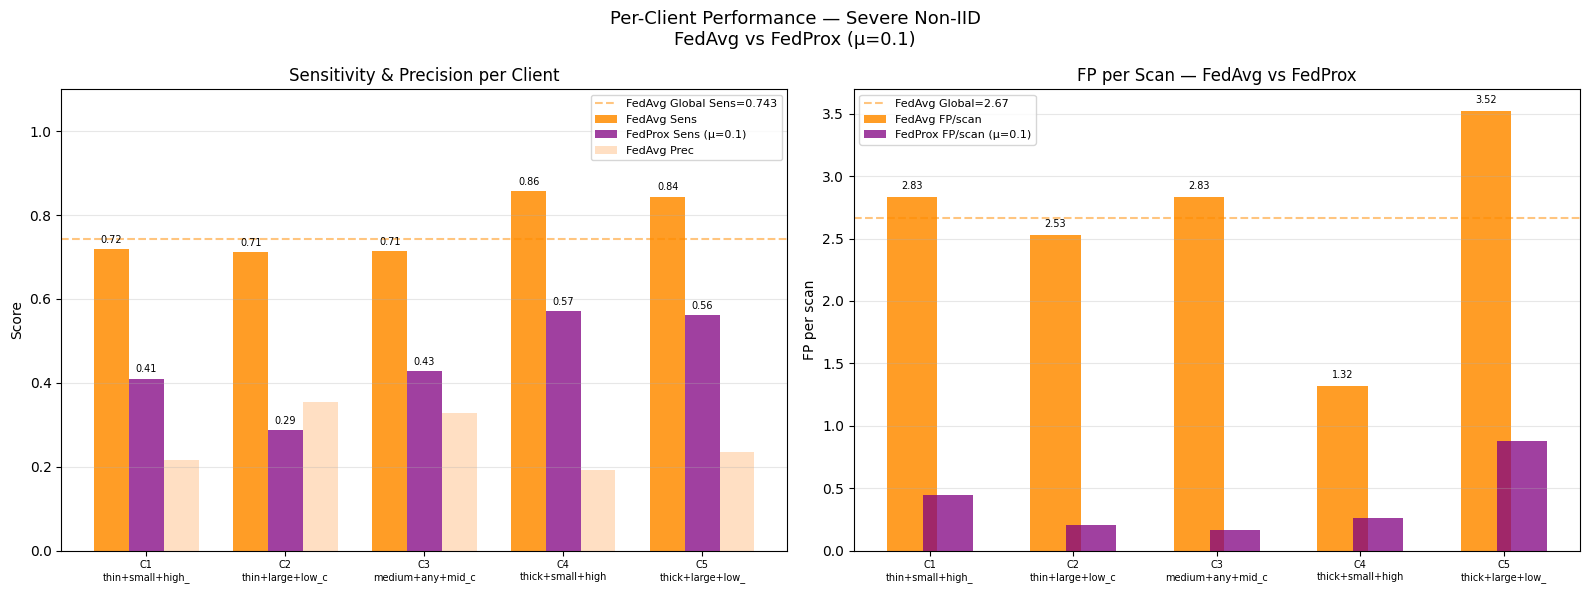


Plot saved : C:\Users\Administrator\desktop\unet\experiments\severe_noniid\fl_results\per_client_metrics_fedavg_severe.png
JSON saved : C:\Users\Administrator\desktop\unet\experiments\severe_noniid\fl_results\per_client_metrics_fedavg_severe.json


In [4]:
# PER-CLIENT EVALUATION — FEDAVG SEVERE
# Uses already-computed inference PKL
# Groups test patients by SEVERE non-IID client assignment
# No re-inference, no GPU needed
# Saves to: experiments/severe_noniid/fl_results/
# ============================================================
import pickle
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from collections import defaultdict

OUT_ROOT   = Path(r"C:\Users\Administrator\desktop\unet")
EXP_DIR    = OUT_ROOT / "experiments" / "severe_noniid"
FL_OUT_DIR = EXP_DIR  / "fl_results"

# ── assert no overwriting ─────────────────────────────────────
out_png  = FL_OUT_DIR / "per_client_metrics_fedavg_severe.png"
out_json = FL_OUT_DIR / "per_client_metrics_fedavg_severe.json"
assert not out_png.exists(),  f"Would overwrite {out_png}"
assert not out_json.exists(), f"Would overwrite {out_json}"
print("✓ No existing files would be overwritten")

# ── load inference results ────────────────────────────────────
PKL_PATH = FL_OUT_DIR / "severe_all_results.pkl"
assert PKL_PATH.exists(), f"Missing: {PKL_PATH}"
with open(PKL_PATH,"rb") as f:
    all_results = pickle.load(f)
print(f"Loaded {len(all_results)} patient results")

# ── load severe test pool with by_client mapping ──────────────
test_pool_path = EXP_DIR / "global_test_pids_severe.json"
assert test_pool_path.exists(), f"Missing: {test_pool_path}"
with open(test_pool_path) as f:
    global_test = json.load(f)

pid_to_client = {}
for cid, pids in global_test["by_client"].items():
    for pid in pids:
        pid_to_client[pid] = cid

print(f"PID→client map: {len(pid_to_client)} entries")

# ── group results by client ───────────────────────────────────
client_results = defaultdict(list)
unmapped = []
for r in all_results:
    pid = r["pid"]
    cid = pid_to_client.get(pid)
    if cid is None:
        unmapped.append(pid); continue
    client_results[cid].append(r)
if unmapped:
    print(f"WARNING: {len(unmapped)} pids not mapped")

EXP_NAME = "FedAvg Severe Non-IID"

client_descriptions = {
    "client1": "thin+small+high_clean",
    "client2": "thin+large+low_clean",
    "client3": "medium+any+mid_clean",
    "client4": "thick+small+high_clean",
    "client5": "thick+large+low_clean",
}

# ── compute per-client metrics ────────────────────────────────
print(f"\n{'='*75}")
print(f"PER-CLIENT RESULTS — {EXP_NAME}")
print(f"{'='*75}")
print(f"{'Client':<12} {'N':>4} {'GT':>5} {'TP':>5} "
      f"{'FP':>5} {'FN':>5} {'Sens':>6} {'Prec':>6} "
      f"{'FP/scan':>8}")
print(f"{'─'*75}")

summary = {}
for cid in sorted(client_results.keys()):
    results = client_results[cid]
    ttp = sum(r["tp"] for r in results)
    tfp = sum(r["fp"] for r in results)
    tfn = sum(r["fn"] for r in results)
    tgt = sum(r["gt_nodules"] for r in results)
    ns  = len(results)
    sen = ttp/max(ttp+tfn,1)
    pre = ttp/max(ttp+tfp,1)
    f1  = 2*pre*sen/max(pre+sen,1e-6)
    fps = tfp/max(ns,1)
    print(f"{cid:<12} {ns:>4} {tgt:>5} {ttp:>5} "
          f"{tfp:>5} {tfn:>5} {sen:>6.3f} {pre:>6.3f} "
          f"{fps:>8.2f}  "
          f"← {client_descriptions.get(cid,'')}")
    summary[cid] = {
        "n_patients"  : ns,
        "total_gt"    : tgt,
        "total_tp"    : ttp,
        "total_fp"    : tfp,
        "total_fn"    : tfn,
        "sensitivity" : round(sen,4),
        "precision"   : round(pre,4),
        "f1"          : round(f1,4),
        "fp_per_scan" : round(fps,4),
        "description" : client_descriptions.get(cid,''),
    }

# global
all_ttp = sum(r["tp"] for r in all_results)
all_tfp = sum(r["fp"] for r in all_results)
all_tfn = sum(r["fn"] for r in all_results)
all_gt  = sum(r["gt_nodules"] for r in all_results)
all_ns  = len(all_results)
all_sen = all_ttp/max(all_ttp+all_tfn,1)
all_pre = all_ttp/max(all_ttp+all_tfp,1)
all_fps = all_tfp/max(all_ns,1)
print(f"{'─'*75}")
print(f"{'GLOBAL':<12} {all_ns:>4} {all_gt:>5} "
      f"{all_ttp:>5} {all_tfp:>5} {all_tfn:>5} "
      f"{all_sen:>6.3f} {all_pre:>6.3f} {all_fps:>8.2f}")

# ── load FedProx severe for comparison ───────────────────────
fedprox_severe_path = (OUT_ROOT / "experiments" /
                       "fedprox_severe" /
                       "per_client_metrics_fedprox_severe.json")
fedprox_summary = None
if fedprox_severe_path.exists():
    with open(fedprox_severe_path) as f:
        fp_data = json.load(f)
    fedprox_summary = fp_data.get("per_client", {})
    print(f"\n✓ FedProx severe per-client loaded for comparison")

# ── bar chart ─────────────────────────────────────────────────
clients = sorted(summary.keys())
sens    = [summary[c]["sensitivity"] for c in clients]
precs   = [summary[c]["precision"]   for c in clients]
fps_    = [summary[c]["fp_per_scan"] for c in clients]
labels  = [c.replace("client","C")  for c in clients]
descs   = [client_descriptions.get(c,'')[:16]
           for c in clients]

x = np.arange(len(clients))
w = 0.25

if fedprox_summary:
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    fig.suptitle(
        "Per-Client Performance — Severe Non-IID\n"
        "FedAvg vs FedProx (μ=0.1)",
        fontsize=13)

    fp_sens = [fedprox_summary.get(c,{}).get("sensitivity",0)
               for c in clients]
    fp_prec = [fedprox_summary.get(c,{}).get("precision",0)
               for c in clients]
    fp_fps  = [fedprox_summary.get(c,{}).get("fp_per_scan",0)
               for c in clients]

    ax = axes[0]
    b1 = ax.bar(x-w,   sens,    w,
                label='FedAvg Sens',
                color='darkorange', alpha=0.85)
    b2 = ax.bar(x,     fp_sens, w,
                label='FedProx Sens (μ=0.1)',
                color='purple',     alpha=0.75)
    b3 = ax.bar(x+w,   precs,   w,
                label='FedAvg Prec',
                color='peachpuff',  alpha=0.85)
    ax.axhline(all_sen,color='darkorange',linestyle='--',
               alpha=0.5,
               label=f'FedAvg Global Sens={all_sen:.3f}')
    ax.set_xticks(x)
    ax.set_xticklabels(
        [f"{l}\n{d}" for l,d in zip(labels,descs)],
        fontsize=7)
    ax.set_ylim(0,1.1); ax.set_ylabel('Score')
    ax.set_title('Sensitivity & Precision per Client')
    ax.legend(fontsize=8); ax.grid(True,alpha=0.3,axis='y')
    for b in b1:
        ax.text(b.get_x()+b.get_width()/2,
                b.get_height()+0.01,
                f'{b.get_height():.2f}',
                ha='center',va='bottom',fontsize=7)
    for b in b2:
        ax.text(b.get_x()+b.get_width()/2,
                b.get_height()+0.01,
                f'{b.get_height():.2f}',
                ha='center',va='bottom',fontsize=7)

    ax = axes[1]
    ax.bar(x-w/2, fps_,   0.35,
           label='FedAvg FP/scan',
           color='darkorange', alpha=0.85)
    ax.bar(x+w/2, fp_fps, 0.35,
           label='FedProx FP/scan (μ=0.1)',
           color='purple',     alpha=0.75)
    ax.axhline(all_fps,color='darkorange',linestyle='--',
               alpha=0.5,
               label=f'FedAvg Global={all_fps:.2f}')
    ax.set_xticks(x)
    ax.set_xticklabels(
        [f"{l}\n{d}" for l,d in zip(labels,descs)],
        fontsize=7)
    ax.set_ylabel('FP per scan')
    ax.set_title('FP per Scan — FedAvg vs FedProx')
    ax.legend(fontsize=8); ax.grid(True,alpha=0.3,axis='y')
    for b in ax.patches[:5]:
        ax.text(b.get_x()+b.get_width()/2,
                b.get_height()+0.05,
                f'{b.get_height():.2f}',
                ha='center',va='bottom',fontsize=7)

else:
    # no FedProx severe yet — single experiment chart
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    fig.suptitle(f"Per-Client Performance\n{EXP_NAME}",
                 fontsize=13)

    ax = axes[0]
    b1=ax.bar(x-w/2, sens,  w, label='Sensitivity',
              color='darkorange', alpha=0.85)
    b2=ax.bar(x+w/2, precs, w, label='Precision',
              color='peachpuff',  alpha=0.85)
    ax.axhline(all_sen,color='darkorange',linestyle='--',
               alpha=0.6,
               label=f'Global Sens={all_sen:.3f}')
    ax.axhline(all_pre,color='peachpuff',linestyle='--',
               alpha=0.6,
               label=f'Global Prec={all_pre:.3f}')
    ax.set_xticks(x)
    ax.set_xticklabels(
        [f"{l}\n{d}" for l,d in zip(labels,descs)],
        fontsize=7)
    ax.set_ylim(0,1.1); ax.set_ylabel('Score')
    ax.set_title('Sensitivity & Precision per Client')
    ax.legend(fontsize=9); ax.grid(True,alpha=0.3,axis='y')
    for b in b1:
        ax.text(b.get_x()+b.get_width()/2,
                b.get_height()+0.01,
                f'{b.get_height():.3f}',
                ha='center',va='bottom',fontsize=8)
    for b in b2:
        ax.text(b.get_x()+b.get_width()/2,
                b.get_height()+0.01,
                f'{b.get_height():.3f}',
                ha='center',va='bottom',fontsize=8)

    ax = axes[1]
    bars=ax.bar(x, fps_, 0.5,
                color='tomato', alpha=0.85)
    ax.axhline(all_fps,color='black',linestyle='--',
               alpha=0.6,
               label=f'Global FP/scan={all_fps:.2f}')
    ax.set_xticks(x)
    ax.set_xticklabels(
        [f"{l}\n{d}" for l,d in zip(labels,descs)],
        fontsize=7)
    ax.set_ylabel('FP per scan')
    ax.set_title('FP per Scan per Client')
    ax.legend(fontsize=9); ax.grid(True,alpha=0.3,axis='y')
    for b in bars:
        ax.text(b.get_x()+b.get_width()/2,
                b.get_height()+0.05,
                f'{b.get_height():.2f}',
                ha='center',va='bottom',fontsize=9)

plt.tight_layout()
plt.savefig(out_png,dpi=100,bbox_inches='tight')
plt.show()
print(f"\nPlot saved : {out_png}")

# ── save json ─────────────────────────────────────────────────
with open(out_json,"w") as f:
    json.dump({
        "experiment" : EXP_NAME,
        "per_client" : summary,
        "global"     : {
            "n_patients" : all_ns,
            "total_gt"   : all_gt,
            "total_tp"   : all_ttp,
            "total_fp"   : all_tfp,
            "total_fn"   : all_tfn,
            "sensitivity": round(all_sen,4),
            "precision"  : round(all_pre,4),
            "fp_per_scan": round(all_fps,4),
        }
    },f,indent=2)
print(f"JSON saved : {out_json}")

FedProx severe mu 0.1

In [ ]:
# CELL 7-FEDPROX-SEVERE — FedProx FL (Severe Non-IID)
# Uses severe_noniid split manifests
# Saves to: experiments/fedprox_severe/
# Nothing overwrites any existing results
# ============================================================
import flwr as fl
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from pathlib import Path
from flwr.server.strategy import FedAvg
from flwr.common import ndarrays_to_parameters, \
                        parameters_to_ndarrays
import numpy as np
import json
import random
import pickle
import shutil
import threading
import time
import psutil
import subprocess

class ResourceMonitor:
    def __init__(self, interval=5):
        self.interval=interval; self.ram_usage=[]
        self.vram_usage=[]; self.running=False
        self._thread=None
    def _monitor(self):
        while self.running:
            ram=psutil.Process().memory_info().rss/1e9
            self.ram_usage.append(ram)
            try:
                r=subprocess.run(
                    ["nvidia-smi","--query-gpu=memory.used",
                     "--format=csv,noheader,nounits"],
                    capture_output=True,text=True)
                self.vram_usage.append(
                    float(r.stdout.strip())/1024)
            except: pass
            time.sleep(self.interval)
    def start(self):
        self.running=True
        self._thread=threading.Thread(
            target=self._monitor,daemon=True)
        self._thread.start()
        print(f"✓ Monitor started (every {self.interval}s)")
    def stop(self):
        self.running=False
        if self._thread: self._thread.join(timeout=10)
    def report(self):
        print(f"\n{'='*50}\nRESOURCE USAGE REPORT\n{'='*50}")
        if self.ram_usage:
            print(f"RAM  mean={np.mean(self.ram_usage):.2f}GB  "
                  f"peak={max(self.ram_usage):.2f}GB")
        if self.vram_usage:
            print(f"VRAM mean={np.mean(self.vram_usage):.2f}GB  "
                  f"peak={max(self.vram_usage):.2f}GB")
    def plot(self, save_path=None):
        if not self.ram_usage and not self.vram_usage: return
        import matplotlib.pyplot as plt
        fig,axes=plt.subplots(1,2,figsize=(12,4))
        fig.suptitle("Resource Usage",fontsize=12)
        if self.ram_usage:
            t=[i*self.interval/60 for i in range(len(self.ram_usage))]
            axes[0].plot(t,self.ram_usage,color='steelblue',linewidth=1.5)
            axes[0].axhline(max(self.ram_usage),color='red',
                linestyle='--',alpha=0.7,
                label=f'Peak={max(self.ram_usage):.2f}GB')
            axes[0].axhline(np.mean(self.ram_usage),color='orange',
                linestyle='--',alpha=0.7,
                label=f'Mean={np.mean(self.ram_usage):.2f}GB')
            axes[0].set_xlabel('Time (min)'); axes[0].set_ylabel('RAM (GB)')
            axes[0].set_title('RAM Usage'); axes[0].legend(fontsize=9)
            axes[0].grid(True,alpha=0.3)
        if self.vram_usage:
            t=[i*self.interval/60 for i in range(len(self.vram_usage))]
            axes[1].plot(t,self.vram_usage,color='darkorange',linewidth=1.5)
            axes[1].axhline(max(self.vram_usage),color='red',
                linestyle='--',alpha=0.7,
                label=f'Peak={max(self.vram_usage):.2f}GB')
            axes[1].axhline(np.mean(self.vram_usage),color='steelblue',
                linestyle='--',alpha=0.7,
                label=f'Mean={np.mean(self.vram_usage):.2f}GB')
            axes[1].set_xlabel('Time (min)'); axes[1].set_ylabel('VRAM (GB)')
            axes[1].set_title('VRAM Usage'); axes[1].legend(fontsize=9)
            axes[1].grid(True,alpha=0.3)
        plt.tight_layout()
        if save_path:
            plt.savefig(save_path,dpi=100,bbox_inches='tight')
            print(f"Resource plot saved: {save_path}")
        plt.show()

OUT_ROOT   = Path(r"C:\Users\Administrator\desktop\unet")
EXP_DIR    = OUT_ROOT / "experiments" / "severe_noniid"
OUT_EXP    = OUT_ROOT / "experiments" / "fedprox_severe"
OUT_EXP.mkdir(parents=True, exist_ok=True)

# ── assert no overwriting ─────────────────────────────────────
files_that_would_be_written = [
    OUT_EXP / f"fl_round{r}_global.pt" for r in range(1,7)
] + [
    OUT_EXP / "global_fedprox_severe_final.pt",
    OUT_EXP / "fl_history_fedprox_severe.json",
    OUT_EXP / "fl_loss_fedprox_severe.png",
    OUT_EXP / "resource_usage.png",
]
for f in files_that_would_be_written:
    assert not f.exists(), \
        f"Would overwrite {f} — delete it first"
print("✓ No existing files would be overwritten")

monitor = ResourceMonitor(interval=5)
monitor.start()

DEVICE       = 'cuda' if torch.cuda.is_available() else 'cpu'
NUM_ROUNDS   = 6
LOCAL_EPOCHS = 5
BATCH_SIZE   = 4
LR           = 1e-4
BASE_FILTERS = 32
PROXIMAL_MU  = 0.1

print(f"Device      : {DEVICE}")
print(f"Experiment  : fedprox_severe")
print(f"Results dir : {OUT_EXP}")

# ── UNet ─────────────────────────────────────────────────────
class DoubleConv3D(nn.Module):
    def __init__(self,in_ch,out_ch):
        super().__init__()
        self.block=nn.Sequential(
            nn.Conv3d(in_ch,out_ch,3,padding=1,bias=False),
            nn.BatchNorm3d(out_ch),nn.ReLU(inplace=True),
            nn.Conv3d(out_ch,out_ch,3,padding=1,bias=False),
            nn.BatchNorm3d(out_ch),nn.ReLU(inplace=True))
    def forward(self,x): return self.block(x)

class Down(nn.Module):
    def __init__(self,c1,c2):
        super().__init__()
        self.pool=nn.MaxPool3d(2); self.conv=DoubleConv3D(c1,c2)
    def forward(self,x): return self.conv(self.pool(x))

class Up(nn.Module):
    def __init__(self,c1,c2):
        super().__init__()
        self.up=nn.ConvTranspose3d(c1,c2,2,stride=2)
        self.conv=DoubleConv3D(c1,c2)
    def forward(self,x,skip):
        return self.conv(torch.cat([skip,self.up(x)],dim=1))

class UNet3D(nn.Module):
    def __init__(self,base_filters=32):
        super().__init__()
        f=base_filters
        self.enc1=DoubleConv3D(1,f); self.enc2=Down(f,f*2)
        self.enc3=Down(f*2,f*4);     self.enc4=Down(f*4,f*8)
        self.bottleneck=Down(f*8,f*16)
        self.dec4=Up(f*16,f*8); self.dec3=Up(f*8,f*4)
        self.dec2=Up(f*4,f*2);  self.dec1=Up(f*2,f)
        self.head=nn.Conv3d(f,1,1)
    def forward(self,x):
        e1=self.enc1(x); e2=self.enc2(e1)
        e3=self.enc3(e2); e4=self.enc4(e3)
        b=self.bottleneck(e4)
        return torch.sigmoid(self.head(
            self.dec1(self.dec2(self.dec3(
                self.dec4(b,e4),e3),e2),e1)))

class OHEMLoss(nn.Module):
    def __init__(self,neg_pos_ratio=3,min_negatives=1000):
        super().__init__()
        self.npr=neg_pos_ratio; self.mnn=min_negatives
    def forward(self,pred,target):
        loss=0.0
        for i in range(pred.shape[0]):
            p=pred[i,0]; t=target[i,0]
            pm=t>0.01; nm=~pm
            pl=F.binary_cross_entropy(
                p[pm],t[pm],reduction='mean'
            ) if pm.sum()>0 else torch.tensor(
                0.0,device=pred.device)
            n_neg=min(int(nm.sum()),
                      max(self.mnn,int(pm.sum())*self.npr))
            nl=F.binary_cross_entropy(
                p[nm],torch.zeros(nm.sum(),device=pred.device),
                reduction='none').topk(n_neg).values.mean()
            loss+=pl+nl
        return loss/pred.shape[0]

class PatchDataset(Dataset):
    def __init__(self,pos_files,neg_files,augment=False):
        self.augment=augment
        self.items=([(str(f),1) for f in pos_files]+
                    [(str(f),0) for f in neg_files])
        random.shuffle(self.items)
    def __len__(self): return len(self.items)
    def __getitem__(self,idx):
        path,_=self.items[idx]; d=np.load(path)
        vol=d['vol'].astype(np.float32)
        heat=d['heatmap'].astype(np.float32)
        if self.augment:
            for ax in range(3):
                if random.random()>0.5:
                    vol=np.flip(vol,axis=ax).copy()
                    heat=np.flip(heat,axis=ax).copy()
            k=random.randint(0,3)
            vol=np.rot90(vol,k=k,axes=(1,2)).copy()
            heat=np.rot90(heat,k=k,axes=(1,2)).copy()
        return (torch.from_numpy(vol).unsqueeze(0),
                torch.from_numpy(heat).unsqueeze(0))

# ── verify severe manifests ───────────────────────────────────
print("\nVerifying severe non-IID manifests...")
for cid in [1,2,3,4,5]:
    mp = EXP_DIR / f"client{cid}_split_manifest.json"
    assert mp.exists(), f"Missing: {mp}"
    with open(mp) as f: m=json.load(f)
    print(f"  Client {cid}: {len(m['train_pos'])} train pos  "
          f"{len(m['val_pos'])} val pos  "
          f"{len(m['tst_pids'])} test pts")
print("✓ All manifests present\n")

# ── pre-load all clients ──────────────────────────────────────
print("Loading all client data...")
clients = {}

for cid in [1,2,3,4,5]:
    with open(EXP_DIR/f"client{cid}_split_manifest.json") as f:
        manifest=json.load(f)
    train_pos=[Path(p) for p in manifest["train_pos"]]
    train_neg=[Path(p) for p in manifest["train_neg"]]
    val_pos  =[Path(p) for p in manifest["val_pos"]]
    val_neg  =[Path(p) for p in manifest["val_neg"]]
    train_ds=PatchDataset(train_pos,train_neg,augment=True)
    val_ds  =PatchDataset(val_pos,  val_neg,  augment=False)
    train_loader=DataLoader(train_ds,batch_size=BATCH_SIZE,
        shuffle=True,num_workers=0,pin_memory=True)
    val_loader  =DataLoader(val_ds,  batch_size=BATCH_SIZE,
        shuffle=False,num_workers=0,pin_memory=True)
    model    =UNet3D(base_filters=BASE_FILTERS).to(DEVICE)
    criterion=OHEMLoss(neg_pos_ratio=3,min_negatives=1000)

    class FedProxClient(fl.client.NumPyClient):
        def __init__(self,cid,model,train_loader,
                     val_loader,criterion,device,mu):
            self.cid=cid; self.model=model
            self.train_loader=train_loader
            self.val_loader=val_loader
            self.criterion=criterion
            self.device=device; self.mu=mu
            self.global_params=None
        def get_parameters(self,config):
            return [v.cpu().numpy()
                    for v in self.model.state_dict().values()]
        def set_parameters(self,parameters):
            state_dict=dict(zip(
                self.model.state_dict().keys(),
                [torch.tensor(p) for p in parameters]))
            self.model.load_state_dict(state_dict,strict=True)
            self.global_params=[
                p.clone().detach()
                for p in self.model.parameters()]
        def fit(self,parameters,config):
            self.set_parameters(parameters)
            local_epochs=config.get("local_epochs",LOCAL_EPOCHS)
            round_num   =config.get("round_num",0)
            optimizer=torch.optim.Adam(
                self.model.parameters(),lr=LR)
            from torch.optim.lr_scheduler import CosineAnnealingLR
            scheduler=CosineAnnealingLR(
                optimizer,T_max=local_epochs)
            self.model.train()
            total_loss=0.0
            n_batches=len(self.train_loader)
            for epoch in range(local_epochs):
                ep_loss=0.0
                for vol,heat in self.train_loader:
                    vol=vol.to(self.device)
                    heat=heat.to(self.device)
                    optimizer.zero_grad()
                    task_loss=self.criterion(
                        self.model(vol),heat)
                    prox_term=0.0
                    for lp,gp in zip(
                        self.model.parameters(),
                        self.global_params):
                        prox_term+=(
                            lp-gp.to(self.device)
                        ).norm(2)**2
                    loss=task_loss+(self.mu/2)*prox_term
                    loss.backward(); optimizer.step()
                    ep_loss+=task_loss.item()
                scheduler.step()
                avg=ep_loss/max(n_batches,1)
                total_loss+=avg
                print(f"    C{self.cid} R{round_num} "
                      f"Ep{epoch+1}/{local_epochs} "
                      f"loss={avg:.4f}",flush=True)
            avg_loss=total_loss/max(local_epochs,1)
            n_samples=len(self.train_loader.dataset)
            return (self.get_parameters(config={}),
                    n_samples,
                    {"train_loss":float(avg_loss),
                     "client_id":self.cid})
        def evaluate(self,parameters,config):
            self.set_parameters(parameters)
            self.model.eval(); val_loss=0.0
            n_samples=len(self.val_loader.dataset)
            with torch.no_grad():
                for vol,heat in self.val_loader:
                    val_loss+=self.criterion(
                        self.model(vol.to(self.device)),
                        heat.to(self.device)).item()
            avg_val=val_loss/max(len(self.val_loader),1)
            return (float(avg_val),n_samples,
                    {"val_loss":float(avg_val),
                     "client_id":self.cid})

    clients[cid]=FedProxClient(
        cid,model,train_loader,val_loader,
        criterion,DEVICE,PROXIMAL_MU)
    print(f"  Client {cid}: {len(train_ds)} train  "
          f"{len(val_ds)} val")

print(f"✓ All clients loaded (μ={PROXIMAL_MU})\n")

def client_fn(cid):
    return clients[int(cid)+1].to_client()

round_weights={}

class SaveRoundStrategy(FedAvg):
    def aggregate_fit(self,server_round,results,failures):
        aggregated=super().aggregate_fit(
            server_round,results,failures)
        if aggregated is not None:
            params,_=aggregated
            ndarrays=parameters_to_ndarrays(params)
            model_keys=list(UNet3D(
                base_filters=BASE_FILTERS).state_dict().keys())
            state_dict=dict(zip(model_keys,
                [torch.tensor(p) for p in ndarrays]))
            save_path=OUT_EXP/f"fl_round{server_round}_global.pt"
            torch.save(state_dict,save_path)
            print(f"\n  ✓ Round {server_round} saved: {save_path}")
            round_weights[server_round]=save_path
        return aggregated

init_model =UNet3D(base_filters=BASE_FILTERS)
init_params=ndarrays_to_parameters(
    [v.cpu().numpy()
     for v in init_model.state_dict().values()])

strategy=SaveRoundStrategy(
    fraction_fit=1.0, fraction_evaluate=1.0,
    min_fit_clients=5, min_evaluate_clients=5,
    min_available_clients=5,
    initial_parameters=init_params,
    on_fit_config_fn=lambda r:{
        "local_epochs":LOCAL_EPOCHS,"round_num":r},)

print(f"{'='*55}")
print(f"FLOWER FL — FEDPROX SEVERE NON-IID")
print(f"{'='*55}")
print(f"Clients      : 5")
print(f"Rounds       : {NUM_ROUNDS}")
print(f"Local epochs : {LOCAL_EPOCHS}")
print(f"Proximal mu  : {PROXIMAL_MU}")
print(f"Results dir  : {OUT_EXP}")
print(f"{'='*55}\n")

history=fl.simulation.start_simulation(
    client_fn=client_fn,
    num_clients=5,
    config=fl.server.ServerConfig(num_rounds=NUM_ROUNDS),
    strategy=strategy,
    client_resources={"num_cpus":1,"num_gpus":1.0},)

final_path=round_weights.get(NUM_ROUNDS)
if final_path and final_path.exists():
    GLOBAL_PT=OUT_EXP/"global_fedprox_severe_final.pt"
    shutil.copy(final_path,GLOBAL_PT)
    print(f"\n✓ Final model: {GLOBAL_PT}")

fl_history={
    "experiment"        :"fedprox_severe",
    "proximal_mu"       :PROXIMAL_MU,
    "num_rounds"        :NUM_ROUNDS,
    "local_epochs"      :LOCAL_EPOCHS,
    "losses_distributed":[[r,float(l)]
        for r,l in history.losses_distributed],}
with open(OUT_EXP/"fl_history_fedprox_severe.json","w") as f:
    json.dump(fl_history,f,indent=2)

import matplotlib.pyplot as plt
if history.losses_distributed:
    rounds=[r for r,l in history.losses_distributed]
    losses=[l for r,l in history.losses_distributed]
    fig,ax=plt.subplots(figsize=(8,5))
    ax.plot(rounds,losses,'o-',color='purple',
            linewidth=2,markersize=8)
    ax.set_xlabel('FL Round'); ax.set_ylabel('Distributed Loss')
    ax.set_title(f'FedProx — Severe Non-IID\n'
                 f'μ={PROXIMAL_MU}  {NUM_ROUNDS} rounds × '
                 f'{LOCAL_EPOCHS} local epochs')
    ax.grid(True,alpha=0.3); plt.tight_layout()
    plt.savefig(OUT_EXP/"fl_loss_fedprox_severe.png",dpi=100)
    plt.show()

print(f"\n{'='*55}")
print(f"FEDPROX SEVERE COMPLETE")
print(f"{'='*55}")
print(f"Model   : {OUT_EXP/'global_fedprox_severe_final.pt'}")
print(f"History : {OUT_EXP/'fl_history_fedprox_severe.json'}")
monitor.stop()
monitor.report()
monitor.plot(save_path=OUT_EXP/"resource_usage.png")

✓ No existing files would be overwritten
✓ Monitor started (every 5s)
Device      : cuda
Experiment  : fedprox_severe
Results dir : C:\Users\Administrator\desktop\unet\experiments\fedprox_severe

Verifying severe non-IID manifests...
  Client 1: 680 train pos  95 val pos  36 test pts
  Client 2: 1485 train pos  260 val pos  34 test pts
  Client 3: 640 train pos  145 val pos  18 test pts
  Client 4: 390 train pos  80 val pos  19 test pts
  Client 5: 1025 train pos  210 val pos  25 test pts
✓ All manifests present

Loading all client data...
  Client 1: 2754 train  554 val
  Client 2: 3419 train  674 val
  Client 3: 1687 train  361 val
  Client 4: 1545 train  336 val
  Client 5: 2668 train  549 val
✓ All clients loaded (μ=0.1)

FLOWER FL — FEDPROX SEVERE NON-IID
Clients      : 5
Rounds       : 6
Local epochs : 5
Proximal mu  : 0.1
Results dir  : C:\Users\Administrator\desktop\unet\experiments\fedprox_severe



	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
INFO :      Starting Flower simulation, config: num_rounds=6, no round_timeout
2026-04-08 10:30:45,422	INFO worker.py:2012 -- Started a local Ray instance.
C:\ProgramData\miniconda3\envs\lungfl\lib\site-packages\ray\_private\worker.py:2051: FutureWarning: Tip: In future versions of Ray, Ray will no longer override accelerator visible devices env var if num_gpus=0 or num_gpus=None (default). To enable this behavior and turn off this error message, set RAY_ACCEL_ENV_VAR_OVERRIDE_ON_ZERO=0
  warnings.warn(
INFO :      Flower VCE: Ray initialized with resources: {'object_store_memory': 3154054348.0, 'G

(ClientAppActor pid=8276)     C4 R1 Ep1/5 loss=0.6708


In [3]:
# CELL 8-FEDPROX-SEVERE — Evaluation
# Evaluates global_fedprox_severe_final.pt
# on severe non-IID test pool (132 patients)
# Saves to: experiments/fedprox_severe/
# Nothing overwritten anywhere
# ============================================================
import torch
import torch.nn as nn
import numpy as np
import json
import pickle
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.ndimage import maximum_filter
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')
import threading, time, psutil, subprocess

PROXIMAL_MU = 0.1

class ResourceMonitor:
    def __init__(self,interval=5):
        self.interval=interval; self.ram_usage=[]
        self.vram_usage=[]; self.running=False
        self._thread=None
    def _monitor(self):
        while self.running:
            self.ram_usage.append(
                psutil.Process().memory_info().rss/1e9)
            try:
                r=subprocess.run(
                    ["nvidia-smi","--query-gpu=memory.used",
                     "--format=csv,noheader,nounits"],
                    capture_output=True,text=True)
                self.vram_usage.append(
                    float(r.stdout.strip())/1024)
            except: pass
            time.sleep(self.interval)
    def start(self):
        self.running=True
        self._thread=threading.Thread(
            target=self._monitor,daemon=True)
        self._thread.start()
        print(f"✓ Monitor started (every {self.interval}s)")
    def stop(self):
        self.running=False
        if self._thread: self._thread.join(timeout=10)
    def report(self):
        print(f"\n{'='*50}\nRESOURCE USAGE REPORT\n{'='*50}")
        if self.ram_usage:
            print(f"RAM  mean={np.mean(self.ram_usage):.2f}GB  "
                  f"peak={max(self.ram_usage):.2f}GB")
        if self.vram_usage:
            print(f"VRAM mean={np.mean(self.vram_usage):.2f}GB  "
                  f"peak={max(self.vram_usage):.2f}GB")
    def plot(self,save_path=None):
        if not self.ram_usage and not self.vram_usage: return
        fig,axes=plt.subplots(1,2,figsize=(12,4))
        fig.suptitle("Resource Usage — Inference",fontsize=12)
        if self.ram_usage:
            t=[i*self.interval/60
               for i in range(len(self.ram_usage))]
            axes[0].plot(t,self.ram_usage,
                         color='steelblue',linewidth=1.5)
            axes[0].axhline(max(self.ram_usage),color='red',
                linestyle='--',alpha=0.7,
                label=f'Peak={max(self.ram_usage):.2f}GB')
            axes[0].axhline(np.mean(self.ram_usage),
                color='orange',linestyle='--',alpha=0.7,
                label=f'Mean={np.mean(self.ram_usage):.2f}GB')
            axes[0].set_xlabel('Time (min)')
            axes[0].set_ylabel('RAM (GB)')
            axes[0].set_title('RAM Usage')
            axes[0].legend(fontsize=9)
            axes[0].grid(True,alpha=0.3)
        if self.vram_usage:
            t=[i*self.interval/60
               for i in range(len(self.vram_usage))]
            axes[1].plot(t,self.vram_usage,
                         color='darkorange',linewidth=1.5)
            axes[1].axhline(max(self.vram_usage),color='red',
                linestyle='--',alpha=0.7,
                label=f'Peak={max(self.vram_usage):.2f}GB')
            axes[1].axhline(np.mean(self.vram_usage),
                color='steelblue',linestyle='--',alpha=0.7,
                label=f'Mean={np.mean(self.vram_usage):.2f}GB')
            axes[1].set_xlabel('Time (min)')
            axes[1].set_ylabel('VRAM (GB)')
            axes[1].set_title('VRAM Usage')
            axes[1].legend(fontsize=9)
            axes[1].grid(True,alpha=0.3)
        plt.tight_layout()
        if save_path:
            plt.savefig(save_path,dpi=100,bbox_inches='tight')
            print(f"Resource plot saved: {save_path}")
        plt.show()

OUT_ROOT = Path(r"C:\Users\Administrator\desktop\unet")
EXP_DIR  = OUT_ROOT / "experiments" / "severe_noniid"
OUT_EXP  = OUT_ROOT / "experiments" / "fedprox_severe"
GLOBAL_PT= OUT_EXP  / "global_fedprox_severe_final.pt"

DEVICE      ='cuda' if torch.cuda.is_available() else 'cpu'
PATCH_SIZE  = 96
STRIDE      = 20
THRESHOLD   = 0.3
BASE_FILTERS= 32

print(f"Device: {DEVICE}")

# ── assert no overwriting ─────────────────────────────────────
files_that_would_be_written = [
    OUT_EXP / "fedprox_severe_results.pkl",
    OUT_EXP / "fedprox_severe_scores.pkl",
    OUT_EXP / "fedprox_severe_test_results.json",
    OUT_EXP / "froc_fedprox_severe.png",
    OUT_EXP / "resource_usage_inference.png",
]
for f in files_that_would_be_written:
    assert not f.exists(), \
        f"Would overwrite {f} — delete it first"
print("✓ No existing files would be overwritten")

monitor = ResourceMonitor(interval=5)
monitor.start()

# ── UNet ─────────────────────────────────────────────────────
class DoubleConv3D(nn.Module):
    def __init__(self,in_ch,out_ch):
        super().__init__()
        self.block=nn.Sequential(
            nn.Conv3d(in_ch,out_ch,3,padding=1,bias=False),
            nn.BatchNorm3d(out_ch),nn.ReLU(inplace=True),
            nn.Conv3d(out_ch,out_ch,3,padding=1,bias=False),
            nn.BatchNorm3d(out_ch),nn.ReLU(inplace=True))
    def forward(self,x): return self.block(x)
class Down(nn.Module):
    def __init__(self,c1,c2):
        super().__init__()
        self.pool=nn.MaxPool3d(2); self.conv=DoubleConv3D(c1,c2)
    def forward(self,x): return self.conv(self.pool(x))
class Up(nn.Module):
    def __init__(self,c1,c2):
        super().__init__()
        self.up=nn.ConvTranspose3d(c1,c2,2,stride=2)
        self.conv=DoubleConv3D(c1,c2)
    def forward(self,x,skip):
        return self.conv(torch.cat([skip,self.up(x)],dim=1))
class UNet3D(nn.Module):
    def __init__(self,base_filters=32):
        super().__init__()
        f=base_filters
        self.enc1=DoubleConv3D(1,f); self.enc2=Down(f,f*2)
        self.enc3=Down(f*2,f*4);     self.enc4=Down(f*4,f*8)
        self.bottleneck=Down(f*8,f*16)
        self.dec4=Up(f*16,f*8); self.dec3=Up(f*8,f*4)
        self.dec2=Up(f*4,f*2);  self.dec1=Up(f*2,f)
        self.head=nn.Conv3d(f,1,1)
    def forward(self,x):
        e1=self.enc1(x); e2=self.enc2(e1)
        e3=self.enc3(e2); e4=self.enc4(e3)
        b=self.bottleneck(e4)
        return torch.sigmoid(self.head(
            self.dec1(self.dec2(self.dec3(
                self.dec4(b,e4),e3),e2),e1)))

# ── load model ────────────────────────────────────────────────
assert GLOBAL_PT.exists(), f"Model not found: {GLOBAL_PT}"
model=UNet3D(base_filters=BASE_FILTERS).to(DEVICE)
model.load_state_dict(torch.load(GLOBAL_PT,map_location=DEVICE))
model.eval()
print(f"Model loaded: {GLOBAL_PT}")

# ── load severe test pool ─────────────────────────────────────
with open(EXP_DIR/"global_test_pids_severe.json") as f:
    global_test=json.load(f)
all_test_pids=global_test["test_pids"]
print(f"Test patients: {len(all_test_pids)}")

# ── path routing ──────────────────────────────────────────────
with open(OUT_ROOT/"federation_splits.json") as f:
    orig_splits=json.load(f)

def get_patient_dirs(pid):
    if pid in orig_splits["client1_pids"]:
        return (OUT_ROOT/"preprocessed",
                OUT_ROOT/"lung_masks",
                OUT_ROOT/"annotations")
    for cid in [2,3,4,5]:
        if pid in orig_splits.get(f"client{cid}_pids",[]):
            cd=OUT_ROOT/f"client{cid}"
            return (cd/"preprocessed",
                    cd/"lung_masks",
                    cd/"annotations")
    raise ValueError(f"{pid} not found")

# ── inference functions ───────────────────────────────────────
def sliding_window_max(model,vol,mask,patch_size,stride,device):
    D,H,W=vol.shape; p=patch_size
    heatmap=np.zeros((D,H,W),dtype=np.float32)
    coords=np.argwhere(mask>0)
    if len(coords)==0: return heatmap
    z1=max(0,coords[:,0].min()-p//4)
    y1=max(0,coords[:,1].min()-p//4)
    x1=max(0,coords[:,2].min()-p//4)
    z2=min(D,coords[:,0].max()+p//4)
    y2=min(H,coords[:,1].max()+p//4)
    x2=min(W,coords[:,2].max()+p//4)
    model.eval()
    with torch.no_grad():
        for zw in range(z1,z2-p+1,stride):
            for yw in range(y1,y2-p+1,stride):
                for xw in range(x1,x2-p+1,stride):
                    patch=vol[zw:zw+p,yw:yw+p,xw:xw+p]
                    if patch.shape!=(p,p,p): continue
                    if mask[zw:zw+p,yw:yw+p,
                            xw:xw+p].mean()<0.05: continue
                    t=torch.from_numpy(patch).unsqueeze(0)\
                          .unsqueeze(0).float().to(device)
                    pred=model(t).squeeze().cpu().numpy()
                    heatmap[zw:zw+p,yw:yw+p,xw:xw+p]=\
                        np.maximum(
                            heatmap[zw:zw+p,yw:yw+p,xw:xw+p],
                            pred)
    return heatmap

def get_detections(heatmap,threshold=0.3,min_dist=6):
    lm=maximum_filter(
        heatmap,footprint=np.ones((min_dist,)*3))==heatmap
    lm=lm&(heatmap>threshold)
    c=np.argwhere(lm)
    if len(c)==0: return []
    s=heatmap[lm]; o=np.argsort(s)[::-1]
    return [(int(c[i,0]),int(c[i,1]),
             int(c[i,2]),float(s[i])) for i in o]

def match_gt(detections,gt_nodules):
    matched=set(); tp,fp=[],[]
    for det in detections:
        dz,dy,dx,sc=det; bd,bi=float('inf'),-1
        for gi,nod in enumerate(gt_nodules):
            if gi in matched: continue
            gz,gy,gx=nod['center_res']
            d=np.sqrt((dz-gz)**2+(dy-gy)**2+(dx-gx)**2)
            if d<max(nod['radius_mm'],10.0) and d<bd:
                bd,bi=d,gi
        if bi>=0:
            tp.append({'det':det,'gt':gt_nodules[bi],
                       'dist_mm':bd}); matched.add(bi)
        else: fp.append({'det':det})
    fn=[{'gt':n} for gi,n in enumerate(gt_nodules)
        if gi not in matched]
    return tp,fp,fn

# ── run inference ─────────────────────────────────────────────
all_results=[]; all_scores=[]; total_gt=0; missing=[]

for pid in tqdm(all_test_pids,desc="FedProx severe inference"):
    try: pd_dir,md_dir,ad_dir=get_patient_dirs(pid)
    except ValueError as e:
        missing.append(pid); continue
    vp=pd_dir/f"{pid}.npy"; mp=md_dir/f"{pid}.npy"
    ap=ad_dir/f"{pid}.json"
    if not (vp.exists() and mp.exists() and ap.exists()):
        missing.append(pid); continue
    vol=np.load(vp); mask=np.load(mp)
    with open(ap) as f:
        gt_nods=json.load(f)["consensus_nodules"]
    total_gt+=len(gt_nods)
    heatmap   =sliding_window_max(
        model,vol,mask,PATCH_SIZE,STRIDE,DEVICE)
    detections=get_detections(heatmap,THRESHOLD)
    tp,fp,fn  =match_gt(detections,gt_nods)
    all_results.append({
        "pid":pid,"gt_nodules":len(gt_nods),
        "detections":len(detections),
        "tp":len(tp),"fp":len(fp),"fn":len(fn),
        "tp_list":tp,"fp_list":fp,"fn_list":fn,})
    for i in tp: all_scores.append((i["det"][3],1))
    for i in fp: all_scores.append((i["det"][3],0))
    print(f"  {pid}: GT={len(gt_nods):2d} "
          f"TP={len(tp):2d} FP={len(fp):3d} FN={len(fn):2d}")

# save immediately
with open(OUT_EXP/"fedprox_severe_results.pkl","wb") as f:
    pickle.dump(all_results,f)
with open(OUT_EXP/"fedprox_severe_scores.pkl","wb") as f:
    pickle.dump(all_scores,f)

# metrics
ttp=sum(r["tp"] for r in all_results)
tfp=sum(r["fp"] for r in all_results)
tfn=sum(r["fn"] for r in all_results)
ns =len(all_results)
sen=ttp/max(ttp+tfn,1); pre=ttp/max(ttp+tfp,1)
f1 =2*pre*sen/max(pre+sen,1e-6); fps=tfp/max(ns,1)

print(f"\n{'='*55}")
print(f"FEDPROX SEVERE RESULTS")
print(f"{'='*55}")
print(f"GT={total_gt}  TP={ttp}  FP={tfp}  FN={tfn}")
print(f"Sensitivity:{sen:.3f}  Precision:{pre:.3f}  "
      f"F1:{f1:.3f}  FP/scan:{fps:.2f}")

# FROC + CPM
cpm=0.0
if all_scores:
    all_scores.sort(key=lambda x:x[0],reverse=True)
    sa=np.array([s[0] for s in all_scores])
    la=np.array([s[1] for s in all_scores])
    sl,fl=[],[]
    for th in np.linspace(0.95,0.01,500):
        k=sa>=th
        sl.append(float(la[k].sum()/max(total_gt,1)))
        fl.append(float((1-la[k]).sum()/max(ns,1)))
    fp_pts=[0.125,0.25,0.5,1,2,4,8]
    cpm_s=[sl[np.argmin([abs(f-fp) for f in fl])]
           for fp in fp_pts]
    cpm=float(np.mean(cpm_s))
    print(f"\nCPM (FedProx severe): {cpm:.3f}")
    for fp_pt,s in zip(fp_pts,cpm_s):
        print(f"  {fp_pt:5.3f} FP/scan → {s:.3f}")

    # load severe FedAvg for comparison
    severe_res_path = (OUT_ROOT/"experiments"/
                       "severe_noniid"/"fl_results"/
                       "severe_all_scores.pkl")
    if severe_res_path.exists():
        with open(severe_res_path,"rb") as f:
            sev_scores=pickle.load(f)
        sev_scores.sort(key=lambda x:x[0],reverse=True)
        sa_s=np.array([s[0] for s in sev_scores])
        la_s=np.array([s[1] for s in sev_scores])
        with open(OUT_ROOT/"experiments"/"severe_noniid"/
                  "fl_results"/"severe_test_results.json") as f:
            sev_res=json.load(f)
        total_gt_sev=sev_res["total_gt"]
        n_sev=sev_res["n_patients"]
        sl_s,fl_s=[],[]
        for th in np.linspace(0.95,0.01,500):
            k=sa_s>=th
            sl_s.append(float(la_s[k].sum()/max(total_gt_sev,1)))
            fl_s.append(float((1-la_s[k]).sum()/max(n_sev,1)))
        cpm_ss=[sl_s[np.argmin([abs(f-fp) for f in fl_s])]
                for fp in fp_pts]
        cpm_sev=float(np.mean(cpm_ss))

        fig,ax=plt.subplots(figsize=(10,7))
        ax.plot(fl_s,sl_s,color='darkorange',linewidth=2,
                label=f'FedAvg  severe  CPM={cpm_sev:.3f}')
        ax.plot(fl,  sl,  color='purple',  linewidth=2,
                label=f'FedProx severe  CPM={cpm:.3f}')
        ax.scatter(fp_pts,cpm_ss,color='darkorange',zorder=5,s=60)
        ax.scatter(fp_pts,cpm_s, color='purple',    zorder=5,s=60)
        ax.axhline(0.9,color='gray',linestyle='--',
                   alpha=0.5,label='Sens=0.9')
        ax.set_xlabel('FP per scan',fontsize=12)
        ax.set_ylabel('Sensitivity',fontsize=12)
        ax.set_title('FROC — FedAvg vs FedProx\nSevere Non-IID',
                     fontsize=13)
        ax.set_xlim(0,10); ax.set_ylim(0,1.05)
        ax.legend(fontsize=11); ax.grid(True,alpha=0.3)
        plt.tight_layout()
        plt.savefig(OUT_EXP/"froc_fedprox_severe.png",
                    dpi=100,bbox_inches='tight')
        plt.show()
        print(f"\nFedAvg  severe : CPM={cpm_sev:.3f}")
        print(f"FedProx severe : CPM={cpm:.3f}")

with open(OUT_EXP/"fedprox_severe_test_results.json","w") as f:
    json.dump({
        "experiment" :"fedprox_severe",
        "proximal_mu":PROXIMAL_MU,
        "n_patients" :ns,"total_gt":total_gt,
        "total_tp"   :ttp,"total_fp":tfp,"total_fn":tfn,
        "sensitivity":round(sen,4),"precision":round(pre,4),
        "f1"         :round(f1,4),"fp_per_scan":round(fps,4),
        "cpm"        :round(cpm,4),},f,indent=2)

print(f"\n{'='*55}")
print(f"OUTPUT FILES (nothing overwritten)")
print(f"{'='*55}")
print(f"  experiments/fedprox_severe/")
print(f"  ├── fedprox_severe_results.pkl")
print(f"  ├── fedprox_severe_scores.pkl")
print(f"  ├── fedprox_severe_test_results.json")
print(f"  ├── froc_fedprox_severe.png")
print(f"  └── resource_usage_inference.png")

monitor.stop()
monitor.report()
monitor.plot(save_path=OUT_EXP/"resource_usage_inference.png")

Device: cuda


AssertionError: Would overwrite C:\Users\Administrator\desktop\unet\experiments\fedprox_severe\fedprox_severe_results.pkl — delete it first

In [5]:
PROXIMAL_MU = 0.1

import json, pickle
import numpy as np
from pathlib import Path

OUT_EXP = Path(r"C:\Users\Administrator\desktop\unet\experiments\fedprox_severe")

with open(OUT_EXP/"fedprox_severe_results.pkl","rb") as f:
    all_results = pickle.load(f)
with open(OUT_EXP/"fedprox_severe_scores.pkl","rb") as f:
    all_scores = pickle.load(f)

ttp=sum(r["tp"] for r in all_results)
tfp=sum(r["fp"] for r in all_results)
tfn=sum(r["fn"] for r in all_results)
tgt=sum(r["gt_nodules"] for r in all_results)
ns =len(all_results)
sen=ttp/max(ttp+tfn,1)
pre=ttp/max(ttp+tfp,1)
f1 =2*pre*sen/max(pre+sen,1e-6)
fps=tfp/max(ns,1)

fp_pts=[0.125,0.25,0.5,1,2,4,8]
all_scores.sort(key=lambda x:x[0],reverse=True)
sa=np.array([s[0] for s in all_scores])
la=np.array([s[1] for s in all_scores])
sl,fl=[],[]
for th in np.linspace(0.95,0.01,500):
    k=sa>=th
    sl.append(float(la[k].sum()/max(tgt,1)))
    fl.append(float((1-la[k]).sum()/max(ns,1)))
cpm_s=[sl[np.argmin([abs(f-fp) for f in fl])]
       for fp in fp_pts]
cpm=float(np.mean(cpm_s))

print(f"GT={tgt}  TP={ttp}  FP={tfp}  FN={tfn}")
print(f"Sensitivity : {sen:.3f}")
print(f"Precision   : {pre:.3f}")
print(f"FP/scan     : {fps:.2f}")
print(f"CPM         : {cpm:.3f}")

out_json = OUT_EXP/"fedprox_severe_test_results.json"
assert not out_json.exists(), f"Already exists: {out_json}"
with open(out_json,"w") as f:
    json.dump({
        "experiment" : "fedprox_severe",
        "proximal_mu": PROXIMAL_MU,
        "n_patients" : ns,
        "total_gt"   : tgt,
        "total_tp"   : ttp,
        "total_fp"   : tfp,
        "total_fn"   : tfn,
        "sensitivity": round(sen,4),
        "precision"  : round(pre,4),
        "f1"         : round(f1,4),
        "fp_per_scan": round(fps,4),
        "cpm"        : round(cpm,4),
    },f,indent=2)
print(f"✓ Saved: {out_json}")

GT=179  TP=72  FP=53  FN=107
Sensitivity : 0.402
Precision   : 0.576
FP/scan     : 0.40
CPM         : 0.358
✓ Saved: C:\Users\Administrator\desktop\unet\experiments\fedprox_severe\fedprox_severe_test_results.json


✓ No existing files would be overwritten
Loaded 132 patient results
PID→client map: 132 entries

PER-CLIENT RESULTS — FedProx Severe Non-IID (μ=0.1)
Client          N    GT    TP    FP    FN   Sens   Prec  FP/scan
───────────────────────────────────────────────────────────────────────────
client1        36    39    16    16    23  0.410  0.500     0.44  ← thin+small+high_clean
client2        34    66    19     7    47  0.288  0.731     0.21  ← thin+large+low_clean
client3        18    35    15     3    20  0.429  0.833     0.17  ← medium+any+mid_clean
client4        19     7     4     5     3  0.571  0.444     0.26  ← thick+small+high_clean
client5        25    32    18    22    14  0.562  0.450     0.88  ← thick+large+low_clean
───────────────────────────────────────────────────────────────────────────
GLOBAL        132   179    72    53   107  0.402  0.576     0.40


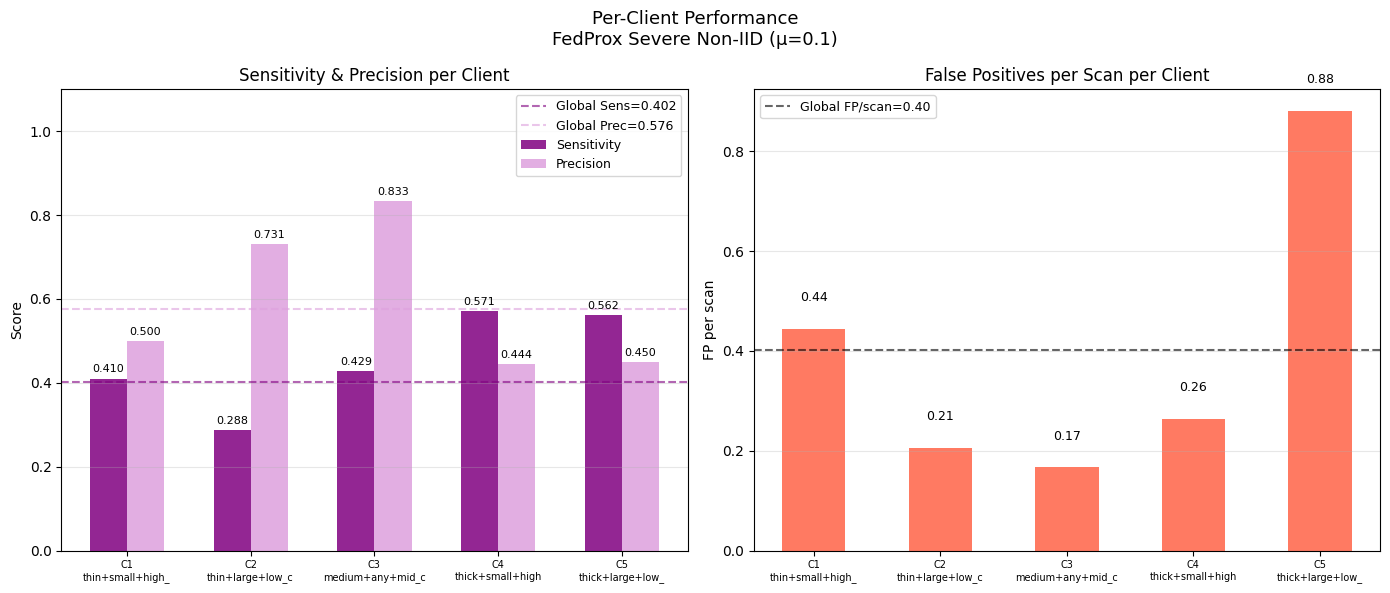


Plot saved : C:\Users\Administrator\desktop\unet\experiments\fedprox_severe\per_client_metrics_fedprox_severe.png
JSON saved : C:\Users\Administrator\desktop\unet\experiments\fedprox_severe\per_client_metrics_fedprox_severe.json


In [6]:
# PER-CLIENT EVALUATION — FEDPROX SEVERE
# Uses already-computed inference PKL
# Groups test patients by SEVERE non-IID client assignment
# No re-inference, no GPU needed
# Saves to: experiments/fedprox_severe/
# ============================================================
import pickle
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from collections import defaultdict

OUT_ROOT = Path(r"C:\Users\Administrator\desktop\unet")
EXP_DIR  = OUT_ROOT / "experiments" / "fedprox_severe"

# ── assert no overwriting ─────────────────────────────────────
out_png  = EXP_DIR / "per_client_metrics_fedprox_severe.png"
out_json = EXP_DIR / "per_client_metrics_fedprox_severe.json"
assert not out_png.exists(),  f"Would overwrite {out_png}"
assert not out_json.exists(), f"Would overwrite {out_json}"
print("✓ No existing files would be overwritten")

# ── load inference results ────────────────────────────────────
PKL_PATH = EXP_DIR / "fedprox_severe_results.pkl"
assert PKL_PATH.exists(), f"Missing: {PKL_PATH}"
with open(PKL_PATH, "rb") as f:
    all_results = pickle.load(f)
print(f"Loaded {len(all_results)} patient results")

# ── load severe test pool with by_client mapping ──────────────
test_pool_path = (OUT_ROOT / "experiments" /
                  "severe_noniid" /
                  "global_test_pids_severe.json")
assert test_pool_path.exists(), f"Missing: {test_pool_path}"
with open(test_pool_path) as f:
    global_test = json.load(f)

# build pid → client mapping
pid_to_client = {}
for cid, pids in global_test["by_client"].items():
    for pid in pids:
        pid_to_client[pid] = cid

print(f"PID→client map: {len(pid_to_client)} entries")

# ── group results by client ───────────────────────────────────
client_results = defaultdict(list)
unmapped = []
for r in all_results:
    pid = r["pid"]
    cid = pid_to_client.get(pid)
    if cid is None:
        unmapped.append(pid)
        continue
    client_results[cid].append(r)

if unmapped:
    print(f"WARNING: {len(unmapped)} pids not mapped")

EXP_NAME = "FedProx Severe Non-IID (μ=0.1)"

client_descriptions = {
    "client1": "thin+small+high_clean",
    "client2": "thin+large+low_clean",
    "client3": "medium+any+mid_clean",
    "client4": "thick+small+high_clean",
    "client5": "thick+large+low_clean",
}

# ── compute per-client metrics ────────────────────────────────
print(f"\n{'='*75}")
print(f"PER-CLIENT RESULTS — {EXP_NAME}")
print(f"{'='*75}")
print(f"{'Client':<12} {'N':>4} {'GT':>5} {'TP':>5} "
      f"{'FP':>5} {'FN':>5} {'Sens':>6} {'Prec':>6} "
      f"{'FP/scan':>8}")
print(f"{'─'*75}")

summary = {}
for cid in sorted(client_results.keys()):
    results = client_results[cid]
    ttp = sum(r["tp"] for r in results)
    tfp = sum(r["fp"] for r in results)
    tfn = sum(r["fn"] for r in results)
    tgt = sum(r["gt_nodules"] for r in results)
    ns  = len(results)
    sen = ttp / max(ttp+tfn, 1)
    pre = ttp / max(ttp+tfp, 1)
    f1  = 2*pre*sen / max(pre+sen, 1e-6)
    fps = tfp / max(ns, 1)
    print(f"{cid:<12} {ns:>4} {tgt:>5} {ttp:>5} "
          f"{tfp:>5} {tfn:>5} {sen:>6.3f} {pre:>6.3f} "
          f"{fps:>8.2f}  "
          f"← {client_descriptions.get(cid,'')}")
    summary[cid] = {
        "n_patients"       : ns,
        "total_gt"         : tgt,
        "total_tp"         : ttp,
        "total_fp"         : tfp,
        "total_fn"         : tfn,
        "sensitivity"      : round(sen, 4),
        "precision"        : round(pre, 4),
        "f1"               : round(f1,  4),
        "fp_per_scan"      : round(fps, 4),
        "description"      : client_descriptions.get(cid,''),
    }

# global
all_ttp = sum(r["tp"] for r in all_results)
all_tfp = sum(r["fp"] for r in all_results)
all_tfn = sum(r["fn"] for r in all_results)
all_gt  = sum(r["gt_nodules"] for r in all_results)
all_ns  = len(all_results)
all_sen = all_ttp / max(all_ttp+all_tfn, 1)
all_pre = all_ttp / max(all_ttp+all_tfp, 1)
all_fps = all_tfp / max(all_ns, 1)
print(f"{'─'*75}")
print(f"{'GLOBAL':<12} {all_ns:>4} {all_gt:>5} {all_ttp:>5} "
      f"{all_tfp:>5} {all_tfn:>5} {all_sen:>6.3f} "
      f"{all_pre:>6.3f} {all_fps:>8.2f}")

# ── bar chart ─────────────────────────────────────────────────
clients = sorted(summary.keys())
sens    = [summary[c]["sensitivity"] for c in clients]
precs   = [summary[c]["precision"]   for c in clients]
fps_    = [summary[c]["fp_per_scan"] for c in clients]
labels  = [c.replace("client","C")  for c in clients]
descs   = [client_descriptions.get(c,'')[:16]
           for c in clients]

x = np.arange(len(clients))
w = 0.30

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle(f"Per-Client Performance\n{EXP_NAME}",
             fontsize=13)

# sensitivity + precision
ax = axes[0]
b1 = ax.bar(x-w/2, sens,  w, label='Sensitivity',
            color='purple', alpha=0.85)
b2 = ax.bar(x+w/2, precs, w, label='Precision',
            color='plum',   alpha=0.85)
ax.axhline(all_sen, color='purple', linestyle='--',
           alpha=0.6,
           label=f'Global Sens={all_sen:.3f}')
ax.axhline(all_pre, color='plum', linestyle='--',
           alpha=0.6,
           label=f'Global Prec={all_pre:.3f}')
ax.set_xticks(x)
ax.set_xticklabels(
    [f"{l}\n{d}" for l,d in zip(labels,descs)],
    fontsize=7)
ax.set_ylim(0, 1.1)
ax.set_ylabel('Score')
ax.set_title('Sensitivity & Precision per Client')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3, axis='y')
for b in b1:
    ax.text(b.get_x()+b.get_width()/2,
            b.get_height()+0.01,
            f'{b.get_height():.3f}',
            ha='center', va='bottom', fontsize=8)
for b in b2:
    ax.text(b.get_x()+b.get_width()/2,
            b.get_height()+0.01,
            f'{b.get_height():.3f}',
            ha='center', va='bottom', fontsize=8)

# FP/scan
ax = axes[1]
bars = ax.bar(x, fps_, 0.5, color='tomato', alpha=0.85)
ax.axhline(all_fps, color='black', linestyle='--',
           alpha=0.6,
           label=f'Global FP/scan={all_fps:.2f}')
ax.set_xticks(x)
ax.set_xticklabels(
    [f"{l}\n{d}" for l,d in zip(labels,descs)],
    fontsize=7)
ax.set_ylabel('FP per scan')
ax.set_title('False Positives per Scan per Client')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3, axis='y')
for b in bars:
    ax.text(b.get_x()+b.get_width()/2,
            b.get_height()+0.05,
            f'{b.get_height():.2f}',
            ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig(out_png, dpi=100, bbox_inches='tight')
plt.show()
print(f"\nPlot saved : {out_png}")

# ── save json ─────────────────────────────────────────────────
with open(out_json, "w") as f:
    json.dump({
        "experiment"  : EXP_NAME,
        "proximal_mu" : 0.1,
        "per_client"  : summary,
        "global"      : {
            "n_patients" : all_ns,
            "total_gt"   : all_gt,
            "total_tp"   : all_ttp,
            "total_fp"   : all_tfp,
            "total_fn"   : all_tfn,
            "sensitivity": round(all_sen, 4),
            "precision"  : round(all_pre, 4),
            "fp_per_scan": round(all_fps, 4),
        }
    }, f, indent=2)
print(f"JSON saved : {out_json}")

In [7]:
import pickle
import numpy as np
from pathlib import Path
from scipy.ndimage import maximum_filter
from collections import defaultdict
import json

OUT_ROOT = Path(r"C:\Users\Administrator\desktop\unet")
OUT_EXP  = OUT_ROOT / "experiments" / "fedprox_severe"

# load saved results
with open(OUT_EXP/"fedprox_severe_results.pkl","rb") as f:
    all_results = pickle.load(f)

# load scores for threshold sweep
with open(OUT_EXP/"fedprox_severe_scores.pkl","rb") as f:
    all_scores = pickle.load(f)

# ── threshold sensitivity analysis ───────────────────────────
# all_results has tp_list and fp_list with detection scores
# we can recompute at different thresholds using all_scores

all_scores.sort(key=lambda x:x[0], reverse=True)
sa = np.array([s[0] for s in all_scores])
la = np.array([s[1] for s in all_scores])
total_gt = sum(r["gt_nodules"] for r in all_results)
ns = len(all_results)

print(f"Total GT nodules : {total_gt}")
print(f"Total patients   : {ns}")
print(f"\nThreshold sweep:")
print(f"{'Threshold':>10} {'Sens':>7} {'Prec':>7} "
      f"{'FP/scan':>9} {'CPM':>7}")
print(f"{'─'*45}")

fp_pts = [0.125,0.25,0.5,1,2,4,8]

for threshold in [0.5, 0.4, 0.3, 0.25, 0.2, 0.15, 0.1, 0.05]:
    k   = sa >= threshold
    tp  = int(la[k].sum())
    fp  = int((1-la[k]).sum())
    fn  = total_gt - tp
    sen = tp / max(tp+fn, 1)
    pre = tp / max(tp+fp, 1)
    fps = fp / max(ns, 1)

    # CPM at this threshold is a single point not a curve
    # use FROC curve to get CPM properly
    sl, fl = [], []
    for th in np.linspace(0.95, 0.01, 500):
        kk = sa >= th
        sl.append(float(la[kk].sum()/max(total_gt,1)))
        fl.append(float((1-la[kk]).sum()/max(ns,1)))
    cpm_s = [sl[np.argmin([abs(f-fp_) for f in fl])]
             for fp_ in fp_pts]
    cpm   = float(np.mean(cpm_s))

    marker = " ← current" if threshold == 0.3 else ""
    print(f"{threshold:>10.2f} {sen:>7.3f} {pre:>7.3f} "
          f"{fps:>9.2f} {cpm:>7.3f}{marker}")

print(f"\nNote: CPM is threshold-independent (uses full FROC curve)")
print(f"      Threshold only affects Sens/Prec/FP/scan operating point")

Total GT nodules : 179
Total patients   : 132

Threshold sweep:
 Threshold    Sens    Prec   FP/scan     CPM
─────────────────────────────────────────────
      0.50   0.184   0.688      0.11   0.358
      0.40   0.268   0.632      0.21   0.358
      0.30   0.402   0.576      0.40   0.358 ← current
      0.25   0.402   0.576      0.40   0.358
      0.20   0.402   0.576      0.40   0.358
      0.15   0.402   0.576      0.40   0.358
      0.10   0.402   0.576      0.40   0.358
      0.05   0.402   0.576      0.40   0.358

Note: CPM is threshold-independent (uses full FROC curve)
      Threshold only affects Sens/Prec/FP/scan operating point


FedProx severe mu 0.01 <= to run

✓ No existing files would be overwritten
✓ Monitor started (every 5s)
Device      : cuda
Experiment  : fedprox_severe
Results dir : C:\Users\Administrator\desktop\unet\experiments\fedprox_severe_mu001

Verifying severe non-IID manifests...
  Client 1: 680 train pos  95 val pos  36 test pts
  Client 2: 1485 train pos  260 val pos  34 test pts
  Client 3: 640 train pos  145 val pos  18 test pts
  Client 4: 390 train pos  80 val pos  19 test pts
  Client 5: 1025 train pos  210 val pos  25 test pts
✓ All manifests present

Loading all client data...
  Client 1: 2754 train  554 val
  Client 2: 3419 train  674 val
  Client 3: 1687 train  361 val
  Client 4: 1545 train  336 val
  Client 5: 2668 train  549 val
✓ All clients loaded (μ=0.01)

FLOWER FL — FEDPROX SEVERE NON-IID
Clients      : 5
Rounds       : 6
Local epochs : 5
Proximal mu  : 0.01
Results dir  : C:\Users\Administrator\desktop\unet\experiments\fedprox_severe_mu001



	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
INFO :      Starting Flower simulation, config: num_rounds=6, no round_timeout
2026-04-11 07:20:19,924	INFO worker.py:2012 -- Started a local Ray instance.
INFO :      Flower VCE: Ray initialized with resources: {'node:127.0.0.1': 1.0, 'GPU': 1.0, 'memory': 5592809063.0, 'node:__internal_head__': 1.0, 'object_store_memory': 2396918169.0, 'accelerator_type:A10G': 1.0, 'CPU': 4.0}
INFO :      Optimize your simulation with Flower VCE: https://flower.ai/docs/framework/how-to-run-simulations.html
INFO :      Flower VCE: Resources for each Virtual Client: {'num_cpus': 1, 'num_gpus': 1.0}
INFO :      Flow

(ClientAppActor pid=6220)     C1 R1 Ep2/5 loss=0.3841
(ClientAppActor pid=6220)     C1 R1 Ep3/5 loss=0.2778
(ClientAppActor pid=6220)     C1 R1 Ep4/5 loss=0.2333
(ClientAppActor pid=6220)     C1 R1 Ep5/5 loss=0.2160


(ClientAppActor pid=6220) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid">}. You can import the `Context` like this: `from flwr.common import Context`
(ClientAppActor pid=6220) 
(ClientAppActor pid=6220)             This is a deprecated feature. It will be removed
(ClientAppActor pid=6220)             entirely in future versions of Flower.
(ClientAppActor pid=6220)         


(ClientAppActor pid=6220)     C2 R1 Ep1/5 loss=0.6926
(ClientAppActor pid=6220)     C2 R1 Ep2/5 loss=0.4074
(ClientAppActor pid=6220)     C2 R1 Ep3/5 loss=0.3033
(ClientAppActor pid=6220)     C2 R1 Ep4/5 loss=0.2605
(ClientAppActor pid=6220)     C2 R1 Ep5/5 loss=0.2391


...

(ClientAppActor pid=6220)     C4 R6 Ep5/5 loss=0.0947


INFO :      configure_evaluate: strategy sampled 5 clients (out of 5)



  ✓ Round 6 saved: C:\Users\Administrator\desktop\unet\experiments\fedprox_severe_mu001\fl_round6_global.pt


(ClientAppActor pid=6220) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid">}. You can import the `Context` like this: `from flwr.common import Context`
(ClientAppActor pid=6220) 
(ClientAppActor pid=6220)             This is a deprecated feature. It will be removed
(ClientAppActor pid=6220)             entirely in future versions of Flower.
(ClientAppActor pid=6220)         
(ClientAppActor pid=6220) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid">}. You can import the `Context` like this: `from flwr.common import Context`
(ClientAppActor pid=6220) 
(ClientAppActor pid=6220)             This is a deprecated feature. It will be removed
(ClientAppActor pid=6220)             entirely in future versions of Flower.
(ClientAppActor pid=6220)         
(ClientA


✓ Final model: C:\Users\Administrator\desktop\unet\experiments\fedprox_severe_mu001\global_fedprox_severe_final.pt


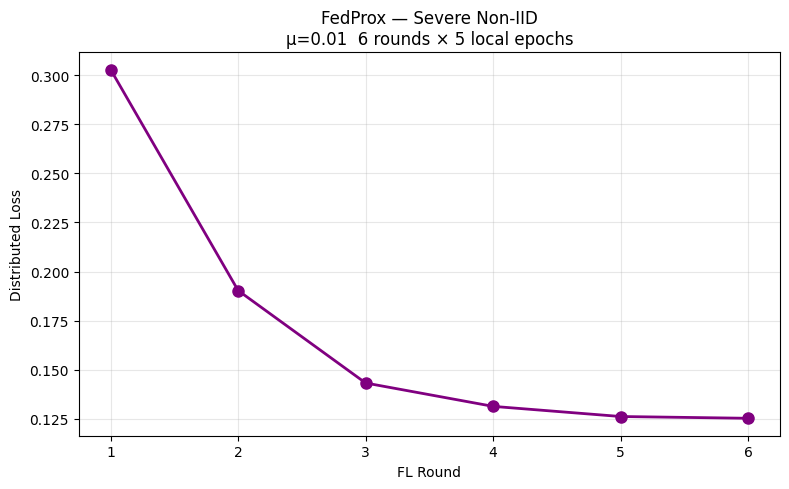


FEDPROX SEVERE COMPLETE
Model   : C:\Users\Administrator\desktop\unet\experiments\fedprox_severe_mu001\global_fedprox_severe_final.pt
History : C:\Users\Administrator\desktop\unet\experiments\fedprox_severe_mu001\fl_history_fedprox_severe.json

RESOURCE USAGE REPORT
RAM  mean=6.72GB  peak=7.99GB
VRAM mean=16.54GB  peak=16.55GB
Resource plot saved: C:\Users\Administrator\desktop\unet\experiments\fedprox_severe_mu001\resource_usage.png


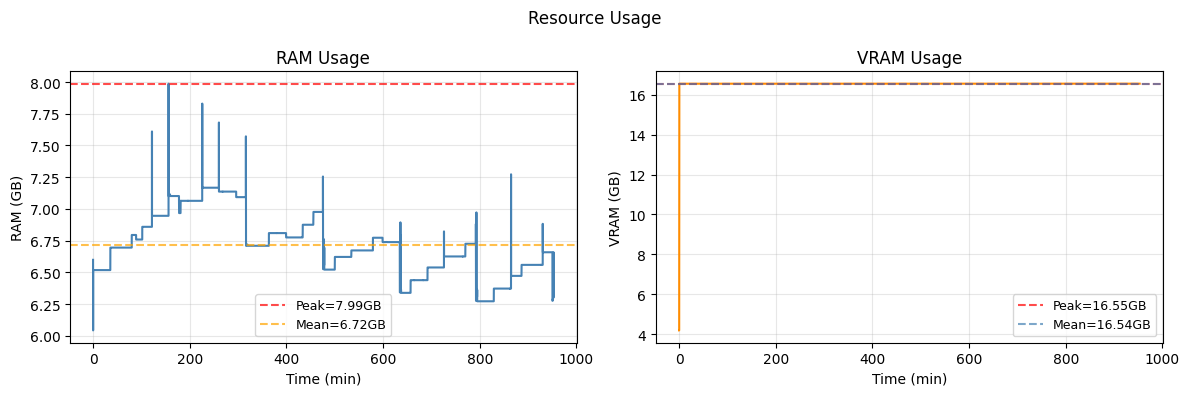

In [11]:
# CELL 7-FEDPROX-SEVERE — FedProx FL (Severe Non-IID) MU 0.01
# Uses severe_noniid split manifests
# Saves to: experiments/fedprox_severe/
# Nothing overwrites any existing results
# ============================================================
import flwr as fl
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from pathlib import Path
from flwr.server.strategy import FedAvg
from flwr.common import ndarrays_to_parameters, \
                        parameters_to_ndarrays
import numpy as np
import json
import random
import pickle
import shutil
import threading
import time
import psutil
import subprocess

class ResourceMonitor:
    def __init__(self, interval=5):
        self.interval=interval; self.ram_usage=[]
        self.vram_usage=[]; self.running=False
        self._thread=None
    def _monitor(self):
        while self.running:
            ram=psutil.Process().memory_info().rss/1e9
            self.ram_usage.append(ram)
            try:
                r=subprocess.run(
                    ["nvidia-smi","--query-gpu=memory.used",
                     "--format=csv,noheader,nounits"],
                    capture_output=True,text=True)
                self.vram_usage.append(
                    float(r.stdout.strip())/1024)
            except: pass
            time.sleep(self.interval)
    def start(self):
        self.running=True
        self._thread=threading.Thread(
            target=self._monitor,daemon=True)
        self._thread.start()
        print(f"✓ Monitor started (every {self.interval}s)")
    def stop(self):
        self.running=False
        if self._thread: self._thread.join(timeout=10)
    def report(self):
        print(f"\n{'='*50}\nRESOURCE USAGE REPORT\n{'='*50}")
        if self.ram_usage:
            print(f"RAM  mean={np.mean(self.ram_usage):.2f}GB  "
                  f"peak={max(self.ram_usage):.2f}GB")
        if self.vram_usage:
            print(f"VRAM mean={np.mean(self.vram_usage):.2f}GB  "
                  f"peak={max(self.vram_usage):.2f}GB")
    def plot(self, save_path=None):
        if not self.ram_usage and not self.vram_usage: return
        import matplotlib.pyplot as plt
        fig,axes=plt.subplots(1,2,figsize=(12,4))
        fig.suptitle("Resource Usage",fontsize=12)
        if self.ram_usage:
            t=[i*self.interval/60 for i in range(len(self.ram_usage))]
            axes[0].plot(t,self.ram_usage,color='steelblue',linewidth=1.5)
            axes[0].axhline(max(self.ram_usage),color='red',
                linestyle='--',alpha=0.7,
                label=f'Peak={max(self.ram_usage):.2f}GB')
            axes[0].axhline(np.mean(self.ram_usage),color='orange',
                linestyle='--',alpha=0.7,
                label=f'Mean={np.mean(self.ram_usage):.2f}GB')
            axes[0].set_xlabel('Time (min)'); axes[0].set_ylabel('RAM (GB)')
            axes[0].set_title('RAM Usage'); axes[0].legend(fontsize=9)
            axes[0].grid(True,alpha=0.3)
        if self.vram_usage:
            t=[i*self.interval/60 for i in range(len(self.vram_usage))]
            axes[1].plot(t,self.vram_usage,color='darkorange',linewidth=1.5)
            axes[1].axhline(max(self.vram_usage),color='red',
                linestyle='--',alpha=0.7,
                label=f'Peak={max(self.vram_usage):.2f}GB')
            axes[1].axhline(np.mean(self.vram_usage),color='steelblue',
                linestyle='--',alpha=0.7,
                label=f'Mean={np.mean(self.vram_usage):.2f}GB')
            axes[1].set_xlabel('Time (min)'); axes[1].set_ylabel('VRAM (GB)')
            axes[1].set_title('VRAM Usage'); axes[1].legend(fontsize=9)
            axes[1].grid(True,alpha=0.3)
        plt.tight_layout()
        if save_path:
            plt.savefig(save_path,dpi=100,bbox_inches='tight')
            print(f"Resource plot saved: {save_path}")
        plt.show()

OUT_ROOT   = Path(r"C:\Users\Administrator\desktop\unet")
EXP_DIR    = OUT_ROOT / "experiments" / "severe_noniid"
OUT_EXP = OUT_ROOT / "experiments" / "fedprox_severe_mu001"
OUT_EXP.mkdir(parents=True, exist_ok=True)

# ── assert no overwriting ─────────────────────────────────────
files_that_would_be_written = [
    OUT_EXP / f"fl_round{r}_global.pt" for r in range(1,7)
] + [
    OUT_EXP / "global_fedprox_severe_final.pt",
    OUT_EXP / "fl_history_fedprox_severe.json",
    OUT_EXP / "fl_loss_fedprox_severe.png",
    OUT_EXP / "resource_usage.png",
]
for f in files_that_would_be_written:
    assert not f.exists(), \
        f"Would overwrite {f} — delete it first"
print("✓ No existing files would be overwritten")

monitor = ResourceMonitor(interval=5)
monitor.start()

DEVICE       = 'cuda' if torch.cuda.is_available() else 'cpu'
NUM_ROUNDS   = 6
LOCAL_EPOCHS = 5
BATCH_SIZE   = 4
LR           = 1e-4
BASE_FILTERS = 32
PROXIMAL_MU  = 0.01

print(f"Device      : {DEVICE}")
print(f"Experiment  : fedprox_severe")
print(f"Results dir : {OUT_EXP}")

# ── UNet ─────────────────────────────────────────────────────
class DoubleConv3D(nn.Module):
    def __init__(self,in_ch,out_ch):
        super().__init__()
        self.block=nn.Sequential(
            nn.Conv3d(in_ch,out_ch,3,padding=1,bias=False),
            nn.BatchNorm3d(out_ch),nn.ReLU(inplace=True),
            nn.Conv3d(out_ch,out_ch,3,padding=1,bias=False),
            nn.BatchNorm3d(out_ch),nn.ReLU(inplace=True))
    def forward(self,x): return self.block(x)

class Down(nn.Module):
    def __init__(self,c1,c2):
        super().__init__()
        self.pool=nn.MaxPool3d(2); self.conv=DoubleConv3D(c1,c2)
    def forward(self,x): return self.conv(self.pool(x))

class Up(nn.Module):
    def __init__(self,c1,c2):
        super().__init__()
        self.up=nn.ConvTranspose3d(c1,c2,2,stride=2)
        self.conv=DoubleConv3D(c1,c2)
    def forward(self,x,skip):
        return self.conv(torch.cat([skip,self.up(x)],dim=1))

class UNet3D(nn.Module):
    def __init__(self,base_filters=32):
        super().__init__()
        f=base_filters
        self.enc1=DoubleConv3D(1,f); self.enc2=Down(f,f*2)
        self.enc3=Down(f*2,f*4);     self.enc4=Down(f*4,f*8)
        self.bottleneck=Down(f*8,f*16)
        self.dec4=Up(f*16,f*8); self.dec3=Up(f*8,f*4)
        self.dec2=Up(f*4,f*2);  self.dec1=Up(f*2,f)
        self.head=nn.Conv3d(f,1,1)
    def forward(self,x):
        e1=self.enc1(x); e2=self.enc2(e1)
        e3=self.enc3(e2); e4=self.enc4(e3)
        b=self.bottleneck(e4)
        return torch.sigmoid(self.head(
            self.dec1(self.dec2(self.dec3(
                self.dec4(b,e4),e3),e2),e1)))

class OHEMLoss(nn.Module):
    def __init__(self,neg_pos_ratio=3,min_negatives=1000):
        super().__init__()
        self.npr=neg_pos_ratio; self.mnn=min_negatives
    def forward(self,pred,target):
        loss=0.0
        for i in range(pred.shape[0]):
            p=pred[i,0]; t=target[i,0]
            pm=t>0.01; nm=~pm
            pl=F.binary_cross_entropy(
                p[pm],t[pm],reduction='mean'
            ) if pm.sum()>0 else torch.tensor(
                0.0,device=pred.device)
            n_neg=min(int(nm.sum()),
                      max(self.mnn,int(pm.sum())*self.npr))
            nl=F.binary_cross_entropy(
                p[nm],torch.zeros(nm.sum(),device=pred.device),
                reduction='none').topk(n_neg).values.mean()
            loss+=pl+nl
        return loss/pred.shape[0]

class PatchDataset(Dataset):
    def __init__(self,pos_files,neg_files,augment=False):
        self.augment=augment
        self.items=([(str(f),1) for f in pos_files]+
                    [(str(f),0) for f in neg_files])
        random.shuffle(self.items)
    def __len__(self): return len(self.items)
    def __getitem__(self,idx):
        path,_=self.items[idx]; d=np.load(path)
        vol=d['vol'].astype(np.float32)
        heat=d['heatmap'].astype(np.float32)
        if self.augment:
            for ax in range(3):
                if random.random()>0.5:
                    vol=np.flip(vol,axis=ax).copy()
                    heat=np.flip(heat,axis=ax).copy()
            k=random.randint(0,3)
            vol=np.rot90(vol,k=k,axes=(1,2)).copy()
            heat=np.rot90(heat,k=k,axes=(1,2)).copy()
        return (torch.from_numpy(vol).unsqueeze(0),
                torch.from_numpy(heat).unsqueeze(0))

# ── verify severe manifests ───────────────────────────────────
print("\nVerifying severe non-IID manifests...")
for cid in [1,2,3,4,5]:
    mp = EXP_DIR / f"client{cid}_split_manifest.json"
    assert mp.exists(), f"Missing: {mp}"
    with open(mp) as f: m=json.load(f)
    print(f"  Client {cid}: {len(m['train_pos'])} train pos  "
          f"{len(m['val_pos'])} val pos  "
          f"{len(m['tst_pids'])} test pts")
print("✓ All manifests present\n")

# ── pre-load all clients ──────────────────────────────────────
print("Loading all client data...")
clients = {}

for cid in [1,2,3,4,5]:
    with open(EXP_DIR/f"client{cid}_split_manifest.json") as f:
        manifest=json.load(f)
    train_pos=[Path(p) for p in manifest["train_pos"]]
    train_neg=[Path(p) for p in manifest["train_neg"]]
    val_pos  =[Path(p) for p in manifest["val_pos"]]
    val_neg  =[Path(p) for p in manifest["val_neg"]]
    train_ds=PatchDataset(train_pos,train_neg,augment=True)
    val_ds  =PatchDataset(val_pos,  val_neg,  augment=False)
    train_loader=DataLoader(train_ds,batch_size=BATCH_SIZE,
        shuffle=True,num_workers=0,pin_memory=True)
    val_loader  =DataLoader(val_ds,  batch_size=BATCH_SIZE,
        shuffle=False,num_workers=0,pin_memory=True)
    model    =UNet3D(base_filters=BASE_FILTERS).to(DEVICE)
    criterion=OHEMLoss(neg_pos_ratio=3,min_negatives=1000)

    class FedProxClient(fl.client.NumPyClient):
        def __init__(self,cid,model,train_loader,
                     val_loader,criterion,device,mu):
            self.cid=cid; self.model=model
            self.train_loader=train_loader
            self.val_loader=val_loader
            self.criterion=criterion
            self.device=device; self.mu=mu
            self.global_params=None
        def get_parameters(self,config):
            return [v.cpu().numpy()
                    for v in self.model.state_dict().values()]
        def set_parameters(self,parameters):
            state_dict=dict(zip(
                self.model.state_dict().keys(),
                [torch.tensor(p) for p in parameters]))
            self.model.load_state_dict(state_dict,strict=True)
            self.global_params=[
                p.clone().detach()
                for p in self.model.parameters()]
        def fit(self,parameters,config):
            self.set_parameters(parameters)
            local_epochs=config.get("local_epochs",LOCAL_EPOCHS)
            round_num   =config.get("round_num",0)
            optimizer=torch.optim.Adam(
                self.model.parameters(),lr=LR)
            from torch.optim.lr_scheduler import CosineAnnealingLR
            scheduler=CosineAnnealingLR(
                optimizer,T_max=local_epochs)
            self.model.train()
            total_loss=0.0
            n_batches=len(self.train_loader)
            for epoch in range(local_epochs):
                ep_loss=0.0
                for vol,heat in self.train_loader:
                    vol=vol.to(self.device)
                    heat=heat.to(self.device)
                    optimizer.zero_grad()
                    task_loss=self.criterion(
                        self.model(vol),heat)
                    prox_term=0.0
                    for lp,gp in zip(
                        self.model.parameters(),
                        self.global_params):
                        prox_term+=(
                            lp-gp.to(self.device)
                        ).norm(2)**2
                    loss=task_loss+(self.mu/2)*prox_term
                    loss.backward(); optimizer.step()
                    ep_loss+=task_loss.item()
                scheduler.step()
                avg=ep_loss/max(n_batches,1)
                total_loss+=avg
                print(f"    C{self.cid} R{round_num} "
                      f"Ep{epoch+1}/{local_epochs} "
                      f"loss={avg:.4f}",flush=True)
            avg_loss=total_loss/max(local_epochs,1)
            n_samples=len(self.train_loader.dataset)
            return (self.get_parameters(config={}),
                    n_samples,
                    {"train_loss":float(avg_loss),
                     "client_id":self.cid})
        def evaluate(self,parameters,config):
            self.set_parameters(parameters)
            self.model.eval(); val_loss=0.0
            n_samples=len(self.val_loader.dataset)
            with torch.no_grad():
                for vol,heat in self.val_loader:
                    val_loss+=self.criterion(
                        self.model(vol.to(self.device)),
                        heat.to(self.device)).item()
            avg_val=val_loss/max(len(self.val_loader),1)
            return (float(avg_val),n_samples,
                    {"val_loss":float(avg_val),
                     "client_id":self.cid})

    clients[cid]=FedProxClient(
        cid,model,train_loader,val_loader,
        criterion,DEVICE,PROXIMAL_MU)
    print(f"  Client {cid}: {len(train_ds)} train  "
          f"{len(val_ds)} val")

print(f"✓ All clients loaded (μ={PROXIMAL_MU})\n")

def client_fn(cid):
    return clients[int(cid)+1].to_client()

round_weights={}

class SaveRoundStrategy(FedAvg):
    def aggregate_fit(self,server_round,results,failures):
        aggregated=super().aggregate_fit(
            server_round,results,failures)
        if aggregated is not None:
            params,_=aggregated
            ndarrays=parameters_to_ndarrays(params)
            model_keys=list(UNet3D(
                base_filters=BASE_FILTERS).state_dict().keys())
            state_dict=dict(zip(model_keys,
                [torch.tensor(p) for p in ndarrays]))
            save_path=OUT_EXP/f"fl_round{server_round}_global.pt"
            torch.save(state_dict,save_path)
            print(f"\n  ✓ Round {server_round} saved: {save_path}")
            round_weights[server_round]=save_path
        return aggregated

init_model =UNet3D(base_filters=BASE_FILTERS)
init_params=ndarrays_to_parameters(
    [v.cpu().numpy()
     for v in init_model.state_dict().values()])

strategy=SaveRoundStrategy(
    fraction_fit=1.0, fraction_evaluate=1.0,
    min_fit_clients=5, min_evaluate_clients=5,
    min_available_clients=5,
    initial_parameters=init_params,
    on_fit_config_fn=lambda r:{
        "local_epochs":LOCAL_EPOCHS,"round_num":r},)

print(f"{'='*55}")
print(f"FLOWER FL — FEDPROX SEVERE NON-IID")
print(f"{'='*55}")
print(f"Clients      : 5")
print(f"Rounds       : {NUM_ROUNDS}")
print(f"Local epochs : {LOCAL_EPOCHS}")
print(f"Proximal mu  : {PROXIMAL_MU}")
print(f"Results dir  : {OUT_EXP}")
print(f"{'='*55}\n")

history=fl.simulation.start_simulation(
    client_fn=client_fn,
    num_clients=5,
    config=fl.server.ServerConfig(num_rounds=NUM_ROUNDS),
    strategy=strategy,
    client_resources={"num_cpus":1,"num_gpus":1.0},)

final_path=round_weights.get(NUM_ROUNDS)
if final_path and final_path.exists():
    GLOBAL_PT=OUT_EXP/"global_fedprox_severe_final.pt"
    shutil.copy(final_path,GLOBAL_PT)
    print(f"\n✓ Final model: {GLOBAL_PT}")

fl_history={
    "experiment"        :"fedprox_severe",
    "proximal_mu"       :PROXIMAL_MU,
    "num_rounds"        :NUM_ROUNDS,
    "local_epochs"      :LOCAL_EPOCHS,
    "losses_distributed":[[r,float(l)]
        for r,l in history.losses_distributed],}
with open(OUT_EXP/"fl_history_fedprox_severe.json","w") as f:
    json.dump(fl_history,f,indent=2)

import matplotlib.pyplot as plt
if history.losses_distributed:
    rounds=[r for r,l in history.losses_distributed]
    losses=[l for r,l in history.losses_distributed]
    fig,ax=plt.subplots(figsize=(8,5))
    ax.plot(rounds,losses,'o-',color='purple',
            linewidth=2,markersize=8)
    ax.set_xlabel('FL Round'); ax.set_ylabel('Distributed Loss')
    ax.set_title(f'FedProx — Severe Non-IID\n'
                 f'μ={PROXIMAL_MU}  {NUM_ROUNDS} rounds × '
                 f'{LOCAL_EPOCHS} local epochs')
    ax.grid(True,alpha=0.3); plt.tight_layout()
    plt.savefig(OUT_EXP/"fl_loss_fedprox_severe.png",dpi=100)
    plt.show()

print(f"\n{'='*55}")
print(f"FEDPROX SEVERE COMPLETE")
print(f"{'='*55}")
print(f"Model   : {OUT_EXP/'global_fedprox_severe_final.pt'}")
print(f"History : {OUT_EXP/'fl_history_fedprox_severe.json'}")
monitor.stop()
monitor.report()
monitor.plot(save_path=OUT_EXP/"resource_usage.png")

Device: cuda
✓ No existing files would be overwritten
✓ Monitor started (every 5s)
Model loaded: C:\Users\Administrator\desktop\unet\experiments\fedprox_severe_mu001\global_fedprox_severe_final.pt
Test patients: 132


FedProx severe μ=0.01 inference:   1%|▎                                              | 1/132 [00:28<1:03:15, 28.97s/it]

  LIDC-IDRI-0006: GT= 1 TP= 1 FP= 15 FN= 0


FedProx severe μ=0.01 inference:   2%|▋                                                | 2/132 [00:50<53:49, 24.84s/it]

  LIDC-IDRI-0015: GT= 1 TP= 1 FP=  1 FN= 0


...

  LIDC-IDRI-0952: GT= 0 TP= 0 FP=  0 FN= 0


FedProx severe μ=0.01 inference:  99%|████████████████████████████████████████████▋| 131/132 [1:20:48<00:35, 35.91s/it]

  LIDC-IDRI-0975: GT= 0 TP= 0 FP=  0 FN= 0


FedProx severe μ=0.01 inference: 100%|█████████████████████████████████████████████| 132/132 [1:21:06<00:00, 36.87s/it]

  LIDC-IDRI-0988: GT= 0 TP= 0 FP=  0 FN= 0

✓ Results saved

FEDPROX SEVERE μ=0.01 RESULTS
GT=179  TP=140  FP=280  FN=39
Sensitivity : 0.782
Precision   : 0.333
F1          : 0.467
FP/scan     : 2.12

CPM (FedProx severe μ=0.01): 0.636
  0.125 FP/scan → 0.380
  0.250 FP/scan → 0.475
  0.500 FP/scan → 0.587
  1.000 FP/scan → 0.676
  2.000 FP/scan → 0.771
  4.000 FP/scan → 0.782
  8.000 FP/scan → 0.782


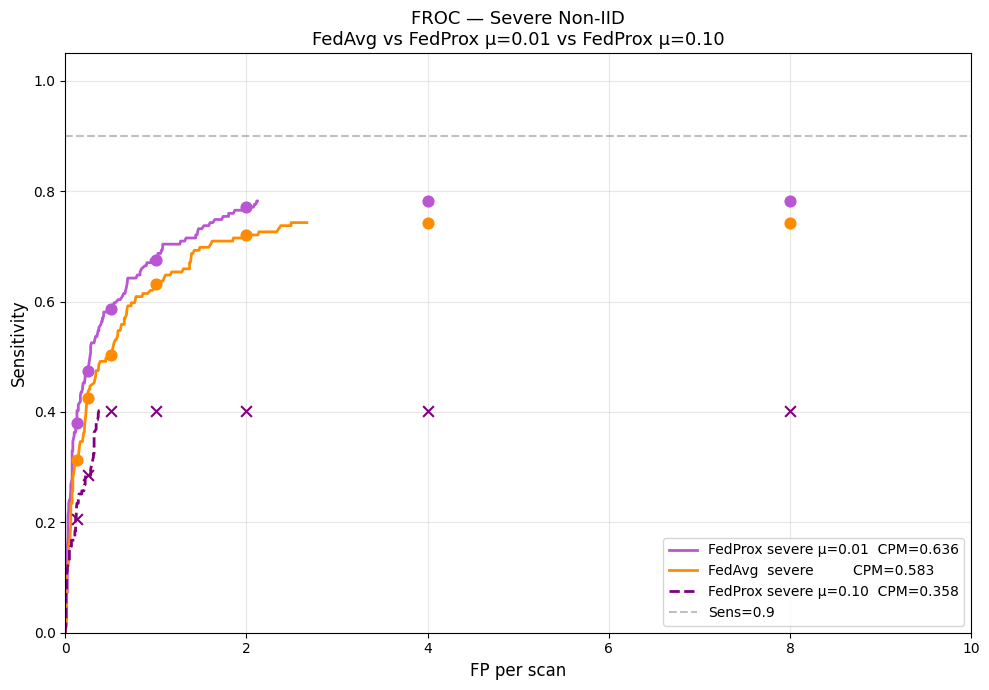


PER-CLIENT RESULTS — FedProx Severe μ=0.01
Client          N    GT    TP    FP    FN   Sens   Prec  FP/scan
───────────────────────────────────────────────────────────────────────────
client1        36    39    26    81    13  0.667  0.243     2.25  ← thin+small+high_clean
client2        34    66    51    67    15  0.773  0.432     1.97  ← thin+large+low_clean
client3        18    35    26    36     9  0.743  0.419     2.00  ← medium+any+mid_clean
client4        19     7     6    24     1  0.857  0.200     1.26  ← thick+small+high_clean
client5        25    32    31    72     1  0.969  0.301     2.88  ← thick+large+low_clean
───────────────────────────────────────────────────────────────────────────
GLOBAL        132   179   140   280    39  0.782  0.333     2.12


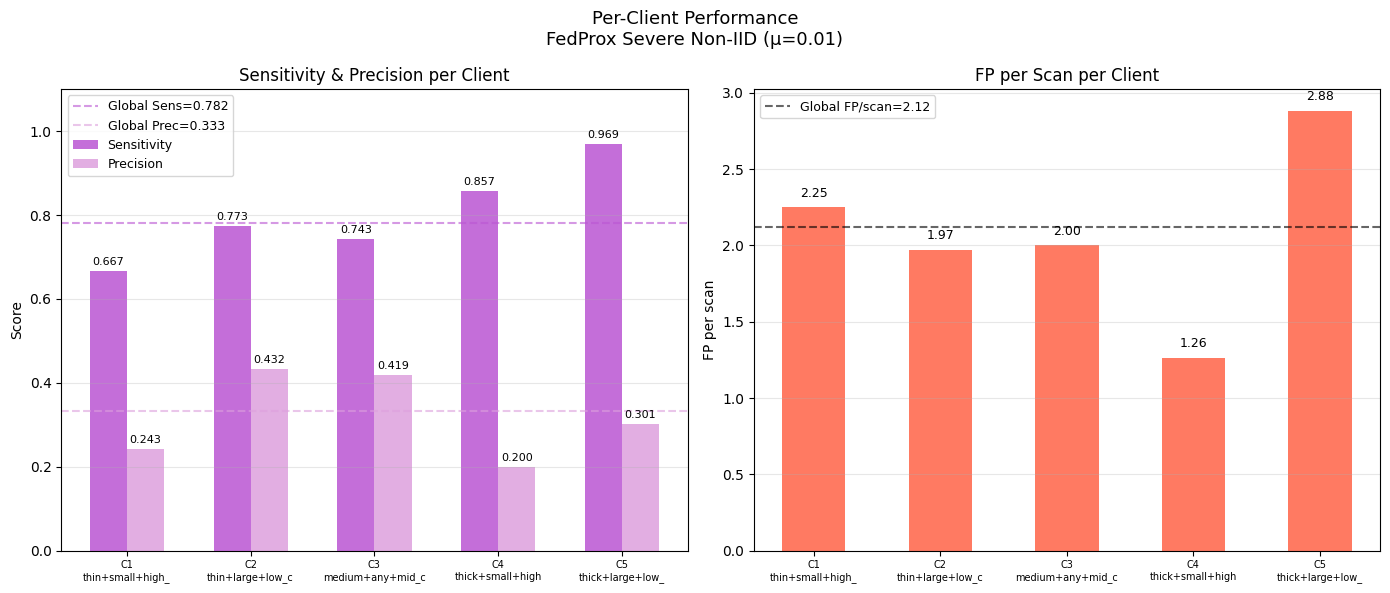


OUTPUT FILES (nothing overwritten)
  experiments/fedprox_severe_mu001/
  ├── fedprox_severe_mu001_results.pkl
  ├── fedprox_severe_mu001_scores.pkl
  ├── fedprox_severe_mu001_test_results.json
  ├── froc_fedprox_severe_mu001.png
  ├── per_client_metrics_fedprox_severe_mu001.png
  ├── per_client_metrics_fedprox_severe_mu001.json
  └── resource_usage_inference.png

RESOURCE USAGE REPORT
RAM  mean=5.98GB  peak=6.39GB
VRAM mean=7.84GB  peak=16.55GB
Resource plot saved: C:\Users\Administrator\desktop\unet\experiments\fedprox_severe_mu001\resource_usage_inference.png


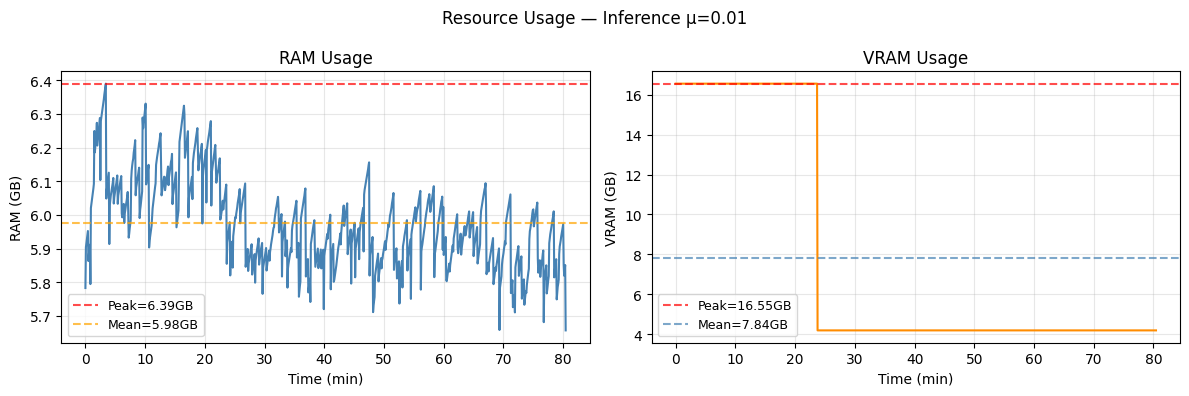

In [13]:
# CELL 8-FEDPROX-SEVERE-MU001 — Evaluation + Per-Client
# Evaluates global_fedprox_severe_mu001_final.pt
# on severe non-IID test pool (132 patients)
# Saves to: experiments/fedprox_severe_mu001/
# Nothing overwritten anywhere
# ============================================================
import torch
import torch.nn as nn
import numpy as np
import json
import pickle
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.ndimage import maximum_filter
from tqdm import tqdm
from collections import defaultdict
import warnings
warnings.filterwarnings('ignore')
import threading, time, psutil, subprocess

class ResourceMonitor:
    def __init__(self,interval=5):
        self.interval=interval; self.ram_usage=[]
        self.vram_usage=[]; self.running=False
        self._thread=None
    def _monitor(self):
        while self.running:
            self.ram_usage.append(
                psutil.Process().memory_info().rss/1e9)
            try:
                r=subprocess.run(
                    ["nvidia-smi","--query-gpu=memory.used",
                     "--format=csv,noheader,nounits"],
                    capture_output=True,text=True)
                self.vram_usage.append(
                    float(r.stdout.strip())/1024)
            except: pass
            time.sleep(self.interval)
    def start(self):
        self.running=True
        self._thread=threading.Thread(
            target=self._monitor,daemon=True)
        self._thread.start()
        print(f"✓ Monitor started (every {self.interval}s)")
    def stop(self):
        self.running=False
        if self._thread: self._thread.join(timeout=10)
    def report(self):
        print(f"\n{'='*50}\nRESOURCE USAGE REPORT\n{'='*50}")
        if self.ram_usage:
            print(f"RAM  mean={np.mean(self.ram_usage):.2f}GB  "
                  f"peak={max(self.ram_usage):.2f}GB")
        if self.vram_usage:
            print(f"VRAM mean={np.mean(self.vram_usage):.2f}GB  "
                  f"peak={max(self.vram_usage):.2f}GB")
    def plot(self,save_path=None):
        if not self.ram_usage and not self.vram_usage: return
        fig,axes=plt.subplots(1,2,figsize=(12,4))
        fig.suptitle("Resource Usage — Inference μ=0.01",
                     fontsize=12)
        if self.ram_usage:
            t=[i*self.interval/60
               for i in range(len(self.ram_usage))]
            axes[0].plot(t,self.ram_usage,
                         color='steelblue',linewidth=1.5)
            axes[0].axhline(max(self.ram_usage),color='red',
                linestyle='--',alpha=0.7,
                label=f'Peak={max(self.ram_usage):.2f}GB')
            axes[0].axhline(np.mean(self.ram_usage),
                color='orange',linestyle='--',alpha=0.7,
                label=f'Mean={np.mean(self.ram_usage):.2f}GB')
            axes[0].set_xlabel('Time (min)')
            axes[0].set_ylabel('RAM (GB)')
            axes[0].set_title('RAM Usage')
            axes[0].legend(fontsize=9)
            axes[0].grid(True,alpha=0.3)
        if self.vram_usage:
            t=[i*self.interval/60
               for i in range(len(self.vram_usage))]
            axes[1].plot(t,self.vram_usage,
                         color='darkorange',linewidth=1.5)
            axes[1].axhline(max(self.vram_usage),color='red',
                linestyle='--',alpha=0.7,
                label=f'Peak={max(self.vram_usage):.2f}GB')
            axes[1].axhline(np.mean(self.vram_usage),
                color='steelblue',linestyle='--',alpha=0.7,
                label=f'Mean={np.mean(self.vram_usage):.2f}GB')
            axes[1].set_xlabel('Time (min)')
            axes[1].set_ylabel('VRAM (GB)')
            axes[1].set_title('VRAM Usage')
            axes[1].legend(fontsize=9)
            axes[1].grid(True,alpha=0.3)
        plt.tight_layout()
        if save_path:
            plt.savefig(save_path,dpi=100,bbox_inches='tight')
            print(f"Resource plot saved: {save_path}")
        plt.show()

OUT_ROOT   = Path(r"C:\Users\Administrator\desktop\unet")
SEVERE_DIR = OUT_ROOT / "experiments" / "severe_noniid"
OUT_EXP    = OUT_ROOT / "experiments" / "fedprox_severe_mu001"
GLOBAL_PT  = OUT_EXP  / "global_fedprox_severe_final.pt"

DEVICE       = 'cuda' if torch.cuda.is_available() else 'cpu'
PATCH_SIZE   = 96
STRIDE       = 20
THRESHOLD    = 0.3
BASE_FILTERS = 32
PROXIMAL_MU  = 0.01

print(f"Device: {DEVICE}")

# ── assert no overwriting ─────────────────────────────────────
files_that_would_be_written = [
    OUT_EXP / "fedprox_severe_mu001_results.pkl",
    OUT_EXP / "fedprox_severe_mu001_scores.pkl",
    OUT_EXP / "fedprox_severe_mu001_test_results.json",
    OUT_EXP / "froc_fedprox_severe_mu001.png",
    OUT_EXP / "per_client_metrics_fedprox_severe_mu001.png",
    OUT_EXP / "per_client_metrics_fedprox_severe_mu001.json",
    OUT_EXP / "resource_usage_inference.png",
]
for f in files_that_would_be_written:
    assert not f.exists(), \
        f"Would overwrite {f} — delete it first"
print("✓ No existing files would be overwritten")

monitor = ResourceMonitor(interval=5)
monitor.start()

# ── UNet ─────────────────────────────────────────────────────
class DoubleConv3D(nn.Module):
    def __init__(self,in_ch,out_ch):
        super().__init__()
        self.block=nn.Sequential(
            nn.Conv3d(in_ch,out_ch,3,padding=1,bias=False),
            nn.BatchNorm3d(out_ch),nn.ReLU(inplace=True),
            nn.Conv3d(out_ch,out_ch,3,padding=1,bias=False),
            nn.BatchNorm3d(out_ch),nn.ReLU(inplace=True))
    def forward(self,x): return self.block(x)
class Down(nn.Module):
    def __init__(self,c1,c2):
        super().__init__()
        self.pool=nn.MaxPool3d(2)
        self.conv=DoubleConv3D(c1,c2)
    def forward(self,x): return self.conv(self.pool(x))
class Up(nn.Module):
    def __init__(self,c1,c2):
        super().__init__()
        self.up=nn.ConvTranspose3d(c1,c2,2,stride=2)
        self.conv=DoubleConv3D(c1,c2)
    def forward(self,x,skip):
        return self.conv(torch.cat([skip,self.up(x)],dim=1))
class UNet3D(nn.Module):
    def __init__(self,base_filters=32):
        super().__init__()
        f=base_filters
        self.enc1=DoubleConv3D(1,f); self.enc2=Down(f,f*2)
        self.enc3=Down(f*2,f*4);     self.enc4=Down(f*4,f*8)
        self.bottleneck=Down(f*8,f*16)
        self.dec4=Up(f*16,f*8); self.dec3=Up(f*8,f*4)
        self.dec2=Up(f*4,f*2);  self.dec1=Up(f*2,f)
        self.head=nn.Conv3d(f,1,1)
    def forward(self,x):
        e1=self.enc1(x); e2=self.enc2(e1)
        e3=self.enc3(e2); e4=self.enc4(e3)
        b=self.bottleneck(e4)
        return torch.sigmoid(self.head(
            self.dec1(self.dec2(self.dec3(
                self.dec4(b,e4),e3),e2),e1)))

# ── load model ────────────────────────────────────────────────
assert GLOBAL_PT.exists(), f"Model not found: {GLOBAL_PT}"
model=UNet3D(base_filters=BASE_FILTERS).to(DEVICE)
model.load_state_dict(torch.load(
    GLOBAL_PT,map_location=DEVICE))
model.eval()
print(f"Model loaded: {GLOBAL_PT}")

# ── load severe test pool ─────────────────────────────────────
with open(SEVERE_DIR/"global_test_pids_severe.json") as f:
    global_test=json.load(f)
all_test_pids=global_test["test_pids"]
pid_to_client={}
for cid,pids in global_test["by_client"].items():
    for pid in pids:
        pid_to_client[pid]=cid
print(f"Test patients: {len(all_test_pids)}")

# ── path routing ──────────────────────────────────────────────
with open(OUT_ROOT/"federation_splits.json") as f:
    orig_splits=json.load(f)

def get_patient_dirs(pid):
    if pid in orig_splits["client1_pids"]:
        return (OUT_ROOT/"preprocessed",
                OUT_ROOT/"lung_masks",
                OUT_ROOT/"annotations")
    for cid in [2,3,4,5]:
        if pid in orig_splits.get(f"client{cid}_pids",[]):
            cd=OUT_ROOT/f"client{cid}"
            return (cd/"preprocessed",
                    cd/"lung_masks",
                    cd/"annotations")
    raise ValueError(f"{pid} not found")

# ── inference functions ───────────────────────────────────────
def sliding_window_max(model,vol,mask,
                        patch_size,stride,device):
    D,H,W=vol.shape; p=patch_size
    heatmap=np.zeros((D,H,W),dtype=np.float32)
    coords=np.argwhere(mask>0)
    if len(coords)==0: return heatmap
    z1=max(0,coords[:,0].min()-p//4)
    y1=max(0,coords[:,1].min()-p//4)
    x1=max(0,coords[:,2].min()-p//4)
    z2=min(D,coords[:,0].max()+p//4)
    y2=min(H,coords[:,1].max()+p//4)
    x2=min(W,coords[:,2].max()+p//4)
    model.eval()
    with torch.no_grad():
        for zw in range(z1,z2-p+1,stride):
            for yw in range(y1,y2-p+1,stride):
                for xw in range(x1,x2-p+1,stride):
                    patch=vol[zw:zw+p,yw:yw+p,xw:xw+p]
                    if patch.shape!=(p,p,p): continue
                    if mask[zw:zw+p,yw:yw+p,
                            xw:xw+p].mean()<0.05: continue
                    t=torch.from_numpy(patch).unsqueeze(0)\
                          .unsqueeze(0).float().to(device)
                    pred=model(t).squeeze().cpu().numpy()
                    heatmap[zw:zw+p,yw:yw+p,xw:xw+p]=\
                        np.maximum(
                            heatmap[zw:zw+p,yw:yw+p,xw:xw+p],
                            pred)
    return heatmap

def get_detections(heatmap,threshold=0.3,min_dist=6):
    lm=maximum_filter(
        heatmap,footprint=np.ones((min_dist,)*3))==heatmap
    lm=lm&(heatmap>threshold)
    c=np.argwhere(lm)
    if len(c)==0: return []
    s=heatmap[lm]; o=np.argsort(s)[::-1]
    return [(int(c[i,0]),int(c[i,1]),
             int(c[i,2]),float(s[i])) for i in o]

def match_gt(detections,gt_nodules):
    matched=set(); tp,fp=[],[]
    for det in detections:
        dz,dy,dx,sc=det; bd,bi=float('inf'),-1
        for gi,nod in enumerate(gt_nodules):
            if gi in matched: continue
            gz,gy,gx=nod['center_res']
            d=np.sqrt((dz-gz)**2+(dy-gy)**2+(dx-gx)**2)
            if d<max(nod['radius_mm'],10.0) and d<bd:
                bd,bi=d,gi
        if bi>=0:
            tp.append({'det':det,'gt':gt_nodules[bi],
                       'dist_mm':bd}); matched.add(bi)
        else: fp.append({'det':det})
    fn=[{'gt':n} for gi,n in enumerate(gt_nodules)
        if gi not in matched]
    return tp,fp,fn

# ── run inference ─────────────────────────────────────────────
all_results=[]; all_scores=[]; total_gt=0; missing=[]

for pid in tqdm(all_test_pids,
                desc="FedProx severe μ=0.01 inference"):
    try: pd_dir,md_dir,ad_dir=get_patient_dirs(pid)
    except ValueError:
        missing.append(pid); continue
    vp=pd_dir/f"{pid}.npy"; mp=md_dir/f"{pid}.npy"
    ap=ad_dir/f"{pid}.json"
    if not (vp.exists() and mp.exists() and ap.exists()):
        missing.append(pid); continue
    vol=np.load(vp); mask=np.load(mp)
    with open(ap) as f:
        gt_nods=json.load(f)["consensus_nodules"]
    total_gt+=len(gt_nods)
    heatmap   =sliding_window_max(
        model,vol,mask,PATCH_SIZE,STRIDE,DEVICE)
    detections=get_detections(heatmap,THRESHOLD)
    tp,fp,fn  =match_gt(detections,gt_nods)
    all_results.append({
        "pid":pid,"gt_nodules":len(gt_nods),
        "detections":len(detections),
        "tp":len(tp),"fp":len(fp),"fn":len(fn),
        "tp_list":tp,"fp_list":fp,"fn_list":fn,})
    for i in tp: all_scores.append((i["det"][3],1))
    for i in fp: all_scores.append((i["det"][3],0))
    print(f"  {pid}: GT={len(gt_nods):2d} "
          f"TP={len(tp):2d} FP={len(fp):3d} FN={len(fn):2d}")

# save immediately
with open(OUT_EXP/"fedprox_severe_mu001_results.pkl","wb") as f:
    pickle.dump(all_results,f)
with open(OUT_EXP/"fedprox_severe_mu001_scores.pkl","wb") as f:
    pickle.dump(all_scores,f)
print(f"\n✓ Results saved")

# ── metrics ───────────────────────────────────────────────────
ttp=sum(r["tp"] for r in all_results)
tfp=sum(r["fp"] for r in all_results)
tfn=sum(r["fn"] for r in all_results)
ns =len(all_results)
sen=ttp/max(ttp+tfn,1); pre=ttp/max(ttp+tfp,1)
f1 =2*pre*sen/max(pre+sen,1e-6); fps=tfp/max(ns,1)

print(f"\n{'='*55}")
print(f"FEDPROX SEVERE μ=0.01 RESULTS")
print(f"{'='*55}")
print(f"GT={total_gt}  TP={ttp}  FP={tfp}  FN={tfn}")
print(f"Sensitivity : {sen:.3f}")
print(f"Precision   : {pre:.3f}")
print(f"F1          : {f1:.3f}")
print(f"FP/scan     : {fps:.2f}")

# ── FROC + CPM ────────────────────────────────────────────────
fp_pts=[0.125,0.25,0.5,1,2,4,8]
cpm=0.0; sl,fl=[],[]
if all_scores:
    all_scores.sort(key=lambda x:x[0],reverse=True)
    sa=np.array([s[0] for s in all_scores])
    la=np.array([s[1] for s in all_scores])
    for th in np.linspace(0.95,0.01,500):
        k=sa>=th
        sl.append(float(la[k].sum()/max(total_gt,1)))
        fl.append(float((1-la[k]).sum()/max(ns,1)))
    cpm_s=[sl[np.argmin([abs(f-fp) for f in fl])]
           for fp in fp_pts]
    cpm=float(np.mean(cpm_s))
    print(f"\nCPM (FedProx severe μ=0.01): {cpm:.3f}")
    for fp_pt,s in zip(fp_pts,cpm_s):
        print(f"  {fp_pt:5.3f} FP/scan → {s:.3f}")

    # ── comparison: FedAvg severe vs FedProx μ=0.01 vs μ=0.1
    fig,ax=plt.subplots(figsize=(10,7))
    ax.plot(fl, sl, color='mediumorchid', linewidth=2,
            label=f'FedProx severe μ=0.01  CPM={cpm:.3f}')

    # FedAvg severe if available
    fa_sev_path=(OUT_ROOT/"experiments"/"severe_noniid"/
                 "fl_results"/"severe_all_scores.pkl")
    if fa_sev_path.exists():
        with open(fa_sev_path,"rb") as f:
            fa_sev=pickle.load(f)
        fa_sev.sort(key=lambda x:x[0],reverse=True)
        with open(OUT_ROOT/"experiments"/"severe_noniid"/
                  "fl_results"/"severe_test_results.json") as f:
            fa_sev_res=json.load(f)
        sa_fs=np.array([s[0] for s in fa_sev])
        la_fs=np.array([s[1] for s in fa_sev])
        sl_fs,fl_fs=[],[]
        for th in np.linspace(0.95,0.01,500):
            k=sa_fs>=th
            sl_fs.append(float(
                la_fs[k].sum()/max(fa_sev_res["total_gt"],1)))
            fl_fs.append(float(
                (1-la_fs[k]).sum()/max(fa_sev_res["n_patients"],1)))
        cpm_fs_s=[sl_fs[np.argmin([abs(f-fp) for f in fl_fs])]
                  for fp in fp_pts]
        cpm_fs=float(np.mean(cpm_fs_s))
        ax.plot(fl_fs,sl_fs,color='darkorange',linewidth=2,
                label=f'FedAvg  severe         CPM={cpm_fs:.3f}')
        ax.scatter(fp_pts,cpm_fs_s,
                   color='darkorange',zorder=5,s=60)

    # FedProx μ=0.1 if available
    fp10_path=(OUT_ROOT/"experiments"/"fedprox_severe"/
               "fedprox_severe_scores.pkl")
    if fp10_path.exists():
        with open(fp10_path,"rb") as f:
            fp10=pickle.load(f)
        fp10.sort(key=lambda x:x[0],reverse=True)
        with open(OUT_ROOT/"experiments"/"fedprox_severe"/
                  "fedprox_severe_test_results.json") as f:
            fp10_res=json.load(f)
        sa_fp=np.array([s[0] for s in fp10])
        la_fp=np.array([s[1] for s in fp10])
        sl_fp,fl_fp=[],[]
        for th in np.linspace(0.95,0.01,500):
            k=sa_fp>=th
            sl_fp.append(float(
                la_fp[k].sum()/max(fp10_res["total_gt"],1)))
            fl_fp.append(float(
                (1-la_fp[k]).sum()/max(fp10_res["n_patients"],1)))
        cpm_fp_s=[sl_fp[np.argmin([abs(f-fp) for f in fl_fp])]
                  for fp in fp_pts]
        cpm_fp=float(np.mean(cpm_fp_s))
        ax.plot(fl_fp,sl_fp,color='purple',linewidth=2,
                linestyle='--',
                label=f'FedProx severe μ=0.10  CPM={cpm_fp:.3f}')
        ax.scatter(fp_pts,cpm_fp_s,
                   color='purple',zorder=5,s=60,marker='x')

    ax.scatter(fp_pts,cpm_s,
               color='mediumorchid',zorder=5,s=60)
    ax.axhline(0.9,color='gray',linestyle='--',
               alpha=0.5,label='Sens=0.9')
    ax.set_xlabel('FP per scan',fontsize=12)
    ax.set_ylabel('Sensitivity',fontsize=12)
    ax.set_title('FROC — Severe Non-IID\n'
                 'FedAvg vs FedProx μ=0.01 vs FedProx μ=0.10',
                 fontsize=13)
    ax.set_xlim(0,10); ax.set_ylim(0,1.05)
    ax.legend(fontsize=10); ax.grid(True,alpha=0.3)
    plt.tight_layout()
    plt.savefig(OUT_EXP/"froc_fedprox_severe_mu001.png",
                dpi=100,bbox_inches='tight')
    plt.show()

# ── save results ──────────────────────────────────────────────
with open(OUT_EXP/"fedprox_severe_mu001_test_results.json",
          "w") as f:
    json.dump({
        "experiment" :"fedprox_severe_mu001",
        "proximal_mu":PROXIMAL_MU,
        "n_patients" :ns,"total_gt":total_gt,
        "total_tp"   :ttp,"total_fp":tfp,"total_fn":tfn,
        "sensitivity":round(sen,4),"precision":round(pre,4),
        "f1"         :round(f1,4),"fp_per_scan":round(fps,4),
        "cpm"        :round(cpm,4),},f,indent=2)

# ── per-client metrics ────────────────────────────────────────
client_descriptions={
    "client1":"thin+small+high_clean",
    "client2":"thin+large+low_clean",
    "client3":"medium+any+mid_clean",
    "client4":"thick+small+high_clean",
    "client5":"thick+large+low_clean",
}
client_results=defaultdict(list)
for r in all_results:
    cid=pid_to_client.get(r["pid"])
    if cid: client_results[cid].append(r)

print(f"\n{'='*75}")
print(f"PER-CLIENT RESULTS — FedProx Severe μ=0.01")
print(f"{'='*75}")
print(f"{'Client':<12} {'N':>4} {'GT':>5} {'TP':>5} "
      f"{'FP':>5} {'FN':>5} {'Sens':>6} {'Prec':>6} "
      f"{'FP/scan':>8}")
print(f"{'─'*75}")

pc_summary={}
for cid in sorted(client_results.keys()):
    res=client_results[cid]
    ttp_=sum(r["tp"] for r in res)
    tfp_=sum(r["fp"] for r in res)
    tfn_=sum(r["fn"] for r in res)
    tgt_=sum(r["gt_nodules"] for r in res)
    ns_ =len(res)
    sen_=ttp_/max(ttp_+tfn_,1)
    pre_=ttp_/max(ttp_+tfp_,1)
    f1_ =2*pre_*sen_/max(pre_+sen_,1e-6)
    fps_=tfp_/max(ns_,1)
    print(f"{cid:<12} {ns_:>4} {tgt_:>5} {ttp_:>5} "
          f"{tfp_:>5} {tfn_:>5} {sen_:>6.3f} {pre_:>6.3f} "
          f"{fps_:>8.2f}  "
          f"← {client_descriptions.get(cid,'')}")
    pc_summary[cid]={
        "n_patients":ns_,"total_gt":tgt_,
        "total_tp":ttp_,"total_fp":tfp_,"total_fn":tfn_,
        "sensitivity":round(sen_,4),
        "precision"  :round(pre_,4),
        "f1"         :round(f1_,4),
        "fp_per_scan":round(fps_,4),
        "description":client_descriptions.get(cid,''),
    }
print(f"{'─'*75}")
print(f"{'GLOBAL':<12} {ns:>4} {total_gt:>5} {ttp:>5} "
      f"{tfp:>5} {tfn:>5} {sen:>6.3f} {pre:>6.3f} "
      f"{fps:>8.2f}")

# per-client bar chart
clients=sorted(pc_summary.keys())
s_vals=[pc_summary[c]["sensitivity"] for c in clients]
p_vals=[pc_summary[c]["precision"]   for c in clients]
f_vals=[pc_summary[c]["fp_per_scan"] for c in clients]
labels=[c.replace("client","C") for c in clients]
descs =[client_descriptions.get(c,'')[:16] for c in clients]
x=np.arange(len(clients)); w=0.30

fig,axes=plt.subplots(1,2,figsize=(14,6))
fig.suptitle("Per-Client Performance\n"
             "FedProx Severe Non-IID (μ=0.01)",fontsize=13)
ax=axes[0]
b1=ax.bar(x-w/2,s_vals,w,label='Sensitivity',
          color='mediumorchid',alpha=0.85)
b2=ax.bar(x+w/2,p_vals,w,label='Precision',
          color='plum',alpha=0.85)
ax.axhline(sen,color='mediumorchid',linestyle='--',
           alpha=0.6,label=f'Global Sens={sen:.3f}')
ax.axhline(pre,color='plum',linestyle='--',
           alpha=0.6,label=f'Global Prec={pre:.3f}')
ax.set_xticks(x)
ax.set_xticklabels([f"{l}\n{d}" for l,d in zip(labels,descs)],
                   fontsize=7)
ax.set_ylim(0,1.1); ax.set_ylabel('Score')
ax.set_title('Sensitivity & Precision per Client')
ax.legend(fontsize=9); ax.grid(True,alpha=0.3,axis='y')
for b in b1:
    ax.text(b.get_x()+b.get_width()/2,
            b.get_height()+0.01,f'{b.get_height():.3f}',
            ha='center',va='bottom',fontsize=8)
for b in b2:
    ax.text(b.get_x()+b.get_width()/2,
            b.get_height()+0.01,f'{b.get_height():.3f}',
            ha='center',va='bottom',fontsize=8)
ax=axes[1]
bars=ax.bar(x,f_vals,0.5,color='tomato',alpha=0.85)
ax.axhline(fps,color='black',linestyle='--',
           alpha=0.6,label=f'Global FP/scan={fps:.2f}')
ax.set_xticks(x)
ax.set_xticklabels([f"{l}\n{d}" for l,d in zip(labels,descs)],
                   fontsize=7)
ax.set_ylabel('FP per scan')
ax.set_title('FP per Scan per Client')
ax.legend(fontsize=9); ax.grid(True,alpha=0.3,axis='y')
for b in bars:
    ax.text(b.get_x()+b.get_width()/2,
            b.get_height()+0.05,f'{b.get_height():.2f}',
            ha='center',va='bottom',fontsize=9)
plt.tight_layout()
plt.savefig(OUT_EXP/"per_client_metrics_fedprox_severe_mu001.png",
            dpi=100,bbox_inches='tight')
plt.show()

with open(OUT_EXP/
          "per_client_metrics_fedprox_severe_mu001.json","w") as f:
    json.dump({
        "experiment" :"fedprox_severe_mu001",
        "proximal_mu":PROXIMAL_MU,
        "per_client" :pc_summary,
        "global"     :{
            "n_patients":ns,"total_gt":total_gt,
            "total_tp":ttp,"total_fp":tfp,"total_fn":tfn,
            "sensitivity":round(sen,4),
            "precision"  :round(pre,4),
            "fp_per_scan":round(fps,4),
        }},f,indent=2)

print(f"\n{'='*55}")
print(f"OUTPUT FILES (nothing overwritten)")
print(f"{'='*55}")
print(f"  experiments/fedprox_severe_mu001/")
print(f"  ├── fedprox_severe_mu001_results.pkl")
print(f"  ├── fedprox_severe_mu001_scores.pkl")
print(f"  ├── fedprox_severe_mu001_test_results.json")
print(f"  ├── froc_fedprox_severe_mu001.png")
print(f"  ├── per_client_metrics_fedprox_severe_mu001.png")
print(f"  ├── per_client_metrics_fedprox_severe_mu001.json")
print(f"  └── resource_usage_inference.png")

monitor.stop()
monitor.report()
monitor.plot(
    save_path=OUT_EXP/"resource_usage_inference.png")

✓ No existing files would be overwritten

Loading all experiment results...
  ✓ Client 1 local                         CPM=0.690  Sens=0.923
  ✓ FedAvg moderate                        CPM=0.741  Sens=0.914
  ✓ FedProx moderate (μ=0.01)              CPM=0.703  Sens=0.880
  ✓ FedAvg severe                          CPM=0.583  Sens=0.743
  ✓ FedProx severe (μ=0.01)                CPM=0.636  Sens=0.782
  ✓ FedProx severe (μ=0.10)                CPM=0.358  Sens=0.402
  ✓ DP-FedAvg moderate (ε≈5)               CPM=0.724  Sens=0.897

FINAL COMPARISON TABLE
Method                                     N    GT   Sens   Prec  FP/scan     CPM
────────────────────────────────────────────────────────────────────────────────

  ── LOCAL BASELINE ──
  Client 1 local                          24    52  0.923  0.358     3.58   0.690  (+0.0%)

  ── MODERATE NON-IID FL ──
  FedAvg moderate                        133   175  0.914  0.259     3.44   0.741  (+5.2%)
  FedProx moderate (μ=0.01)              133   

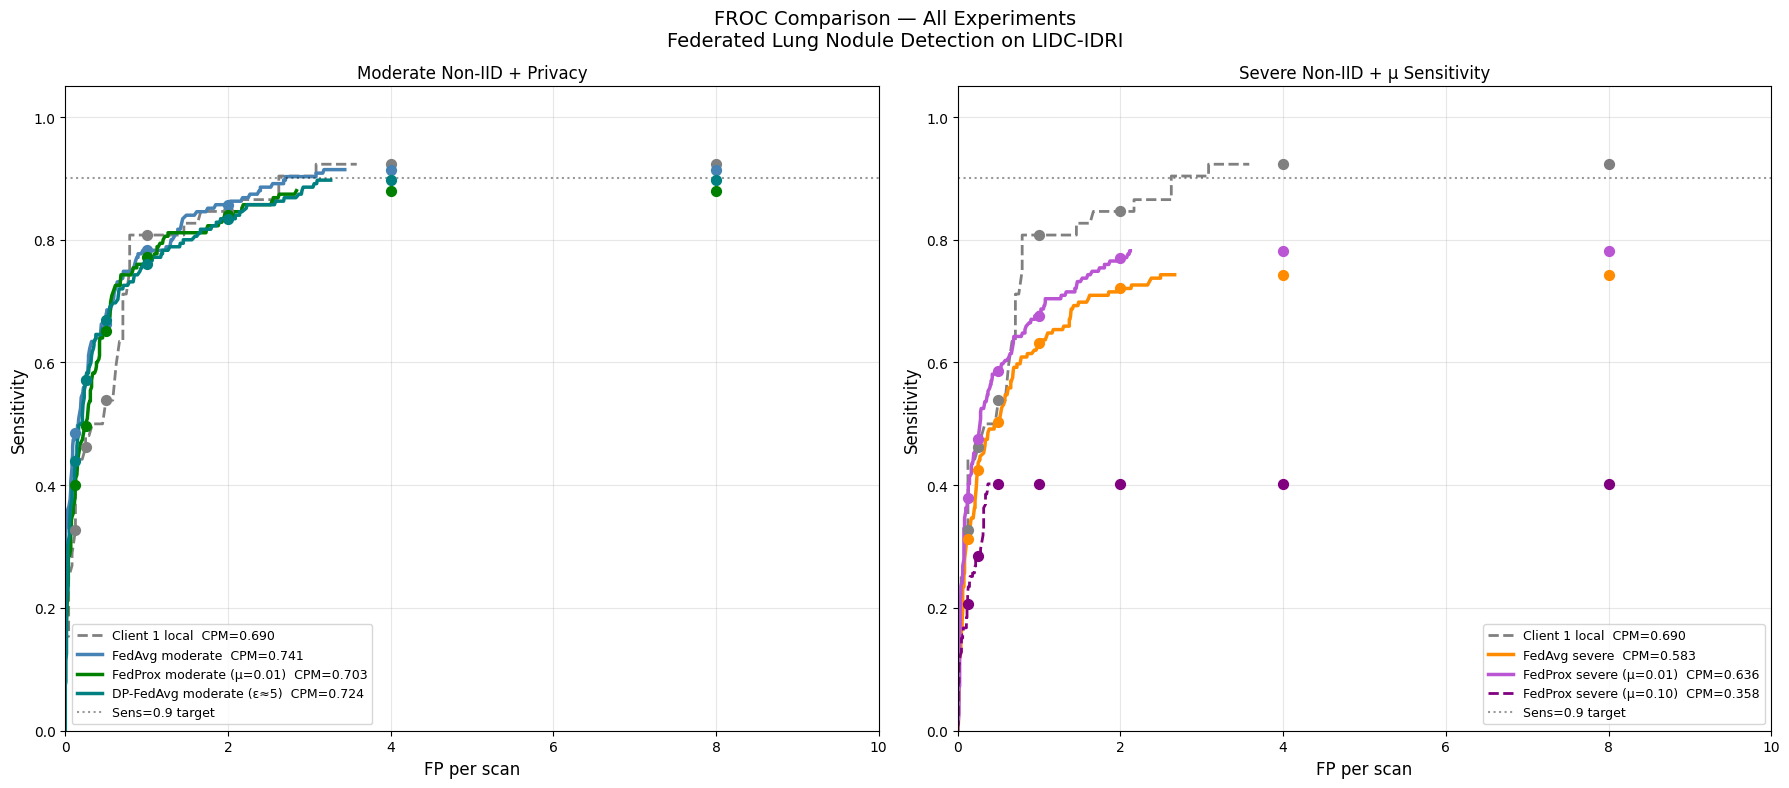


FROC plot saved: C:\Users\Administrator\desktop\unet\experiments\final_comparison_froc_v2.png


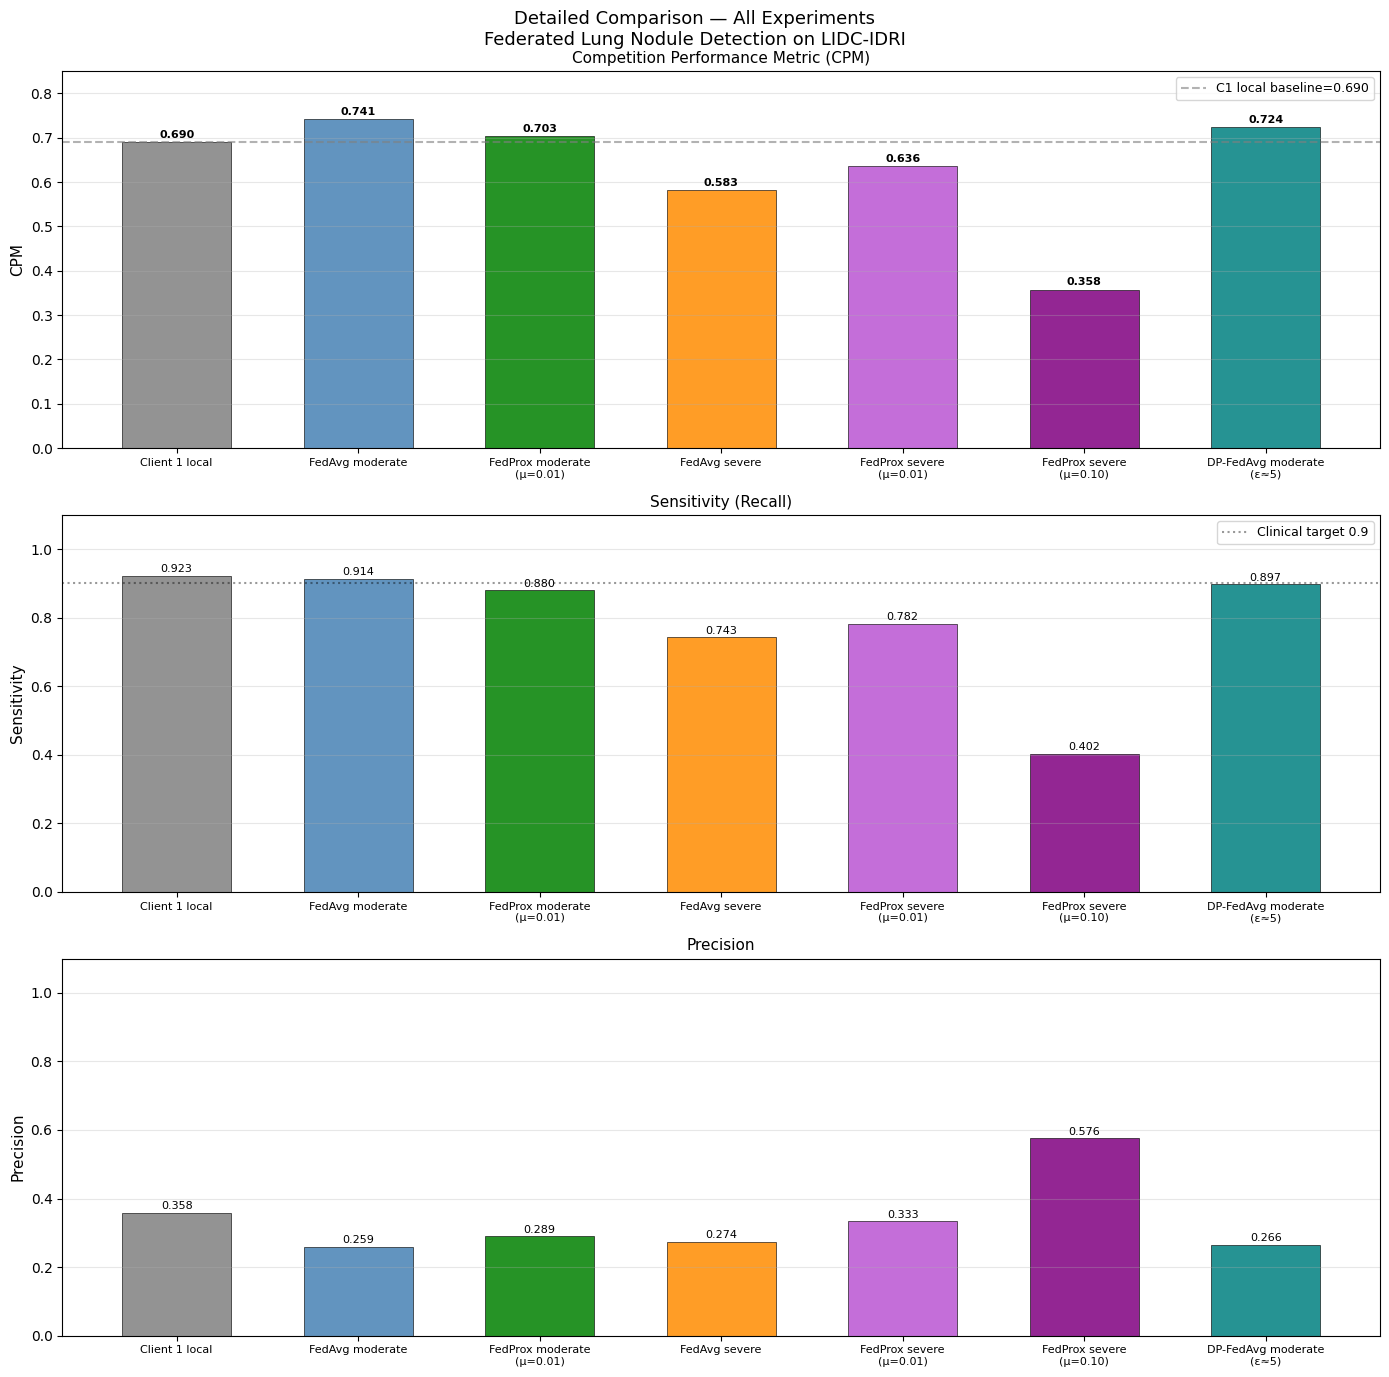

Detailed plot saved: C:\Users\Administrator\desktop\unet\experiments\final_comparison_detailed_v2.png
Table saved: C:\Users\Administrator\desktop\unet\experiments\final_comparison_table_v2.json

OUTPUT FILES
  experiments/final_comparison_table_v2.json
  experiments/final_comparison_froc_v2.png
  experiments/final_comparison_detailed_v2.png
  Nothing else touched.


In [14]:
# FINAL COMPARISON — ALL EXPERIMENTS (DETAILED v2)
# Loads from saved JSON and PKL files only
# Gracefully skips experiments not yet completed
# Writes:
#   experiments/final_comparison_table_v2.json
#   experiments/final_comparison_froc_v2.png
#   experiments/final_comparison_detailed_v2.png
# Touches nothing else
# ============================================================
import numpy as np
import pickle
import json
import matplotlib.pyplot as plt
from pathlib import Path

OUT_ROOT = Path(r"C:\Users\Administrator\desktop\unet")
EXP_ROOT = OUT_ROOT / "experiments"

# ── assert no overwriting ─────────────────────────────────────
out_json     = EXP_ROOT / "final_comparison_table_v2.json"
out_png      = EXP_ROOT / "final_comparison_froc_v2.png"
out_png_det  = EXP_ROOT / "final_comparison_detailed_v2.png"
for f in [out_json, out_png, out_png_det]:
    assert not f.exists(), f"Would overwrite {f}"
print("✓ No existing files would be overwritten")

fp_pts = [0.125, 0.25, 0.5, 1, 2, 4, 8]

def compute_froc(scores, total_gt, n_scans):
    scores = sorted(scores, key=lambda x:x[0], reverse=True)
    sa = np.array([s[0] for s in scores])
    la = np.array([s[1] for s in scores])
    sl, fl = [], []
    for th in np.linspace(0.95, 0.01, 500):
        k = sa >= th
        sl.append(float(la[k].sum() / max(total_gt, 1)))
        fl.append(float((1-la[k]).sum() / max(n_scans, 1)))
    cpm_s = [sl[np.argmin([abs(f-fp) for f in fl])]
             for fp in fp_pts]
    return sl, fl, cpm_s, float(np.mean(cpm_s))

def try_load(scores_path, results_path,
             name, color, linestyle, linewidth, group,
             total_gt_override=None,
             n_patients_override=None):
    if not Path(scores_path).exists():
        print(f"  ⚠ {name} — not ready yet")
        return None
    with open(scores_path,"rb") as f:
        scores = pickle.load(f)
    with open(results_path) as f:
        res = json.load(f)
    tgt = total_gt_override or res.get("total_gt",
          res.get("gt_nodules", 0))
    ns  = n_patients_override or res.get("n_patients", 0)
    sl,fl,cpm_s,cpm = compute_froc(scores, tgt, ns)
    print(f"  ✓ {name:<38} CPM={cpm:.3f}  "
          f"Sens={res.get('sensitivity',0):.3f}")
    return {
        "sl":sl,"fl":fl,"cpm_s":cpm_s,"cpm":cpm,
        "sensitivity" : res.get("sensitivity",0),
        "precision"   : res.get("precision",0),
        "f1"          : res.get("f1",0),
        "fp_per_scan" : res.get("fp_per_scan",0),
        "total_gt"    : tgt,
        "n_patients"  : ns,
        "color"       : color,
        "linestyle"   : linestyle,
        "linewidth"   : linewidth,
        "group"       : group,
    }

# ── load all experiments ──────────────────────────────────────
print("\nLoading all experiment results...")
experiments = {}

# 1. Client 1 local
e = try_load(
    OUT_ROOT/"logs"/"all_scores.pkl",
    OUT_ROOT/"logs"/"client1_test_results_v3.json",
    "Client 1 local",
    "gray","--",2,"local")
if e: experiments["Client 1 local"] = e

# 2. FedAvg moderate
e = try_load(
    OUT_ROOT/"logs_global"/"global_all_scores.pkl",
    OUT_ROOT/"logs_global"/"global_test_results.json",
    "FedAvg moderate",
    "steelblue","-",2.5,"moderate")
if e: experiments["FedAvg moderate"] = e

# 3. FedProx moderate μ=0.01
e = try_load(
    EXP_ROOT/"fedprox_moderate"/"fedprox_moderate_scores.pkl",
    EXP_ROOT/"fedprox_moderate"/"fedprox_moderate_test_results.json",
    "FedProx moderate (μ=0.01)",
    "green","-",2.5,"moderate")
if e: experiments["FedProx moderate (μ=0.01)"] = e

# 4. FedAvg severe
e = try_load(
    EXP_ROOT/"severe_noniid"/"fl_results"/"severe_all_scores.pkl",
    EXP_ROOT/"severe_noniid"/"fl_results"/"severe_test_results.json",
    "FedAvg severe",
    "darkorange","-",2.5,"severe")
if e: experiments["FedAvg severe"] = e

# 5. FedProx severe μ=0.01
e = try_load(
    EXP_ROOT/"fedprox_severe_mu001"/"fedprox_severe_mu001_scores.pkl",
    EXP_ROOT/"fedprox_severe_mu001"/"fedprox_severe_mu001_test_results.json",
    "FedProx severe (μ=0.01)",
    "mediumorchid","-",2.5,"severe")
if e: experiments["FedProx severe (μ=0.01)"] = e

# 6. FedProx severe μ=0.10
e = try_load(
    EXP_ROOT/"fedprox_severe"/"fedprox_severe_scores.pkl",
    EXP_ROOT/"fedprox_severe"/"fedprox_severe_test_results.json",
    "FedProx severe (μ=0.10)",
    "purple","--",2,"severe_sensitivity")
if e: experiments["FedProx severe (μ=0.10)"] = e

# 7. DP-FedAvg moderate
e = try_load(
    EXP_ROOT/"dp_fedavg_moderate_e5"/"dp_fedavg_moderate_e5_scores.pkl",
    EXP_ROOT/"dp_fedavg_moderate_e5"/"dp_fedavg_moderate_e5_test_results.json",
    "DP-FedAvg moderate (ε≈5)",
    "teal","-",2.5,"dp")
if e: experiments["DP-FedAvg moderate (ε≈5)"] = e

# ── print comparison table ────────────────────────────────────
group_headers = {
    "local"             : "── LOCAL BASELINE ──",
    "moderate"          : "── MODERATE NON-IID FL ──",
    "severe"            : "── SEVERE NON-IID FL ──",
    "severe_sensitivity": "── SEVERE NON-IID FL (μ sensitivity) ──",
    "dp"                : "── DIFFERENTIAL PRIVACY ──",
}

print(f"\n{'='*80}")
print(f"FINAL COMPARISON TABLE")
print(f"{'='*80}")
print(f"{'Method':<38} {'N':>5} {'GT':>5} "
      f"{'Sens':>6} {'Prec':>6} {'FP/scan':>8} {'CPM':>7}")
print(f"{'─'*80}")

printed_groups = set()
c1_cpm = experiments.get("Client 1 local",{}).get("cpm",0)

for name, exp in experiments.items():
    g = exp["group"]
    if g not in printed_groups:
        print(f"\n  {group_headers.get(g,g)}")
        printed_groups.add(g)
    diff = exp["cpm"] - c1_cpm
    sign = "+" if diff >= 0 else ""
    print(f"  {name:<36} "
          f"{exp['n_patients']:>5} "
          f"{exp['total_gt']:>5} "
          f"{exp['sensitivity']:>6.3f} "
          f"{exp['precision']:>6.3f} "
          f"{exp['fp_per_scan']:>8.2f} "
          f"{exp['cpm']:>7.3f}  "
          f"({sign}{diff*100:.1f}%)")

# ── CPM summary ───────────────────────────────────────────────
print(f"\n{'='*80}")
print(f"KEY FINDINGS")
print(f"{'='*80}")
if "FedAvg moderate" in experiments and \
   "FedAvg severe" in experiments:
    drop = (experiments["FedAvg moderate"]["cpm"] -
            experiments["FedAvg severe"]["cpm"])
    print(f"  Heterogeneity cost (FedAvg mod→sev): "
          f"-{drop*100:.1f}% CPM")
if "FedAvg severe" in experiments and \
   "FedProx severe (μ=0.10)" in experiments:
    drop = (experiments["FedAvg severe"]["cpm"] -
            experiments["FedProx severe (μ=0.10)"]["cpm"])
    print(f"  Over-regularization cost (μ=0.1):    "
          f"-{drop*100:.1f}% CPM vs FedAvg severe")
if "FedAvg moderate" in experiments and \
   "DP-FedAvg moderate (ε≈10)" in experiments:
    drop = (experiments["FedAvg moderate"]["cpm"] -
            experiments["DP-FedAvg moderate (ε≈10)"]["cpm"])
    print(f"  Privacy cost (DP ε≈10):               "
          f"-{drop*100:.1f}% CPM")
if "FedAvg moderate" in experiments and \
   "FedProx moderate (μ=0.01)" in experiments:
    drop = (experiments["FedAvg moderate"]["cpm"] -
            experiments["FedProx moderate (μ=0.01)"]["cpm"])
    print(f"  FedProx vs FedAvg (moderate):         "
          f"-{drop*100:.1f}% CPM")

# ── FROC plot — 2 panels ──────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
fig.suptitle(
    "FROC Comparison — All Experiments\n"
    "Federated Lung Nodule Detection on LIDC-IDRI",
    fontsize=14)

# left: moderate + local + DP
ax = axes[0]
left_groups = ("local","moderate","dp")
for name, exp in experiments.items():
    if exp["group"] not in left_groups: continue
    ax.plot(exp["fl"], exp["sl"],
            color=exp["color"],
            linestyle=exp["linestyle"],
            linewidth=exp["linewidth"],
            label=f"{name}  CPM={exp['cpm']:.3f}")
    ax.scatter(fp_pts, exp["cpm_s"],
               color=exp["color"], zorder=5, s=50)
ax.axhline(0.9,color='black',linestyle=':',
           alpha=0.4,label='Sens=0.9 target')
ax.set_xlabel('FP per scan',fontsize=12)
ax.set_ylabel('Sensitivity',fontsize=12)
ax.set_title('Moderate Non-IID + Privacy',fontsize=12)
ax.set_xlim(0,10); ax.set_ylim(0,1.05)
ax.legend(fontsize=9); ax.grid(True,alpha=0.3)

# right: severe + local
ax = axes[1]
right_groups = ("local","severe","severe_sensitivity")
for name, exp in experiments.items():
    if exp["group"] not in right_groups: continue
    ax.plot(exp["fl"], exp["sl"],
            color=exp["color"],
            linestyle=exp["linestyle"],
            linewidth=exp["linewidth"],
            label=f"{name}  CPM={exp['cpm']:.3f}")
    ax.scatter(fp_pts, exp["cpm_s"],
               color=exp["color"], zorder=5, s=50)
ax.axhline(0.9,color='black',linestyle=':',
           alpha=0.4,label='Sens=0.9 target')
ax.set_xlabel('FP per scan',fontsize=12)
ax.set_ylabel('Sensitivity',fontsize=12)
ax.set_title('Severe Non-IID + μ Sensitivity',fontsize=12)
ax.set_xlim(0,10); ax.set_ylim(0,1.05)
ax.legend(fontsize=9); ax.grid(True,alpha=0.3)

plt.tight_layout()
plt.savefig(out_png,dpi=100,bbox_inches='tight')
plt.show()
print(f"\nFROC plot saved: {out_png}")

# ── detailed bar chart ────────────────────────────────────────
names  = list(experiments.keys())
cpms   = [experiments[n]["cpm"]         for n in names]
senss  = [experiments[n]["sensitivity"] for n in names]
precs  = [experiments[n]["precision"]   for n in names]
colors = [experiments[n]["color"]       for n in names]

x = np.arange(len(names))
w = 0.25

fig, axes = plt.subplots(3, 1, figsize=(14, 14))
fig.suptitle(
    "Detailed Comparison — All Experiments\n"
    "Federated Lung Nodule Detection on LIDC-IDRI",
    fontsize=13)

# CPM
ax = axes[0]
bars = ax.bar(x, cpms, 0.6,
              color=colors, alpha=0.85, edgecolor='black',
              linewidth=0.5)
ax.set_xticks(x)
ax.set_xticklabels(
    [n.replace(" (","\n(") for n in names],
    fontsize=8, rotation=0)
ax.set_ylabel('CPM', fontsize=11)
ax.set_title('Competition Performance Metric (CPM)',
             fontsize=11)
ax.set_ylim(0, 0.85)
ax.axhline(c1_cpm,color='gray',linestyle='--',
           alpha=0.6,label=f'C1 local baseline={c1_cpm:.3f}')
ax.legend(fontsize=9); ax.grid(True,alpha=0.3,axis='y')
for b,v in zip(bars,cpms):
    ax.text(b.get_x()+b.get_width()/2,
            b.get_height()+0.005,f'{v:.3f}',
            ha='center',va='bottom',fontsize=8,
            fontweight='bold')

# Sensitivity
ax = axes[1]
bars=ax.bar(x,senss,0.6,color=colors,alpha=0.85,
            edgecolor='black',linewidth=0.5)
ax.set_xticks(x)
ax.set_xticklabels(
    [n.replace(" (","\n(") for n in names],
    fontsize=8)
ax.set_ylabel('Sensitivity',fontsize=11)
ax.set_title('Sensitivity (Recall)',fontsize=11)
ax.set_ylim(0,1.1)
ax.axhline(0.9,color='black',linestyle=':',
           alpha=0.4,label='Clinical target 0.9')
ax.legend(fontsize=9); ax.grid(True,alpha=0.3,axis='y')
for b,v in zip(bars,senss):
    ax.text(b.get_x()+b.get_width()/2,
            b.get_height()+0.005,f'{v:.3f}',
            ha='center',va='bottom',fontsize=8)

# Precision
ax = axes[2]
bars=ax.bar(x,precs,0.6,color=colors,alpha=0.85,
            edgecolor='black',linewidth=0.5)
ax.set_xticks(x)
ax.set_xticklabels(
    [n.replace(" (","\n(") for n in names],
    fontsize=8)
ax.set_ylabel('Precision',fontsize=11)
ax.set_title('Precision',fontsize=11)
ax.set_ylim(0,1.1)
ax.grid(True,alpha=0.3,axis='y')
for b,v in zip(bars,precs):
    ax.text(b.get_x()+b.get_width()/2,
            b.get_height()+0.005,f'{v:.3f}',
            ha='center',va='bottom',fontsize=8)

plt.tight_layout()
plt.savefig(out_png_det,dpi=100,bbox_inches='tight')
plt.show()
print(f"Detailed plot saved: {out_png_det}")

# ── save json ─────────────────────────────────────────────────
comparison = {
    name: {
        "cpm"                  : round(exp["cpm"],4),
        "sensitivity"          : exp["sensitivity"],
        "precision"            : exp["precision"],
        "f1"                   : exp["f1"],
        "fp_per_scan"          : exp["fp_per_scan"],
        "total_gt"             : exp["total_gt"],
        "n_patients"           : exp["n_patients"],
        "cpm_vs_c1_local_pct"  : round(
            (exp["cpm"]-c1_cpm)*100, 2),
    }
    for name,exp in experiments.items()
}
with open(out_json,"w") as f:
    json.dump(comparison,f,indent=2)
print(f"Table saved: {out_json}")

print(f"\n{'='*80}")
print(f"OUTPUT FILES")
print(f"{'='*80}")
print(f"  experiments/final_comparison_table_v2.json")
print(f"  experiments/final_comparison_froc_v2.png")
print(f"  experiments/final_comparison_detailed_v2.png")
print(f"  Nothing else touched.")

C:\Users\Administrator\desktop\unet\
│
├── weights\                          ← FedAvg MODERATE
│   ├── global_fl_final.pt
│   ├── fl_round1-6_global.pt
│   └── client1_best.pt
│
├── logs_global\                      ← FedAvg MODERATE eval
│   ├── global_all_results.pkl
│   ├── global_all_scores.pkl
│   ├── global_test_results.json
│   ├── fl_history.json
│   ├── per_client_metrics_fedavg_moderate.png
│   └── per_client_metrics_fedavg_moderate.json
│
├── logs\                             ← Client 1 LOCAL baseline
│   ├── all_scores.pkl
│   └── client1_test_results_v3.json
│
├── experiments\
│   │
│   ├── fedprox_moderate\             ← FedProx MODERATE μ=0.01
│   │   ├── global_fedprox_moderate_final.pt
│   │   ├── fl_round1-6_global.pt
│   │   ├── fl_history_fedprox_moderate.json
│   │   ├── fedprox_moderate_results.pkl
│   │   ├── fedprox_moderate_scores.pkl
│   │   ├── fedprox_moderate_test_results.json
│   │   ├── froc_fedprox_moderate.png
│   │   ├── per_client_metrics_fedprox_moderate.png
│   │   └── per_client_metrics_fedprox_moderate.json
│   │
│   ├── severe_noniid\                ← splits + manifests
│   │   ├── severe_noniid_splits.json
│   │   ├── severe_noniid_assignment.csv
│   │   ├── description.json
│   │   ├── global_test_pids_severe.json
│   │   ├── client1_split_manifest.json
│   │   ├── client2_split_manifest.json
│   │   ├── client3_split_manifest.json
│   │   ├── client4_split_manifest.json
│   │   ├── client5_split_manifest.json
│   │   └── fl_results\              ← FedAvg SEVERE
│   │       ├── global_fl_severe_final.pt
│   │       ├── fl_round1-6_global.pt
│   │       ├── fl_history_severe.json
│   │       ├── severe_all_results.pkl
│   │       ├── severe_all_scores.pkl
│   │       ├── severe_test_results.json
│   │       ├── froc_fedavg_severe.png
│   │       ├── per_client_metrics_fedavg_severe.png
│   │       └── per_client_metrics_fedavg_severe.json
│   │
│   ├── fedprox_severe\               ← FedProx SEVERE μ=0.10
│   │   ├── global_fedprox_severe_final.pt
│   │   ├── fl_round1-6_global.pt
│   │   ├── fl_history_fedprox_severe.json
│   │   ├── fedprox_severe_results.pkl
│   │   ├── fedprox_severe_scores.pkl
│   │   ├── fedprox_severe_test_results.json
│   │   ├── froc_fedprox_severe.png
│   │   ├── per_client_metrics_fedprox_severe.png
│   │   └── per_client_metrics_fedprox_severe.json
│   │
│   ├── fedprox_severe_mu001\         ← FedProx SEVERE μ=0.01
│   │   ├── global_fedprox_severe_mu001_final.pt
│   │   ├── fl_round1-6_global.pt
│   │   ├── fl_history_fedprox_severe_mu001.json
│   │   ├── fedprox_severe_mu001_results.pkl
│   │   ├── fedprox_severe_mu001_scores.pkl
│   │   ├── fedprox_severe_mu001_test_results.json
│   │   ├── froc_fedprox_severe_mu001.png
│   │   ├── per_client_metrics_fedprox_severe_mu001.png
│   │   └── per_client_metrics_fedprox_severe_mu001.json
│   │
│   ├── dp_fedavg_moderate_e5\        ← DP-FedAvg MODERATE ε≈5
│   │   ├── global_dp_fedavg_moderate_e5_final.pt
│   │   ├── fl_round1-6_global.pt
│   │   ├── fl_history_dp_fedavg_moderate_e5.json
│   │   ├── fl_loss_dp_fedavg_moderate_e5.png
│   │   ├── dp_fedavg_moderate_e5_results.pkl
│   │   ├── dp_fedavg_moderate_e5_scores.pkl
│   │   ├── dp_fedavg_moderate_e5_test_results.json
│   │   ├── froc_dp_fedavg_moderate_e5.png
│   │   ├── per_client_metrics_dp_fedavg_moderate_e5.png
│   │   ├── per_client_metrics_dp_fedavg_moderate_e5.json
│   │   └── resource_usage_inference.png
│   │
│   ├── final_comparison_table_v2.json
│   ├── final_comparison_froc_v2.png
│   └── final_comparison_detailed_v2.png
│
├── federation_splits.json            ← READ ONLY
├── global_test_pids.json             ← moderate test pool
│
├── preprocessed\                     ← client 1 volumes
├── lung_masks\                       ← client 1 masks
├── annotations\                      ← client 1 annotations
├── patches\client1\                  ← client 1 patches
│
├── client2\
│   ├── preprocessed\
│   ├── lung_masks\
│   ├── annotations\
│   └── patches\client2\
│
├── client3\ ... (same structure)
├── client4\ ... (same structure)
└── client5\ ... (same structure)

================================================================================
FINAL COMPARISON TABLE
================================================================================
Method                                     N    GT   Sens   Prec  FP/scan     CPM
────────────────────────────────────────────────────────────────────────────────

  ── LOCAL BASELINE ──
  Client 1 local                          24    52  0.923  0.358     3.58   0.690  (+0.0%)

  ── MODERATE NON-IID FL ──
  FedAvg moderate                        133   175  0.914  0.259     3.44   0.741  (+5.2%)
  FedProx moderate (μ=0.01)              133   175  0.880  0.289     2.84   0.703  (+1.3%)

  ── SEVERE NON-IID FL ──
  FedAvg severe                          132   179  0.743  0.274     2.67   0.583  (-10.7%)
  FedProx severe (μ=0.01)                132   179  0.782  0.333     2.12   0.636  (-5.3%)

  ── SEVERE NON-IID FL (μ sensitivity) ──
  FedProx severe (μ=0.10)                132   179  0.402  0.576     0.40   0.358  (-33.2%)

  ── DIFFERENTIAL PRIVACY ──
  DP-FedAvg moderate (ε≈5)               133   175  0.897  0.266     3.26   0.724  (+3.5%)

================================================================================
KEY FINDINGS
================================================================================
Heterogeneity cost: 21.3%
μ=0.10 vs μ=0.01 severe: -43.7%
μ=0.10 vs FedAvg severe: -38.6%
FedProx mod vs FedAvg mod: -5.1%
FedProx sev μ=0.01 vs FedAvg sev: 9.1%
DP cost: 2.3%
